# MS1.1 — Data Cleaning and Auditing

Preserves shared work and the four member sections. Missing-value treatment is documented in each table section; constructor-status blanks are explicitly labeled ND. Flagged anomalies remain unresolved unless explicitly documented. Original CSVs and input notebooks are unchanged. See `acl-ms1-merge-notes.md` for integration changes.

# 1. Data loading from official dataset 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Kaggle first; local archive is supported for verification.
DATA_DIR = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
if not DATA_DIR.exists():
    DATA_DIR = Path("archive")
if not DATA_DIR.exists():
    raise FileNotFoundError("Set DATA_DIR to the folder containing the F1 CSV files.")


In [2]:
circuits =  pd.read_csv(DATA_DIR / "circuits.csv") 
constructor_results =  pd.read_csv(DATA_DIR / "constructor_results.csv") 
constructor_standings =  pd.read_csv(DATA_DIR / "constructor_standings.csv") 
constructors =  pd.read_csv(DATA_DIR / "constructors.csv") 
driver_standings =  pd.read_csv(DATA_DIR / "driver_standings.csv") 
drivers =  pd.read_csv(DATA_DIR / "drivers.csv") 
lap_times =  pd.read_csv(DATA_DIR / "lap_times.csv") 
pit_stops =  pd.read_csv(DATA_DIR / "pit_stops.csv") 
qualifying =  pd.read_csv(DATA_DIR / "qualifying.csv") 
races =  pd.read_csv(DATA_DIR / "races.csv") 
seasons =  pd.read_csv(DATA_DIR / "seasons.csv") 
sprint_results =  pd.read_csv(DATA_DIR / "sprint_results.csv") 
status =  pd.read_csv(DATA_DIR / "status.csv") 
results =  pd.read_csv(DATA_DIR / "results.csv") 

# 2. Exploratory Data Analysis (EDA) & Profiling

**Investigating the raw data distributions, identifying missing values, and analyzing feature correlations prior to structural transformations.**



## 2.1 Loading Raw Data
Importing the initial dataset from the source before any transformations are applied. This cell loads the data into memory, verifies its initial shape, and inspects the raw column types.

In [3]:
raw = {
    "circuits": circuits, "constructor_results": constructor_results,
    "constructor_standings": constructor_standings, "constructors": constructors,
    "driver_standings": driver_standings, "drivers": drivers,
    "lap_times": lap_times, "pit_stops": pit_stops, "qualifying": qualifying,
    "races": races, "results": results, "seasons": seasons,
    "sprint_results": sprint_results, "status": status,
}
# Immutable fingerprints for final validation; raw is only for before/after evidence.
import hashlib
raw_table_fingerprints = {
    name: (table.shape, tuple(table.columns), tuple(map(str, table.dtypes)),
           hashlib.sha256(pd.util.hash_pandas_object(table, index=True).values.tobytes()).hexdigest())
    for name, table in raw.items()
}
raw_csv_fingerprints = {
    name: hashlib.sha256((DATA_DIR / (name + ".csv")).read_bytes()).hexdigest()
    for name in raw
}


## 2.2 Primary Key (PK) Extraction & Validation


Isolating and validating the unique identifiers for each record. This step ensures there are no duplicate keys, verifies index integrity, and prepares the exact mappings required for accurate relational joins.

In [4]:
pk = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"], "races": ["raceId"], "results": ["resultId"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}

fk = [  # (child table, child column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
]

def table_profile(tables):
    rows = []
    for n, df in tables.items():
        rows.append({
            "table": n, "rows": len(df), "cols": df.shape[1],
            "sentinel_\\N": int((df.astype(str) == r"\N").sum().sum()),
            "NaN": int(df.isna().sum().sum()),
            "duplicate_rows": int(df.duplicated().sum()),
            "text_cols": int((df.dtypes == "object").sum()),
        })
    return pd.DataFrame(rows).set_index("table")

def column_profile(df):
    sentinel = (df.astype(str) == r"\N").sum()
    missing = sentinel + df.isna().sum()
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": missing,
                         "missing_pct": (missing / len(df) * 100).round(2),
                         "unique": df.nunique()})

def pk_check(tables):
    return pd.DataFrame({
        n: {"duplicate_keys": int(df.duplicated(pk[n]).sum()),
            "null_keys": int(df[pk[n]].isna().sum().sum())}
        for n, df in tables.items()}).T

def fk_check(tables):
    return pd.Series({f"{c}.{cc} -> {p}.{pc}": int((~tables[c][cc].isin(tables[p][pc])).sum())
                      for c, cc, p, pc in fk})

def numeric_summary(df):
    num = df.apply(pd.to_numeric, errors="coerce")
    num = num.loc[:, num.notna().sum() > 0.5 * len(df)]
    return num.describe().T[["count", "mean", "std", "min", "max"]]

## 2.3 Overall Table Profiles 

In [5]:
before_profile = table_profile(raw)
before_cols = {n: column_profile(df) for n, df in raw.items()}
before_pk = pk_check(raw)
before_fk = fk_check(raw)

before_profile

,rows,cols,sentinel_\N,NaN,duplicate_rows,text_cols
table,,,,,,
circuits,77,9,0,0,0,5
constructor_results,12625,5,12608,0,0,1
constructor_standings,13391,7,0,0,0,1
constructors,212,5,0,0,0,4
driver_standings,34863,7,0,0,0,1
drivers,861,9,1559,0,0,8
lap_times,589081,6,0,0,0,1
pit_stops,11371,7,0,0,0,2
qualifying,10494,9,11600,68,0,3


## 2.4 Missing Value Inspection
Filtering the column profiles to isolate and display only the columns that contain missing data or numeric values improperly stored as text.

In [6]:
# Column-level view: only columns that have missing values or text storing numbers.
for n, rep in before_cols.items():
    rep = rep[rep.missing > 0]
    if not rep.empty:
        print(f"\n=== {n} ===")
        display(rep)


=== constructor_results ===


,dtype,missing,missing_pct,unique
status,object,12608,99.87,2



=== drivers ===


,dtype,missing,missing_pct,unique
number,object,802,93.15,49
code,object,757,87.92,98



=== qualifying ===


...

,dtype,missing,missing_pct,unique
time,object,731,64.98,35
fp1_date,object,1035,92.00,91
fp1_time,object,1057,93.96,21
fp2_date,object,1035,92.00,91
fp2_time,object,1057,93.96,20
fp3_date,object,1053,93.60,73
fp3_time,object,1072,95.29,19
quali_date,object,1035,92.00,91
quali_time,object,1057,93.96,16
sprint_date,object,1107,98.40,19



=== results ===


,dtype,missing,missing_pct,unique
number,object,6,0.02,130
position,object,10953,40.93,34
time,object,19079,71.30,7411
milliseconds,object,19079,71.30,7639
fastestLap,object,18507,69.16,81
rank,object,18249,68.20,26
fastestLapTime,object,18507,69.16,7474
fastestLapSpeed,object,18507,69.16,7725



=== sprint_results ===


,dtype,missing,missing_pct,unique
position,object,15,4.17,21
time,object,20,5.56,341
milliseconds,object,20,5.56,341
fastestLap,object,9,2.50,24
fastestLapTime,object,9,2.50,351


## 2.5 Relational Integrity Checks (PK / FK)

Validating primary key uniqueness to ensure no duplicate indices, and checking for orphaned foreign keys across the dataset prior to any table merges.

In [7]:
display(before_pk)
display(before_fk[before_fk > 0] if (before_fk > 0).any() else "No foreign-key orphans")

,duplicate_keys,null_keys
circuits,0,0
constructor_results,0,0
constructor_standings,0,0
constructors,0,0
driver_standings,0,0
drivers,0,0
lap_times,0,0
pit_stops,0,0
qualifying,0,0
races,0,0


'No foreign-key orphans'

## 2.6 Missing Data Visualization
Plotting the percentage of missing values across all tables to identify which features require the heaviest imputation or dropping. This accounts for both standard NaNs and `\N` sentinel values.

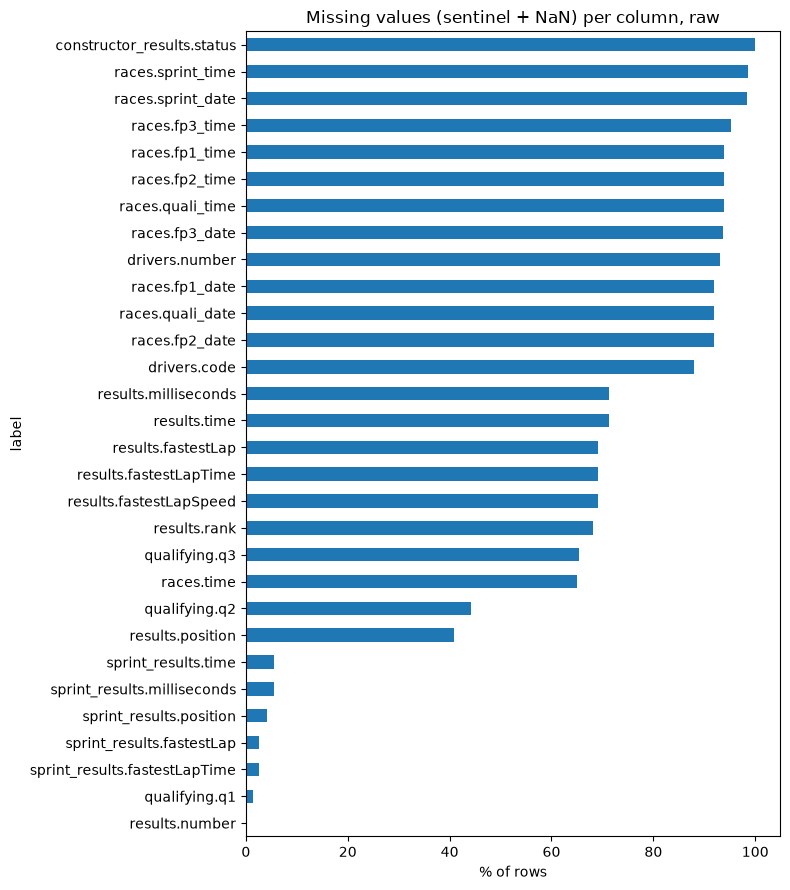

In [8]:
# 1) Missing % per column, for the columns that have any missing values
miss = pd.concat({n: r["missing_pct"] for n, r in before_cols.items()}).rename("pct").reset_index()
miss.columns = ["table", "column", "pct"]
miss = miss[miss.pct > 0].sort_values("pct")
miss["label"] = miss.table + "." + miss.column
miss.plot(kind="barh", x="label", y="pct", figsize=(8, max(3, 0.3 * len(miss))),
          legend=False, title="Missing values (sentinel + NaN) per column, raw")
plt.xlabel("% of rows"); plt.tight_layout(); plt.show()

## 2.7 Target Distribution & Race Diagnostics 
Visualizing core project metrics: the target class balance (Podium vs. Non-Podium), grid starting positions, average field size over time, and testing for duplicate race-driver combinations.

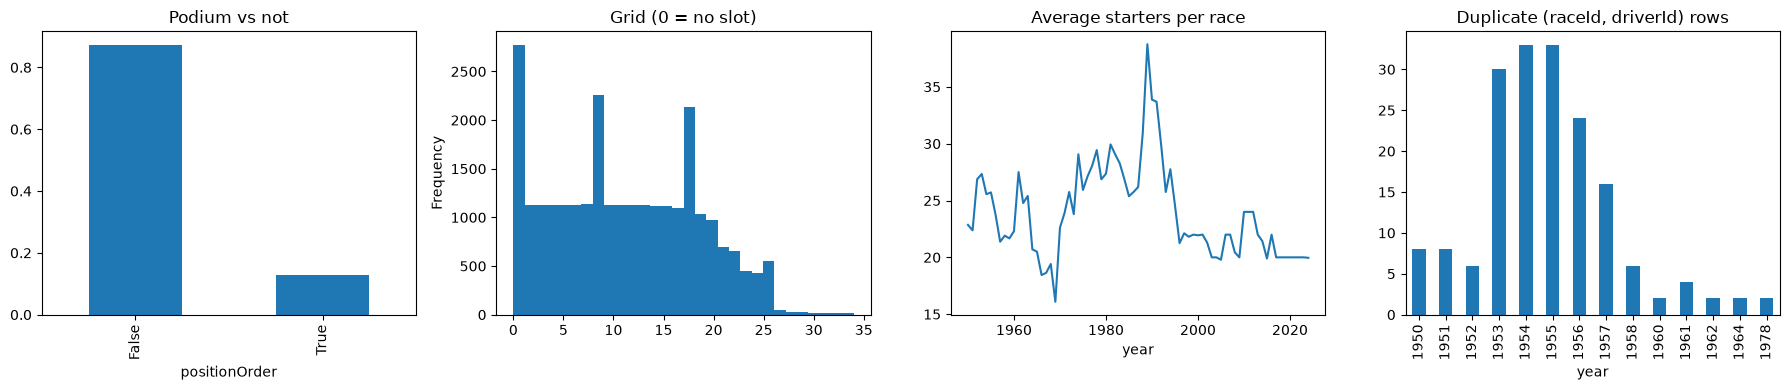

In [9]:
# 3) Target balance, grid==0, field size, and duplicate driver-race rows by season
res = raw["results"].merge(raw["races"][["raceId", "year"]], on="raceId")
res["positionOrder"] = pd.to_numeric(res["positionOrder"], errors="coerce")
res["grid"] = pd.to_numeric(res["grid"], errors="coerce")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
(res["positionOrder"] <= 3).value_counts(normalize=True).plot(
    kind="bar", ax=axes[0], title="Podium vs not")
res["grid"].plot(kind="hist", bins=30, ax=axes[1], title="Grid (0 = no slot)")
res.groupby(["year", "raceId"]).size().groupby("year").mean().plot(
    ax=axes[2], title="Average starters per race")
dup = res[res.duplicated(["raceId", "driverId"], keep=False)]
dup.groupby("year").size().plot(kind="bar", ax=axes[3], title="Duplicate (raceId, driverId) rows")
plt.tight_layout(); plt.show()

## 2.8 Semantic Typing & Sentinel Detection
Scanning for columns that should be processed as numbers, dates, or durations but are currently loaded as strings due to `\N` sentinel values. This establishes the required data-type casting for the cleaning pipeline.

In [10]:
# 4) Columns that should be numbers/dates/durations but are stored as text.
#    This is the evidence for semantic typing in the cleaning step.
text_numeric = {}
for n, df in raw.items():
    for c in df.select_dtypes("object").columns:
        sample = df[c][df[c] != r"\N"].dropna().head(200)
        if len(sample) and pd.to_numeric(sample, errors="coerce").notna().mean() > 0.9:
            text_numeric.setdefault(n, []).append(c)
print("Numeric columns stored as text (because of \\N):", text_numeric)

for n in ["results", "qualifying", "lap_times", "pit_stops"]:
    print(f"\n=== {n} ===")
    display(numeric_summary(raw[n]))

Numeric columns stored as text (because of \N): {'constructor_standings': ['positionText'], 'driver_standings': ['positionText'], 'drivers': ['number'], 'pit_stops': ['duration'], 'results': ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed'], 'sprint_results': ['position', 'positionText', 'milliseconds', 'fastestLap']}

=== results ===


,count,mean,std,min,max
resultId,26759.0,13380.977391,7726.134642,1.0,26764.0
raceId,26759.0,551.687283,313.265036,1.0,1144.0
driverId,26759.0,278.673530,282.703039,1.0,862.0
constructorId,26759.0,50.180537,61.551498,1.0,215.0
number,26753.0,18.153927,15.581135,0.0,208.0
grid,26759.0,11.134796,7.202860,0.0,34.0
position,15806.0,8.020499,4.840796,1.0,33.0
positionText,15808.0,8.021065,4.840781,1.0,33.0
positionOrder,26759.0,12.794051,7.665951,1.0,39.0
points,26759.0,1.987632,4.351209,0.0,50.0



=== qualifying ===


,count,mean,std,min,max
qualifyId,10494.0,5262.482847,3046.588486,1.0,10551.0
raceId,10494.0,624.600915,428.298147,1.0,1144.0
driverId,10494.0,343.002287,389.586448,1.0,862.0
constructorId,10494.0,47.918430,73.217993,1.0,215.0
number,10494.0,18.786449,18.447502,0.0,99.0
position,10494.0,11.195826,6.260374,1.0,28.0



=== lap_times ===


,count,mean,std,min,max
raceId,589081.0,600.544465,434.375976,1.0,1144.0
driverId,589081.0,325.796446,387.561736,1.0,862.0
lap,589081.0,30.018104,18.407126,1.0,87.0
position,589081.0,9.661951,5.528553,1.0,24.0
milliseconds,589081.0,95799.445243,76399.729955,55404.0,7507547.0



=== pit_stops ===


,count,mean,std,min,max
raceId,11371.0,981.194882,92.326831,841.000,1144.000
driverId,11371.0,549.734500,383.734981,1.000,862.000
stop,11371.0,1.787969,1.521462,1.000,70.000
lap,11371.0,25.387389,14.831497,1.000,78.000
duration,10854.0,24.448585,4.606013,12.897,59.555
milliseconds,11371.0,85230.495559,310427.261089,12897.000,3069017.000


# 3. Data Cleaning & Auditing

## 3.1 circuits.csv

Each row represents one circuit. `circuitId` is the primary key; `circuitRef` is its external identifier. `races.circuitId` connects races to these circuits. There are no dates or durations to convert in this table.

We will check missing values, repeated records, identifiers, coordinates and the connection to `races`. We will then compare the original table with `circuits_clean`. Cleaning keeps the same columns and uses a copy; it does not overwrite the raw table.



###  3.1.1 Circuits: Initial Auditing
Creating an immutable baseline of the raw `circuits` data and running quality diagnostics to flag missing values, `\N` sentinels, geographic coordinate anomalies, and orphaned relational keys.

In [11]:
circuits_raw_snapshot = circuits.copy(deep=True)
print("Rows:", len(circuits), "| Columns:", len(circuits.columns))
display(circuits.head())
circuits.info()


Rows: 77 | Columns: 9


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [12]:
# Count actual missing values, placeholders, empty text and extra spaces.
def circuits_column_audit(table):
    text = table.astype("string")
    return pd.DataFrame({
        "Data type": table.dtypes.astype(str),
        "Missing": table.isna().sum(),
        "Literal \\N": text.eq(r"\N").sum(),
        "Empty / blank text": text.apply(lambda col: col.str.strip().eq("")).sum(),
        "Extra outer spaces": text.ne(text.apply(lambda col: col.str.strip())).sum()
    })

circuits_before_summary = circuits_column_audit(circuits)
display(circuits_before_summary)


,Data type,Missing,Literal \N,Empty / blank text,Extra outer spaces
circuitId,int64,0,0,0,0
circuitRef,object,0,0,0,0
name,object,0,0,0,0
location,object,0,0,0,0
country,object,0,0,0,0
lat,float64,0,0,0,0
lng,float64,0,0,0,0
alt,int64,0,0,0,0
url,object,0,0,0,0


### 3.1.2 Check records and the connection to races

A repeated country is expected: several circuits can be in one country. A repeated `circuitId` needs investigation because it identifies one circuit.

We also check every circuit ID in `races`. A missing match could cause a race to lose its circuit information during a merge. Latitude must be between −90 and 90; longitude must be between −180 and 180. These limits check whether coordinates are possible, rather than proving that each coordinate is exactly correct.


In [13]:
def circuits_quality_audit(table):
    lat = pd.to_numeric(table["lat"], errors="coerce")
    lng = pd.to_numeric(table["lng"], errors="coerce")
    geographic_values = table[["lat", "lng", "alt"]].apply(pd.to_numeric, errors="coerce")
    return pd.Series({
        "Rows": len(table),
        "Columns": len(table.columns),
        "Duplicate complete rows": table.duplicated().sum(),
        "Missing circuit IDs": table["circuitId"].isna().sum(),
        "Duplicate circuit IDs": table["circuitId"].duplicated().sum(),
        "Missing circuit references": table["circuitRef"].isna().sum(),
        "Duplicate circuit references": table["circuitRef"].duplicated().sum(),
        "Missing URLs": table["url"].isna().sum(),
        "Duplicate URLs": table["url"].duplicated().sum(),
        "Missing / nonnumeric / infinite geographic values": (~np.isfinite(geographic_values)).sum().sum(),
        "Latitude outside valid range": (~lat.between(-90, 90)).sum(),
        "Longitude outside valid range": (~lng.between(-180, 180)).sum(),
        "Races without a matching circuit": (~races["circuitId"].isin(table["circuitId"])).sum(),
        "Circuits not referenced by races": (~table["circuitId"].isin(races["circuitId"])).sum()
    })

circuits_before_checks = circuits_quality_audit(circuits)
display(circuits_before_checks.to_frame("Before cleaning"))


,Before cleaning
Rows,77
Columns,9
Duplicate complete rows,0
Missing circuit IDs,0
Duplicate circuit IDs,0
Missing circuit references,0
Duplicate circuit references,0
Missing URLs,0
Duplicate URLs,0
Missing / nonnumeric / infinite geographic values,0


### Explain the country-label change before applying it

`USA` and `United States` describe the same country. We checked the reference URLs stored in the records below: the Circuit of the Americas reference locates the track in Austin, Texas, United States; the Las Vegas reference describes the race in Nevada, United States.

Sources from the CSV: [Circuit of the Americas](https://en.wikipedia.org/wiki/Circuit_of_the_Americas) and [Las Vegas Grand Prix](https://en.wikipedia.org/wiki/Las_Vegas_Grand_Prix#Circuit).

We use `United States` consistently so a country-level count does not split one country into two groups. Neither spelling identifies an incorrect country. There is no country ID in these CSVs: the references support this decision, while the before/after counts only show its effect.

The circuits remain separate records with their original IDs, names and locations. The historical Las Vegas circuit has a URL that redirects to the modern event page; that redirect is not evidence that the two tracks are identical.


In [14]:
display(circuits.loc[
    circuits["circuitId"].isin([69, 80]),
    ["circuitId", "name", "location", "country", "url"]
])


,circuitId,name,location,country,url
22,80,Las Vegas Strip Street Circuit,Las Vegas,United States,https://en.wikipedia.org/wiki/Las_Vegas_Grand_...
68,69,Circuit of the Americas,Austin,USA,http://en.wikipedia.org/wiki/Circuit_of_the_Am...


### 3.1.3 — Clean a copy using the existing columns

We standardize the country label, recognize `\N` and blank text as missing, remove outer spaces from text, and check that the geographic columns are numeric. The text and missing-value steps are precautions; the original audit shows whether they actually change anything. Conversion uses `errors="raise"` so an unexpected value produces a visible error instead of silently becoming missing.

There are no missing values in the current circuits file, so there is nothing to fill. No new columns are added to `circuits_clean`.


In [15]:
circuits_clean = circuits.copy(deep=True).replace(r"\N", np.nan)

for column in circuits_clean.select_dtypes(include="object").columns:
    circuits_clean[column] = circuits_clean[column].str.strip().replace("", np.nan)

circuits_clean["country"] = circuits_clean["country"].replace({"USA": "United States"})

for column in ["lat", "lng", "alt"]:
    circuits_clean[column] = pd.to_numeric(circuits_clean[column], errors="raise")


### 3.1.4 Circuits: Validation & Analysis
Verifying the transformations through side-by-side audits, visualizing the consolidated country distributions, and using strict assertion tests to guarantee zero unintended data loss before proceeding.

The first comparison checks every column. The second shows the specific records whose country label changed. The plot compares country counts before and after; it shows the effect of standardization, rather than providing the reason for it.


In [16]:
circuits_after_summary = circuits_column_audit(circuits_clean)
display(pd.concat({"Before": circuits_before_summary, "After": circuits_after_summary}, axis=1))

changed_countries = circuits["country"].fillna("<MISSING>").ne(
    circuits_clean["country"].fillna("<MISSING>")
)
circuits_country_changes = circuits.loc[changed_countries, ["circuitId", "name", "country"]].copy()
circuits_country_changes = circuits_country_changes.rename(columns={"country": "Country before"})
circuits_country_changes["Country after"] = circuits_clean.loc[changed_countries, "country"]
display(circuits_country_changes)
print("Country labels changed:", changed_countries.sum())


Before                                                           \
           Data type Missing Literal \N Empty / blank text Extra outer spaces   
circuitId      int64       0          0                  0                  0   
circuitRef    object       0          0                  0                  0   
name          object       0          0                  0                  0   
location      object       0          0                  0                  0   
country       object       0          0                  0                  0   
lat          float64       0          0                  0                  0   
lng          float64       0          0                  0                  0   
alt            int64       0          0                  0                  0   
url           object       0          0                  0                  0   

               After                                                           
           Data type Missing Literal \N Empty / blank text Extra outer spaces  
circuitId      int64       0          0                  0                  0  
circuitRef    object       0          0                  0                  0  
name          object       0          0                  0                  0  
location      object       0          0                  0                  0  
country       object       0          0                  0                  0  
lat          float64       0          0                  0                  0  
lng          float64       0          0                  0                  0  
alt            int64       0          0                  0                  0  
url           object       0          0                  0                  0

,circuitId,name,Country before,Country after
18,19,Indianapolis Motor Speedway,USA,United States
32,33,Phoenix street circuit,USA,United States
36,37,Detroit Street Circuit,USA,United States
41,42,Fair Park,USA,United States
42,43,Long Beach,USA,United States
43,44,Las Vegas Street Circuit,USA,United States
45,46,Watkins Glen,USA,United States
59,60,Riverside International Raceway,USA,United States
62,63,Sebring International Raceway,USA,United States
68,69,Circuit of the Americas,USA,United States


Country labels changed: 11


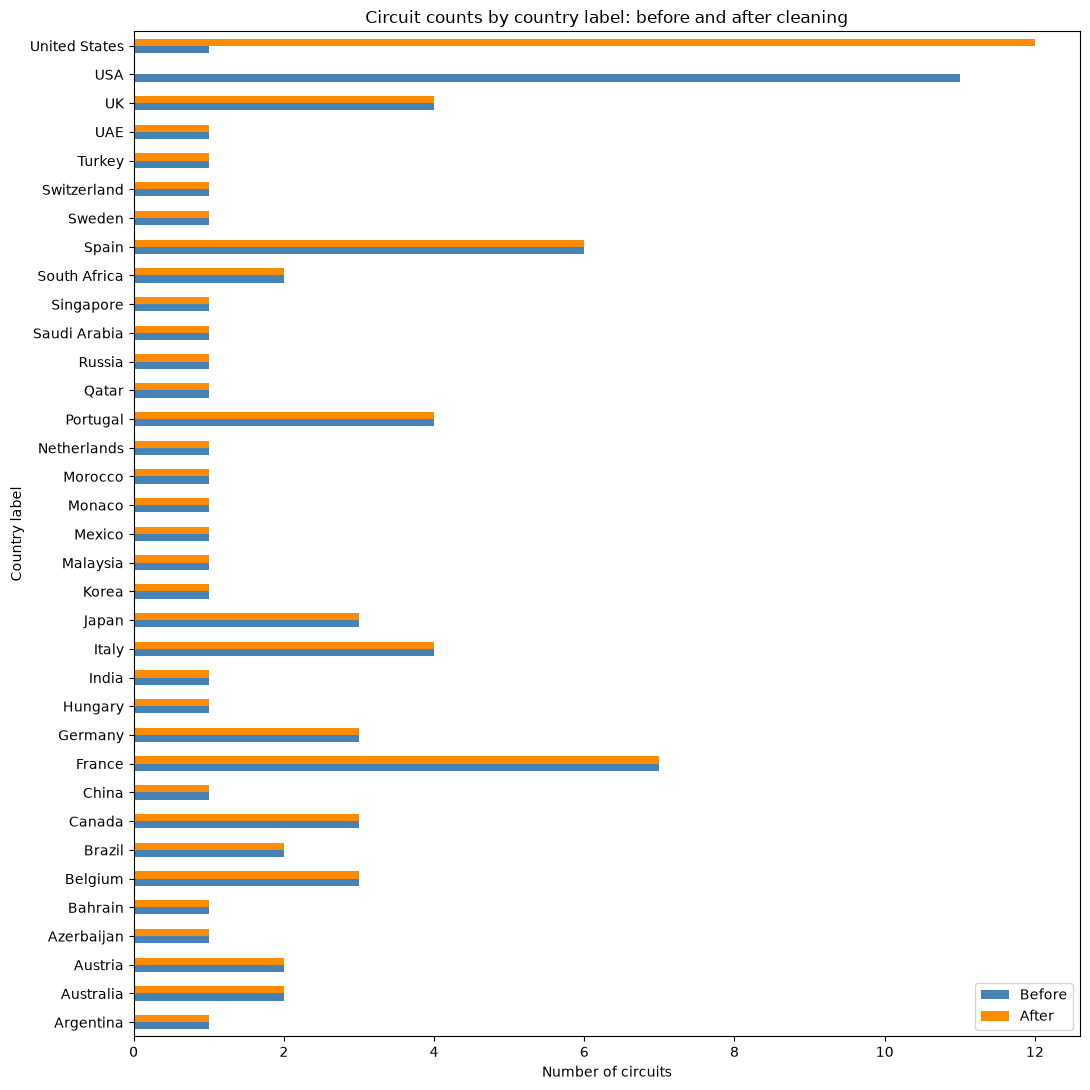

In [17]:
circuits_country_counts = pd.concat({
    "Before": circuits["country"].value_counts(),
    "After": circuits_clean["country"].value_counts()
}, axis=1).fillna(0).astype(int).sort_index()

circuits_country_counts.plot.barh(figsize=(11, 11), color=["steelblue", "darkorange"])
plt.title("Circuit counts by country label: before and after cleaning")
plt.xlabel("Number of circuits")
plt.ylabel("Country label")
plt.tight_layout()
plt.show()


In [18]:
# Compare numeric distributions and display the lowest/highest altitudes.
display(pd.concat({
    "Before": circuits[["lat", "lng", "alt"]].describe(),
    "After": circuits_clean[["lat", "lng", "alt"]].describe()
}, axis=1))

circuits_altitude_examples = pd.concat([
    circuits_clean.nsmallest(3, "alt"),
    circuits_clean.nlargest(3, "alt")
]).drop_duplicates("circuitId")
display(circuits_altitude_examples[["circuitId", "name", "country", "alt"]])


Before                               After                         
             lat         lng          alt        lat         lng          alt
count  77.000000   77.000000    77.000000  77.000000   77.000000    77.000000
mean   33.442925    1.076683   247.012987  33.442925    1.076683   247.012987
std    22.808866   65.516951   362.738469  22.808866   65.516951   362.738469
min   -37.849700 -118.189000    -7.000000 -37.849700 -118.189000    -7.000000
25%    32.777400   -9.394170    18.000000  32.777400   -9.394170    18.000000
50%    40.951700    3.930830   129.000000  40.951700    3.930830   129.000000
75%    46.958900   19.248600   332.000000  46.958900   19.248600   332.000000
max    57.265300  144.968000  2227.000000  57.265300  144.968000  2227.000000

,circuitId,name,country,alt
71,73,Baku City Circuit,Azerbaijan,-7
34,35,Korean International Circuit,Korea,0
76,79,Miami International Autodrome,United States,0
31,32,Autódromo Hermanos Rodríguez,Mexico,2227
29,30,Kyalami,South Africa,1460
35,36,Autódromo Internacional Nelson Piquet,Brazil,1126


### Step 6 — Verify the clean table and a safe merge

The checks should show 77 rows and 9 columns before and after, no missing data, no duplicate identifiers, and no races without a matching circuit. We validate a many-to-one merge: many races may use one circuit, but each race must match only one circuit row. The merge is a separate audit variable and adds no columns to `circuits_clean`.

We keep all records because the duplicate and key checks found no records that need removal. We keep the geographic numbers because these checks found no missing, nonnumeric, infinite or out-of-range coordinates. A low, negative or high altitude alone does not establish an error, so we do not replace it with an average or delete the circuit. The altitude examples are a review aid; exact geographical accuracy, including each altitude, has not been verified against independent sources.


In [19]:
circuits_after_checks = circuits_quality_audit(circuits_clean)
display(pd.DataFrame({"Before": circuits_before_checks, "After": circuits_after_checks}))

circuits_race_audit = races[["raceId", "circuitId"]].merge(
    circuits_clean[["circuitId", "name", "country"]],
    on="circuitId", how="left", validate="many_to_one", indicator=True
)
print("Races checked:", len(circuits_race_audit))
print("Unmatched races:", circuits_race_audit["_merge"].ne("both").sum())
display(circuits_race_audit.drop(columns="_merge").head())

assert circuits_after_checks.drop(["Rows", "Columns"]).eq(0).all()
assert len(circuits_clean) == len(circuits)
assert circuits_clean.columns.equals(circuits.columns)
assert circuits_after_summary.drop(columns="Data type").eq(0).all().all()
assert len(circuits_race_audit) == len(races)
assert circuits_race_audit["_merge"].eq("both").all()
pd.testing.assert_frame_equal(circuits, circuits_raw_snapshot)
pd.testing.assert_frame_equal(circuits.drop(columns="country"), circuits_clean.drop(columns="country"))
pd.testing.assert_series_equal(
    circuits_clean["country"], circuits["country"].replace({"USA": "United States"})
)
print("Passed: only country labels changed; raw data, other values, rows and columns are preserved.")
circuits_clean.info()


,Before,After
Rows,77,77
Columns,9,9
Duplicate complete rows,0,0
Missing circuit IDs,0,0
Duplicate circuit IDs,0,0
Missing circuit references,0,0
Duplicate circuit references,0,0
Missing URLs,0,0
Duplicate URLs,0,0
Missing / nonnumeric / infinite geographic values,0,0


Races checked: 1125
Unmatched races: 0


,raceId,circuitId,name,country
0,1,1,Albert Park Grand Prix Circuit,Australia
1,2,2,Sepang International Circuit,Malaysia
2,3,17,Shanghai International Circuit,China
3,4,3,Bahrain International Circuit,Bahrain
4,5,4,Circuit de Barcelona-Catalunya,Spain


Passed: only country labels changed; raw data, other values, rows and columns are preserved.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


### Circuits findings and decisions

- **Missing data:** no missing cells, `\N` placeholders or blank text were found, so no filling is needed.
- **Country labels:** 11 `USA` labels become `United States`, supported by the circuit references. The original 11 `USA` records and 1 `United States` record now form one group of 12 circuits. Before/after tables and a plot show this effect; all 77 circuit records remain.
- **Duplicates and relationships:** no repeated circuit IDs or circuit references were found. Every race matches one circuit, so no circuit or race records are removed.
- **Data types:** the geographic columns were already numeric. There are no date or duration columns to convert here.
- **Geographic values:** numeric checks and before/after summaries pass. We preserve values rather than make unsupported geographical corrections; the checks do not certify every coordinate or altitude.
- **Preservation:** `circuits_clean` has the same rows and columns as `circuits`; raw data and every non-country column are checked for equality.

This completes the circuits section's missing-value, type, duplicate, key and race-link checks. Other tables are reviewed separately.


## 3.2 constructor_results.csv

One row records a constructor result for a race. The primary key is `constructorResultsId`; `(raceId, constructorId)` should also be unique. There are no dates or durations to convert. Current-race points and status are post-race information and must not be model inputs for that same race.

### Step 1 — Inspect missing values before cleaning

This review handles the empty `status` values. The separate investigation of extra or missing team-result records will be handled later; this step removes no rows.


### 3.2.1 Constructor Results: Initial Auditing & Status Evaluation
Creating an immutable baseline of the raw `constructor_results` data. This phase audits structural missing values and cross-references driver outcomes to investigate undocumented empty `status` flags (e.g., distinguishing between standard finishes and disqualifications).

In [20]:
constructor_results_raw_snapshot = constructor_results.copy(deep=True)
print("Rows:", len(constructor_results), "| Columns:", len(constructor_results.columns))
display(constructor_results.head())
constructor_results.info()


Rows: 12625 | Columns: 5


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [21]:
constructor_results_before_summary = pd.DataFrame({
    "Data type": constructor_results.dtypes.astype(str),
    "Recognized missing": constructor_results.isna().sum(),
    "Placeholders": constructor_results.eq(r"\N").sum(),
    "Empty / blank text": constructor_results.astype("string").apply(
        lambda column: column.str.strip().eq("")
    ).sum()
})
display(constructor_results_before_summary)

# Recognize all forms of empty status without changing the raw table.
constructor_status_before = (
    constructor_results["status"].astype("string").str.strip()
    .replace({r"\N": pd.NA, "": pd.NA})
)
assert constructor_status_before.dropna().isin(["D"]).all(), "Investigate unexpected status codes."

print("Empty status records:", constructor_status_before.isna().sum())
print("Empty status (%):", round(constructor_status_before.isna().mean() * 100, 2))
display(constructor_status_before.fillna("Empty").value_counts().to_frame("Constructor-result rows"))


,Data type,Recognized missing,Placeholders,Empty / blank text
constructorResultsId,int64,0,0,0
raceId,int64,0,0,0
constructorId,int64,0,0,0
points,float64,0,0,0
status,object,0,12608,0


Empty status records: 12608
Empty status (%): 99.87


,Constructor-result rows
status,
Empty,12608
D,17


### Step 2 — Find out what an empty constructor status means

The original **Ergast Database User Guide**, by Chris Newell, defines `constructor_results.status` as **"D" for disqualified (or null)**. See the `constructor_results table` section in the [guide mirror](https://ru.scribd.com/document/729031114/f1db-user-guide).

This is a constructor disqualification flag, not a driver's race outcome. We check the related driver results below. The join uses both `raceId` and `constructorId`, so a team is compared with its drivers in the same race.

The chart counts **driver-result rows linked to blank constructor flags**. Its total differs from the constructor-row total because a constructor can have several drivers. It is a descriptive audit of the source records, not a deduplicated modeling table.


,Constructor-result rows
Driver-result match,
both,12601
left_only,7
right_only,0


,Driver-result rows
Driver outcome,
Numbered position,14969
Retired,8164
Failed to qualify,1345
Withdrew,301
Not classified,181
Driver disqualified,145
Driver excluded,9


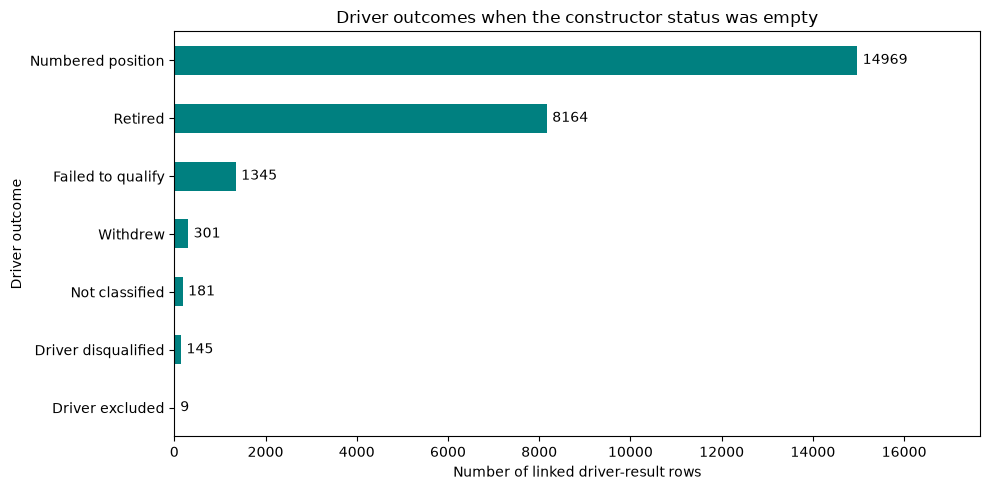

In [22]:
constructor_blank_keys = constructor_results.loc[
    constructor_status_before.isna(), ["raceId", "constructorId"]
]

# Check coverage first: a missing driver match does not prove anything about participation.
constructor_status_coverage = constructor_blank_keys.merge(
    results[["raceId", "constructorId"]].drop_duplicates(),
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
display(constructor_status_coverage["_merge"].value_counts().rename_axis("Driver-result match").to_frame("Constructor-result rows"))

constructor_blank_driver_results = results[
    ["raceId", "constructorId", "driverId", "positionText", "statusId"]
].merge(constructor_blank_keys, on=["raceId", "constructorId"], validate="many_to_one")

# These codes belong to driver positionText, not constructor status.
driver_outcome_names = {
    "R": "Retired", "F": "Failed to qualify", "W": "Withdrew",
    "D": "Driver disqualified", "E": "Driver excluded", "N": "Not classified"
}
constructor_blank_driver_results["Driver outcome"] = (
    constructor_blank_driver_results["positionText"].map(driver_outcome_names)
)
numbered_position = pd.to_numeric(
    constructor_blank_driver_results["positionText"], errors="coerce"
).notna()
constructor_blank_driver_results.loc[numbered_position, "Driver outcome"] = "Numbered position"
assert constructor_blank_driver_results["Driver outcome"].notna().all(), "Investigate an unfamiliar driver outcome."

constructor_blank_outcomes = constructor_blank_driver_results["Driver outcome"].value_counts()
display(constructor_blank_outcomes.to_frame("Driver-result rows"))

ax = constructor_blank_outcomes.sort_values().plot.barh(figsize=(10, 5), color="teal")
ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, constructor_blank_outcomes.max() * 1.18)
ax.set_title("Driver outcomes when the constructor status was empty")
ax.set_xlabel("Number of linked driver-result rows")
ax.set_ylabel("Driver outcome")
plt.tight_layout()
plt.show()


In [23]:
# Show readable examples from the most recent records in each outcome group.
constructor_status_examples = (
    constructor_blank_driver_results
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "Race"}), on="raceId", validate="many_to_one")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}), on="constructorId", validate="many_to_one")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
    .merge(status.rename(columns={"status": "Driver status"}), on="statusId", validate="many_to_one")
    .sort_values(["year", "raceId"])
    .groupby("Driver outcome", sort=False).tail(1)
)
display(constructor_status_examples[
    ["raceId", "year", "Race", "Constructor", "forename", "surname", "Driver outcome", "Driver status"]
])

# Investigate the D flags separately, using the race and team reference tables.
constructor_d_evidence = (
    constructor_results.loc[constructor_status_before.eq("D").fillna(False)]
    .merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
    .merge(constructors[["constructorId", "name"]], on="constructorId", validate="many_to_one")
)
display(constructor_d_evidence.groupby(["year", "name", "status"]).size().to_frame("Constructor-result rows"))


,raceId,year,Race,Constructor,forename,surname,Driver outcome,Driver status
21891,841,2011,Australian Grand Prix,HRT,Narain,Karthikeyan,Failed to qualify,Did not qualify
20496,900,2014,Australian Grand Prix,Marussia,Jules,Bianchi,Not classified,+8 Laps
21247,944,2015,Brazilian Grand Prix,Williams,Felipe,Massa,Driver excluded,Excluded
25052,1141,2024,São Paulo Grand Prix,Aston Martin,Lance,Stroll,Withdrew,Withdrew
25053,1141,2024,São Paulo Grand Prix,Haas F1 Team,Nico,Hülkenberg,Driver disqualified,Disqualified
25110,1144,2024,Abu Dhabi Grand Prix,RB F1 Team,Liam,Lawson,Numbered position,Engine
25113,1144,2024,Abu Dhabi Grand Prix,Red Bull,Sergio,Pérez,Retired,Collision


,,,Constructor-result rows
year,name,status,
2007,McLaren,D,17


### What the evidence tells us

- Blank constructor flags coexist with numbered driver positions, retirements, failures to qualify, withdrawals and driver disqualifications. Therefore, we cannot fill blanks with `Q`, `Finished`, or a claim that no driver was disqualified.
- All 17 recorded constructor `D` flags belong to McLaren in 2007. The [official 2007 team standings](https://www.formula1.com/en/results/2007/team) show McLaren excluded with zero championship points. This supports the interpretation of the constructor flag; it does not make every driver result a disqualification.
- Seven blank constructor-result records have no matching race–constructor pair in `results`. They remain visible in the coverage count and need a separate record-consistency review. The driver-outcome chart makes no claim about those unmatched records.

### Step 3 — Assign an explicit label in the existing clean column

We use **`ND` = No constructor disqualification flag recorded**. It is our descriptive cleaning code for the source's empty value, not an original Ergast code. It does not mean qualified, finished, or independently verified as free of every penalty.

We keep existing `D` values and fill only empty flags. This is a categorical relabeling supported by the source definition, rather than estimating missing facts with a mean or median. The raw table and the other columns remain unchanged.


### 3.2.2 Constructor Results: Cleaning Pipeline & Integrity Checks
Executing transformations to standardize the dataset: replacing `\N` placeholders, casting `points` to numeric types, and mapping empty status flags to "ND" (Not Disqualified) while preserving "D" flags. Includes strict assertions to guarantee primary key uniqueness and valid foreign key mappings.

In [24]:
constructor_results_clean = constructor_results.copy(deep=True).replace(r"\N", np.nan)
constructor_results_clean["points"] = pd.to_numeric(constructor_results_clean["points"], errors="raise")

# Keep the same status column; preserve D and label empty flags as ND.
constructor_results_clean["status"] = constructor_status_before.fillna("ND")
display(constructor_results_clean.head())


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,ND
1,2,18,2,8.0,ND
2,3,18,3,9.0,ND
3,4,18,4,5.0,ND
4,5,18,5,2.0,ND


### Step 4 — Compare before and after

The missing-value comparison combines recognized nulls, literal `\N` and blank text, so the original placeholders are counted as unavailable values even before pandas recognizes them as nulls. The plots show whether the 12,608 empty flags become `ND` and whether the 17 `D` flags are preserved. These counts demonstrate the effect; the source definition and cross-table investigation above justify the label.


,Missing BEFORE,Missing AFTER,Data type BEFORE,Data type AFTER
constructorResultsId,0,0,int64,int64
raceId,0,0,int64,int64
constructorId,0,0,int64,int64
points,0,0,float64,float64
status,12608,0,object,string


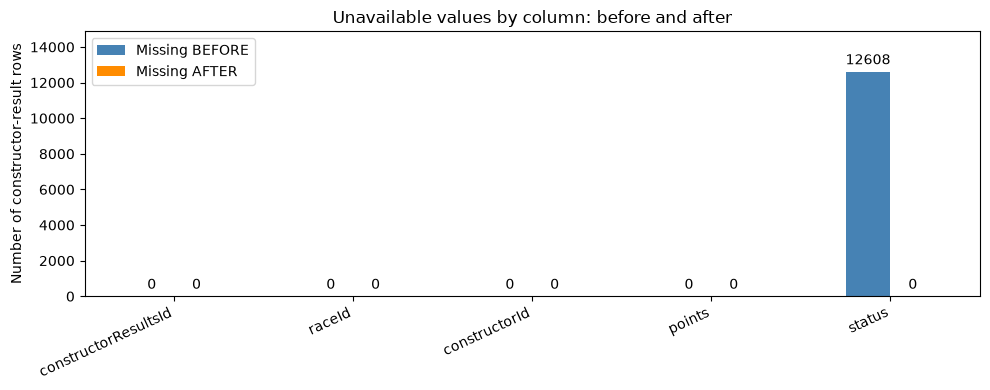

In [25]:
constructor_results_missing_before = (
    constructor_results.astype("string").apply(lambda column: column.str.strip())
    .replace({r"\N": pd.NA, "": pd.NA}).isna().sum()
)
constructor_results_comparison = pd.DataFrame({
    "Missing BEFORE": constructor_results_missing_before,
    "Missing AFTER": constructor_results_clean.isna().sum(),
    "Data type BEFORE": constructor_results.dtypes.astype(str),
    "Data type AFTER": constructor_results_clean.dtypes.astype(str)
})
display(constructor_results_comparison)

ax = constructor_results_comparison[["Missing BEFORE", "Missing AFTER"]].plot.bar(
    figsize=(10, 4), color=["steelblue", "darkorange"]
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_ylim(0, max(constructor_results_missing_before.max(), 1) * 1.18)
ax.set_title("Unavailable values by column: before and after")
ax.set_ylabel("Number of constructor-result rows")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


,Before,After
status,,
Empty,12608,0
ND,0,12608
D,17,17


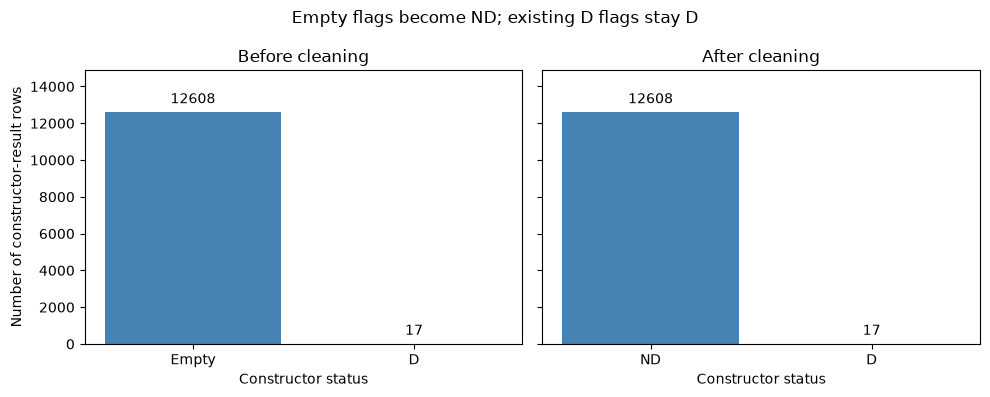

,constructorResultsId,raceId,constructorId,Status BEFORE,Status AFTER
0,1,18,1,\N,ND
1,2,18,2,\N,ND
2,3,18,3,\N,ND
3,4,18,4,\N,ND
4,5,18,5,\N,ND


In [26]:
constructor_status_counts = pd.DataFrame({
    "Before": constructor_status_before.fillna("Empty").value_counts(),
    "After": constructor_results_clean["status"].value_counts()
}).reindex(["Empty", "ND", "D"]).fillna(0).astype(int)
display(constructor_status_counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, stage, labels in zip(axes, ["Before", "After"], [["Empty", "D"], ["ND", "D"]]):
    counts = constructor_status_counts.loc[labels, stage]
    bars = ax.bar(counts.index, counts.values, color=["steelblue", "darkorange"])
    ax.bar_label(bars, padding=4)
    ax.set_title(stage + " cleaning")
    ax.set_ylim(0, max(constructor_status_counts.max().max(), 1) * 1.18)
    ax.set_xlabel("Constructor status")
axes[0].set_ylabel("Number of constructor-result rows")
fig.suptitle("Empty flags become ND; existing D flags stay D")
plt.tight_layout()
plt.show()

# Show the actual existing column for a few changed records.
constructor_status_changes = constructor_results.loc[
    constructor_status_before.isna(), ["constructorResultsId", "raceId", "constructorId", "status"]
].head().rename(columns={"status": "Status BEFORE"})
constructor_status_changes["Status AFTER"] = constructor_results_clean.loc[constructor_status_changes.index, "status"]
display(constructor_status_changes)


In [27]:
display(constructor_results_clean["status"].value_counts(dropna=False).to_frame("Constructor-result rows"))

# D flags only: after filling, notna() would select every row, including ND.
display(constructor_results_clean.loc[constructor_results_clean["status"].eq("D")])


,Constructor-result rows
status,
ND,12608
D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


### Step 5 — Check preservation, keys and references

The checks below ensure that each original empty status becomes `ND`, each `D` remains `D`, and no rows or columns are added or removed. Primary-key and foreign-key checks are retained, but passing them alone does not resolve the separate extra/missing-record investigation.


In [28]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [29]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


In [30]:
constructor_results_checks = pd.Series({
    "Rows unchanged": len(constructor_results_clean) == len(constructor_results),
    "Columns unchanged": constructor_results_clean.columns.equals(constructor_results.columns),
    "No placeholders remain": not constructor_results_clean.eq(r"\N").any().any(),
    "No duplicate complete rows": not constructor_results_clean.duplicated().any(),
    "No missing status values": constructor_results_clean["status"].notna().all(),
    "Only D and ND status labels": constructor_results_clean["status"].isin(["D", "ND"]).all(),
    "Every empty status becomes ND": constructor_results_clean.loc[constructor_status_before.isna(), "status"].eq("ND").all(),
    "Every D flag stays D": constructor_results_clean.loc[constructor_status_before.eq("D").fillna(False), "status"].eq("D").all(),
    "ND count equals original empty count": constructor_results_clean["status"].eq("ND").sum() == constructor_status_before.isna().sum(),
    "D count unchanged": constructor_results_clean["status"].eq("D").sum() == constructor_status_before.eq("D").sum(),
    "Points are numeric": pd.api.types.is_numeric_dtype(constructor_results_clean["points"]),
    "Points non-negative": constructor_results_clean["points"].dropna().ge(0).all()
})
display(constructor_results_checks.to_frame("Passed"))
assert constructor_results_checks.all(), "Investigate failed constructor-result checks."
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
pd.testing.assert_frame_equal(
    constructor_results.drop(columns="status"), constructor_results_clean.drop(columns="status")
)
print("Passed: raw table and all non-status columns are unchanged.")
constructor_results_clean.info()


,Passed
Rows unchanged,True
Columns unchanged,True
No placeholders remain,True
No duplicate complete rows,True
No missing status values,True
Only D and ND status labels,True
Every empty status becomes ND,True
Every D flag stays D,True
ND count equals original empty count,True
D count unchanged,True


Passed: raw table and all non-status columns are unchanged.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  string 
dtypes: float64(1), int64(3), string(1)
memory usage: 493.3 KB


### Findings for this missing-value step

The original table has **12,625 rows and 5 columns**. Its `status` contains **12,608 empty flags (99.87%)** and **17 `D` flags**. At this stage, before the separate record correction below, the clean version contains **12,608 `ND` values**, the same **17 `D` flags**, and **zero empty status values**. No rows or columns were removed or added.

The before/after graphs show the transformation; the linked-driver outcome graph explains why `Qualified` or `Finished` would be misleading. `ND` means only **No constructor disqualification flag recorded**. It is a readable representation of the source's empty flag, not newly recovered information.

The column is retained because the recorded constructor flag has meaning. Current-race constructor status is excluded from pre-race model inputs. No numerical encoding is needed in this cleaning step.

**Scope:** this completes the status missing-value treatment. The extra-record correction follows below. Missing race–constructor records remain a separate review.


### Step 6 — Investigate extra race–constructor records

The earlier checks ask whether IDs exist and whether race–constructor pairs are unique **within this table**. They do not establish whether a constructor belongs in a particular race. This step compares each `(raceId, constructorId)` with the same pair in `results`.

A missing match is a reason to investigate, not a general deletion rule. We reviewed the seven unmatched records against their existing counterparts and official race classifications. The correction below applies only to seven explicit race–constructor pairs. It never removes a constructor's whole history.


### 3.2.3 Constructor Results: Resolving Redundant Race-Team Pairs
Identifying and removing redundant constructor entries for a single race. This cross-references the `results` table and official driver rosters to prove that 7 specific redundant constructor IDs can be safely dropped without losing driver outcome data.

In [31]:
constructor_results_before_pair_fix = constructor_results_clean.copy(deep=True)
driver_race_constructor_pairs = results[["raceId", "constructorId"]].drop_duplicates()

constructor_pair_coverage_before = constructor_results_before_pair_fix.merge(
    driver_race_constructor_pairs, on=["raceId", "constructorId"],
    how="left", validate="one_to_one", indicator=True
)
constructor_unmatched_before = constructor_pair_coverage_before.loc[
    constructor_pair_coverage_before["_merge"].eq("left_only")
].drop(columns="_merge")

display(constructor_unmatched_before
    .merge(races[["raceId", "year", "name"]].rename(columns={"name": "Race"}), on="raceId")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}), on="constructorId")
    [["constructorResultsId", "raceId", "year", "Race", "constructorId", "Constructor", "points"]]
    .sort_values(["year", "raceId"]))
print("Constructor-result records with no driver-result pair:", len(constructor_unmatched_before))


,constructorResultsId,raceId,year,Race,constructorId,Constructor,points
1,6483,514,1979,South African Grand Prix,34,Brabham,1.0
2,6610,522,1979,Austrian Grand Prix,34,Brabham,0.0
0,3018,124,2002,Australian Grand Prix,2,BMW Sauber,0.0
3,15123,937,2015,Belgian Grand Prix,206,Marussia,0.0
4,15165,941,2015,Russian Grand Prix,206,Marussia,0.0
5,15184,943,2015,Mexican Grand Prix,206,Marussia,0.0
6,15206,945,2015,Abu Dhabi Grand Prix,206,Marussia,0.0


Constructor-result records with no driver-result pair: 7


### Step 7 — Show the constructor identities and reference URLs

Brabham (`34`) and Brabham–Alfa Romeo (`204`) share a reference URL in the source. This supports a historical connection, but does not independently justify deleting a race result. The Sauber and Marussia pairs have different URLs, so we do not claim that a shared URL establishes their identity.

The decisive evidence is race-specific: the official classification identifies the drivers and team entry, those drivers link to one ID in `results`, and that ID already has a constructor-summary row.


In [32]:
# Each tuple is: race, redundant constructor, supported constructor.
# These are reviewed exceptions, not a general name-matching rule.
constructor_pair_corrections = pd.DataFrame([
    (514, 34, 204), (522, 34, 204), (124, 2, 15),
    (937, 206, 209), (941, 206, 209), (943, 206, 209), (945, 206, 209)
], columns=["raceId", "Remove constructorId", "Keep constructorId"])

constructor_identity_evidence = (
    constructor_pair_corrections[["Remove constructorId", "Keep constructorId"]].drop_duplicates()
    .merge(constructors[["constructorId", "name", "url"]].rename(columns={
        "constructorId": "Remove constructorId", "name": "Name of redundant entry", "url": "URL of redundant entry"
    }), on="Remove constructorId", validate="one_to_one")
    .merge(constructors[["constructorId", "name", "url"]].rename(columns={
        "constructorId": "Keep constructorId", "name": "Name of retained entry", "url": "URL of retained entry"
    }), on="Keep constructorId", validate="one_to_one")
)
constructor_identity_evidence["Same source URL?"] = (
    constructor_identity_evidence["URL of redundant entry"].eq(constructor_identity_evidence["URL of retained entry"])
)
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(constructor_identity_evidence)


,Remove constructorId,Keep constructorId,Name of redundant entry,URL of redundant entry,Name of retained entry,URL of retained entry,Same source URL?
0,34,204,Brabham,http://en.wikipedia.org/wiki/Brabham,Brabham-Alfa Romeo,http://en.wikipedia.org/wiki/Brabham,True
1,2,15,BMW Sauber,http://en.wikipedia.org/wiki/BMW_Sauber,Sauber,http://en.wikipedia.org/wiki/Sauber_Motorsport,False
2,206,209,Marussia,http://en.wikipedia.org/wiki/Marussia_F1,Manor Marussia,http://en.wikipedia.org/wiki/Manor_Motorsport,False


### Step 8 — Record the official evidence for every affected race

The following small reference table contains **manually transcribed observations from official classifications**, checked on **11 October 2026**. Its source links are retained for review. The notebook compares these observations with the local driver records; it does not scrape the websites when run.

| Dataset raceId | Race | Official team label | Official drivers | Official race classification |
|---:|---|---|---|---|
| 514 | South Africa 1979 | Brabham Alfa Romeo | Niki Lauda; Nelson Piquet | [F1 classification](https://www.formula1.com/en/results/1979/races/409/south-africa/race-result) |
| 522 | Austria 1979 | Brabham Alfa Romeo | Niki Lauda; Nelson Piquet | [F1 classification](https://www.formula1.com/en/results/1979/races/417/austria/race-result) |
| 124 | Australia 2002 | Sauber Petronas | Felipe Massa; Nick Heidfeld | [F1 classification](https://www.formula1.com/en/results/2002/races/720/australia/race-result) |
| 937 | Belgium 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/928/belgium/race-result) |
| 941 | Russia 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/932/russia/race-result) |
| 943 | Mexico 2015 | Marussia Ferrari | Alexander Rossi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/934/mexico/race-result) |
| 945 | Abu Dhabi 2015 | Marussia Ferrari | Roberto Merhi; Will Stevens | [F1 classification](https://www.formula1.com/en/results/2015/races/936/abu-dhabi/race-result) |

The official pages use their own race numbers in the URLs; these are not the Kaggle `raceId` values. We matched events by year and Grand Prix.

**Why the different names can describe the same entry here:**

- **Brabham:** the common source URL supports a connection. Both reviewed official classifications list Lauda and Piquet as Brabham Alfa Romeo, with no separate additional Brabham entry. Their local driver records use `204`.
- **Sauber:** the 2002 official classification lists Massa and Heidfeld as Sauber Petronas. Their local driver records use `15`. [F1's team history](https://www.formula1.com/en/latest/article/saubers-best-moments-and-most-memorable-liveries-in-f1.6OIgJH4jiY29sJIHNFrG1W) dates the BMW Sauber partnership to 2006, so the additional BMW Sauber summary in 2002 is unsupported.
- **Marussia:** [F1's 2015 Rossi announcement](https://www.formula1.com/en/latest/article/marussia-hand-rossi-race-debut-in-singapore.6UMXTLJHDEu5LuWC4R0Djd) calls the team Marussia while Rossi identifies it as Manor Marussia in the same article. The [FIA's 2015 classification](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/2015-classifications) lists one Manor Marussia entry. The race classifications above show the same driver pairs that the local data links to `209`, rather than another separate Marussia team.

Similar names and equal points alone are not our evidence for removal. These source observations and local joins together support interpreting the seven extra summaries as redundant entries.


In [33]:
constructor_official_evidence = pd.DataFrame([
    (514, "Brabham Alfa Romeo", "Nelson Piquet; Niki Lauda"),
    (522, "Brabham Alfa Romeo", "Nelson Piquet; Niki Lauda"),
    (124, "Sauber Petronas", "Felipe Massa; Nick Heidfeld"),
    (937, "Marussia Ferrari", "Roberto Merhi; Will Stevens"),
    (941, "Marussia Ferrari", "Roberto Merhi; Will Stevens"),
    (943, "Marussia Ferrari", "Alexander Rossi; Will Stevens"),
    (945, "Marussia Ferrari", "Roberto Merhi; Will Stevens")
], columns=["raceId", "Official team", "Official drivers"])

constructor_review_drivers = (
    results[["resultId", "raceId", "constructorId", "driverId", "number", "points"]]
    .merge(constructor_pair_corrections, on="raceId", validate="many_to_one")
)
constructor_review_drivers = constructor_review_drivers.loc[
    constructor_review_drivers["constructorId"].eq(constructor_review_drivers["Keep constructorId"])
    | constructor_review_drivers["constructorId"].eq(constructor_review_drivers["Remove constructorId"])
].merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
constructor_review_drivers["Driver"] = constructor_review_drivers["forename"] + " " + constructor_review_drivers["surname"]
display(constructor_review_drivers[
    ["resultId", "raceId", "constructorId", "driverId", "Driver", "number", "points"]
].sort_values(["raceId", "driverId"]))

constructor_local_driver_names = (
    constructor_review_drivers.groupby("raceId")["Driver"]
    .agg(lambda names: "; ".join(sorted(names)))
    .rename("Drivers in local results").reset_index()
)
constructor_official_comparison = constructor_official_evidence.merge(
    constructor_local_driver_names, on="raceId", validate="one_to_one"
)
constructor_official_comparison["Drivers agree?"] = constructor_official_comparison[
    "Official drivers"
].eq(constructor_official_comparison["Drivers in local results"])
display(constructor_official_comparison)
assert constructor_official_comparison["Drivers agree?"].all()


,resultId,raceId,constructorId,driverId,Driver,number,points
1,2213,124,15,2,Nick Heidfeld,7,0.0
0,2212,124,15,13,Felipe Massa,8,0.0
3,12435,514,204,137,Nelson Piquet,6,0.0
2,12434,514,204,182,Niki Lauda,5,1.0
5,12654,522,204,137,Nelson Piquet,6,0.0
4,12650,522,204,182,Niki Lauda,5,0.0
7,22751,937,209,829,Will Stevens,28,0.0
6,22750,937,209,833,Roberto Merhi,98,0.0
9,22829,941,209,829,Will Stevens,28,0.0
8,22828,941,209,833,Roberto Merhi,98,0.0


,raceId,Official team,Official drivers,Drivers in local results,Drivers agree?
0,514,Brabham Alfa Romeo,Nelson Piquet; Niki Lauda,Nelson Piquet; Niki Lauda,True
1,522,Brabham Alfa Romeo,Nelson Piquet; Niki Lauda,Nelson Piquet; Niki Lauda,True
2,124,Sauber Petronas,Felipe Massa; Nick Heidfeld,Felipe Massa; Nick Heidfeld,True
3,937,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True
4,941,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True
5,943,Marussia Ferrari,Alexander Rossi; Will Stevens,Alexander Rossi; Will Stevens,True
6,945,Marussia Ferrari,Roberto Merhi; Will Stevens,Roberto Merhi; Will Stevens,True


### Step 9 — Show the existing summaries and verify the removal conditions

For every proposed removal, we check that the redundant ID has zero driver-result rows in this race, the retained ID has the verified drivers, and both summaries already exist. Equal points are shown as a consistency check, not proof of identity. Every check must pass before removing any row.


In [34]:
constructor_removal_evidence = (
    constructor_pair_corrections
    .merge(constructor_results_before_pair_fix.rename(columns={
        "constructorId": "Remove constructorId", "constructorResultsId": "Remove record ID",
        "points": "Points in removed row", "status": "Status in removed row"
    }), on=["raceId", "Remove constructorId"], validate="one_to_one")
    .merge(constructor_results_before_pair_fix.rename(columns={
        "constructorId": "Keep constructorId", "constructorResultsId": "Keep record ID",
        "points": "Points in retained row", "status": "Status in retained row"
    }), on=["raceId", "Keep constructorId"], validate="one_to_one")
)

driver_counts = results.groupby(["raceId", "constructorId"]).size().rename("Driver rows").reset_index()
constructor_removal_evidence = (
    constructor_removal_evidence
    .merge(driver_counts.rename(columns={"constructorId": "Remove constructorId", "Driver rows": "Driver rows for removed ID"}),
           on=["raceId", "Remove constructorId"], how="left", validate="one_to_one")
    .merge(driver_counts.rename(columns={"constructorId": "Keep constructorId", "Driver rows": "Driver rows for retained ID"}),
           on=["raceId", "Keep constructorId"], how="left", validate="one_to_one")
)
constructor_removal_evidence[["Driver rows for removed ID", "Driver rows for retained ID"]] = (
    constructor_removal_evidence[["Driver rows for removed ID", "Driver rows for retained ID"]].fillna(0).astype(int)
)
display(constructor_removal_evidence)

assert len(constructor_removal_evidence) == 7
assert constructor_removal_evidence["Driver rows for removed ID"].eq(0).all()
assert constructor_removal_evidence["Driver rows for retained ID"].eq(2).all()
assert constructor_removal_evidence["Points in removed row"].eq(constructor_removal_evidence["Points in retained row"]).all()
assert constructor_removal_evidence["Status in removed row"].eq(constructor_removal_evidence["Status in retained row"]).all()


,raceId,Remove constructorId,Keep constructorId,Remove record ID,Points in removed row,Status in removed row,Keep record ID,Points in retained row,Status in retained row,Driver rows for removed ID,Driver rows for retained ID
0,514,34,204,6483,1.0,ND,13898,1.0,ND,0,2
1,522,34,204,6610,0.0,ND,13899,0.0,ND,0,2
2,124,2,15,3018,0.0,ND,1108,0.0,ND,0,2
3,937,206,209,15123,0.0,ND,15124,0.0,ND,0,2
4,941,206,209,15165,0.0,ND,15164,0.0,ND,0,2
5,943,206,209,15184,0.0,ND,15196,0.0,ND,0,2
6,945,206,209,15206,0.0,ND,15207,0.0,ND,0,2


### Step 10 — Remove only the seven reviewed combinations

The filter uses **both raceId and constructorId**. We keep the removed records in `constructor_results_removed` for the audit trail. This is a separate audit table; `constructor_results_clean` keeps its original five columns. We do not rename constructor IDs or remove any record in `constructors` or `results`.


In [35]:
pairs_to_remove = pd.MultiIndex.from_frame(
    constructor_pair_corrections[["raceId", "Remove constructorId"]]
)
current_pairs = pd.MultiIndex.from_frame(
    constructor_results_before_pair_fix[["raceId", "constructorId"]]
)
remove_constructor_rows = current_pairs.isin(pairs_to_remove)

constructor_results_removed = constructor_results_before_pair_fix.loc[remove_constructor_rows].copy()
assert len(constructor_results_removed) == len(constructor_pair_corrections)

constructor_results_clean = constructor_results_before_pair_fix.loc[~remove_constructor_rows].copy()
print("Removed records (retained here for auditing):")
display(constructor_results_removed)
print("Rows before:", len(constructor_results_before_pair_fix))
print("Rows after:", len(constructor_results_clean))


Removed records (retained here for auditing):

,constructorResultsId,raceId,constructorId,points,status
3017,3018,124,2,0.0,ND
6474,6483,514,34,1.0,ND
6566,6610,522,34,0.0,ND
10624,15123,937,206,0.0,ND
10666,15165,941,206,0.0,ND
10685,15184,943,206,0.0,ND
10707,15206,945,206,0.0,ND


Rows before: 12625
Rows after: 12618


### Step 11 — Compare before and after and check the final table

The plot shows the two reviewed summaries becoming one for each affected race. It demonstrates the effect; the official classifications and joined records above explain why the specific row was removed. The second table shows that other races for IDs `34`, `2` and `206` remain in the clean data.


,raceId,Race,Before,After
513,514,1979 South African,2,1
521,522,1979 Austrian,2,1
123,124,2002 Australian,2,1
926,937,2015 Belgian,2,1
930,941,2015 Russian,2,1
932,943,2015 Mexican,2,1
934,945,2015 Abu Dhabi,2,1


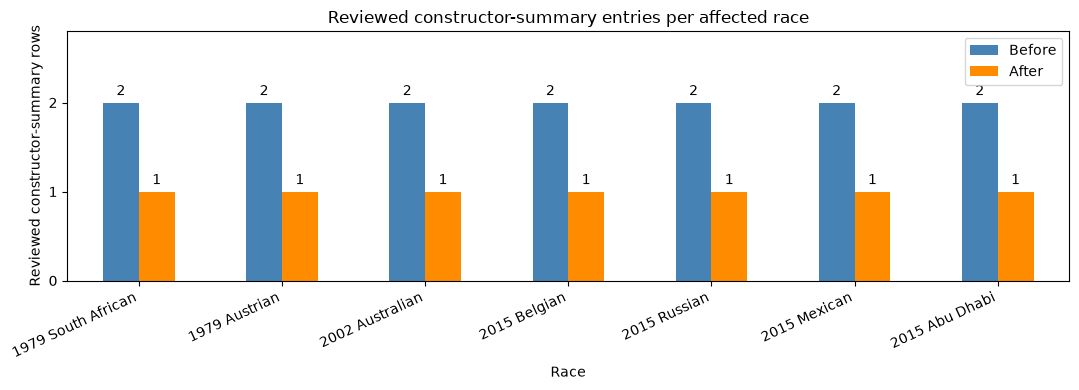

,Before,After,Removed
constructorId,,,
34,310,308,2
2,71,70,1
206,59,55,4


In [36]:
# Count only each race's two reviewed IDs, not other constructors in that race.
def reviewed_constructor_counts(table):
    reviewed = table.merge(constructor_pair_corrections, on="raceId", validate="many_to_one")
    selected = reviewed["constructorId"].eq(reviewed["Remove constructorId"]) | reviewed["constructorId"].eq(reviewed["Keep constructorId"])
    return reviewed.loc[selected].groupby("raceId").size()

constructor_affected_counts = pd.DataFrame({
    "Before": reviewed_constructor_counts(constructor_results_before_pair_fix),
    "After": reviewed_constructor_counts(constructor_results_clean)
}).loc[constructor_pair_corrections["raceId"]]
assert constructor_affected_counts["Before"].eq(2).all()
assert constructor_affected_counts["After"].eq(1).all()
constructor_affected_counts = constructor_affected_counts.merge(
    races[["raceId", "year", "name"]], left_index=True, right_on="raceId", validate="one_to_one"
)
constructor_affected_counts["Race"] = constructor_affected_counts["year"].astype(str) + " " + constructor_affected_counts["name"].str.replace(" Grand Prix", "", regex=False)
display(constructor_affected_counts[["raceId", "Race", "Before", "After"]])

ax = constructor_affected_counts.set_index("Race")[["Before", "After"]].plot.bar(
    figsize=(11, 4), color=["steelblue", "darkorange"]
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_ylim(0, 2.8)
ax.set_yticks([0, 1, 2])
ax.set_title("Reviewed constructor-summary entries per affected race")
ax.set_ylabel("Reviewed constructor-summary rows")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

constructor_history_counts = pd.DataFrame({
    "Before": constructor_results_before_pair_fix.groupby("constructorId").size(),
    "After": constructor_results_clean.groupby("constructorId").size()
}).loc[constructor_pair_corrections["Remove constructorId"].unique()]
constructor_history_counts["Removed"] = constructor_history_counts["Before"] - constructor_history_counts["After"]
display(constructor_history_counts)
assert constructor_history_counts["After"].gt(0).all(), "A constructor's entire history was removed."


In [37]:
constructor_pair_coverage_after = constructor_results_clean.merge(
    driver_race_constructor_pairs, on=["raceId", "constructorId"],
    how="left", validate="one_to_one", indicator=True
)
constructor_pair_fix_summary = pd.DataFrame({
    "Before pair correction": [len(constructor_results_before_pair_fix), len(constructor_results_before_pair_fix.columns),
        constructor_pair_coverage_before["_merge"].eq("left_only").sum()],
    "After pair correction": [len(constructor_results_clean), len(constructor_results_clean.columns),
        constructor_pair_coverage_after["_merge"].eq("left_only").sum()]
}, index=["Rows", "Columns", "Constructor-result pairs absent from results"])
display(constructor_pair_fix_summary)
display(constructor_results_clean["status"].value_counts().to_frame("Final constructor-result rows"))

# Prove that the seven reviewed pairs are absent and every other cleaned row is identical.
assert len(constructor_results_before_pair_fix) - len(constructor_results_clean) == 7
assert constructor_results_clean.columns.equals(constructor_results.columns)
assert not pd.MultiIndex.from_frame(constructor_results_clean[["raceId", "constructorId"]]).isin(pairs_to_remove).any()
assert constructor_pair_coverage_after["_merge"].eq("both").all()
assert constructor_results_clean["constructorResultsId"].notna().all()
assert constructor_results_clean["constructorResultsId"].is_unique
assert not constructor_results_clean.duplicated(["raceId", "constructorId"]).any()
assert constructor_results_clean["raceId"].isin(races["raceId"]).all()
assert constructor_results_clean["constructorId"].isin(constructors["constructorId"]).all()
assert constructor_results_clean["status"].isin(["D", "ND"]).all()
assert constructor_results_clean["status"].eq("D").sum() == constructor_results_before_pair_fix["status"].eq("D").sum()
pd.testing.assert_frame_equal(
    constructor_results_clean, constructor_results_before_pair_fix.loc[~remove_constructor_rows]
)
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
print("Passed: only the seven reviewed race-constructor rows were removed; every retained cleaned row is unchanged.")


,Before pair correction,After pair correction
Rows,12625,12618
Columns,5,5
Constructor-result pairs absent from results,7,0


,Final constructor-result rows
status,
ND,12601
D,17


Passed: only the seven reviewed race-constructor rows were removed; every retained cleaned row is unchanged.


### Findings for the extra-record correction

We removed **seven specific race–constructor records**, retaining their supported summaries. After removal, and before the reconstruction below, the table has **12,618 rows and the same 5 columns**. IDs `34`, `2` and `206` still have their other race records. The 17 `D` flags remain; `ND` now occurs in 12,601 rows because the seven removed rows were all `ND`.

All remaining constructor-result pairs match a pair in `results`. This checks only the direction **constructor_results → results**. It does not establish that every team appearing in `results` has a constructor summary. The next steps investigate the reverse direction and reconstruct only two independently reviewed summaries.

The raw CSVs and tables remain unchanged. The removed-row audit, reference URLs, official sources, driver links, retained counterparts, before/after counts and checks document the correction.


### Step 12 — Find missing summaries in the reverse direction

Now we ask: **does each race–constructor pair in `results` have a summary in `constructor_results_clean`?** This is different from checking that an ID exists somewhere in another table.

There are 410 unmatched pairs before this step. We investigate their meaning before adding anything:

| Group | Pairs | Treatment and evidence |
|---|---:|---|
| Before 1958 | 400 | No constructor-championship summary is required: [F1 explains that the championship began in 1958](https://www.formula1.com/en/latest/article/the-beginners-guide-to-the-f1-constructors-championship.66nTfWSqrUYv3bnbosPkHV). Keep the driver results; do not invent constructor summaries. |
| Indianapolis 1958 | 7 | This event did not count towards the constructors' competition, as explained by this [secondary historical source](https://www.formulaonehistory.com/seasons/1958-f1-world-championship/). Keep these as documented event exceptions. |
| HRT, Australia 2012 | 1 | Both drivers failed to qualify. [Official qualifying results](https://www.formula1.com/en/results/2012/races/10/australia/qualifying) confirm the 107% failure. Keep this as a documented non-starting entry, without assuming every non-starting team is omitted by the source. |
| BRM, France 1959; March–Alfa Romeo, Spain 1971 | 2 | The teams actually raced, and existing summaries for these constructors include other zero-point races. Review and reconstruct these two only. |

The code checks these exact groups. Any other unmatched pair stops the check so it must be investigated. This documents missing **records**, rather than filling every absence with zero.


### 3.2.4 Constructor Results: Reconstructing Missing Records & Final Validation
Auditing historical gaps in the constructor summaries. This isolates legitimate exceptions (e.g., pre-1958 rules) and manually reconstructs two verifiable missing records. Concludes with a rigorous suite of assertion tests to prove zero unintended data loss before finalizing the table.

In [38]:
constructor_results_before_reconstruction = constructor_results_clean.copy(deep=True)
constructor_missing_pairs = driver_race_constructor_pairs.merge(
    constructor_results_before_reconstruction[["raceId", "constructorId"]],
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
constructor_missing_pairs = constructor_missing_pairs.loc[
    constructor_missing_pairs["_merge"].eq("left_only"), ["raceId", "constructorId"]
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")

constructor_missing_pairs["Reason"] = "Needs investigation"
constructor_missing_pairs.loc[constructor_missing_pairs["year"].lt(1958), "Reason"] = "Before constructors championship"
constructor_missing_pairs.loc[constructor_missing_pairs["raceId"].eq(768), "Reason"] = "Indianapolis 1958 exception"
constructor_missing_pairs.loc[
    constructor_missing_pairs["raceId"].eq(860) & constructor_missing_pairs["constructorId"].eq(164), "Reason"
] = "HRT did not qualify"

# Existing IDs for the two reviewed missing summaries.
constructor_reconstruction_pairs = pd.DataFrame([
    (759, 66), (633, 199)
], columns=["raceId", "constructorId"])
reviewed_pairs = pd.MultiIndex.from_frame(constructor_reconstruction_pairs)
missing_pairs = pd.MultiIndex.from_frame(constructor_missing_pairs[["raceId", "constructorId"]])
constructor_missing_pairs.loc[missing_pairs.isin(reviewed_pairs), "Reason"] = "Reviewed missing summary"

display(constructor_missing_pairs.groupby("Reason").size().to_frame("Missing pairs"))
assert len(constructor_missing_pairs) == 410
assert not constructor_missing_pairs["Reason"].eq("Needs investigation").any()
assert constructor_missing_pairs["Reason"].value_counts().to_dict() == {
    "Before constructors championship": 400, "Indianapolis 1958 exception": 7,
    "HRT did not qualify": 1, "Reviewed missing summary": 2
}


,Missing pairs
Reason,
Before constructors championship,400
HRT did not qualify,1
Indianapolis 1958 exception,7
Reviewed missing summary,2


### Step 13 — Show the existing IDs, drivers and earlier records

`constructorId` identifies a constructor and repeats across races. We reuse **66 for BRM** and **199 for March–Alfa Romeo**, joining to the existing `constructors` and `races` tables. We are not creating new teams.

The first table shows drivers in the two affected races. The second shows earlier constructor summaries with these same IDs. The third shows championship points immediately before and after each affected race. Unchanged season totals support zero points here, but are only a cross-check: historical scoring rules can differ from modern rules.


In [39]:
constructor_reconstruction_drivers = (
    results.merge(constructor_reconstruction_pairs, on=["raceId", "constructorId"], validate="many_to_one")
    .merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
    .merge(status, on="statusId", validate="many_to_one")
)
constructor_reconstruction_drivers["Driver"] = (
    constructor_reconstruction_drivers["forename"] + " " + constructor_reconstruction_drivers["surname"]
)
display(constructor_reconstruction_drivers[
    ["raceId", "constructorId", "resultId", "driverId", "Driver", "laps", "positionText", "points", "status"]
])
assert constructor_reconstruction_drivers.groupby("raceId").size().to_dict() == {633: 1, 759: 4}
assert constructor_reconstruction_drivers["laps"].gt(0).all()

# These are earlier races, already present in the source data.
constructor_earlier_pairs = pd.DataFrame([(758, 66), (632, 199)], columns=["raceId", "constructorId"])
display(constructor_results_before_reconstruction.merge(
    constructor_earlier_pairs, on=["raceId", "constructorId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"))

constructor_standings_evidence = constructor_standings.merge(
    pd.concat([constructor_earlier_pairs, constructor_reconstruction_pairs]),
    on=["raceId", "constructorId"], validate="one_to_one"
).merge(races[["raceId", "year", "round", "name"]], on="raceId", validate="many_to_one")
display(constructor_standings_evidence[
    ["constructorId", "raceId", "year", "round", "name", "points"]
].sort_values(["constructorId", "round"]))
assert constructor_standings_evidence.groupby("constructorId")["points"].nunique().eq(1).all()


,raceId,constructorId,resultId,driverId,Driver,laps,positionText,points,status
0,759,66,18366,541,Ron Flockhart,50,6,0.0,Finished
1,759,66,18367,501,Harry Schell,47,7,0.0,+3 Laps
2,759,66,18372,475,Stirling Moss,42,D,1.0,Disqualified
3,759,66,18381,347,Jo Bonnier,6,R,0.0,Engine
4,633,199,24305,333,Andrea de Adamich,26,R,0.0,Transmission


,constructorResultsId,raceId,constructorId,points,status,year,name
0,9905,758,66,8.0,ND,1959,Dutch Grand Prix
1,11848,632,199,0.0,ND,1971,South African Grand Prix


,constructorId,raceId,year,round,name,points
2,66,758,1959,3,Dutch Grand Prix,8.0
1,66,759,1959,4,French Grand Prix,8.0
0,199,632,1971,1,South African Grand Prix,0.0
3,199,633,1971,2,Spanish Grand Prix,0.0


### Step 14 — Record the evidence and where each value comes from

These are **reconstructed clean-table rows**, not recovered original records. Official observations below were manually reviewed on **11 October 2026**; running the notebook does not download the websites.

| Race and constructor | Evidence for zero constructor points |
|---|---|
| France 1959, BRM | [Official BRM race-by-race points](https://www.formula1.com/en/results/1959/team/BRM) explicitly show France: 0. [Official race results](https://www.formula1.com/en/results/1959/races/172/france/race-result) show the four BRM drivers. Moss has a driver point despite being disqualified, so summing driver points would incorrectly give 1 for this constructor summary. We use the official constructor total instead. |
| Spain 1971, March–Alfa Romeo | [Official race results](https://www.formula1.com/en/results/1971/races/292/spain/race-result) show Andrea de Adamich, March Alfa Romeo, 26 laps, DNF and 0 points. The local records show him as this constructor's only driver in this race; its championship total stays 0. This supports reconstructing a zero-point summary. March–Ford (`200`) is a separate constructor entry and is not reused. |

| Clean column | Source or decision |
|---|---|
| `raceId` | Reuse existing event IDs from `results`, checked against `races`. |
| `constructorId` | Reuse existing IDs from `results`, checked against `constructors` and earlier summaries. |
| `points` | 0, supported by the official evidence above and local standings. |
| `status` | `ND`, our existing label for **no constructor disqualification flag recorded**. This is a documented cleaning label; we have not recovered the original missing status. Moss's driver disqualification does not establish a constructor disqualification. |
| `constructorResultsId` | Generate unique local row IDs after the largest source row ID. Original missing row IDs are unknown. These numbers identify rows; they are not new constructor IDs. |

The separate `constructor_reconstruction_audit` keeps the source URLs and provenance. The clean table keeps its same five columns.


In [40]:
# Manually reviewed evidence; points are not a general driver-points sum.
constructor_reconstruction_audit = constructor_reconstruction_pairs.merge(
    races[["raceId", "year", "name"]].rename(columns={"name": "Race"}),
    on="raceId", validate="many_to_one"
).merge(
    constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}),
    on="constructorId", validate="many_to_one"
)
constructor_reconstruction_audit["points"] = 0.0
constructor_reconstruction_audit["status"] = "ND"
constructor_reconstruction_audit["Evidence URL"] = [
    "https://www.formula1.com/en/results/1959/team/BRM",
    "https://www.formula1.com/en/results/1971/races/292/spain/race-result"
]
constructor_reconstruction_audit["Provenance"] = "Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label"
constructor_reconstruction_audit["Reviewed on"] = "2026-10-11"

# Start after the maximum RAW row ID, so removed IDs are not reused either.
next_constructor_row_id = int(constructor_results["constructorResultsId"].max()) + 1
constructor_reconstruction_audit["constructorResultsId"] = range(
    next_constructor_row_id, next_constructor_row_id + len(constructor_reconstruction_audit)
)
constructor_results_reconstructed = constructor_reconstruction_audit[
    constructor_results_clean.columns
].copy().astype(constructor_results_clean.dtypes.to_dict())
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(constructor_reconstruction_audit)
print("The two rows to add, using the original five columns:")
display(constructor_results_reconstructed)


,raceId,constructorId,year,Race,Constructor,points,status,Evidence URL,Provenance,Reviewed on,constructorResultsId
0,759,66,1959,French Grand Prix,BRM,0.0,ND,https://www.formula1.com/en/results/1959/team/BRM,Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label,2026-10-11,17130
1,633,199,1971,Spanish Grand Prix,March-Alfa Romeo,0.0,ND,https://www.formula1.com/en/results/1971/races/292/spain/race-result,Reconstructed; existing race/team IDs; supported zero points; local row ID; ND cleaning label,2026-10-11,17131


The two rows to add, using the original five columns:


,constructorResultsId,raceId,constructorId,points,status
0,17130,759,66,0.0,ND
1,17131,633,199,0.0,ND


### Step 15 — Add the two reviewed rows and check before and after

Only the two reviewed combinations can be added. Re-running this addition cell does not create duplicates. Existing cleaned records must remain identical. The graph shows the two reviewed missing summaries becoming zero; it does not claim that the 408 documented exceptions are errors.


,Before reconstruction,After reconstruction
Rows,12618,12620
Columns,5,5
Reviewed summaries still missing,2,0
All unmatched results pairs,410,408


,Final rows
status,
ND,12603
D,17


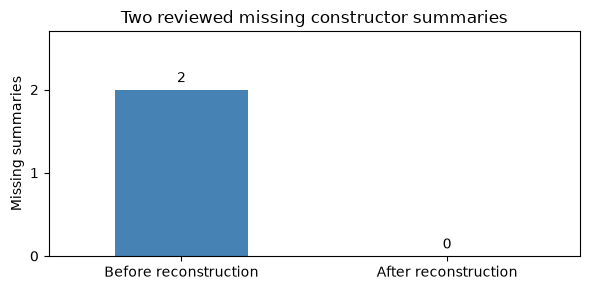

Passed: two supported summaries added, unique local row IDs, valid existing race/team IDs, original five columns, and all earlier rows preserved.


In [41]:
# Append only reviewed pairs that are not already present.
existing_pairs = pd.MultiIndex.from_frame(constructor_results_clean[["raceId", "constructorId"]])
new_pairs = pd.MultiIndex.from_frame(constructor_results_reconstructed[["raceId", "constructorId"]])
rows_to_add = constructor_results_reconstructed.loc[~new_pairs.isin(existing_pairs)]
constructor_results_clean = pd.concat([constructor_results_clean, rows_to_add], ignore_index=True)

constructor_missing_after = driver_race_constructor_pairs.merge(
    constructor_results_clean[["raceId", "constructorId"]],
    on=["raceId", "constructorId"], how="left", validate="one_to_one", indicator=True
)
constructor_missing_after = constructor_missing_after.loc[
    constructor_missing_after["_merge"].eq("left_only"), ["raceId", "constructorId"]
]
constructor_reconstruction_summary = pd.DataFrame({
    "Before reconstruction": [len(constructor_results_before_reconstruction), 5, 2, len(constructor_missing_pairs)],
    "After reconstruction": [len(constructor_results_clean), len(constructor_results_clean.columns),
        new_pairs.isin(pd.MultiIndex.from_frame(constructor_missing_after)).sum(), len(constructor_missing_after)]
}, index=["Rows", "Columns", "Reviewed summaries still missing", "All unmatched results pairs"])
display(constructor_reconstruction_summary)
display(constructor_results_clean["status"].value_counts().to_frame("Final rows"))

ax = constructor_reconstruction_summary.loc["Reviewed summaries still missing"].plot.bar(
    figsize=(6, 3), color=["steelblue", "darkorange"], rot=0
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set_title("Two reviewed missing constructor summaries")
ax.set_ylabel("Missing summaries")
ax.set_ylim(0, 2.7)
ax.set_yticks([0, 1, 2])
plt.tight_layout()
plt.show()

assert len(constructor_results_clean) == len(constructor_results_before_reconstruction) + 2
assert len(constructor_results_clean) == 12620
assert len(constructor_missing_after) == 408
assert constructor_results_clean.columns.equals(constructor_results.columns)
assert constructor_results_clean["constructorResultsId"].is_unique
assert not constructor_results_clean.duplicated(["raceId", "constructorId"]).any()
assert constructor_results_clean["raceId"].isin(races["raceId"]).all()
assert constructor_results_clean["constructorId"].isin(constructors["constructorId"]).all()
assert constructor_results_clean.notna().all().all()
assert pd.api.types.is_numeric_dtype(constructor_results_clean["points"])
assert constructor_results_clean["status"].value_counts().to_dict() == {"ND": 12603, "D": 17}
assert not new_pairs.isin(pd.MultiIndex.from_frame(constructor_missing_after)).any()
pd.testing.assert_frame_equal(
    constructor_results_clean.iloc[:len(constructor_results_before_reconstruction)].reset_index(drop=True),
    constructor_results_before_reconstruction.reset_index(drop=True)
)
pd.testing.assert_frame_equal(
    constructor_results_clean.merge(constructor_reconstruction_pairs, on=["raceId", "constructorId"], validate="one_to_one")
        .sort_values("constructorResultsId").reset_index(drop=True),
    constructor_results_reconstructed.sort_values("constructorResultsId").reset_index(drop=True)
)
pd.testing.assert_frame_equal(constructor_results, constructor_results_raw_snapshot)
print("Passed: two supported summaries added, unique local row IDs, valid existing race/team IDs, original five columns, and all earlier rows preserved.")


### Final findings for constructor_results

The original table has 12,625 rows. We label missing constructor-status flags `ND`, remove seven specifically verified redundant summaries, and reconstruct two verified missing summaries. The final clean table has **12,620 rows and the original 5 columns**: **12,603 ND** and **17 D**.

Both reconstructed rows have zero points. Their constructor IDs already exist; only their row IDs are generated locally. The audit tables preserve the removed rows, evidence links and reconstruction provenance. The remaining 408 unmatched driver-result pairs are documented above as historical or non-starting exceptions. We do not fabricate summaries for them. All original CSVs and raw tables are preserved.


## 3.3 drivers.csv 

### 3.3.1 Drivers: Initial Auditing & Core Cleaning
Establishing the baseline snapshot, replacing `\N` sentinels with true NaNs, standardizing fragmented nationality labels (e.g., merging "Argentinian " into "Argentine"), and safely casting birth dates (`dob`) into datetime formats.

### Before-cleaning inspection

Each row represents one driver. `driverId` is the primary key.


In [42]:
print("Rows:", len(drivers))
print("Columns:", len(drivers.columns))
display(drivers.head(10))
drivers.info()


Rows: 861
Columns: 9


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,\N,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
6,7,bourdais,\N,BOU,Sébastien,Bourdais,1979-02-28,French,http://en.wikipedia.org/wiki/S%C3%A9bastien_Bo...
7,8,raikkonen,7,RAI,Kimi,Räikkönen,1979-10-17,Finnish,http://en.wikipedia.org/wiki/Kimi_R%C3%A4ikk%C...
8,9,kubica,88,KUB,Robert,Kubica,1984-12-07,Polish,http://en.wikipedia.org/wiki/Robert_Kubica
9,10,glock,\N,GLO,Timo,Glock,1982-03-18,German,http://en.wikipedia.org/wiki/Timo_Glock


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


### Placeholder handling and before/after evidence


In [43]:
sentinels_before = drivers.eq(r"\N").sum()

display(
    sentinels_before.to_frame("Missing placeholders BEFORE")
)

,Missing placeholders BEFORE
driverId,0
driverRef,0
number,802
code,757
forename,0
surname,0
dob,0
nationality,0
url,0


In [44]:
drivers_raw_snapshot = drivers.copy(deep=True)
drivers_clean = drivers.copy(deep=True)
drivers_clean = drivers_clean.replace(r"\N", np.nan)


In [45]:
comparison = pd.DataFrame({
    "Placeholders BEFORE": drivers.eq(r"\N").sum(),
    "Placeholders AFTER": drivers_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": drivers.isna().sum(),
    "Recognized missing AFTER": drivers_clean.isna().sum()
})

display(comparison)

,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
driverId,0,0,0,0
driverRef,0,0,0,0
number,802,0,0,802
code,757,0,0,757
forename,0,0,0,0
surname,0,0,0,0
dob,0,0,0,0
nationality,0,0,0,0
url,0,0,0,0


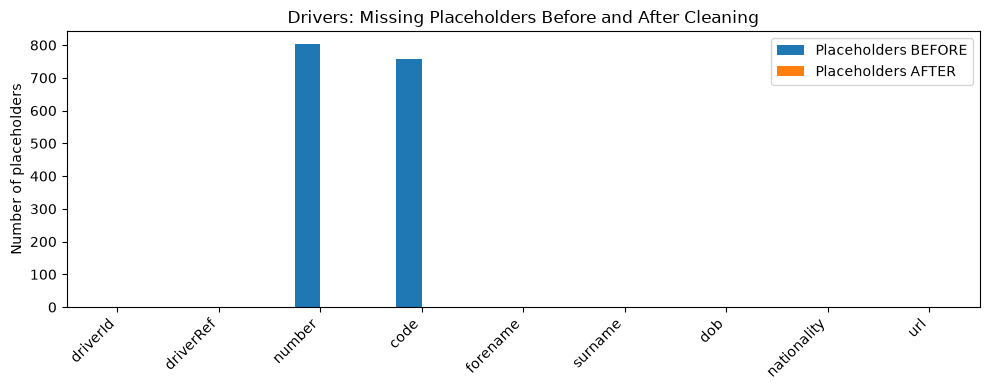

In [46]:
comparison[[
    "Placeholders BEFORE",
    "Placeholders AFTER"
]].plot.bar(figsize=(10, 4))

plt.title("Drivers: Missing Placeholders Before and After Cleaning")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The original data uses `\N` to represent missing information.
We counted these placeholders before cleaning, then replaced them with
recognized missing values in a copy. The comparison confirms that no `\N`
placeholders remain. Missing information was preserved, not guessed or filled.

### Nationality inspection and correction


In [47]:
# Show every nationality label and its count.
nationality_counts = (
    drivers_clean["nationality"]
    .value_counts(dropna=False)
    .rename_axis("Nationality")
    .reset_index(name="Number of drivers")
)

# Quotes make surrounding spaces visible.
nationality_counts["Nationality"] = (
    nationality_counts["Nationality"].map(repr)
)

with pd.option_context("display.max_rows", None):
    display(nationality_counts)

,Nationality,Number of drivers
0,'British',166
1,'American',158
2,'Italian',99
3,'French',73
4,'German',50
5,'Brazilian',32
6,'Argentine',24
7,'Belgian',23
8,'Swiss',23
9,'South African',23


In [48]:
nationality_before = drivers["nationality"].copy()

# Remove surrounding spaces.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].str.strip()
)

# Use one label for the same nationality.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].replace({
        "Argentinian": "Argentine"
    })
)

In [49]:
changed = (
    nationality_before.fillna("<MISSING>")
    != drivers_clean["nationality"].fillna("<MISSING>")
)

changes = drivers_clean.loc[
    changed, ["driverId", "forename", "surname"]
].copy()

# Quotes make the original trailing spaces visible.
changes["Nationality BEFORE"] = nationality_before.loc[changed].map(repr)
changes["Nationality AFTER"] = (
    drivers_clean.loc[changed, "nationality"].map(repr)
)

display(changes)
print("Rows changed:", changed.sum())

,driverId,forename,surname,Nationality BEFORE,Nationality AFTER
859,861,Franco,Colapinto,'Argentinian ','Argentine'


Rows changed: 1


,Before,After
'Argentine',24,25
'Argentinian',0,0
'Argentinian ',1,0


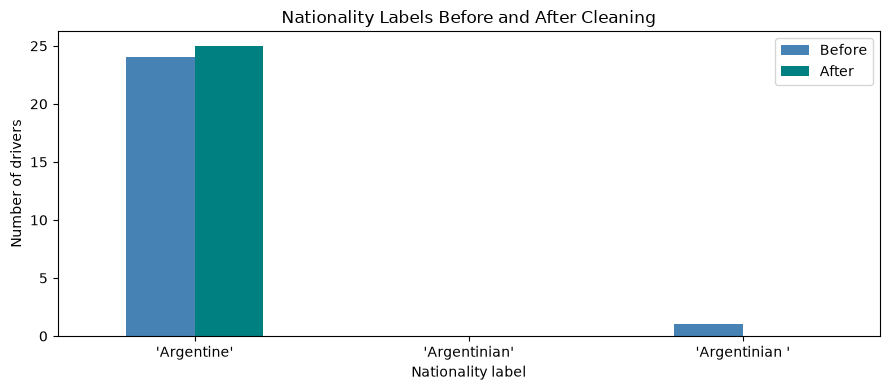

In [50]:
labels = ["Argentine", "Argentinian", "Argentinian "]

nationality_comparison = pd.DataFrame({
    "Before": nationality_before.value_counts().reindex(
        labels, fill_value=0
    ),
    "After": drivers_clean["nationality"].value_counts().reindex(
        labels, fill_value=0
    )
})

nationality_comparison.index = [repr(label) for label in labels]

display(nationality_comparison)

nationality_comparison.plot.bar(
    figsize=(9, 4),
    color=["steelblue", "teal"]
)

plt.title("Nationality Labels Before and After Cleaning")
plt.xlabel("Nationality label")
plt.ylabel("Number of drivers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Reason for nationality-label standardization

We followed the reference URLs stored in `drivers.url` and checked the explicit nationality fields, rather than inferring nationality from birthplace, team, or races entered.

| Driver record | Original `nationality` | Nationality identified by its reference |
|---|---|---|
| Franco Colapinto (`driverId = 861`) | `"Argentinian "` | Argentine |
| Gastón Mazzacane (`driverId = 60`) | `Argentine` | Argentine |

Sources supplied in the CSV: [Franco Colapinto](https://en.wikipedia.org/wiki/Franco_Colapinto) and [Gastón Mazzacane](https://en.wikipedia.org/wiki/Gast%C3%B3n_Mazzacane). Both pages identify the driver's Formula One nationality as Argentine.

Colapinto's own reference supports standardizing his label to the existing `Argentine` category. We also remove the trailing space. This prevents the same nationality being separated into two categories; the before/after counts demonstrate the effect, not the reason for the change. No driver records are merged or removed. `Argentine-Italian` remains separate because replacing it would discard information. No nationality ID or country code was inferred to exist in the original data.

Additional official corroboration, reviewed 11 October 2026: [F1’s Colapinto profile](https://www.formula1.com/en/drivers/franco-colapinto) identifies him as Argentine and explicitly connects him to fellow Argentine driver Gastón Mazzacane. This supports the existing correction without relying on similar spelling alone.


### Birth-date typing and before/after evidence


In [51]:
# Preserve values before this change.
dob_before = drivers["dob"].replace(r"\N", np.nan).copy()

converted_dob = pd.to_datetime(
    dob_before,
    format="%Y-%m-%d",
    errors="coerce"
)

# Find non-missing strings that could not be converted.
invalid_dates = dob_before.notna() & converted_dob.isna()

print("Invalid non-missing birth dates:", invalid_dates.sum())

if invalid_dates.any():
    display(
        drivers_clean.loc[
            invalid_dates,
            ["driverId", "forename", "surname", "dob"]
        ]
    )

assert not invalid_dates.any(), \
    "Investigate invalid birth dates before continuing."

drivers_clean["dob"] = converted_dob

Invalid non-missing birth dates: 0


In [52]:
display(pd.DataFrame({
    "BEFORE": dob_before.head(),
    "AFTER": drivers_clean["dob"].head()
}))

print("Type BEFORE:", dob_before.dtype)
print("Type AFTER:", drivers_clean["dob"].dtype)

print("Missing dates BEFORE:", dob_before.isna().sum())
print("Missing dates AFTER:", drivers_clean["dob"].isna().sum())

,BEFORE,AFTER
0,1985-01-07,1985-01-07
1,1977-05-10,1977-05-10
2,1985-06-27,1985-06-27
3,1981-07-29,1981-07-29
4,1981-10-19,1981-10-19


Type BEFORE: object
Type AFTER: datetime64[ns]
Missing dates BEFORE: 0
Missing dates AFTER: 0


Dates of birth were stored as text. We checked for invalid date strings
and converted valid values to datetime format. We compared missing counts
before and after to verify that conversion did not introduce new gaps.
This enables calculating each driver's age at a race once race dates are joined.

### Key and reference checks


In [53]:
print("Missing driver IDs:",
      drivers_clean["driverId"].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean["driverId"].duplicated().sum())

assert drivers_clean["driverId"].notna().all(), \
    "Missing driverId found"

assert drivers_clean["driverId"].is_unique, \
    "Duplicate driverId found"

print("Passed: driverId is unique and non-null.")

Missing driver IDs: 0
Duplicate driver IDs: 0
Passed: driverId is unique and non-null.


### 3.3.2 Drivers: Relational Integrity & Missing Identifiers
Verifying that every driver referenced across all external tables (results, standings, lap times, etc.) exists in our cleaned index. This phase also audits missing driver numbers and 3-letter codes by historical era, subsequently casting driver numbers to strict `Int64` integers.

In [54]:
reference_tables = {
    "results": results,
    "qualifying": qualifying,
    "driver_standings": driver_standings,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "sprint_results": sprint_results
}

checks = []

for name, table in reference_tables.items():
    missing = (
        table["driverId"].isna()
        | table["driverId"].eq(r"\N")
    )

    unknown = (
        ~missing
        & ~table["driverId"].isin(drivers_clean["driverId"])
    )

    checks.append({
        "Table": name,
        "Missing driver IDs": int(missing.sum()),
        "Unknown driver IDs": int(unknown.sum())
    })

    if (missing | unknown).any():
        print(f"Problem records in {name}:")
        display(table.loc[missing | unknown].head(20))

audit = pd.DataFrame(checks)
display(audit)

assert audit[["Missing driver IDs", "Unknown driver IDs"]].eq(0).all().all(), \
    "Some driver references need investigation"

print("Passed: all checked driver references exist in drivers_clean.")


,Table,Missing driver IDs,Unknown driver IDs
0,results,0,0
1,qualifying,0,0
2,driver_standings,0,0
3,lap_times,0,0
4,pit_stops,0,0
5,sprint_results,0,0


Passed: all checked driver references exist in drivers_clean.


In [55]:
final_checks = pd.Series({
    "Row count unchanged": len(drivers_clean) == len(drivers),
    "No remaining placeholders": not drivers_clean.eq(r"\N").any().any(),
    "Driver IDs non-null": drivers_clean["driverId"].notna().all(),
    "Driver IDs unique": drivers_clean["driverId"].is_unique,
    "No completely duplicated rows": not drivers_clean.duplicated().any(),
    "Birth dates have datetime type":
        pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Birth-date missing count unchanged":
        drivers_clean["dob"].isna().sum()
        == drivers["dob"].replace(r"\N", np.nan).isna().sum()
})

display(final_checks.to_frame("Passed"))
assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Driver IDs non-null,True
Driver IDs unique,True
No completely duplicated rows,True
Birth dates have datetime type,True
Birth-date missing count unchanged,True


### Additional audit — Understand missing numbers and codes

Each row is one driver, covering many historical eras. A missing value is not automatically a wrong record.

`number` is a driver-profile number, while `results.number` is the car number used in a particular race. [The FIA announced permanent driver numbers for 2014](https://www.fia.com/news/formula-one-regulation-changes), and [F1 explains the earlier team-based system](https://www.formula1.com/en/latest/article/from-childhood-number-plates-to-karting-titles-why-each-driver-picked-their.49DqOwhvza1RRvE2Rgi1so.49DqOwhvza1RRvE2Rgi1so). Therefore we cannot assign an old driver one permanent number by copying an arbitrary race number.

We join drivers to their first and last **recorded result years**. This is an audit of the dataset, not a claim that every result row is a race start. The table below tests whether the missing values belong to older drivers or drivers recorded from 2014 onwards.

`code` is an abbreviation, not the driver's identity key. Historical coverage is incomplete in this dataset. We do not assume an introduction year for codes or construct abbreviations from names. A missing code remains an explicitly documented source gap. Codes are not needed to link tables: `driverId` does that.


,Drivers,Missing_number,Missing_code
Recorded era,,,
Has results in 2014 or later,59,0,0
Last result before 2014,802,802,757


,driverId,forename,surname,number,code,first_recorded_year,last_recorded_year
1,2,Nick,Heidfeld,NaN,HEI,2000,2011
4,5,Heikki,Kovalainen,NaN,KOV,2007,2013
5,6,Kazuki,Nakajima,NaN,NAK,2007,2009
6,7,Sébastien,Bourdais,NaN,BOU,2008,2009
9,10,Timo,Glock,NaN,GLO,2004,2012


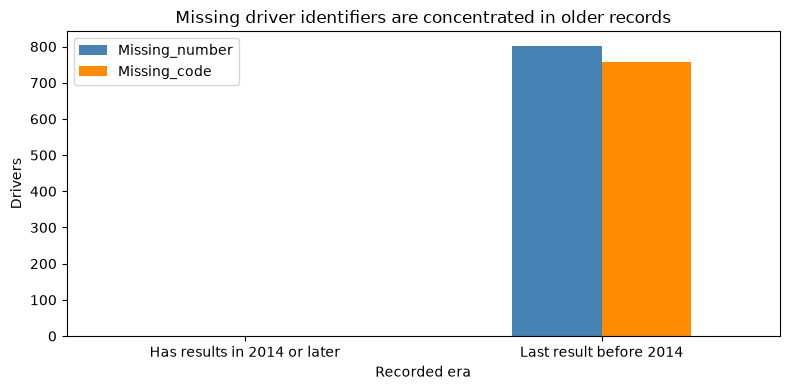

In [56]:
driver_recorded_years = (
    results[["driverId", "raceId"]]
    .merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
    .groupby("driverId")["year"].agg(first_recorded_year="min", last_recorded_year="max")
)
driver_history_audit = drivers_clean.merge(
    driver_recorded_years, on="driverId", how="left", validate="one_to_one"
)
assert driver_history_audit["last_recorded_year"].notna().all()
driver_history_audit["Recorded era"] = np.where(
    driver_history_audit["last_recorded_year"].ge(2014),
    "Has results in 2014 or later", "Last result before 2014"
)
driver_missing_by_era = driver_history_audit.groupby("Recorded era").agg(
    Drivers=("driverId", "size"),
    Missing_number=("number", lambda values: values.isna().sum()),
    Missing_code=("code", lambda values: values.isna().sum())
)
display(driver_missing_by_era)
display(driver_history_audit.loc[
    driver_history_audit["number"].isna() | driver_history_audit["code"].isna(),
    ["driverId", "forename", "surname", "number", "code", "first_recorded_year", "last_recorded_year"]
].head(5))
driver_missing_by_era[["Missing_number", "Missing_code"]].plot.bar(
    figsize=(8, 4), color=["steelblue", "darkorange"], rot=0
)
plt.title("Missing driver identifiers are concentrated in older records")
plt.ylabel("Drivers")
plt.tight_layout()
plt.show()


### Missing-value decision and number typing

| Column | Finding | Treatment and reason |
|---|---|---|
| `number` | 802 missing (93.15%); all belong to drivers with their last recorded result before 2014 | Keep a genuine missing value. Convert known numbers to nullable integer `Int64`. A median, 0 or a generated number would not identify the driver's actual number. |
| `code` | 757 missing (87.92%); all belong to drivers with their last recorded result before 2014 | Keep the original known codes and recognized missing values. Treat missing codes as historical source gaps. Do not invent official abbreviations. |
| Other columns | No missing values | Check types, text quality and joins below; no filling required. |

**These gaps have a documented treatment:** retain them in this reference table and use `driverId` for joins. `number` and `code` should not be used as numerical measurements or podium predictors merely because a model accepts them. If a later display needs a label, names and `driverId` are available. Missing historical profile data does not require dropping the driver. Filling is useful only when the replacement has a defensible meaning.

The before/after graph below shows that recognizing missing values and typing numbers does not create or fabricate information.


,Before,After
0,44,44
1,NaN,<NA>
2,6,6
3,14,14
4,NaN,<NA>


Number type before: object
Number type after: Int64


,Before (including placeholders),After (recognized missing),After missing (%)
driverId,0,0,0.00
driverRef,0,0,0.00
number,802,802,93.15
code,757,757,87.92
forename,0,0,0.00
surname,0,0,0.00
dob,0,0,0.00
nationality,0,0,0.00
url,0,0,0.00


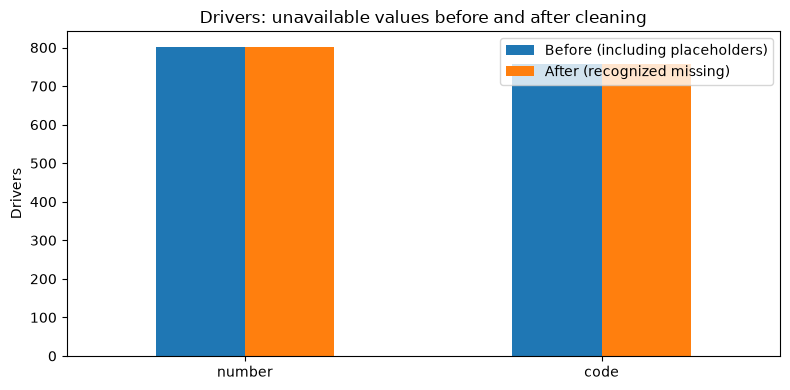

In [57]:
driver_number_before = drivers_clean["number"].copy()
driver_number_numeric = pd.to_numeric(driver_number_before, errors="coerce")
invalid_driver_numbers = driver_number_before.notna() & (
    driver_number_numeric.isna() | driver_number_numeric.mod(1).ne(0)
)
assert not invalid_driver_numbers.any(), "Investigate non-integer driver numbers."
drivers_clean["number"] = driver_number_numeric.astype("Int64")
assert drivers_clean["number"].dropna().between(1, 99).all()
display(pd.DataFrame({
    "Before": driver_number_before.head(), "After": drivers_clean["number"].head()
}))
print("Number type before:", driver_number_before.dtype)
print("Number type after:", drivers_clean["number"].dtype)

driver_missing_comparison = pd.DataFrame({
    "Before (including placeholders)": drivers.replace(r"\N", np.nan).isna().sum(),
    "After (recognized missing)": drivers_clean.isna().sum()
})
driver_missing_comparison["After missing (%)"] = drivers_clean.isna().mean().mul(100).round(2)
display(driver_missing_comparison)
driver_missing_comparison.loc[["number", "code"], [
    "Before (including placeholders)", "After (recognized missing)"
]].plot.bar(figsize=(8, 4), rot=0)
plt.title("Drivers: unavailable values before and after cleaning")
plt.ylabel("Drivers")
plt.tight_layout()
plt.show()


### Identity and text-quality checks

We check missing identifiers, full duplicate rows, duplicate `driverId`, `driverRef`, URLs and exact full names. We inspect blank text, surrounding whitespace, three-uppercase-letter code format and URL structure. These are format checks; they do not prove that every biography or URL is historically correct or accessible.

**Only `driverId` is our join key.** Codes and car numbers can repeat across different drivers and eras. Shared surnames, birthdays or nationalities also do not establish that two drivers are the same person. The repeated-code table makes this visible; we preserve these distinct drivers.


### 3.3.3 Drivers: Identity Validation & Age Auditing
Enforcing strict structural rules on text fields (URL formatting, unique `driverRef`, and 3-letter uppercase codes). Includes a cross-table temporal sanity check mapping birth dates to race dates to flag impossible ages, finishing with definitive assertion tests for the `drivers_clean` table.

In [58]:
driver_text_checks = []
for column in ["driverRef", "code", "forename", "surname", "nationality", "url"]:
    before = drivers[column].replace(r"\N", np.nan).astype("string")
    after = drivers_clean[column].astype("string")
    driver_text_checks.append({
        "Column": column,
        "Blank text before": int(before.str.strip().eq("").sum()),
        "Blank text after": int(after.str.strip().eq("").sum()),
        "Outer whitespace before": int(before.ne(before.str.strip()).sum()),
        "Outer whitespace after": int(after.ne(after.str.strip()).sum())
    })
driver_text_checks = pd.DataFrame(driver_text_checks)
display(driver_text_checks)
assert driver_text_checks[["Blank text after", "Outer whitespace after"]].eq(0).all().all()

driver_identity_checks = pd.Series({
    "No duplicate full rows": not drivers_clean.duplicated().any(),
    "IDs are positive integers": pd.api.types.is_integer_dtype(drivers_clean["driverId"]) and drivers_clean["driverId"].gt(0).all(),
    "driverRef complete and unique": drivers_clean["driverRef"].notna().all() and drivers_clean["driverRef"].is_unique,
    "URLs complete and unique": drivers_clean["url"].notna().all() and drivers_clean["url"].is_unique,
    "URLs have HTTP(S) structure": drivers_clean["url"].str.match(r"^https?://[^/\s]+/\S+$").all(),
    "No repeated exact full names": not drivers_clean.duplicated(["forename", "surname"]).any(),
    "Known codes are three uppercase letters": drivers_clean["code"].dropna().str.fullmatch(r"[A-Z]{3}").all()
})
display(driver_identity_checks.to_frame("Passed"))
assert driver_identity_checks.all()
print("Repeated codes, shown for inspection rather than deletion:")
display(drivers_clean.loc[
    drivers_clean["code"].notna() & drivers_clean["code"].duplicated(keep=False),
    ["driverId", "forename", "surname", "code"]
].sort_values(["code", "driverId"]))


,Column,Blank text before,Blank text after,Outer whitespace before,Outer whitespace after
0,driverRef,0,0,0,0
1,code,0,0,0,0
2,forename,0,0,0,0
3,surname,0,0,0,0
4,nationality,0,0,1,0
5,url,0,0,0,0


,Passed
No duplicate full rows,True
IDs are positive integers,True
driverRef complete and unique,True
URLs complete and unique,True
URLs have HTTP(S) structure,True
No repeated exact full names,True
Known codes are three uppercase letters,True


Repeated codes, shown for inspection rather than deletion:


,driverId,forename,surname,code
26,27,Christijan,Albers,ALB
846,848,Alexander,Albon,ALB
375,376,Lucien,Bianchi,BIA
823,824,Jules,Bianchi,BIA
37,38,Robert,Doornbos,DOO
860,862,Jack,Doohan,DOO
836,837,Rio,Haryanto,HAR
841,843,Brendon,Hartley,HAR
75,76,Jan,Magnussen,MAG
824,825,Kevin,Magnussen,MAG


### Birth dates and consistency with race records

Parsing dates is only the first check. We also check that each recorded event occurs after the driver's birth, across all six tables referencing drivers. We show the youngest and oldest ages in `results` for inspection. Ages use days divided by 365.2425, so they are approximate.

We do not impose today's minimum-age rules on historical records. [F1 confirms Verstappen debuted at 17](https://www.formula1.com/en/latest/article/verstappen-to-race-for-toro-rosso-in-2015.6BjluokWZBUnoCCCAHYg87). The oldest result entry below is Louis Chiron in Monaco 1958: its `positionText` and status show a failed qualification, so it must not be described as a race start. This check confirms chronological consistency, not every driver's exact biography.

We also compare known profile numbers with race-specific numbers. A number differing in an older race is not automatically an error: race numbers changed over time. We show Hamilton's earlier number as an example, and check that every known profile number occurs in at least one of that driver's recorded results.


In [59]:
driver_event_pairs = pd.concat([
    table[["driverId", "raceId"]] for table in reference_tables.values()
], ignore_index=True).drop_duplicates()
driver_date_audit = driver_event_pairs.merge(
    races[["raceId", "date"]], on="raceId", how="left", validate="many_to_one"
).merge(drivers_clean[["driverId", "dob"]], on="driverId", how="left", validate="many_to_one")
driver_date_audit["date"] = pd.to_datetime(driver_date_audit["date"], format="%Y-%m-%d", errors="raise")
assert driver_date_audit[["date", "dob"]].notna().all().all()
assert driver_date_audit["date"].ge(driver_date_audit["dob"]).all()
print("Driver–event pairs checked across all six tables:", len(driver_date_audit))

driver_age_audit = results[["driverId", "raceId", "positionText", "statusId"]].merge(
    driver_date_audit, on=["driverId", "raceId"], validate="many_to_one"
).merge(drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
driver_age_audit["Approximate age"] = (driver_age_audit["date"] - driver_age_audit["dob"]).dt.days / 365.2425
driver_age_extremes = driver_age_audit.loc[
    [driver_age_audit["Approximate age"].idxmin(), driver_age_audit["Approximate age"].idxmax()]
].merge(status, on="statusId", validate="many_to_one")
display(driver_age_extremes[["driverId", "forename", "surname", "raceId", "dob", "date", "Approximate age", "positionText", "status"]])

driver_number_audit = drivers_clean.loc[drivers_clean["number"].notna(), ["driverId", "number"]].merge(
    results[["driverId", "raceId", "number"]], on="driverId", suffixes=("_profile", "_race"), validate="one_to_many"
)
driver_number_audit["number_race"] = pd.to_numeric(driver_number_audit["number_race"], errors="coerce")
driver_number_audit["Matches profile"] = driver_number_audit["number_profile"].eq(driver_number_audit["number_race"])
assert driver_number_audit.groupby("driverId")["Matches profile"].any().all()
print("Example of an earlier race number differing from the profile number:")
display(driver_number_audit.loc[
    driver_number_audit["driverId"].eq(1) & ~driver_number_audit["Matches profile"]
].head(3))


Driver–event pairs checked across all six tables: 35332


,driverId,forename,surname,raceId,dob,date,Approximate age,positionText,status
0,830,Max,Verstappen,926,1997-09-30,2015-03-15,17.454157,R,Engine
1,589,Louis,Chiron,766,1899-08-03,1958-05-18,58.788339,F,Did not qualify


Example of an earlier race number differing from the profile number:


,driverId,number_profile,raceId,number_race,Matches profile
0,1,44,18,22,False
1,1,44,19,22,False
2,1,44,20,22,False


### Final before/after verification

The expected clean table below is rebuilt independently from the raw data using only the documented changes: recognize `\N`, standardize the reviewed nationality label, parse dates and type known numbers as nullable integers. Exact table comparison checks that no other value, row or column changed. Raw-table equality is checked separately.


In [60]:
drivers_expected = drivers.replace(r"\N", np.nan).copy(deep=True)
drivers_expected["nationality"] = drivers_expected["nationality"].str.strip().replace({"Argentinian": "Argentine"})
drivers_expected["dob"] = pd.to_datetime(drivers_expected["dob"], format="%Y-%m-%d", errors="raise")
drivers_expected["number"] = pd.to_numeric(drivers_expected["number"], errors="raise").astype("Int64")
pd.testing.assert_frame_equal(drivers_clean, drivers_expected)
pd.testing.assert_frame_equal(drivers, drivers_raw_snapshot)
assert drivers_clean.columns.equals(drivers.columns)
assert len(drivers_clean) == len(drivers) == 861
assert drivers_clean.isna().sum().to_dict() == {
    "driverId": 0, "driverRef": 0, "number": 802, "code": 757,
    "forename": 0, "surname": 0, "dob": 0, "nationality": 0, "url": 0
}
print("Passed: 861 drivers, original 9 columns, all six driver-reference checks, documented missing-value treatment, and only the specified cleaning changes.")


Passed: 861 drivers, original 9 columns, all six driver-reference checks, documented missing-value treatment, and only the specified cleaning changes.


### Drivers — Findings and limits

We retain **861 drivers and the original 9 columns**. The supported changes are `\N` → recognized missing values, one Colapinto nationality label → `Argentine` (including trimming its trailing space), `dob` → datetime, and known `number` values → nullable integers. No drivers are removed or merged.

The 802 missing numbers are historical profile gaps consistent with the pre-2014 numbering system. The 757 missing codes are documented source gaps; their individual original values have not been recovered. Neither field is needed for table joins, and we do not fabricate replacements. All other fields are complete.

The audit found no duplicate IDs, references, URLs or exact full names, no remaining blank text or outer whitespace, no invalid date strings or number/code formats, no unknown driver IDs across six related tables, and no event dated before birth. All drivers appear in `results`. Repeated codes/numbers are preserved because they are not identity keys. Historical and dual-nationality labels remain unchanged without specific contradictory evidence.

These checks establish internal consistency and explain the observed gaps. They do not claim that all 861 biographies, nationality histories or source URLs were independently verified on the internet. All raw data stays unchanged.


In [61]:
drivers_clean.info()
assert drivers_clean.columns.equals(drivers.columns), "Unexpected added or removed driver columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   driverId     861 non-null    int64         
 1   driverRef    861 non-null    object        
 2   number       59 non-null     Int64         
 3   code         104 non-null    object        
 4   forename     861 non-null    object        
 5   surname      861 non-null    object        
 6   dob          861 non-null    datetime64[ns]
 7   nationality  861 non-null    object        
 8   url          861 non-null    object        
dtypes: Int64(1), datetime64[ns](1), int64(1), object(6)
memory usage: 61.5+ KB


### Driver combinations — Audit across related tables

This section investigates **raw source records** before later table-specific cleaning. It creates separate audit tables, without changing any raw or cleaned data. It does not assume that a repeated driver–race pair is automatically a duplicate error.

| Table | Row meaning | Combination to investigate |
|---|---|---|
| results | Driver result/entry; historical car changes can produce several records | `(raceId, driverId)`; inspect repeated pairs and car numbers |
| qualifying | One qualifying record per driver and race | `(raceId, driverId)` |
| driver_standings | Driver's cumulative championship standing after a round | `(raceId, driverId)`; participation in that particular race is not required |
| lap_times | One recorded lap | `(raceId, driverId, lap)` |
| pit_stops | One numbered stop | `(raceId, driverId, stop)` |
| sprint_results | One sprint result per driver and event | `(raceId, driverId)` |

Repeated race–driver pairs in lap times or pit stops are expected: a driver can have many laps and stops. Their full combinations must be checked instead. Single-column record IDs, where supplied, are checked separately. Race–driver membership uses a deduplicated **lookup** from `results`; this does not delete result rows.


### 3.3.4 Drivers: Cross-Table Combinations & Constructor Conflicts
A deep-dive audit into multi-table driver combinations. This verifies repeated race-driver groupings, validates point continuations for drivers absent from specific rounds, and isolates specific constructor discrepancies (e.g., Marussia vs. Manor) between Qualifying and Race results.

In [62]:
driver_combination_keys = {
    "results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["raceId", "driverId"]
}
driver_combination_tables = {"results": results, **reference_tables}
driver_combination_snapshots = {name: table.copy(deep=True) for name, table in driver_combination_tables.items()}
drivers_clean_combination_snapshot = drivers_clean.copy(deep=True)
driver_result_pair_lookup = results[["raceId", "driverId"]].drop_duplicates()
driver_combination_duplicates = {}
driver_pairs_without_results = {}
driver_combination_rows = []

for name, key in driver_combination_keys.items():
    table = driver_combination_tables[name]
    missing_key = table[key].isna() | table[key].eq(r"\N")
    duplicated_rows = table.loc[table.duplicated(key, keep=False)].copy()
    driver_combination_duplicates[name] = duplicated_rows
    pair_check = table[["raceId", "driverId"]].drop_duplicates().merge(
        driver_result_pair_lookup, on=["raceId", "driverId"], how="left",
        validate="one_to_one", indicator=True
    )
    unmatched = pair_check.loc[pair_check["_merge"].eq("left_only"), ["raceId", "driverId"]]
    driver_pairs_without_results[name] = unmatched
    driver_combination_rows.append({
        "Table": name, "Rows": len(table), "Checked combination": " + ".join(key),
        "Rows missing key values": int(missing_key.any(axis=1).sum()),
        "Unknown driver IDs": int((~table["driverId"].isin(drivers_clean["driverId"])).sum()),
        "Unknown race IDs": int((~table["raceId"].isin(races["raceId"])).sum()),
        "Full duplicate rows": int(table.duplicated().sum()),
        "Rows in repeated combinations": len(duplicated_rows),
        "Repeated combination groups": len(duplicated_rows[key].drop_duplicates()),
        "Race-driver pairs absent from results": len(unmatched)
    })

driver_combination_summary = pd.DataFrame(driver_combination_rows).set_index("Table")
with pd.option_context("display.max_columns", None, "display.max_colwidth", None):
    display(driver_combination_summary)
assert driver_combination_summary[["Rows missing key values", "Unknown driver IDs", "Unknown race IDs", "Full duplicate rows"]].eq(0).all().all()
assert driver_combination_summary.drop(index="results")["Repeated combination groups"].eq(0).all()
assert driver_combination_summary.drop(index="driver_standings")["Race-driver pairs absent from results"].eq(0).all()

driver_record_id_checks = []
for name, column in {"results": "resultId", "qualifying": "qualifyId",
                     "driver_standings": "driverStandingsId", "sprint_results": "resultId"}.items():
    values = driver_combination_tables[name][column]
    driver_record_id_checks.append({"Table": name, "Record ID": column,
        "Missing IDs": int((values.isna() | values.eq(r"\N")).sum()),
        "Repeated IDs": int(values.duplicated().sum())})
driver_record_id_checks = pd.DataFrame(driver_record_id_checks)
display(driver_record_id_checks)
assert driver_record_id_checks[["Missing IDs", "Repeated IDs"]].eq(0).all().all()


,Rows,Checked combination,Rows missing key values,Unknown driver IDs,Unknown race IDs,Full duplicate rows,Rows in repeated combinations,Repeated combination groups,Race-driver pairs absent from results
Table,,,,,,,,,
results,26759,raceId + driverId,0,0,0,0,176,85,0
qualifying,10494,raceId + driverId,0,0,0,0,0,0,0
driver_standings,34863,raceId + driverId,0,0,0,0,0,0,8664
lap_times,589081,raceId + driverId + lap,0,0,0,0,0,0,0
pit_stops,11371,raceId + driverId + stop,0,0,0,0,0,0,0
sprint_results,360,raceId + driverId,0,0,0,0,0,0,0


,Table,Record ID,Missing IDs,Repeated IDs
0,results,resultId,0,0
1,qualifying,qualifyId,0,0
2,driver_standings,driverStandingsId,0,0
3,sprint_results,resultId,0,0


### Repeated result pairs — Show the evidence before choosing a rule

There are **85 repeated race–driver groups involving 176 rows**, all from 1950–1978. There are no fully identical result rows. Every repeated group has different car numbers, and adding `number` to the combination distinguishes all source records. This identifies different entries; it does not independently verify every historical record.

The full group summary is shown below and the actual rows remain available in `driver_repeated_result_details`. No result is deleted here.

**Verified example:** in Britain 1957, Stirling Moss has records for cars 18 and 20. [The official race classification](https://www.formula1.com/en/results/1957/races/154/great-britain/race-result) lists his original entry and the winning shared car with Tony Brooks. [F1's Brooks history](https://www.formula1.com/en/latest/article/legendary-1950s-f1-racer-tony-brooks-passes-away-aged-90.2qu9c1Z2v0idxldQyUyfq9) confirms their shared victory. These two records are meaningful history, not two copies of one row.

This example proves that automatic deletion is unsafe; it does not prove that all 85 cases are shared drives. The existing later `results_clean` selection rule is a separate reduction to one driver–race row and still requires review when we reach `results`. It is not validated by this audit.


Rows  \
year raceId name                     driverId forename     surname                
1950 835    Indianapolis 500         529      Tony         Bettenhausen       2   
     838    French Grand Prix        627      Louis        Rosier             2   
     839    Italian Grand Prix       579      Juan         Fangio             2   
                                     647      Alberto      Ascari             2   
1951 828    French Grand Prix        579      Juan         Fangio             2   
                                     647      Alberto      Ascari             2   
                                     786      Luigi        Fagioli            2   
     831    Italian Grand Prix       642      Nino         Farina             2   
1952 817    Swiss Grand Prix         642      Nino         Farina             2   
     820    French Grand Prix        501      Harry        Schell             2   
     823    Dutch Grand Prix         759      Jan          Flinterman         2   
1953 809    Indianapolis 500         509      Jim          Rathmann           2   
                                     512      Johnny       Thomson            2   
                                     518      Duane        Carter             2   
                                     520      Gene         Hartley            2   
                                     521      Chuck        Stevenson          3   
                                     555      Paul         Russo              2   
                                     612      Andy         Linden             3   
                                     702      Bob          Scott              2   
     810    Dutch Grand Prix         498      José Froilán González           2   
     811    Belgian Grand Prix       579      Juan         Fangio             2   
     814    German Grand Prix        633      Luigi        Villoresi          2   
                                     647      Alberto      Ascari             2   
     815    Swiss Grand Prix         579      Juan         Fangio             2   
                                     697      Felice       Bonetto            2   
1954 800    Indianapolis 500         509      Jim          Rathmann           2   
                                     518      Duane        Carter             2   
                                     529      Tony         Bettenhausen       2   
                                     556      Jimmy        Daywalt            2   
                                     593      Johnnie      Parsons            2   
                                     611      Sam          Hanks              2   
                                     612      Andy         Linden             3   
                                     613      Marshall     Teague             2   
                                     653      Jimmy        Davies             2   
                                     659      Jerry        Hoyt               2   
                                     702      Bob          Scott              2   
                                     730      George       Fonder             2   
     801    Belgian Grand Prix       498      José Froilán González           2   
     803    British Grand Prix       647      Alberto      Ascari             2   
     804    German Grand Prix        578      Mike         Hawthorn           2   
     806    Italian Grand Prix       498      José Froilán González           2   
1955 792    Argentine Grand Prix     427      Maurice      Trintignant        3   
                                     475      Stirling     Moss               2   
                                     496      Carlos       Menditeguy         2   
                                     501      Harry        Schell             3   
                                     554      Jean         Behra              3   
                                     577      Luigi        Musso              2   
        

Actual result rows for the verified Moss example:


,resultId,raceId,year,name,driverId,forename,surname,constructorId,number,positionOrder,points,laps,status
19,18817,780,1957,British Grand Prix,475,Stirling,Moss,118,18,12,0.0,51,Engine
167,20291,780,1957,British Grand Prix,475,Stirling,Moss,118,20,1,5.0,90,Finished


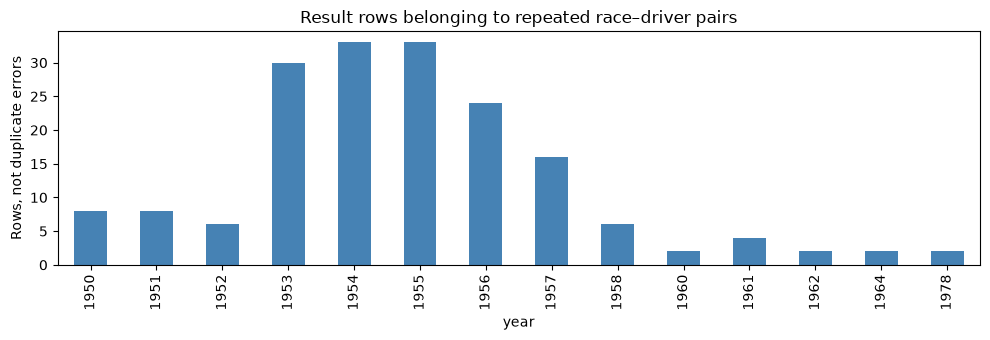

In [63]:
driver_repeated_result_details = driver_combination_duplicates["results"].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one").merge(
    constructors[["constructorId", "name"]].rename(columns={"name": "Constructor"}),
    on="constructorId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
driver_repeated_result_groups = driver_repeated_result_details.groupby(
    ["year", "raceId", "name", "driverId", "forename", "surname"]
).agg(Rows=("resultId", "size"), Car_numbers=("number", lambda values: ", ".join(values.astype(str))),
      Constructors=("Constructor", lambda values: "; ".join(sorted(set(values)))))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(driver_repeated_result_groups)
print("Actual result rows for the verified Moss example:")
display(driver_repeated_result_details.loc[
    driver_repeated_result_details["raceId"].eq(780) & driver_repeated_result_details["driverId"].eq(475),
    ["resultId", "raceId", "year", "name", "driverId", "forename", "surname", "constructorId", "number", "positionOrder", "points", "laps", "status"]
])
assert len(driver_repeated_result_groups) == 85
assert len(driver_repeated_result_details) == 176
assert not results.duplicated(["raceId", "driverId", "number"]).any()
driver_repeated_result_details.groupby("year").size().plot.bar(figsize=(10, 3.5), color="steelblue")
plt.title("Result rows belonging to repeated race–driver pairs")
plt.ylabel("Rows, not duplicate errors")
plt.tight_layout()
plt.show()


### Standings without a same-race result — Test the explanation

`driver_standings` describes the championship **after a round**, rather than who entered that race. A driver's accumulated points and wins can remain in the standings when the driver is absent.

We test this explanation for **all 8,664 unmatched pairs**: each driver already has a result in the same season at an earlier round, and every unmatched snapshot has exactly the same points and wins as that driver's preceding standings snapshot. The joined audit below shows examples and aggregate counts; all cases are retained in `driver_standings_nonparticipant_audit`.

For an external example, [Toyota's official 2008 championship archive](https://toyotagazooracing.com/archive/ms/en/season/ranking/2008/) records Super Aguri withdrawing after round four. [F1's final driver standings](https://www.formula1.com/en/results/2008/drivers) still include Sato and Davidson. Their absence from later race results therefore does not require deleting their standings rows. This supports the interpretation; matching points alone is not independent verification of every historical standing.


In [64]:
driver_standings_timeline = driver_standings.merge(
    races[["raceId", "year", "round", "name"]], on="raceId", validate="many_to_one"
).sort_values(["year", "driverId", "round"])
for column in ["points", "wins"]:
    driver_standings_timeline["Previous " + column] = driver_standings_timeline.groupby(["year", "driverId"])[column].shift()
driver_first_season_result = results[["raceId", "driverId"]].drop_duplicates().merge(
    races[["raceId", "year", "round"]], on="raceId", validate="many_to_one"
).groupby(["year", "driverId"])["round"].min().rename("First result round").reset_index()
driver_standings_nonparticipant_audit = driver_standings_timeline.merge(
    driver_pairs_without_results["driver_standings"], on=["raceId", "driverId"], validate="one_to_one"
).merge(driver_first_season_result, on=["year", "driverId"], how="left", validate="many_to_one").merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
)
driver_standings_nonparticipant_audit["Earlier result this season"] = (
    driver_standings_nonparticipant_audit["First result round"].lt(driver_standings_nonparticipant_audit["round"])
)
driver_standings_nonparticipant_audit["Points unchanged"] = driver_standings_nonparticipant_audit["points"].eq(driver_standings_nonparticipant_audit["Previous points"])
driver_standings_nonparticipant_audit["Wins unchanged"] = driver_standings_nonparticipant_audit["wins"].eq(driver_standings_nonparticipant_audit["Previous wins"])
display(driver_standings_nonparticipant_audit[["Earlier result this season", "Points unchanged", "Wins unchanged"]].sum().to_frame("Supported pairs"))
display(driver_standings_nonparticipant_audit.loc[
    driver_standings_nonparticipant_audit["year"].eq(2008) & driver_standings_nonparticipant_audit["driverId"].isin([11, 19]),
    ["raceId", "name", "year", "round", "driverId", "forename", "surname", "points", "Previous points", "wins", "Previous wins", "First result round"]
].head(6))
assert len(driver_standings_nonparticipant_audit) == 8664
assert driver_standings_nonparticipant_audit[["Earlier result this season", "Points unchanged", "Wins unchanged"]].all().all()


,Supported pairs
Earlier result this season,8664
Points unchanged,8664
Wins unchanged,8664


,raceId,name,year,round,driverId,forename,surname,points,Previous points,wins,Previous wins,First result round
8291,22,Turkish Grand Prix,2008,5,11,Takuma,Sato,0.0,0.0,0,0.0,1
8292,23,Monaco Grand Prix,2008,6,11,Takuma,Sato,0.0,0.0,0,0.0,1
8293,24,Canadian Grand Prix,2008,7,11,Takuma,Sato,0.0,0.0,0,0.0,1
8294,25,French Grand Prix,2008,8,11,Takuma,Sato,0.0,0.0,0,0.0,1
8295,26,British Grand Prix,2008,9,11,Takuma,Sato,0.0,0.0,0,0.0,1
8296,27,German Grand Prix,2008,10,11,Takuma,Sato,0.0,0.0,0,0.0,1


### Check the constructor attached to the same driver and race

Valid race and driver IDs can still be combined with inconsistent constructor IDs. For `qualifying` and `sprint_results`, we compare `(raceId, driverId, constructorId)` with the triples in `results`. This comparison is not appropriate for lap/pit records, which have no constructor column, or standings, which may cover absent drivers.

Sprint triples all match. **Ten qualifying records across five 2015 races use `206` (Marussia) where the driver's race result uses `209` (Manor Marussia).** The full joined table below shows both record IDs, drivers, events and constructor names.

The earlier constructor-results investigation already found this naming connection. [F1's 2015 Rossi announcement](https://www.formula1.com/en/latest/article/marussia-hand-rossi-race-debut-in-singapore.6UMXTLJHDEu5LuWC4R0Djd) uses Marussia while identifying the team as Manor Marussia, and [the FIA's 2015 classification](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/2015-classifications) lists one Manor Marussia entry. This supports investigating an ID inconsistency, rather than inferring a team change from the numbers alone.

**No correction is applied here.** These ten cases are saved for the qualifying review, where the official session records can be checked before changing those specific rows. The IDs are not globally merged.


In [65]:
driver_constructor_pair_summary = []
driver_constructor_pair_conflicts = {}
result_triples = results[["raceId", "driverId", "constructorId"]].drop_duplicates()
for name in ["qualifying", "sprint_results"]:
    table = driver_combination_tables[name]
    checked = table.merge(result_triples, on=["raceId", "driverId", "constructorId"],
        how="left", validate="many_to_one", indicator=True)
    conflicts = checked.loc[checked["_merge"].eq("left_only")].drop(columns="_merge")
    driver_constructor_pair_conflicts[name] = conflicts
    driver_constructor_pair_summary.append({"Table": name, "Records": len(table),
        "Constructor triples absent from results": len(conflicts)})
display(pd.DataFrame(driver_constructor_pair_summary))
conflicting_qualifying_race_results = results.merge(
    driver_constructor_pair_conflicts["qualifying"][["raceId", "driverId"]],
    on=["raceId", "driverId"], validate="many_to_one"
)
driver_qualifying_constructor_conflicts = driver_constructor_pair_conflicts["qualifying"][
    ["qualifyId", "raceId", "driverId", "constructorId"]
].rename(columns={"constructorId": "Qualifying constructorId"}).merge(
    conflicting_qualifying_race_results[["resultId", "raceId", "driverId", "constructorId"]].rename(columns={"constructorId": "Race constructorId"}),
    on=["raceId", "driverId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
)
for kind in ["Qualifying", "Race"]:
    driver_qualifying_constructor_conflicts = driver_qualifying_constructor_conflicts.merge(
        constructors[["constructorId", "name"]].rename(columns={
            "constructorId": kind + " constructorId", "name": kind + " constructor"}),
        on=kind + " constructorId", validate="many_to_one"
    )
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(driver_qualifying_constructor_conflicts)
assert len(driver_qualifying_constructor_conflicts) == 10
assert driver_qualifying_constructor_conflicts["Qualifying constructorId"].eq(206).all()
assert driver_qualifying_constructor_conflicts["Race constructorId"].eq(209).all()
assert driver_constructor_pair_conflicts["sprint_results"].empty


,Table,Records,Constructor triples absent from results
0,qualifying,10494,10
1,sprint_results,360,0


,qualifyId,raceId,driverId,Qualifying constructorId,resultId,Race constructorId,year,name,forename,surname,Qualifying constructor,Race constructor
0,6522,937,829,206,22751,209,2015,Belgian Grand Prix,Will,Stevens,Marussia,Manor Marussia
1,6523,937,833,206,22750,209,2015,Belgian Grand Prix,Roberto,Merhi,Marussia,Manor Marussia
2,6601,941,829,206,22829,209,2015,Russian Grand Prix,Will,Stevens,Marussia,Manor Marussia
3,6602,941,833,206,22828,209,2015,Russian Grand Prix,Roberto,Merhi,Marussia,Manor Marussia
4,6620,942,834,206,22848,209,2015,United States Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
5,6621,942,829,206,22856,209,2015,United States Grand Prix,Will,Stevens,Marussia,Manor Marussia
6,6640,943,834,206,22871,209,2015,Mexican Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
7,6641,943,829,206,22872,209,2015,Mexican Grand Prix,Will,Stevens,Marussia,Manor Marussia
8,6660,944,834,206,22894,209,2015,Brazilian Grand Prix,Alexander,Rossi,Marussia,Manor Marussia
9,6661,944,829,206,22893,209,2015,Brazilian Grand Prix,Will,Stevens,Marussia,Manor Marussia


### Combination investigation — Decisions and remaining work

| Finding | Decision |
|---|---|
| All six tables have valid driver and race references | No reference repair needed for these IDs. |
| Five related tables have unique full combinations | Preserve their records; repetitions of drivers across different laps/stops are expected. |
| 85 repeated result pairs | Keep original records. The final policy is implemented and justified in the results section: retain the best-finishing entry and sum points. See section 5.2 for the historical modeling assumption. |
| 8,664 standings pairs without a same-race result | Preserve cumulative snapshots, supported by the all-record chronological checks and the external withdrawal example. |
| 10 qualifying constructor conflicts | Original discovery list retained here. The source-supported correction of these 10 records is shown in the qualifying section below; this drivers audit does not alter driver records. |

Only audit tables, figures and explanations were added. A same-race match demonstrates consistency, not complete or accurate lap/pit coverage. Missing laps, stop timings and other table-specific issues still belong to those tables' reviews. This is not a claim that every historical repeated result has been individually verified.


In [66]:
for name, snapshot in driver_combination_snapshots.items():
    pd.testing.assert_frame_equal(driver_combination_tables[name], snapshot)
pd.testing.assert_frame_equal(drivers_clean, drivers_clean_combination_snapshot)
print("Passed: combination investigation preserved drivers_clean and every inspected source table.")


Passed: combination investigation preserved drivers_clean and every inspected source table.


### 3.3.5 Handling missing driver-profile numbers and codes

We inspect missing values before deciding whether to fill or remove columns.

⁠ number ⁠ is a driver-profile number, whereas ⁠ results.number ⁠ describes
the car number used in a particular race. ⁠ code ⁠ is a driver abbreviation.

We compare missingness with each driver's last recorded race year.
This shows whether missing information is concentrated in historical records.

BEFORE: (861, 9)


,Missing count,Missing (%)
driverId,0,0.00
driverRef,0,0.00
number,802,93.15
code,757,87.92
forename,0,0.00
surname,0,0.00
dob,0,0.00
nationality,0,0.00
url,0,0.00


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
1,2,heidfeld,<NA>,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
4,5,kovalainen,<NA>,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,<NA>,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg


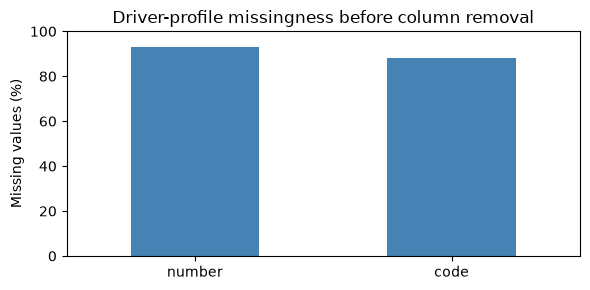

In [67]:
drivers_before_column_drop = drivers_clean.copy(deep=True)

print("BEFORE:", drivers_before_column_drop.shape)

missing_before = pd.DataFrame({
    "Missing count": drivers_before_column_drop.isna().sum(),
    "Missing (%)": drivers_before_column_drop.isna().mean() * 100
})

display(missing_before.round(2))

# Show examples with missing values and examples with both values present.
has_missing = drivers_before_column_drop[["number", "code"]].isna().any(axis=1)

display(pd.concat([
    drivers_before_column_drop.loc[has_missing].head(3),
    drivers_before_column_drop.loc[~has_missing].head(2)
]))

missing_before.loc[["number", "code"], "Missing (%)"].plot.bar(
    figsize=(6, 3), rot=0, color="steelblue"
)
plt.ylabel("Missing values (%)")
plt.ylim(0, 100)
plt.title("Driver-profile missingness before column removal")
plt.tight_layout()
plt.show()

In [68]:
driver_era_evidence = driver_history_audit.copy()

driver_era_evidence["Last recorded race"] = pd.cut(
    driver_era_evidence["last_recorded_year"],
    bins=[1949, 2004, 2013, 2024],
    labels=["1950–2004", "2005–2013", "2014–2024"]
)

era_summary = driver_era_evidence.groupby(
    "Last recorded race", observed=True
).agg(
    Drivers=("driverId", "size"),
    Missing_number=("number", lambda column: column.isna().sum()),
    Missing_code=("code", lambda column: column.isna().sum())
)

display(era_summary)

,Drivers,Missing_number,Missing_code
Last recorded race,,,
1950–2004,759,759,757
2005–2013,43,43,0
2014–2024,59,0,0


### Decision: remove the two profile columns

The evidence shows that missing numbers and codes are concentrated
among historical drivers.

Permanent career numbers were introduced for 2014.
[Official Formula 1 announcement](https://www.formula1.com/en/latest/article/fia-entry-list-reveals-driver-numbers-confirms-chilton.1Swz9WbOKOISg5ex6oE2gd)

Filling a missing profile number with a mean or median would invent
a number. Filling a missing code with another driver's abbreviation
would assign an incorrect identity label.

We therefore remove ⁠ number ⁠ and ⁠ code ⁠ from ⁠ drivers_clean ⁠.
Neither column is selected from the drivers table by our current
modeling code. This is a documented exclusion, not an experimentally
proven improvement in model performance.

We retain every driver and all other columns. The raw ⁠ drivers ⁠
table remains unchanged. Race-specific numbers in ⁠ results_clean ⁠
are unaffected.

In [69]:
drivers_clean = drivers_before_column_drop.drop(
    columns=["number", "code"]
).copy()

before_after = pd.DataFrame({
    "Before": [
        len(drivers_before_column_drop),
        drivers_before_column_drop.shape[1],
        drivers_before_column_drop.isna().sum().sum()
    ],
    "After": [
        len(drivers_clean),
        drivers_clean.shape[1],
        drivers_clean.isna().sum().sum()
    ]
}, index=["Rows", "Columns", "Missing cells"])

display(before_after)
display(drivers_clean.head())

# Verify that only the two specified columns were removed.
pd.testing.assert_frame_equal(
    drivers_clean,
    drivers_before_column_drop.drop(columns=["number", "code"])
)

# Verify that the raw drivers table was preserved.
pd.testing.assert_frame_equal(drivers, drivers_raw_snapshot)

assert drivers_clean["driverId"].notna().all()
assert drivers_clean["driverId"].is_unique

print("Passed: only number and code were removed; all drivers were retained.")

,Before,After
Rows,861,861
Columns,9,7
Missing cells,1559,0


,driverId,driverRef,forename,surname,dob,nationality,url
0,1,hamilton,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


Passed: only number and code were removed; all drivers were retained.


## 3.4 lap_times.csv

### Before-cleaning inspection

Each row represents one recorded lap for a driver in a race. The key is `(raceId, driverId, lap)`; repeated driver–race pairs across laps are expected.


### 3.4.1 Lap Times: Initial Auditing & Placeholder Detection
Establishing the baseline snapshot and calculating the true volume of missing data by identifying structural NaNs alongside literal `\N` text sentinels.

In [70]:
print("Rows:", lap_times.shape[0])
print("Columns:", lap_times.shape[1])

display(lap_times.head(10))
lap_times.info()

Rows: 589081
Columns: 6


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342
5,841,20,6,1,1:32.605,92605
6,841,20,7,1,1:32.502,92502
7,841,20,8,1,1:32.537,92537
8,841,20,9,1,1:33.240,93240
9,841,20,10,1,1:32.572,92572


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [71]:
missing = lap_times.isna().sum()
sentinels = lap_times.eq(r"\N").sum()

lap_inspection = pd.DataFrame({
    "Data type": lap_times.dtypes.astype(str),
    "Recognized missing": missing,
    r"\N placeholders": sentinels,
    "Total unavailable": missing + sentinels,
    "Unavailable %": (
        (missing + sentinels) / len(lap_times) * 100
    ).round(2)
})

display(lap_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
position,int64,0,0,0,0.0
time,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


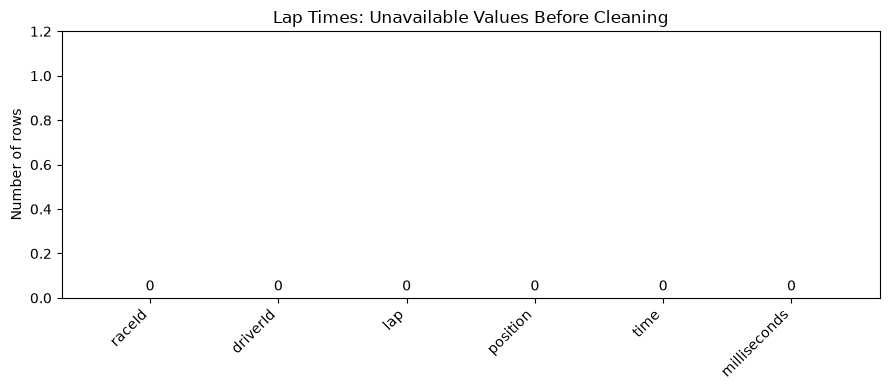

In [72]:
unavailable = missing + sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Lap Times: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Convert `time` to numeric seconds

The CSV already supplies `milliseconds`. After checking its availability, divide by 1,000 and replace `time` in `lap_times_clean`. Original text stays in `lap_times`. An independent text conversion below verifies agreement; no columns are added.


### 3.4.2 Lap Times: Cleaning Pipeline & Time Conversion
Executing the core transformations: replacing text placeholders, casting `milliseconds` to strict numeric types, and standardizing the `time` column by mathematically converting milliseconds into seconds (while proving the result exactly matches the original text strings).

In [73]:
lap_times_raw_snapshot = lap_times.copy(deep=True)
lap_times_clean = lap_times.copy(deep=True)
lap_times_clean = lap_times_clean.replace(r"\N", np.nan)


In [74]:
# Verify milliseconds are available wherever the original time is present.
lap_times_clean["milliseconds"] = pd.to_numeric(lap_times_clean["milliseconds"], errors="raise")
assert not (lap_times_clean["time"].notna() & lap_times_clean["milliseconds"].isna()).any(), "A recorded time has no milliseconds."

# 1,000 milliseconds = 1 second. Replace time in the cleaned copy only.
lap_times_clean["time"] = lap_times_clean["milliseconds"] / 1000


In [75]:
# Independently compare original text with the converted time.
lap_text = lap_times["time"].replace(r"\N", np.nan).astype("string")
lap_text = lap_text.where(lap_text.str.count(":").ne(1), "0:" + lap_text)
lap_text_seconds = pd.to_timedelta(lap_text, errors="raise").dt.total_seconds()
lap_matches = np.isclose(lap_text_seconds, lap_times_clean["time"], atol=0.001, rtol=0, equal_nan=True)
print("Original time values agreeing with converted seconds:", lap_matches.sum())
assert lap_matches.all(), "Original time and milliseconds disagree."


Original time values agreeing with converted seconds: 589081


### Before/after values and types

Compare the same `time` column in the original and cleaned tables. Hour-based examples demonstrate parsing support, not that unusually long records have been verified.


In [76]:
display(pd.DataFrame({
    "time BEFORE (text)": lap_times["time"].head(10),
    "time AFTER (seconds)": lap_times_clean["time"].head(10)
}))
print("time BEFORE type:", lap_times["time"].dtype)
print("time AFTER type:", lap_times_clean["time"].dtype)
hour_examples = lap_times["time"].astype("string").str.count(":").eq(2).fillna(False)
display(pd.DataFrame({
    "time BEFORE (text)": lap_times.loc[hour_examples, "time"],
    "time AFTER (seconds)": lap_times_clean.loc[hour_examples, "time"],
    "milliseconds": lap_times_clean.loc[hour_examples, "milliseconds"]
}).head(5))


,time BEFORE (text),time AFTER (seconds)
0,1:38.109,98.109
1,1:33.006,93.006
2,1:32.713,92.713
3,1:32.803,92.803
4,1:32.342,92.342
5,1:32.605,92.605
6,1:32.502,92.502
7,1:32.537,92.537
8,1:33.240,93.240
9,1:32.572,92.572


time BEFORE type: object
time AFTER type: float64


,time BEFORE (text),time AFTER (seconds),milliseconds
7916,2:05:05.152,7505.152,7505152
7985,2:05:04.226,7504.226,7504226
8020,2:05:06.656,7506.656,7506656
8089,2:05:05.034,7505.034,7505034
8165,2:05:01.488,7501.488,7501488


The cleaned `time` column contains seconds calculated from `milliseconds / 1000`. We independently converted original text to seconds and checked agreement. This verifies conversion consistency, not underlying record accuracy. Original rows and columns are preserved; no missing values are filled.


### Key and reference checks


### 3.4.3 Lap Times: Relational Integrity & Numeric Auditing
Validating primary and foreign keys to ensure no duplicate race-driver-lap combinations exist, and that every lap maps back to a valid driver and race in the reference tables. This step also verifies the distributions of lap, position, and time features using logarithmic visualizations to expose anomalies.

In [77]:
key_columns = ["raceId", "driverId", "lap"]

print("Missing key values:")
display(lap_times_clean[key_columns].isna().sum())

print(
    "Duplicate race–driver–lap records:",
    lap_times_clean.duplicated(key_columns).sum()
)

# Display problem records, if any.
duplicates = lap_times_clean.duplicated(key_columns, keep=False)

if duplicates.any():
    display(
        lap_times_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert lap_times_clean[key_columns].notna().all().all(), \
    "Missing raceId, driverId, or lap found"

assert not duplicates.any(), \
    "Repeated race–driver–lap records found"

print("Passed: race–driver–lap combinations are unique and non-null.")

Missing key values:


raceId      0
driverId    0
lap         0
dtype: int64

Duplicate race–driver–lap records: 0
Passed: race–driver–lap combinations are unique and non-null.


In [78]:
unknown_races = ~lap_times_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~lap_times_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(lap_times_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(lap_times_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), \
    "Some race IDs do not exist in races"

assert not unknown_drivers.any(), \
    "Some driver IDs do not exist in drivers"

print("Passed: all race and driver IDs exist in their reference tables.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: all race and driver IDs exist in their reference tables.


In [79]:
# Deduplicate only the lookup pairs, not the lap records.
result_pairs = results[["raceId", "driverId"]].drop_duplicates()

lap_pairs = (
    lap_times_clean[["raceId", "driverId"]]
    .drop_duplicates()
)

pair_check = lap_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs.head(20))

assert unmatched_pairs.empty, \
    "Some lap records belong to driver–race pairs absent from results"

print("Passed: all lap driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all lap driver–race pairs exist in results.


The combination of raceId, driverId, and lap is unique and non-null.
All race and driver references exist, and every recorded driver–race pair
has a corresponding result record. Repeated driver–race pairs across
different laps are expected and were preserved.

### Unusual-value investigation

Long recorded durations are inspected, not automatically removed. Their cause is not established by their size alone.


In [80]:
display(
    lap_times_clean[
        ["lap", "position", "time"]
    ].describe().T
)

print("Rows with lap <= 0:",
      lap_times_clean["lap"].le(0).sum())

print("Rows with position <= 0:",
      lap_times_clean["position"].le(0).sum())

print("Rows with time <= 0:",
      lap_times_clean["time"].le(0).sum())

,count,mean,std,min,25%,50%,75%,max
lap,589081.0,30.018104,18.407126,1.000,14.000,29.000,44.00,87.000
position,589081.0,9.661951,5.528553,1.000,5.000,9.000,14.00,24.000
time,589081.0,95.799445,76.399730,55.404,82.041,90.608,101.93,7507.547


Rows with lap <= 0: 0
Rows with position <= 0: 0
Rows with time <= 0: 0


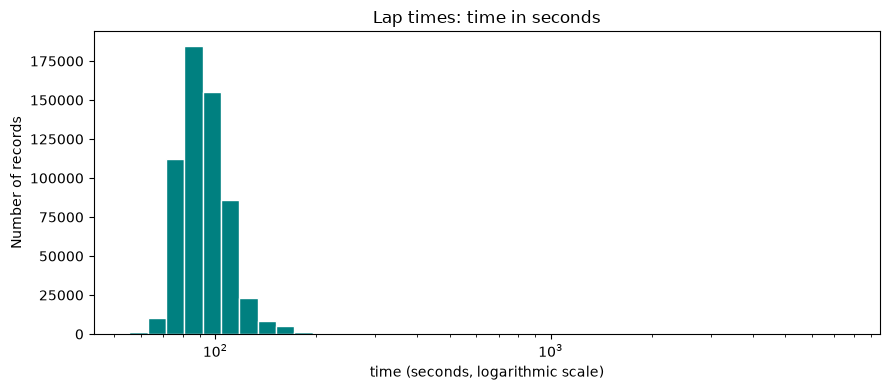

In [81]:
# Logarithmic bins show typical and unusually long durations together.
values = lap_times_clean.loc[lap_times_clean["time"] > 0, "time"].dropna()
if not values.empty:
    bins = np.geomspace(values.min(), values.max(), 40) if values.min() < values.max() else 10
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(values, bins=bins, color="teal", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title("Lap times: time in seconds")
    ax.set_xlabel("time (seconds, logarithmic scale)")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()


In [82]:
print("Largest time values — flagged for investigation, not removed:")
display(
    lap_times_clean.nlargest(10, "time")[
        ["raceId", "driverId", "lap", "position",
         "time", "milliseconds"]
    ]
)

Largest time values — flagged for investigation, not removed:


,raceId,driverId,lap,position,time,milliseconds
8372,847,2,25,4,7507.547,7507547
8020,847,13,25,3,7506.656,7506656
8426,847,808,25,5,7506.243,7506243
8621,847,155,25,2,7506.095,7506095
7916,847,20,25,1,7505.152,7505152
8089,847,17,25,7,7505.034,7505034
7985,847,4,25,8,7504.226,7504226
8495,847,814,25,6,7503.980,7503980
8876,847,37,25,9,7503.795,7503795
8234,847,18,25,11,7503.775,7503775


### Final verification


In [83]:
final_checks = pd.Series({
    "Row count unchanged":
        len(lap_times_clean) == len(lap_times),

    "No remaining placeholders":
        not lap_times_clean.eq(r"\N").any().any(),

    "Key columns non-null":
        lap_times_clean[["raceId", "driverId", "lap"]]
        .notna().all().all(),

    "Race–driver–lap key unique":
        not lap_times_clean.duplicated(
            ["raceId", "driverId", "lap"]
        ).any(),

    "time is numeric seconds":
        pd.api.types.is_numeric_dtype(
            lap_times_clean["time"]
        )
})

display(final_checks.to_frame("Passed"))

assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Key columns non-null,True
Race–driver–lap key unique,True
time is numeric seconds,True


### Extended audit — Numeric validity and position consistency

We check positive integer lap numbers and positions, finite positive durations, missing/blank timing text and full duplicate rows. We also compare positions with the number of distinct drivers listed in that event's results. A driver listed in results is not necessarily a starter, so this is an upper-bound consistency check rather than a count of starters.

Positions describe the recorded order on a lap, not the final finishing order. A different final position is therefore expected. We check whether two drivers have the same recorded position on the same numbered lap, and show the outcome instead of assuming it passes.


### 3.4.4 Lap Times: Sequence Validation & Result Discrepancies
Running cross-table assertions to verify the logic of the timing sequences (e.g., sequences must start at lap 1, without internal gaps). This audit systematically flags discrepancies between the timing row counts in `lap_times` and the officially completed `laps` recorded in the `results` table.

In [84]:
lap_numeric_checks = pd.Series({
    "No missing values": lap_times_clean.notna().all().all(),
    "No blank original time strings": not lap_times["time"].astype("string").str.strip().eq("").any(),
    "No outer whitespace in original time": lap_times["time"].eq(lap_times["time"].str.strip()).all(),
    "No full duplicate rows": not lap_times_clean.duplicated().any(),
    "Lap numbers are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["lap"]) and lap_times_clean["lap"].gt(0).all(),
    "Positions are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["position"]) and lap_times_clean["position"].gt(0).all(),
    "Seconds are finite and positive": np.isfinite(lap_times_clean["time"]).all() and lap_times_clean["time"].gt(0).all(),
    "Milliseconds are positive integers": pd.api.types.is_integer_dtype(lap_times_clean["milliseconds"]) and lap_times_clean["milliseconds"].gt(0).all()
})
display(lap_numeric_checks.to_frame("Passed"))
assert lap_numeric_checks.all()
lap_event_field_size = results.groupby("raceId")["driverId"].nunique()
lap_position_checks = pd.Series({
    "Positions above event's result field size": int(lap_times_clean["position"].gt(lap_times_clean["raceId"].map(lap_event_field_size)).sum()),
    "Rows with repeated race-lap-position": int(lap_times_clean.duplicated(["raceId", "lap", "position"], keep=False).sum())
})
display(lap_position_checks.to_frame("Rows"))
assert lap_position_checks.eq(0).all()


,Passed
No missing values,True
No blank original time strings,True
No outer whitespace in original time,True
No full duplicate rows,True
Lap numbers are positive integers,True
Positions are positive integers,True
Seconds are finite and positive,True
Milliseconds are positive integers,True


,Rows
Positions above event's result field size,0
Rows with repeated race-lap-position,0


### Check lap sequences against completed laps in results

For each driver–race pair, we calculate the first lap, last lap and number of recorded rows. This distinguishes missing values **inside rows** from missing **lap records**. Every existing sequence starts at lap 1 with no internal gaps; this does not establish that it belongs to the correct driver or includes every completed lap.

We then join to `results.laps`, meaning the recorded number of completed/classified laps. The join is restricted to the relevant driver–race pairs before checking uniqueness, so unrelated historical shared drives do not multiply rows.

The complete discrepancy table below shows **90 pairs: 37 with more recorded laps and 53 with fewer**. We do not force the counts to agree: either table may have an issue, and classification conventions can differ.


In [85]:
lap_sequence_audit = lap_times_clean.groupby(["raceId", "driverId"]).agg(
    Recorded_laps=("lap", "size"), First_lap=("lap", "min"), Last_lap=("lap", "max")
).reset_index()
lap_sequence_audit["Internal missing laps"] = (
    lap_sequence_audit["Last_lap"] - lap_sequence_audit["First_lap"] + 1 - lap_sequence_audit["Recorded_laps"]
)
lap_relevant_results = results.merge(
    lap_sequence_audit[["raceId", "driverId"]], on=["raceId", "driverId"], validate="many_to_one"
)
lap_sequence_audit = lap_sequence_audit.merge(
    lap_relevant_results[["resultId", "raceId", "driverId", "laps", "positionText", "statusId"]],
    on=["raceId", "driverId"], validate="one_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
lap_sequence_audit["Count difference"] = lap_sequence_audit["Recorded_laps"] - lap_sequence_audit["laps"]
assert lap_sequence_audit["First_lap"].eq(1).all()
assert lap_sequence_audit["Internal missing laps"].eq(0).all()
lap_count_discrepancies = lap_sequence_audit.loc[lap_sequence_audit["Count difference"].ne(0)].copy()
lap_count_discrepancies["Review"] = "Needs individual investigation"
lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].eq(903), "Review"] = "China 2014: early flag/classified distance"
display(pd.Series({
    "Driver-race sequences checked": len(lap_sequence_audit),
    "Sequences not starting at 1": int(lap_sequence_audit["First_lap"].ne(1).sum()),
    "Sequences with internal gaps": int(lap_sequence_audit["Internal missing laps"].gt(0).sum()),
    "Recorded count greater than results.laps": int(lap_sequence_audit["Count difference"].gt(0).sum()),
    "Recorded count smaller than results.laps": int(lap_sequence_audit["Count difference"].lt(0).sum())
}).to_frame("Pairs"))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(lap_count_discrepancies[["raceId", "year", "name", "driverId", "forename", "surname", "Recorded_laps", "laps", "Count difference", "positionText", "status", "Review"]])
assert len(lap_count_discrepancies) == 90


,Pairs
Driver-race sequences checked,11041
Sequences not starting at 1,0
Sequences with internal gaps,0
Recorded count greater than results.laps,37
Recorded count smaller than results.laps,53


,raceId,year,name,driverId,forename,surname,Recorded_laps,laps,Count difference,positionText,status,Review
240,13,2009,Italian Grand Prix,17,Mark,Webber,52,0,52,R,Collision,Needs individual investigation
246,13,2009,Italian Grand Prix,67,Sébastien,Buemi,19,52,-33,13,+1 Lap,Needs individual investigation
377,20,2008,Bahrain Grand Prix,16,Adrian,Sutil,55,56,-1,19,+2 Laps,Needs individual investigation
389,21,2008,Spanish Grand Prix,7,Sébastien,Bourdais,4,7,-3,R,Collision,Needs individual investigation
452,24,2008,Canadian Grand Prix,12,Nelson,Piquet Jr.,39,43,-4,R,Brakes,Needs individual investigation
498,26,2008,British Grand Prix,21,Giancarlo,Fisichella,26,16,10,R,Spun off,Needs individual investigation
779,40,2007,Monaco Grand Prix,24,Vitantonio,Liuzzi,1,2,-1,R,Accident,Needs individual investigation
805,42,2007,United States Grand Prix,2,Nick,Heidfeld,55,56,-1,R,Transmission,Needs individual investigation
1252,63,2006,French Grand Prix,17,Mark,Webber,53,55,-2,R,Wheel rim,Needs individual investigation
1255,63,2006,French Grand Prix,22,Rubens,Barrichello,18,28,-10,R,Engine,Needs individual investigation


#### See the cross-table problem before making changes

We join `results` and `lap_times` using **both `raceId` and `driverId`**. For each driver in each race, we compare `results.laps` with the number of timing rows. The table above lists all **90 differences out of 11,041 matched pairs**. The plots below show these differences before any lap-count or driver-assignment correction.

A flag means **investigate this pair**, not **this value is wrong**. For example, a timing sequence may be incomplete, a driver ID may be wrong, or classified distance may legitimately differ from timing distance. We consult sources only after this consistency check identifies a case. Matching counts also do not prove that every timing value is correct.

The flags live in a separate audit table; we do not add columns to the clean tables.


Matched driver–race pairs: 11041
Flagged pairs: 90
Flagged percentage: 0.82


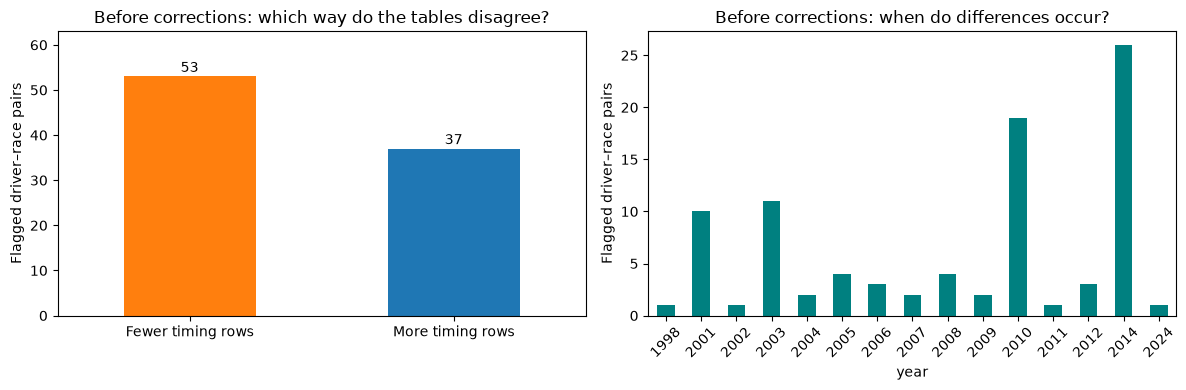

In [86]:
# Keep the original cross-table findings for the final evidence trail.
lap_consistency_flags_before = lap_count_discrepancies[[
    "raceId", "driverId", "year", "name", "forename", "surname",
    "laps", "Recorded_laps", "Count difference"
]].copy().rename(columns={"laps": "Original result laps", "Recorded_laps": "Original timing rows"})
lap_consistency_flags_before["Flag"] = "Fewer timing rows than completed laps"
lap_consistency_flags_before.loc[
    lap_consistency_flags_before["Count difference"].gt(0), "Flag"
] = "More timing rows than completed laps"
print("Matched driver–race pairs:", len(lap_sequence_audit))
print("Flagged pairs:", len(lap_consistency_flags_before))
print("Flagged percentage:", round(len(lap_consistency_flags_before) / len(lap_sequence_audit) * 100, 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
directions = pd.Series({
    "Fewer timing rows": int(lap_consistency_flags_before["Count difference"].lt(0).sum()),
    "More timing rows": int(lap_consistency_flags_before["Count difference"].gt(0).sum())
})
directions.plot.bar(ax=axes[0], color=["tab:orange", "tab:blue"], rot=0)
axes[0].set_title("Before corrections: which way do the tables disagree?")
axes[0].set_ylabel("Flagged driver–race pairs")
for i, count in enumerate(directions):
    axes[0].text(i, count + 1, str(count), ha="center")
axes[0].set_ylim(0, directions.max() + 10)
lap_consistency_flags_before.groupby("year").size().plot.bar(ax=axes[1], color="teal", rot=45)
axes[1].set_title("Before corrections: when do differences occur?")
axes[1].set_ylabel("Flagged driver–race pairs")
plt.tight_layout()
plt.show()
assert len(lap_consistency_flags_before) == 90


### Missing-record coverage — Before 1996 and within the covered period

[The Jolpica project's lap endpoint documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/laps.md), for the successor to Ergast, states that lap data starts in **1996**. Our actual local records cover 1996–2024. We do not invent timings for 1950–1995.

Within 1996–2024, every race has at least some lap records. Nevertheless, **455 result pairs have none**: 453 have `results.laps = 0`, which is consistent with having no completed lap to time. The remaining **two have positive completed-lap counts**, so they need investigation. The joined table identifies them; their missing timings cannot be reconstructed from a mean or median.

The annual graph measures the proportion of positive-lap result entries with at least one timing row. It checks coverage of drivers, not completeness or correctness of every lap.


,Entries
Result entries without lap records (1996+),455
"Of these, zero completed laps in results",453
"Of these, positive completed laps in results",2


,resultId,raceId,year,name,driverId,forename,surname,laps,positionText,status
132,2872,155,2001,Italian Grand Prix,55,Jean,Alesi,52,8,+1 Lap
256,7811,13,2009,Italian Grand Prix,153,Jaime,Alguersuari,19,R,Retired


,Positive_lap_entries,Entries_with_timing,Coverage (%)
year,,,
1996,310,310,100.00
1997,355,355,100.00
1998,329,329,100.00
1999,330,330,100.00
2000,354,354,100.00
2001,355,354,99.72
2002,341,341,100.00
2003,307,307,100.00
2004,347,347,100.00


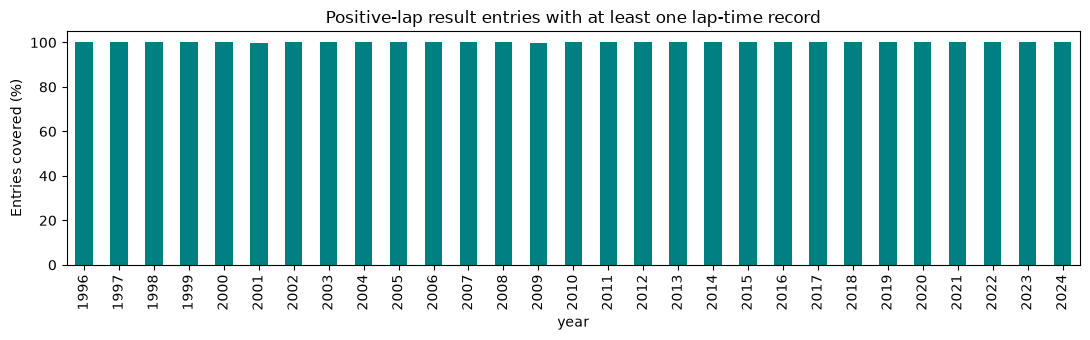

In [87]:
lap_coverage_audit = results[["resultId", "raceId", "driverId", "laps", "positionText", "statusId"]].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
lap_coverage_audit = lap_coverage_audit.loc[lap_coverage_audit["year"].ge(1996)].merge(
    lap_times_clean[["raceId", "driverId"]].drop_duplicates(),
    on=["raceId", "driverId"], how="left", validate="one_to_one", indicator=True
)
lap_coverage_audit["Has lap records"] = lap_coverage_audit["_merge"].eq("both")
lap_missing_entries = lap_coverage_audit.loc[~lap_coverage_audit["Has lap records"]].drop(columns="_merge").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
lap_missing_positive_entries = lap_missing_entries.loc[lap_missing_entries["laps"].gt(0)].copy()
display(pd.Series({
    "Result entries without lap records (1996+)": len(lap_missing_entries),
    "Of these, zero completed laps in results": int(lap_missing_entries["laps"].eq(0).sum()),
    "Of these, positive completed laps in results": len(lap_missing_positive_entries)
}).to_frame("Entries"))
display(lap_missing_positive_entries[["resultId", "raceId", "year", "name", "driverId", "forename", "surname", "laps", "positionText", "status"]])
lap_annual_coverage = lap_coverage_audit.loc[lap_coverage_audit["laps"].gt(0)].groupby("year").agg(
    Positive_lap_entries=("driverId", "size"), Entries_with_timing=("Has lap records", "sum")
)
lap_annual_coverage["Coverage (%)"] = 100 * lap_annual_coverage["Entries_with_timing"] / lap_annual_coverage["Positive_lap_entries"]
display(lap_annual_coverage.round(2))
lap_annual_coverage["Coverage (%)"].plot.bar(figsize=(11, 3.5), color="teal")
plt.title("Positive-lap result entries with at least one lap-time record")
plt.ylabel("Entries covered (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()
assert len(lap_missing_entries) == 455
assert len(lap_missing_positive_entries) == 2
assert set(lap_coverage_audit["raceId"]) == set(lap_times_clean["raceId"])


### Evidence for preserving unusual timings and classified-distance differences

Sources reviewed on **11 October 2026**. Observations are manually documented; the notebook does not scrape these pages when run.

| Observation | Local evidence shown below | External evidence and decision |
|---|---|---|
| Canada 2011: timings around two hours | 23 drivers have hour-format timings at lap 25 | [F1's race history](https://www.formula1.com/en/latest/article/canada-2011-torrential-rain-a-safety-car-record-and-buttons-charge-the.1ZWPateMlCFLZ8U6KQBNXj) documents the prolonged rain stoppage. Their shared location and size are consistent with suspension time in the timing interval. Preserve; do not interpret them as continuous racing pace. |
| Britain 2014: timings around one hour | 20 drivers have hour-format timings at lap 1 or 2 | [Red Bull's race report](https://www.redbull.com/us-en/british-grand-prix-wrap-up) documents an hour-long stoppage after Räikkönen's crash. Preserve; the event explains the scale, without independently verifying every millisecond. |
| Sakhir 2020: shortest record, 55.404 seconds | Russell, driver 847, lap 80 | [Official fastest laps](https://www.formula1.com/en/results/2020/races/1060/sakhir/fastest-laps) confirms the exact driver, lap and time. Preserve. |
| China 2014: 20 driver sequences exceed classified distance by two laps | Every affected sequence differs by exactly +2 | [F1's race report](https://www.formula1.com/en/latest/article/race-hamilton-dominates-alonso-beats-red-bulls-in-china.vS3tgs1DaHdohe9z8aPTZ.vS3tgs1DaHdohe9z8aPTZ) explains that results were declared at lap 54 of 56 following the early flag. Preserve recorded timing rows and classified result laps as distinct measurements. |

Hour format is a transparent investigation category, not a threshold defining wrong data. Smaller unusual durations can have other causes, including pit stops and safety-car periods; no blanket outlier removal is applied.


### 3.4.5 Lap Times: Edge-Case Investigation & Final Validation
Manually reviewing known historical exceptions, including hour-long lap records (e.g., red flag stoppages) and the China 2014 distance discrepancy. Concludes with a rigorous suite of assertion tests confirming that only the targeted numeric conversions were applied.

Rows  Shortest_seconds  Longest_seconds
raceId year name                lap                                         
847    2011 Canadian Grand Prix 25     23          7469.869         7507.547
908    2014 British Grand Prix  1       2          3698.698         3702.636
                                2      18          3667.384         3803.459

,raceId,driverId,lap,position,time,milliseconds,year,name,forename,surname
0,1046,847,80,14,55.404,55404,2020,Sakhir Grand Prix,George,Russell


,Pairs
Review,
China 2014: early flag/classified distance,20
Needs individual investigation,70


,raceId,year,name,driverId,lap,time,milliseconds
0,847,2011,Canadian Grand Prix,18,24,136.959,136959
1,847,2011,Canadian Grand Prix,18,25,7503.775,7503775
2,847,2011,Canadian Grand Prix,18,26,141.746,141746
3,908,2014,British Grand Prix,1,1,139.816,139816
4,908,2014,British Grand Prix,1,2,3698.495,3698495
5,908,2014,British Grand Prix,1,3,100.284,100284


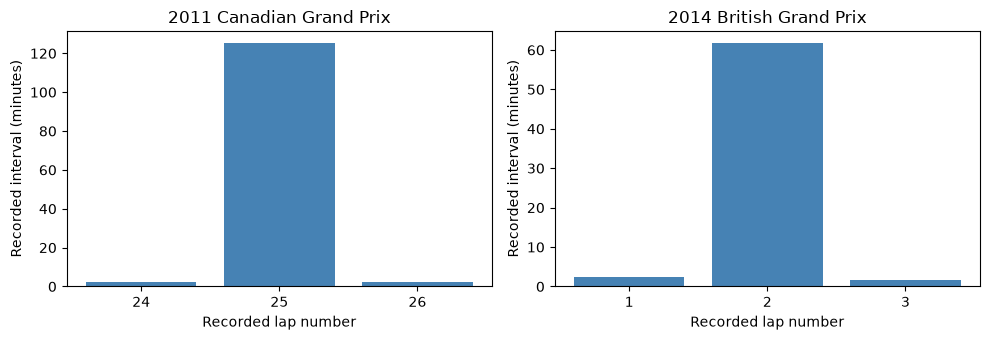

In [88]:
lap_hour_records = lap_times_clean.loc[hour_examples].merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
display(lap_hour_records.groupby(["raceId", "year", "name", "lap"]).agg(
    Rows=("driverId", "size"), Shortest_seconds=("time", "min"), Longest_seconds=("time", "max")
))
display(lap_times_clean.nsmallest(1, "time").merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"))
lap_china_distance_evidence = lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].eq(903)]
assert len(lap_china_distance_evidence) == 20
assert lap_china_distance_evidence["Count difference"].eq(2).all()
display(lap_count_discrepancies.groupby("Review").size().to_frame("Pairs"))

# Show neighbouring recorded laps for one driver from each reviewed stoppage.
lap_stoppage_examples = lap_times_clean.loc[
    (lap_times_clean["raceId"].eq(847) & lap_times_clean["driverId"].eq(18) & lap_times_clean["lap"].between(24, 26))
    | (lap_times_clean["raceId"].eq(908) & lap_times_clean["driverId"].eq(1) & lap_times_clean["lap"].between(1, 3))
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
display(lap_stoppage_examples[["raceId", "year", "name", "driverId", "lap", "time", "milliseconds"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (race_id, group) in zip(axes, lap_stoppage_examples.groupby("raceId")):
    ax.bar(group["lap"].astype(str), group["time"] / 60, color="steelblue")
    ax.set_title(str(group["year"].iloc[0]) + " " + group["name"].iloc[0])
    ax.set_xlabel("Recorded lap number")
    ax.set_ylabel("Recorded interval (minutes)")
plt.tight_layout()
plt.show()


### Unresolved cases — Evidence for further investigation

After the 20 China cases are explained, **70 lap-count discrepancies remain unresolved**, alongside the **two positive-lap result entries with no timing rows**. These sets overlap in their possible causes; they are not 72 proven independent errors.

Two particularly clear events deserve investigation:

- **Italy 2001 (`raceId=155`):** `results` and the [official classification](https://www.formula1.com/en/results/2001/races/717/italy/race-result) give Alesi 52 laps and Trulli 0. Local lap rows instead give Trulli 52 and Alesi none. Other 2001 Alesi/Trulli count differences also appear in the full discrepancy table. This suggests possible attribution problems, but matching counts alone does not prove which driver owns each timing.
- **Italy 2009 (`raceId=13`):** `results` and the [official classification](https://www.formula1.com/en/results/2009/races/855/italy/race-result) give Buemi 52, Alguersuari 19 and Webber 0 laps. Local lap rows give Webber 52, Buemi 19 and Alguersuari none. The joined table below exposes this inconsistency. We need driver-specific timing evidence before relabeling rows.

**Treatment now:** keep the raw and cleaned timing records, save explicit audit lists, and do not invent missing lap times, swap IDs or delete records merely to make totals agree. Ask the TA whether to recover these timings from an authoritative lap chart or exclude the affected sequences from a particular lap-based analysis. Current-race timings must not be used as pre-race prediction inputs. This table's review has identified issues; it is not yet an all-clear on underlying timing accuracy.

**Stage note:** This is the audit before the source-backed corrections later in the results section. See **“Complete investigation of lap-count differences”** for the current decisions and final counts.


In [89]:
lap_attribution_evidence = results.loc[
    (results["raceId"].eq(155) & results["driverId"].isin([15, 55]))
    | (results["raceId"].eq(13) & results["driverId"].isin([17, 67, 153])),
    ["resultId", "raceId", "driverId", "laps", "positionText"]
].merge(
    lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Recorded lap rows").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one").merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
# Zero here describes an actual count of rows, not an imputed lap time.
lap_attribution_evidence["Recorded lap rows"] = lap_attribution_evidence["Recorded lap rows"].fillna(0).astype(int)
display(lap_attribution_evidence[["raceId", "year", "name", "driverId", "forename", "surname", "laps", "Recorded lap rows", "positionText"]])
lap_unresolved_count_discrepancies = lap_count_discrepancies.loc[lap_count_discrepancies["raceId"].ne(903)].copy()
assert len(lap_unresolved_count_discrepancies) == 70


,raceId,year,name,driverId,forename,surname,laps,Recorded lap rows,positionText
0,155,2001,Italian Grand Prix,55,Jean,Alesi,52,0,8
1,155,2001,Italian Grand Prix,15,Jarno,Trulli,0,52,R
2,13,2009,Italian Grand Prix,67,Sébastien,Buemi,52,19,13
3,13,2009,Italian Grand Prix,153,Jaime,Alguersuari,19,0,R
4,13,2009,Italian Grand Prix,17,Mark,Webber,0,52,R


### Lap times — Final preservation and before/after checks

There are **589,081 rows and the original 6 columns**. No values are missing inside the existing rows, so no filling is needed there. Missing records and attribution discrepancies are documented separately above.

The only data transformation is the existing replacement of `time` text with numeric seconds. The independent text conversion agrees with milliseconds for every row. All other values are preserved. The table below checks missing counts and types before and after; assertions also verify the full table against the documented conversion and prove the raw data stayed unchanged.

**Stage note:** This is the audit before the source-backed corrections later in the results section. See **“Complete investigation of lap-count differences”** for the current decisions and final counts.


In [90]:
lap_final_comparison = pd.DataFrame({
    "Type before": lap_times.dtypes.astype(str), "Type after": lap_times_clean.dtypes.astype(str),
    "Missing before": lap_times.replace(r"\N", np.nan).isna().sum(),
    "Missing after": lap_times_clean.isna().sum()
})
display(lap_final_comparison)
lap_expected_clean = lap_times.replace(r"\N", np.nan).copy(deep=True)
lap_expected_clean["milliseconds"] = pd.to_numeric(lap_expected_clean["milliseconds"], errors="raise")
lap_expected_clean["time"] = lap_expected_clean["milliseconds"] / 1000
pd.testing.assert_frame_equal(lap_times_clean, lap_expected_clean)
pd.testing.assert_frame_equal(lap_times, lap_times_raw_snapshot)
assert lap_times_clean.shape == lap_times.shape == (589081, 6)
assert lap_times_clean.columns.equals(lap_times.columns)
assert lap_matches.all()
print("Passed: structural, reference, numeric and conversion checks; raw data preserved. Cross-table discrepancy lists remain open for investigation.")


,Type before,Type after,Missing before,Missing after
raceId,int64,int64,0,0
driverId,int64,int64,0,0
lap,int64,int64,0,0
position,int64,int64,0,0
time,object,float64,0,0
milliseconds,int64,int64,0,0


Passed: structural, reference, numeric and conversion checks; raw data preserved. Cross-table discrepancy lists remain open for investigation.


In [91]:
lap_times_clean.info()
assert lap_times_clean.columns.equals(lap_times.columns), "Unexpected added or removed lap columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   raceId        589081 non-null  int64  
 1   driverId      589081 non-null  int64  
 2   lap           589081 non-null  int64  
 3   position      589081 non-null  int64  
 4   time          589081 non-null  float64
 5   milliseconds  589081 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 27.0 MB


## 3.5 pit_stops.csv

### 3.5.1 Pit Stops: Initial Auditing & Placeholder Detection
Establishing the baseline snapshot of the `pit_stops` table and visualizing the exact volume of missing data by identifying structural NaNs alongside literal `\N` text sentinels.

### Before-cleaning inspection

Each row represents one recorded pit stop. The key is `(raceId, driverId, stop)`. `time` is a clock time; `duration` is elapsed time.


In [92]:
print("Rows:", pit_stops.shape[0])
print("Columns:", pit_stops.shape[1])

display(pit_stops.head(10))
pit_stops.info()

Rows: 11371
Columns: 7


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842
5,841,22,1,13,17:24:29,23.643,23643
6,841,20,1,14,17:25:17,22.603,22603
7,841,814,1,14,17:26:03,24.863,24863
8,841,816,1,14,17:26:50,25.259,25259
9,841,67,1,15,17:27:34,25.342,25342


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [93]:
pit_missing = pit_stops.isna().sum()
pit_sentinels = pit_stops.eq(r"\N").sum()

pit_inspection = pd.DataFrame({
    "Data type": pit_stops.dtypes.astype(str),
    "Recognized missing": pit_missing,
    r"\N placeholders": pit_sentinels,
    "Total unavailable": pit_missing + pit_sentinels,
    "Unavailable %": (
        (pit_missing + pit_sentinels) / len(pit_stops) * 100
    ).round(2)
})

display(pit_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
stop,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
time,object,0,0,0,0.0
duration,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


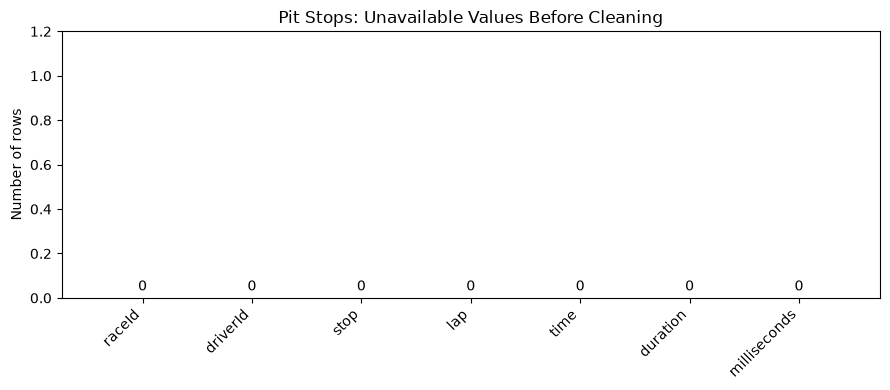

In [94]:
unavailable = pit_missing + pit_sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Pit Stops: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [95]:
display(
    pit_stops.select_dtypes(include="number").describe().T
)

# Show examples of durations written with minutes.
minute_format = (
    pit_stops["duration"]
    .astype("string")
    .str.contains(":", na=False)
)

print("Durations containing a colon:", minute_format.sum())

display(
    pit_stops.loc[
        minute_format,
        ["raceId", "driverId", "stop", "lap",
         "duration", "milliseconds"]
    ].head(10)
)

,count,mean,std,min,25%,50%,75%,max
raceId,11371.0,981.194882,92.326831,841.0,895.0,971.0,1065.0,1144.0
driverId,11371.0,549.734500,383.734981,1.0,20.0,817.0,835.0,862.0
stop,11371.0,1.787969,1.521462,1.0,1.0,2.0,2.0,70.0
lap,11371.0,25.387389,14.831497,1.0,13.0,25.0,36.0,78.0
milliseconds,11371.0,85230.495559,310427.261089,12897.0,21937.5,23606.0,26544.0,3069017.0


Durations containing a colon: 517


,raceId,driverId,stop,lap,duration,milliseconds
751,853,817,1,1,16:44.718,1004718
2419,881,814,2,20,2:03.124,123124
2420,881,16,2,22,1:29.401,89401
2421,881,18,3,35,1:44.833,104833
2422,884,16,1,8,1:14.026,74026
2533,888,17,1,8,2:42.042,162042
2713,893,154,3,33,1:13.009,73009
2802,894,16,3,38,1:11.445,71445
3089,901,817,3,40,1:49.329,109329
3159,903,13,1,10,1:18.277,78277


### Placeholder handling and semantic typing


### 3.5.2 Pit Stops: Cleaning Pipeline & Time Conversions
Executing core transformations: replacing placeholders, standardizing `duration` from milliseconds into numeric seconds, and safely casting the clock `time` column into a strict pandas timedelta format (representing the time elapsed since midnight).

In [96]:
pit_stops_clean = pit_stops.copy(deep=True)

pit_stops_clean = pit_stops_clean.replace(r"\N", np.nan)

In [97]:
# Verify milliseconds are available wherever the original duration is present.
pit_stops_clean["milliseconds"] = pd.to_numeric(pit_stops_clean["milliseconds"], errors="raise")
assert not (pit_stops_clean["duration"].notna() & pit_stops_clean["milliseconds"].isna()).any(), "A recorded duration has no milliseconds."

pit_stops_clean["duration"] = pit_stops_clean["milliseconds"] / 1000


In [98]:
# Validate clock text first, then store the offset since midnight.
clock_check = pd.to_datetime(
    pit_stops_clean["time"], format="%H:%M:%S", errors="coerce"
)
invalid_clock = pit_stops_clean["time"].notna() & clock_check.isna()
print("Invalid non-missing time values:", int(invalid_clock.sum()))
assert not invalid_clock.any(), "Investigate invalid clock readings."

# Same column, pandas-native dtype; this is time since midnight, not stop duration.
pit_stops_clean["time"] = pd.to_timedelta(pit_stops_clean["time"], errors="raise").astype("timedelta64[ns]")
assert pd.api.types.is_timedelta64_dtype(pit_stops_clean["time"])
assert pit_stops_clean["time"].dropna().between(pd.Timedelta(0), pd.Timedelta(days=1), inclusive="left").all()


Invalid non-missing time values: 0


In [99]:
# Independently check both original duration formats against milliseconds.
pit_text = pit_stops["duration"].replace(r"\N", np.nan).astype("string")
pit_text = pit_text.where(pit_text.str.count(":").ne(1), "0:" + pit_text)
pit_text = pit_text.where(pit_text.str.contains(":", na=True), pit_text + "s")
pit_text_seconds = pd.to_timedelta(pit_text, errors="raise").dt.total_seconds()
pit_matches = np.isclose(pit_text_seconds, pit_stops_clean["duration"], atol=0.001, rtol=0, equal_nan=True)
print("Original duration values agreeing with converted seconds:", pit_matches.sum())
assert pit_matches.all(), "Original duration and milliseconds disagree."


Original duration values agreeing with converted seconds: 11371


### Before/after evidence


In [100]:
display(pd.DataFrame({
    "duration BEFORE (text)": pit_stops["duration"].head(10),
    "duration AFTER (seconds)": pit_stops_clean["duration"].head(10),
    "time BEFORE (text)": pit_stops["time"].head(10),
    "time AFTER (since midnight)": pit_stops_clean["time"].head(10)
}))
print("duration BEFORE type:", pit_stops["duration"].dtype)
print("duration AFTER type:", pit_stops_clean["duration"].dtype)
print("time BEFORE type:", pit_stops["time"].dtype)
print("time AFTER type:", pit_stops_clean["time"].dtype)
print("Rows BEFORE:", len(pit_stops))
print("Rows AFTER:", len(pit_stops_clean))
print("Missing duration AFTER:", pit_stops_clean["duration"].isna().sum())
print("Missing time AFTER:", pit_stops_clean["time"].isna().sum())
print("Actual non-missing value types BEFORE:", pit_stops["time"].dropna().map(type).value_counts())
print("Actual non-missing value types AFTER:", pit_stops_clean["time"].dropna().map(type).value_counts())


,duration BEFORE (text),duration AFTER (seconds),time BEFORE (text),time AFTER (since midnight)
0,26.898,26.898,17:05:23,0 days 17:05:23
1,25.021,25.021,17:05:52,0 days 17:05:52
2,23.426,23.426,17:20:48,0 days 17:20:48
3,23.251,23.251,17:22:34,0 days 17:22:34
4,23.842,23.842,17:24:10,0 days 17:24:10
5,23.643,23.643,17:24:29,0 days 17:24:29
6,22.603,22.603,17:25:17,0 days 17:25:17
7,24.863,24.863,17:26:03,0 days 17:26:03
8,25.259,25.259,17:26:50,0 days 17:26:50
9,25.342,25.342,17:27:34,0 days 17:27:34


duration BEFORE type: object
duration AFTER type: float64
time BEFORE type: object
time AFTER type: timedelta64[ns]
Rows BEFORE: 11371
Rows AFTER: 11371
Missing duration AFTER: 0
Missing time AFTER: 0
Actual non-missing value types BEFORE: time
<class 'str'>    11371
Name: count, dtype: int64


Actual non-missing value types AFTER: time
<class 'pandas._libs.tslibs.timedeltas.Timedelta'>    11371
Name: count, dtype: int64


The cleaned `duration` contains numeric elapsed seconds, independently checked against the original text. The existing `time` column has pandas dtype **`timedelta64[ns]`**, representing **time since midnight**. Example: `13:25:44` becomes `0 days 13:25:44`. This representation preserves the clock reading without assigning a calendar date or timezone. It is not elapsed race time or the duration of a stop. Raw data stays unchanged, no columns are added, and missing values remain missing (`NaT` for clock offsets). The before/after table shows values, dtype and element types.


### Meaning of the recorded duration

The [Jolpica pit-stop documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) describes duration as including pit entry, exit and, where applicable, red-flag time. Therefore a large duration alone is not an error flag. We validate the existing duration representation against milliseconds, without searching individual large values for mistakes or altering them.


### 3.5.3 Pit Stops: Relational Integrity & Key Validation
Validating the composite primary key (`raceId`, `driverId`, `stop`) to ensure no duplicate records exist, and verifying that every recorded pit stop maps strictly to known entities in the `races`, `drivers`, and `results` tables.

### Key and reference checks


In [101]:
key_columns = ["raceId", "driverId", "stop"]

display(
    pit_stops_clean[key_columns]
    .isna()
    .sum()
    .to_frame("Missing key values")
)

duplicates = pit_stops_clean.duplicated(
    key_columns, keep=False
)

print("Extra duplicate key rows:",
      pit_stops_clean.duplicated(key_columns).sum())

if duplicates.any():
    display(
        pit_stops_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert pit_stops_clean[key_columns].notna().all().all(), \
    "Missing key values found"

assert not duplicates.any(), \
    "Repeated race–driver–stop combinations found"

print("Passed: the key is unique and non-null.")

,Missing key values
raceId,0
driverId,0
stop,0


Extra duplicate key rows: 0
Passed: the key is unique and non-null.


In [102]:
unknown_races = ~pit_stops_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~pit_stops_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(pit_stops_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(pit_stops_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), "Unknown race IDs found"
assert not unknown_drivers.any(), "Unknown driver IDs found"

print("Passed: race and driver references exist.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: race and driver references exist.


In [103]:
pit_pairs = pit_stops_clean[
    ["raceId", "driverId"]
].drop_duplicates()

result_pairs = results[
    ["raceId", "driverId"]
].drop_duplicates()

pair_check = pit_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs)

assert unmatched_pairs.empty, \
    "Some pit-stop driver–race pairs are absent from results"

print("Passed: all driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all driver–race pairs exist in results.


### Cross-table consistency audit — apply the rule to every record

**Meaning first:** `pit_stops.lap` is the lap associated with one pit stop. `results.laps` is the total number of laps the driver completed. They are different quantities, so we do **not** test equality. A stop on lap 20 and a result of 60 completed laps can agree perfectly. See the [pit-stop fields](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) and [result fields](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/results.md).

**General screening rule:** join every pit-stop row to the result for the same `(raceId, driverId)`, then display all cases where the pit lap exceeds the recorded completed-lap total. This is a review trigger, not proof of an error: a lap number is not always a completed lap, and classification conventions or disqualification can require explanation. A zero total can be valid if no laps were completed; zero by itself is not an error.

We apply this rule to **all 11,371 rows**, without selecting a driver or race first. Only after displaying the exceptions do we identify the driver and consult evidence. The assertions mentioning the discovered IDs are final regression checks, not the filter that discovered them.

Other cross-table rules check that the driver and race exist separately, that the driver–race combination exists in results, and that the pit lap has a matching timing row. Matching timing rows do not prove every stop number or duration is correct. Basic type, missing-value and key checks remain separate from these cross-table rules. Unusual stop numbering and large durations are not used as case-investigation triggers in this audit.


### 3.5.4 Pit Stops: Sequence Auditing, Edge Cases & Final Validation
Running cross-table logic checks to flag impossible pit stop sequences, such as pit stop laps exceeding a driver's officially completed laps or laps decreasing in chronological order. Includes an audit of modern pit stop coverage (2011 onward), resolution of known edge cases, and final structural assertions.

,Rows / cells
Full duplicate rows,0
Blank text cells,0
Non-positive milliseconds,0
Invalid integer values: raceId,0
Invalid integer values: driverId,0
Invalid integer values: stop,0
Invalid integer values: lap,0


Pit-stop rows screened against result totals: 11371


,Flagged rows / pairs
Unknown race IDs,0
Unknown driver IDs,0
Pit pairs absent from results,0
Pit laps without timing rows,0
Pit laps beyond raw result total,3
Decreasing laps in stop order,0


,raceId,year,name,driverId,forename,surname,stop,lap,laps,status
11210,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,1,25,0,Disqualified
11223,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,2,27,0,Disqualified
11226,1141,2024,São Paulo Grand Prix,807,Nico,Hülkenberg,3,29,0,Disqualified


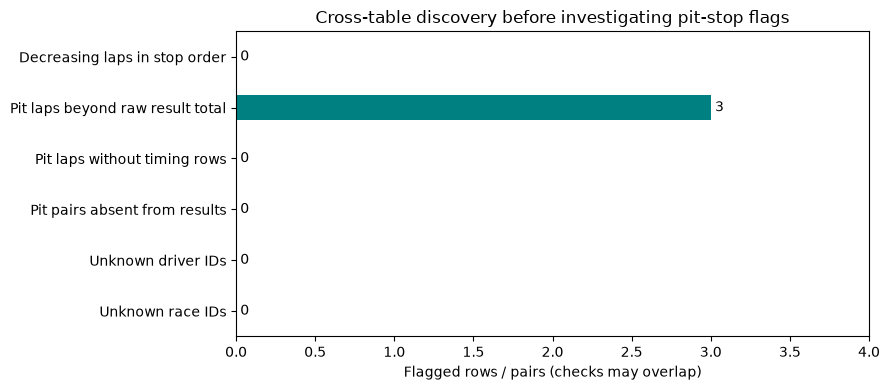

In [104]:
# Basic record checks, without changing any values.
pit_basic_checks = pd.Series({
    "Full duplicate rows": int(pit_stops.duplicated().sum()),
    "Blank text cells": int(pit_stops.select_dtypes(include="object").apply(
        lambda col: col.astype("string").str.strip().eq("").sum()).sum()),
    "Non-positive milliseconds": int(pit_stops_clean["milliseconds"].le(0).sum())
})
for col in ["raceId", "driverId", "stop", "lap"]:
    values = pd.to_numeric(pit_stops_clean[col], errors="coerce")
    pit_basic_checks["Invalid integer values: " + col] = int(
        (values.isna() | values.le(0) | values.mod(1).ne(0)).sum())
display(pit_basic_checks.to_frame("Rows / cells"))
assert pit_basic_checks.eq(0).all()

# Filter to relevant result pairs before validating: historical duplicates elsewhere
# must not multiply these joins or be silently removed.
pit_relevant_results = results.merge(pit_pairs, on=["raceId", "driverId"], validate="many_to_one")
assert not pit_relevant_results.duplicated(["raceId", "driverId"]).any()
pit_result_audit = pit_stops_clean.merge(
    pit_relevant_results[["raceId", "driverId", "laps", "statusId"]],
    on=["raceId", "driverId"], how="left", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(status, on="statusId", validate="many_to_one")
print("Pit-stop rows screened against result totals:", len(pit_result_audit))
assert len(pit_result_audit) == len(pit_stops_clean)
pit_result_lap_flags = pit_result_audit.loc[pit_result_audit["lap"].gt(pit_result_audit["laps"])].copy()
pit_timing_audit = pit_stops_clean.merge(
    lap_times[["raceId", "driverId", "lap"]],
    on=["raceId", "driverId", "lap"], how="left", validate="many_to_one", indicator=True
)
pit_without_timing = pit_timing_audit.loc[pit_timing_audit["_merge"].eq("left_only")]
pit_order_audit = pit_stops_clean.sort_values(["raceId", "driverId", "stop"]).copy()
pit_order_audit["Lap change"] = pit_order_audit.groupby(["raceId", "driverId"])["lap"].diff()
pit_decreasing_laps = pit_order_audit.loc[pit_order_audit["Lap change"].lt(0)]
pit_consistency_summary = pd.Series({
    "Unknown race IDs": int(unknown_races.sum()),
    "Unknown driver IDs": int(unknown_drivers.sum()),
    "Pit pairs absent from results": len(unmatched_pairs),
    "Pit laps without timing rows": len(pit_without_timing),
    "Pit laps beyond raw result total": len(pit_result_lap_flags),
    "Decreasing laps in stop order": len(pit_decreasing_laps)
})
display(pit_consistency_summary.to_frame("Flagged rows / pairs"))
display(pit_result_lap_flags[["raceId", "year", "name", "driverId", "forename", "surname", "stop", "lap", "laps", "status"]])
ax = pit_consistency_summary.plot.barh(figsize=(9, 4), color="teal")
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Cross-table discovery before investigating pit-stop flags")
ax.set_xlabel("Flagged rows / pairs (checks may overlap)")
ax.set_xlim(0, max(1, pit_consistency_summary.max()) + 1)
plt.tight_layout()
plt.show()
assert len(pit_result_lap_flags) == 3
assert set(pit_result_lap_flags["raceId"]) == {1141}
assert set(pit_result_lap_flags["driverId"]) == {807}
assert pit_without_timing.empty and pit_decreasing_laps.empty


### Describe coverage without declaring absent records wrong

There are no missing cells in the pit-stop CSV. The [source documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/pitstops.md) says pit-stop coverage begins in 2011, so earlier absence is outside its scope. For 2011 onward, we compare all result pairs with recorded pit-stop pairs and show the counts below. A result without a pit-stop row does not establish that a stop is missing. We do not flag these pairs as wrong, search individual cases, fill values, or create rows based on absence alone.


,Result_pairs,With_pit_records,Without pit records
year,,,
2011,456,429,27
2012,480,447,33
2013,418,401,17
2014,407,378,29
2015,378,347,31
2016,462,431,31
2017,400,357,43
2018,420,382,38
2019,420,409,11


,raceId,driverId,year,name
19,841,813,2011,Australian Grand Prix
44,842,39,2011,Malaysian Grand Prix
45,842,813,2011,Malaysian Grand Prix
93,844,10,2011,Turkish Grand Prix
164,847,1,2011,Canadian Grand Prix


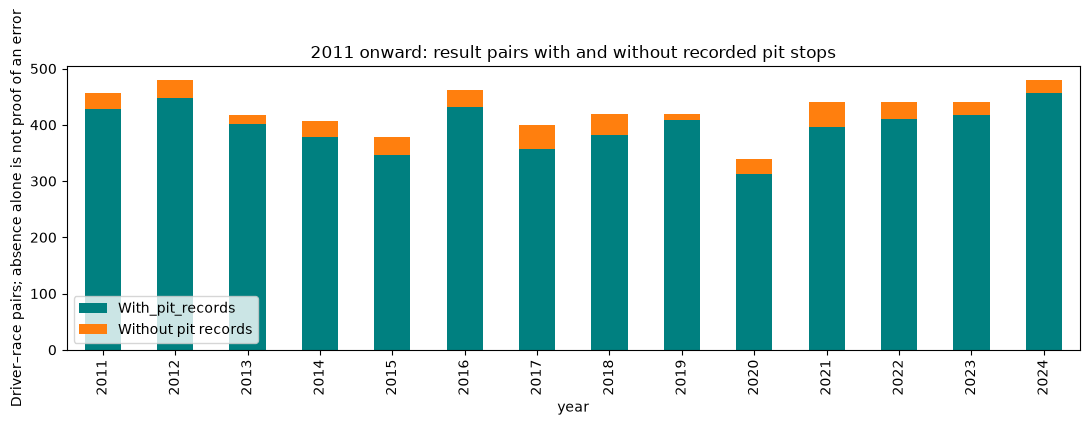

In [105]:
pit_coverage_audit = results[["raceId", "driverId"]].drop_duplicates().merge(
    races[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
)
pit_coverage_audit = pit_coverage_audit.loc[pit_coverage_audit["year"].ge(2011)].merge(
    pit_pairs, on=["raceId", "driverId"], how="left", validate="one_to_one", indicator=True
)
pit_coverage_audit["Has pit records"] = pit_coverage_audit["_merge"].eq("both")
pit_annual_coverage = pit_coverage_audit.groupby("year").agg(
    Result_pairs=("driverId", "size"), With_pit_records=("Has pit records", "sum")
)
pit_annual_coverage["Without pit records"] = pit_annual_coverage["Result_pairs"] - pit_annual_coverage["With_pit_records"]
display(pit_annual_coverage)
display(pit_coverage_audit.loc[~pit_coverage_audit["Has pit records"],
    ["raceId", "driverId", "year", "name"]].head(5))
pit_annual_coverage[["With_pit_records", "Without pit records"]].plot.bar(
    stacked=True, figsize=(11, 4), color=["teal", "tab:orange"]
)
plt.title("2011 onward: result pairs with and without recorded pit stops")
plt.ylabel("Driver–race pairs; absence alone is not proof of an error")
plt.tight_layout()
plt.show()


### Explain the three cross-table flags and show the decision

All three flags are Hülkenberg's stops on laps **25, 27 and 29** in São Paulo 2024, compared with the original result total of **0**. The [FIA sector analysis](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf), page 11, lists 30 completed laps. This is the **same case investigated in the lap-times section**, not three new independent errors. The later results correction normalizes his completed-lap total to 30 while retaining the disqualification. Disqualification is not proof of zero physical laps. The evidence supports a completed-lap normalization, rather than a claim that zero cannot occur in an official classification. No pit-stop value needs changing.

The table below compares the original result value with the source-supported completed-lap total. It is an evidence table; `results_clean` is created and corrected later in notebook order. The final verification of this audit also checks against that later clean table.


In [106]:
pit_lap_evidence = pit_result_lap_flags[["raceId", "driverId", "stop", "lap", "laps"]].copy()
pit_lap_evidence = pit_lap_evidence.rename(columns={"laps": "Raw result laps"})
pit_lap_evidence["Verified completed laps"] = 30
pit_lap_evidence["Within verified total"] = pit_lap_evidence["lap"].le(pit_lap_evidence["Verified completed laps"])
pit_lap_evidence["Decision"] = "Keep pit record; result total is handled in the results section"
display(pit_lap_evidence)
assert pit_lap_evidence["Within verified total"].all()

# Prove that this audit did not change, insert or delete any pit-stop records.
pit_expected = pit_stops.copy(deep=True).replace(r"\N", np.nan)
pit_expected["milliseconds"] = pd.to_numeric(pit_expected["milliseconds"], errors="raise")
pit_expected["duration"] = pit_expected["milliseconds"] / 1000
pit_expected["time"] = pd.to_timedelta(pit_expected["time"], errors="raise").astype("timedelta64[ns]")
pd.testing.assert_frame_equal(pit_stops_clean, pit_expected)
print("Preserved all pit-stop values and rows except the documented duration and clock typing.")


,raceId,driverId,stop,lap,Raw result laps,Verified completed laps,Within verified total,Decision
11210,1141,807,1,25,0,30,True,Keep pit record; result total is handled in th...
11223,1141,807,2,27,0,30,True,Keep pit record; result total is handled in th...
11226,1141,807,3,29,0,30,True,Keep pit record; result total is handled in th...


Preserved all pit-stop values and rows except the documented duration and clock typing.


### Pit-stop audit findings within the requested scope

All 11,371 rows and seven columns are preserved. Missing-value, key, type and reference checks pass. The cross-table rules are applied to every relevant record, not to hand-picked drivers. They find three pit-lap/recorded-result-total exceptions belonging to one driver–race case: Hülkenberg in São Paulo 2024. The FIA timing evidence supports 30 completed laps; the existing results correction handles this case, keeping disqualification unchanged. Clock readings are preserved while converting their representation from strings to pandas-native offsets since midnight; duration remains numeric seconds. No stop/lap values are changed.

The other cross-table checks pass. This does not prove that every pit-stop record is correct. Unusual stop numbering, isolated long durations and absent pit-stop pairs are not labeled as errors or used for additional individual investigations in this workflow. No missing stop rows are reconstructed, stop/lap values are not swapped, and no extra columns are added to the clean table. Current-race pit-stop data remains excluded from pre-race inputs.


In [107]:
pit_final_checks = pd.Series({
    "Row count unchanged": len(pit_stops_clean) == len(pit_stops),
    "No remaining placeholders": not pit_stops_clean.eq(r"\N").any().any(),
    "Key non-null": pit_stops_clean[["raceId", "driverId", "stop"]].notna().all().all(),
    "Key unique": not pit_stops_clean.duplicated(["raceId", "driverId", "stop"]).any(),
    "Clock values preserved": pit_stops_clean["time"].equals(
        pd.to_timedelta(pit_stops["time"].replace(r"\N", np.nan), errors="raise").astype("timedelta64[ns]")
    ),
    "Clock uses pandas timedelta dtype": pd.api.types.is_timedelta64_dtype(pit_stops_clean["time"]),
    "duration is numeric seconds": pd.api.types.is_numeric_dtype(pit_stops_clean["duration"]),
    "Duration missingness preserved": pit_stops_clean["duration"].isna().sum() == pit_stops["duration"].replace(r"\N", np.nan).isna().sum(),
    "Clock missingness preserved": pit_stops_clean["time"].isna().sum() == pit_stops["time"].replace(r"\N", np.nan).isna().sum()
})
display(pit_final_checks.to_frame("Passed"))
assert pit_final_checks.all(), "Investigate failed pit-stop checks."


,Passed
Row count unchanged,True
No remaining placeholders,True
Key non-null,True
Key unique,True
Clock values preserved,True
Clock uses pandas timedelta dtype,True
duration is numeric seconds,True
Duration missingness preserved,True
Clock missingness preserved,True


In [108]:
pit_stops_clean.info()
assert pit_stops_clean.columns.equals(pit_stops.columns), "Unexpected added or removed pit columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype          
---  ------        --------------  -----          
 0   raceId        11371 non-null  int64          
 1   driverId      11371 non-null  int64          
 2   stop          11371 non-null  int64          
 3   lap           11371 non-null  int64          
 4   time          11371 non-null  timedelta64[ns]
 5   duration      11371 non-null  float64        
 6   milliseconds  11371 non-null  int64          
dtypes: float64(1), int64(5), timedelta64[ns](1)
memory usage: 622.0 KB


## 3.6 constructor_standings.csv 

### 3.6.1 Constructor Standings: Initial Loading & Baseline
Loading the dataset while immediately parsing `\N` sentinels into missing values, and inspecting the initial column structure and data types.

In [109]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [110]:
constructor_standings_clean  =  pd.read_csv(DATA_DIR / "constructor_standings.csv",na_values=[r"\N"]) 
constructor_standings_clean.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [111]:
constructor_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


### 3.6.2 Constructor Standings: Relational Integrity & Key Validation
Validating the primary index (`constructorStandingsId`) and composite keys (`raceId`, `constructorId`) for strict uniqueness. This ensures no duplicate standings exist for a single team in a single race, and verifies that every record maps correctly to the established `races` and `constructors` reference tables.

In [112]:
# Check the record ID.
record_id = "constructorStandingsId"

print("Missing constructorStandingsId:",
      constructor_standings_clean[record_id].isna().sum())

print("Duplicate constructorStandingsId:",
      constructor_standings_clean[record_id].duplicated().sum())

assert constructor_standings_clean[record_id].notna().all(), \
    "Missing constructorStandingsId found"

assert constructor_standings_clean[record_id].is_unique, \
    "Duplicate constructorStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_standings_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_standings_clean.duplicated(pair_columns).sum())

assert constructor_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorStandingsId: 0
Duplicate constructorStandingsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [113]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_standings_clean[
    constructor_standings_clean["raceId"].isna()
    | ~constructor_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_standings_clean[
    constructor_standings_clean["constructorId"].isna()
    | ~constructor_standings_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


## 3.7 constructors.csv


### 3.7.1 Constructors: Initial Loading & Baseline
Loading the constructors dataset, automatically replacing `\N` placeholders with standard missing values during import, and reviewing the baseline column structure.

In [114]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [115]:
constructors_clean  =  pd.read_csv(DATA_DIR / "constructors.csv",na_values=[r"\N"]) 
constructors_clean.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [116]:
constructors_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


### 3.7.2 Constructors: Primary Key Validation
Verifying the integrity of the `constructorId` to guarantee that every team has a strictly unique, non-null identifier before it is used in cross-table relational merges.

In [117]:
# Check the record ID.
record_id = "constructorId"

print("Missing constructorId:",
      constructors_clean[record_id].isna().sum())

print("Duplicate constructorId:",
      constructors_clean[record_id].duplicated().sum())

assert constructors_clean[record_id].notna().all(), \
    "Missing constructorId found"

assert constructors_clean[record_id].is_unique, \
    "Duplicate constructorId found"


Missing constructorId: 0
Duplicate constructorId: 0


## 3.8 driver_standings.csv


### 3.8.1 Driver Standings: Initial Loading & Baseline
Loading the driver standings dataset, automatically converting `\N` sentinels into standard missing values during import, and inspecting the baseline column structure and data types.

In [118]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [119]:
driver_standings_clean  =  pd.read_csv(DATA_DIR / "driver_standings.csv",na_values=[r"\N"]) 
driver_standings_clean.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [120]:
driver_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


### 3.8.2 Driver Standings: Relational Integrity & Key Validation
Validating the primary index (`driverStandingsId`) and composite keys (`raceId`, `driverId`) for strict uniqueness. This ensures no duplicate standings exist for a single driver in a single race, and verifies that every record maps correctly to the established `races` and `drivers` reference tables.

In [121]:
# Check the record ID.
record_id = "driverStandingsId"

print("Missing driverStandingsId:",
      driver_standings_clean[record_id].isna().sum())

print("Duplicate driverStandingsId:",
      driver_standings_clean[record_id].duplicated().sum())

assert driver_standings_clean[record_id].notna().all(), \
    "Missing driverStandingsId found"

assert driver_standings_clean[record_id].is_unique, \
    "Duplicate driverStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "driverId"]

print("\nMissing race and driver IDs:")
display(driver_standings_clean[pair_columns].isna().sum())

print("Duplicate race–driver pairs:",
      driver_standings_clean.duplicated(pair_columns).sum())

assert driver_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or driverID found"

assert not driver_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–driver pairs found"

print("\nPassed: record IDs and race–drivers pairs are unique and non-null.")

Missing driverStandingsId: 0
Duplicate driverStandingsId: 0

Missing race and driver IDs:


raceId      0
driverId    0
dtype: int64

Duplicate race–driver pairs: 0

Passed: record IDs and race–drivers pairs are unique and non-null.


In [122]:
# Find rows with missing or unknown race IDs.
invalid_races = driver_standings_clean[
    driver_standings_clean["raceId"].isna()
    | ~driver_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_drivers = driver_standings_clean[
    driver_standings_clean["driverId"].isna()
    | ~driver_standings_clean["driverId"].isin(
        drivers["driverId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown drivers IDs:", len(invalid_drivers))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_drivers.empty:
    display(invalid_drivers)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_drivers.empty, \
    "Some drivers IDs are missing or absent from drivers"

print("Passed: all race and drivers IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown drivers IDs: 0
Passed: all race and drivers IDs exist in their reference tables.


## 3.9 qualifying.csv

### 3.9.1 Qualifying: Baseline Setup & Time Conversion
Loading the dataset with strict NA overrides to prevent Pandas from silently masking formatting anomalies. This phase establishes the baseline and explicitly converts the textual `q1`, `q2`, and `q3` lap times into strict numeric seconds.

In [123]:
print("shape:", qualifying.shape)
print("columns:", list(qualifying.columns))
qualifying.head()

shape: (10494, 9)
columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3']


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [124]:
before = pd.DataFrame({
    "sentinel (\\N)": (qualifying == r"\N").sum(),
    "blank ('')":     (qualifying == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qualifying)).round(2)
before

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,0,4625,44.07
q3,6819,0,6819,64.98


In [125]:
# Every cell kept as exact text, so we see what is really in the file
qual_txt = pd.read_csv(DATA_DIR / "qualifying.csv", dtype=str, keep_default_na=False)
# What the notebook's `qualifying` already is (default NA handling)
qual_default = pd.read_csv(DATA_DIR / "qualifying.csv")

# Cells pandas turned into NaN on its own, i.e. not the \N sentinel
hidden = qual_default.isna() & (qual_txt != r"\N")
counts = hidden.sum()
print("hidden missing cells per column:")
print(counts[counts > 0])

# What text was actually in those cells?
for col in counts[counts > 0].index:
    print(col, qual_txt.loc[hidden[col], col].map(repr).value_counts().to_dict())

# Which rows are they in?
qual_txt.loc[hidden.any(axis=1), ["qualifyId", "raceId", "q1", "q2", "q3"]]

hidden missing cells per column:
q2    22
q3    46
dtype: int64
q2 {"''": 22}
q3 {"''": 46}


,qualifyId,raceId,q1,q2,q3
10005,10063,1120,1:24.437,1:24.359,
10006,10064,1120,1:24.565,1:24.391,
10007,10065,1120,1:24.405,1:24.422,
10008,10066,1120,1:24.298,1:24.439,
10009,10067,1120,1:24.461,1:24.442,
10010,10068,1120,1:24.738,,
10011,10069,1120,1:24.764,,
10012,10070,1120,1:24.788,,
10013,10071,1120,1:25.159,,
10045,10103,1122,1:28.984,1:28.642,


In [126]:
# Before: count the exact text in the file, so nothing is hidden
before = pd.DataFrame({
    "sentinel (\\N)": (qual_txt == r"\N").sum(),
    "blank ('')":     (qual_txt == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qual_txt)).round(2)

# Clean copy: only \N and blank count as missing, nothing else is guessed
qualifying_clean = pd.read_csv(DATA_DIR / "qualifying.csv",
                               keep_default_na=False, na_values=[r"\N", ""])

check = pd.DataFrame({"missing_before": before["total missing"],
                      "NaN_after": qualifying_clean.isnull().sum()})
check["match"] = check["missing_before"] == check["NaN_after"]
display(before); display(check)
assert check["match"].all()

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,22,4647,44.28
q3,6819,46,6865,65.42


,missing_before,NaN_after,match
qualifyId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,0,0,True
position,0,0,True
q1,156,156,True
q2,4647,4647,True
q3,6865,6865,True


In [127]:
qualifying_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [128]:
qualifying_clean.isnull().sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64

In [129]:
def to_seconds(t):
    if pd.isna(t):
        return np.nan

    # Accept seconds, minutes:seconds, or hours:minutes:seconds.
    # A leading + marks a gap; its numeric value is still seconds.
    parts = str(t).strip().lstrip("+").split(":")
    if not 1 <= len(parts) <= 3:
        raise ValueError(f"Unexpected duration: {t}")

    values = [float(part) for part in parts]
    if not all(np.isfinite(value) and value >= 0 for value in values):
        raise ValueError(f"Invalid duration: {t}")
    if any(value >= 60 for value in values[1:]):
        raise ValueError(f"Invalid minutes or seconds: {t}")

    seconds = 0.0
    for value in values:
        seconds = seconds * 60 + value
    return seconds

# Replace values in the existing columns. Rerunning is safe.
for col in ["q1", "q2", "q3"]:
    qualifying_clean[col] = qualifying_clean[col].map(to_seconds)

qualifying_clean[["q1", "q2", "q3"]].head()


,q1,q2,q3
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079
3,85.994,85.691,87.178
4,85.960,85.518,87.236


In [130]:
# Compare missingness with the original columns after conversion.
for col in ["q1", "q2", "q3"]:
    original_missing = qualifying[col].replace(r"\N", np.nan).isna()
    assert original_missing.equals(qualifying_clean[col].isna())
    assert pd.api.types.is_numeric_dtype(qualifying_clean[col])
    print(col, "converted to numeric seconds; missingness preserved")


q1 converted to numeric seconds; missingness preserved
q2 converted to numeric seconds; missingness preserved
q3 converted to numeric seconds; missingness preserved


### 3.9.2 Qualifying: Relational Keys & Session Logic
Validating primary and foreign keys against the race, driver, and constructor reference tables. This section also introduces an era-specific sequence audit (2006 onward) to flag impossible session combinations, such as a driver logging a Q3 time without a Q2 time.

In [131]:
n_dup = qualifying_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("duplicate (raceId, driverId) pairs:", n_dup)

duplicate (raceId, driverId) pairs: 0


In [132]:
print("qualifyId unique  :", qualifying_clean["qualifyId"].is_unique)
print("qualifyId no nulls:", qualifying_clean["qualifyId"].notna().all())

qualifyId unique  : True
qualifyId no nulls: True


In [133]:
races_ids        = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId"])["constructorId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids)]:
    orphans = int((~qualifying_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"qualifying.{col}", "points to": parent,
                 "null values": int(qualifying_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,qualifying.raceId,races.raceId,0,0,True
1,qualifying.driverId,drivers.driverId,0,0,True
2,qualifying.constructorId,constructors.constructorId,0,0,True


In [134]:
# Q1 -> Q2 -> Q3. Check recorded times, not whether a driver participated.
# Apply these comparisons only to the three-session era (2006 onward).
qualifying_session_check = qualifying_clean.merge(
    races[["raceId", "year"]], on="raceId", validate="many_to_one"
)
qualifying_session_check = qualifying_session_check.loc[qualifying_session_check["year"] >= 2006]

q2_without_q1 = qualifying_session_check["q2"].notna() & qualifying_session_check["q1"].isna()
q3_without_q2 = qualifying_session_check["q3"].notna() & qualifying_session_check["q2"].isna()
q3_without_q1 = qualifying_session_check["q3"].notna() & qualifying_session_check["q1"].isna()

qualifying_session_counts = pd.DataFrame({
    "Check": ["Q2 recorded, Q1 missing", "Q3 recorded, Q2 missing", "Q3 recorded, Q1 missing"],
    "Records to investigate": [q2_without_q1.sum(), q3_without_q2.sum(), q3_without_q1.sum()]
})
display(qualifying_session_counts)
qualifying_session_exceptions = qualifying_session_check.loc[
    q2_without_q1 | q3_without_q2 | q3_without_q1,
    ["qualifyId", "raceId", "driverId", "year", "position", "q1", "q2", "q3"]
]
if not qualifying_session_exceptions.empty:
    display(qualifying_session_exceptions)
# An exception would need investigation, not automatic filling or deletion.


,Check,Records to investigate
0,"Q2 recorded, Q1 missing",0
1,"Q3 recorded, Q2 missing",0
2,"Q3 recorded, Q1 missing",0


### Qualifying: discover problems before changing values

One row describes one driver's qualifying result in a race. `qualifyId` is the primary key; `(raceId, driverId)` should also be unique. `number` is the car number, **not** the finishing position. Qualifying `position` and race `grid` can differ after penalties, so they are not required to match.

We compare **every qualifying row** with the same race and driver in `results`. A disagreement is a reason to investigate, not proof of which table is wrong. We check official records before choosing a correction. All audit tables below are separate variables; the clean table keeps its original nine columns.

### 3.9.3 Qualifying: Cross-Table Consistency & Edge Cases
Cross-referencing qualifying records directly with race results to expose constructor-ID and car-number disagreements. This includes applying evidence-backed, manual resolutions for known historical discrepancies (such as the 2015 Marussia constructor mismatch and verified official car number corrections).

,Before correction
Qualifying pair absent from results,0
Constructor disagreements,10
Car-number disagreements,32


,qualifyId,raceId,year,name,driverId,surname,number_qualifying,number_results
0,434,38,2007,Bahrain Grand Prix,27,Albers,12,21
1,1417,104,2004,Italian Grand Prix,47,Baumgartner,20,21
2,1418,104,2004,Italian Grand Prix,46,Bruni,21,20
3,1442,125,2002,Malaysian Grand Prix,23,Schumacher,3,5
4,1655,177,1999,San Marino Grand Prix,69,Badoer,22,20
5,1668,191,1998,Australian Grand Prix,68,Takagi,20,21
6,1676,191,1998,Australian Grand Prix,44,Panis,14,11
7,1686,192,1998,Brazilian Grand Prix,44,Panis,14,11
8,1712,193,1998,Argentine Grand Prix,68,Takagi,18,21
9,1742,199,1998,British Grand Prix,23,Schumacher,9,10


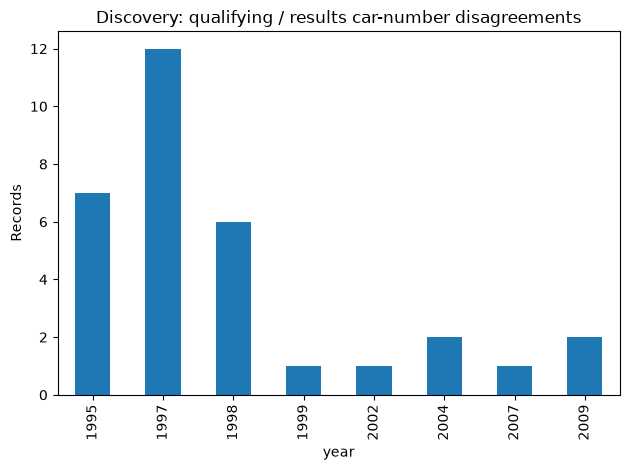

In [135]:
import hashlib
qualifying_csv_hash_before = hashlib.sha256((DATA_DIR / "qualifying.csv").read_bytes()).hexdigest()
qualifying_raw_snapshot = qualifying.copy(deep=True)
qualifying_audit_before = qualifying_clean.copy(deep=True)

# Restrict results to relevant pairs before checking join uniqueness.
# Older results elsewhere can contain shared-drive records.
qualifying_result_reference = results.merge(
    qualifying_audit_before[["raceId", "driverId"]],
    on=["raceId", "driverId"], validate="many_to_one"
)[["raceId", "driverId", "constructorId", "number"]].copy()
assert not qualifying_result_reference.duplicated(["raceId", "driverId"]).any()
qualifying_result_reference["number"] = pd.to_numeric(qualifying_result_reference["number"], errors="raise")
qualifying_cross_before = qualifying_audit_before.merge(
    qualifying_result_reference, on=["raceId", "driverId"], how="left",
    suffixes=("_qualifying", "_results"), indicator=True, validate="one_to_one"
)
qualifying_number_disagreements = qualifying_cross_before.loc[
    qualifying_cross_before["_merge"].eq("both") &
    qualifying_cross_before["number_qualifying"].ne(qualifying_cross_before["number_results"])
].merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one").merge(
    drivers[["driverId", "surname"]], on="driverId", validate="many_to_one"
)
qualifying_discovery_counts = pd.Series({
    "Qualifying pair absent from results": qualifying_cross_before["_merge"].eq("left_only").sum(),
    "Constructor disagreements": qualifying_cross_before["constructorId_qualifying"].ne(qualifying_cross_before["constructorId_results"]).sum(),
    "Car-number disagreements": len(qualifying_number_disagreements)
}, name="Before correction")
display(qualifying_discovery_counts.to_frame())
with pd.option_context("display.max_rows", None):
    display(qualifying_number_disagreements[["qualifyId", "raceId", "year", "name", "driverId", "surname", "number_qualifying", "number_results"]])
qualifying_number_disagreements.groupby("year").size().plot.bar(title="Discovery: qualifying / results car-number disagreements", ylabel="Records")
plt.tight_layout(); plt.show()


### Resolve the ten qualifying–race constructor-ID contradictions

**Discovery first:** the earlier driver-combination audit compared every qualifying `(raceId, driverId, constructorId)` against race results. It displayed ten mismatches: qualifying uses `206` (Marussia), while the same driver and race use `209` (Manor Marussia) in results. This is a cross-table identity inconsistency, not a problem with the drivers' biographies.

**Evidence:** the official F1 qualifying and race classifications for Belgium, Russia, USA, Mexico and Brazil 2015 all list the affected drivers under **Marussia Ferrari** in both sessions. The [FIA Brazil qualifying page](https://www.fia.com/events/fia-formula-one-world-championship/season-2015/qualifying-classifications-14) also names Stevens and Rossi's entrant **Manor Marussia F1 Team**. This supports the same participating team across sessions; there is no evidence here of a team change between qualifying and the race.

Official websites do not assign our database IDs. **Choosing `209` is a documented database harmonization decision:** all 36 relevant 2015 result records use `209`, and 25 other qualifying records already use `209`. The source observations below contain the driver/car identities and links for every affected event; the code checks these against the exact local records before changing anything. We do not claim `206` is an invalid constructor in every season.

**Action:** change only the ten reviewed `qualifying_clean.constructorId` cells from `206` to the existing `209`. Preserve `drivers_clean`, both constructor records, raw data and every other qualifying value. The table and plot below show ten original mismatches becoming zero.


Qualifying rows screened: 10494
Original constructor mismatches: 10


,qualifyId,raceId,driverId,Official surname,Official car number,Official qualifying team,Official race team,Qualifying source,Race source,Before constructorId,number qualifying,After constructorId,number race,surname,year,name
0,6522,937,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/928/belgium/qualifying,https://www.formula1.com/en/results/2015/races/928/belgium/race-result,206,28,209,28,Stevens,2015,Belgian Grand Prix
1,6523,937,833,Merhi,98,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/928/belgium/qualifying,https://www.formula1.com/en/results/2015/races/928/belgium/race-result,206,98,209,98,Merhi,2015,Belgian Grand Prix
2,6601,941,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/932/russia/qualifying,https://www.formula1.com/en/results/2015/races/932/russia/race-result,206,28,209,28,Stevens,2015,Russian Grand Prix
3,6602,941,833,Merhi,98,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/932/russia/qualifying,https://www.formula1.com/en/results/2015/races/932/russia/race-result,206,98,209,98,Merhi,2015,Russian Grand Prix
4,6620,942,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/933/united-states/qualifying,https://www.formula1.com/en/results/2015/races/933/united-states/race-result,206,53,209,53,Rossi,2015,United States Grand Prix
5,6621,942,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/933/united-states/qualifying,https://www.formula1.com/en/results/2015/races/933/united-states/race-result,206,28,209,28,Stevens,2015,United States Grand Prix
6,6640,943,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/934/mexico/qualifying,https://www.formula1.com/en/results/2015/races/934/mexico/race-result,206,53,209,53,Rossi,2015,Mexican Grand Prix
7,6641,943,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/934/mexico/qualifying,https://www.formula1.com/en/results/2015/races/934/mexico/race-result,206,28,209,28,Stevens,2015,Mexican Grand Prix
8,6660,944,834,Rossi,53,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/935/brazil/qualifying,https://www.formula1.com/en/results/2015/races/935/brazil/race-result,206,53,209,53,Rossi,2015,Brazilian Grand Prix
9,6661,944,829,Stevens,28,Marussia Ferrari,Marussia Ferrari,https://www.formula1.com/en/results/2015/races/935/brazil/qualifying,https://www.formula1.com/en/results/2015/races/935/brazil/race-result,206,28,209,28,Stevens,2015,Brazilian Grand Prix


,Qualifying before,Race results
constructorId,,
206,10,0
209,25,36


,Constructor-ID mismatches
Before,10
After,0


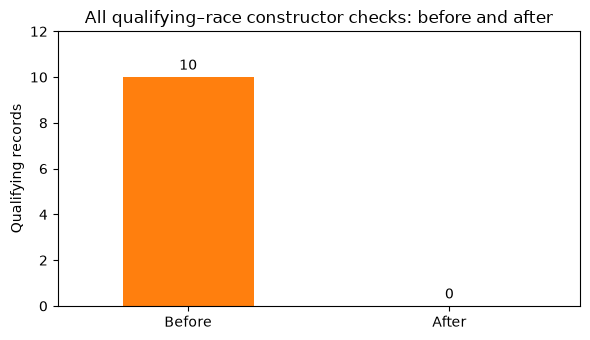

In [136]:
# Manually reviewed official observations; links make each event check reviewable.
qualifying_team_sources = {
    937: "https://www.formula1.com/en/results/2015/races/928/belgium/",
    941: "https://www.formula1.com/en/results/2015/races/932/russia/",
    942: "https://www.formula1.com/en/results/2015/races/933/united-states/",
    943: "https://www.formula1.com/en/results/2015/races/934/mexico/",
    944: "https://www.formula1.com/en/results/2015/races/935/brazil/"
}
qualifying_team_evidence = pd.DataFrame([
    (6522, 937, 829, "Stevens", 28), (6523, 937, 833, "Merhi", 98),
    (6601, 941, 829, "Stevens", 28), (6602, 941, 833, "Merhi", 98),
    (6620, 942, 834, "Rossi", 53), (6621, 942, 829, "Stevens", 28),
    (6640, 943, 834, "Rossi", 53), (6641, 943, 829, "Stevens", 28),
    (6660, 944, 834, "Rossi", 53), (6661, 944, 829, "Stevens", 28)
], columns=["qualifyId", "raceId", "driverId", "Official surname", "Official car number"])
qualifying_team_evidence["Official qualifying team"] = "Marussia Ferrari"
qualifying_team_evidence["Official race team"] = "Marussia Ferrari"
qualifying_team_evidence["Qualifying source"] = qualifying_team_evidence["raceId"].map(qualifying_team_sources) + "qualifying"
qualifying_team_evidence["Race source"] = qualifying_team_evidence["raceId"].map(qualifying_team_sources) + "race-result"

qualifying_team_before = qualifying_clean.copy(deep=True)
team_result_triples = results[["raceId", "driverId", "constructorId"]].drop_duplicates()
team_before_audit = qualifying_team_before.merge(
    team_result_triples, on=["raceId", "driverId", "constructorId"],
    how="left", validate="many_to_one", indicator=True
)
team_before_conflicts = team_before_audit.loc[team_before_audit["_merge"].eq("left_only")]
assert set(team_before_conflicts["qualifyId"]) == set(qualifying_team_evidence["qualifyId"])
print("Qualifying rows screened:", len(qualifying_team_before))
print("Original constructor mismatches:", len(team_before_conflicts))

qualifying_team_evidence = qualifying_team_evidence.merge(
    qualifying_team_before[["qualifyId", "raceId", "driverId", "constructorId", "number"]],
    on=["qualifyId", "raceId", "driverId"], validate="one_to_one"
).rename(columns={"constructorId": "Before constructorId"}).merge(
    results.merge(qualifying_team_evidence[["raceId", "driverId"]],
        on=["raceId", "driverId"], validate="many_to_one")[["raceId", "driverId", "constructorId", "number"]],
    on=["raceId", "driverId"], validate="one_to_one", suffixes=(" qualifying", " race")
).rename(columns={"constructorId": "After constructorId"}).merge(
    drivers[["driverId", "surname"]], on="driverId", validate="many_to_one"
).merge(races[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert qualifying_team_evidence["Before constructorId"].eq(206).all()
assert qualifying_team_evidence["After constructorId"].eq(209).all()
assert qualifying_team_evidence["surname"].eq(qualifying_team_evidence["Official surname"]).all()
for column in ["number qualifying", "number race"]:
    assert pd.to_numeric(qualifying_team_evidence[column]).eq(qualifying_team_evidence["Official car number"]).all()
assert qualifying_team_evidence["year"].eq(2015).all()
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(qualifying_team_evidence)

# Display how the database already identifies this 2015 entrant.
season_race_ids = races.loc[races["year"].eq(2015), "raceId"]
team_season_counts = pd.DataFrame({
    "Qualifying before": qualifying_team_before.loc[
        qualifying_team_before["raceId"].isin(season_race_ids) & qualifying_team_before["constructorId"].isin([206, 209]),
        "constructorId"].value_counts(),
    "Race results": results.loc[
        results["raceId"].isin(season_race_ids) & results["constructorId"].isin([206, 209]),
        "constructorId"].value_counts()
}).fillna(0).astype(int)
display(team_season_counts)
assert team_season_counts.loc[209, "Race results"] == 36
assert team_season_counts.loc[206, "Race results"] == 0

# Change only the supported IDs, never every occurrence of 206.
team_replacements = qualifying_team_evidence.set_index("qualifyId")["After constructorId"]
team_change_mask = qualifying_clean["qualifyId"].isin(team_replacements.index)
qualifying_clean.loc[team_change_mask, "constructorId"] = qualifying_clean.loc[
    team_change_mask, "qualifyId"].map(team_replacements)
team_after_audit = qualifying_clean.merge(
    team_result_triples, on=["raceId", "driverId", "constructorId"],
    how="left", validate="many_to_one", indicator=True
)
team_after_conflicts = team_after_audit.loc[team_after_audit["_merge"].eq("left_only")]
assert team_after_conflicts.empty
pd.testing.assert_frame_equal(qualifying_team_before.drop(columns="constructorId"), qualifying_clean.drop(columns="constructorId"))
assert qualifying_clean["constructorId"].ne(qualifying_team_before["constructorId"]).sum() == 10
assert qualifying_clean["constructorId"].isin(constructors["constructorId"]).all()
assert qualifying_clean["qualifyId"].is_unique
assert not qualifying_clean.duplicated(["raceId", "driverId"]).any()
team_comparison = pd.Series({"Before": len(team_before_conflicts), "After": len(team_after_conflicts)})
display(team_comparison.to_frame("Constructor-ID mismatches"))
ax = team_comparison.plot.bar(figsize=(6, 3.5), color=["tab:orange", "teal"], rot=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylabel("Qualifying records")
ax.set_title("All qualifying–race constructor checks: before and after")
ax.set_ylim(0, 12)
plt.tight_layout()
plt.show()


### Verify the car numbers, then correct only confirmed disagreements

The general comparison above found **32 disagreements across 24 races**. The official F1 qualifying pages list the driver's name and car number. The source table below records the number read from each page, alongside both CSV values. All 32 official numbers agree with `results`, so only those 32 `qualifying_clean.number` cells are corrected. We do not overwrite all qualifying numbers from another table.

For example, [1998 Australian qualifying](https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0) lists Takagi as **21** and Panis as **11**; our qualifying CSV records **20** and **14**. [2002 Malaysian qualifying](https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0) lists Ralf Schumacher as **5**, while our qualifying CSV records **3**. The full source list is displayed below. The earlier ten constructor-ID corrections are retained.

,qualifyId,year,name,surname,number_qualifying,number_results,Official number,Official qualifying source
0,434,2007,Bahrain Grand Prix,Albers,12,21,21,https://www.formula1.com/en/results/2007/races/810/bahrain/qualifying
1,1417,2004,Italian Grand Prix,Baumgartner,20,21,21,https://www.formula1.com/en/results/2004/races/767/italy/qualifying
2,1418,2004,Italian Grand Prix,Bruni,21,20,20,https://www.formula1.com/en/results/2004/races/767/italy/qualifying
3,1442,2002,Malaysian Grand Prix,Schumacher,3,5,5,https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0
4,1655,1999,San Marino Grand Prix,Badoer,22,20,20,https://www.formula1.com/en/results/1999/races/689/san-marino/qualifying
5,1668,1998,Australian Grand Prix,Takagi,20,21,21,https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0
6,1676,1998,Australian Grand Prix,Panis,14,11,11,https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0
7,1686,1998,Brazilian Grand Prix,Panis,14,11,11,https://www.formula1.com/en/results/1998/races/672/brazil/qualifying
8,1712,1998,Argentine Grand Prix,Takagi,18,21,21,https://www.formula1.com/en/results/1998/races/673/argentina/qualifying
9,1742,1998,British Grand Prix,Schumacher,9,10,10,https://www.formula1.com/en/results/1998/races/679/great-britain/qualifying/0


,Before,After
Qualifying pair absent from results,0,0
Constructor disagreements,10,0
Car-number disagreements,32,0


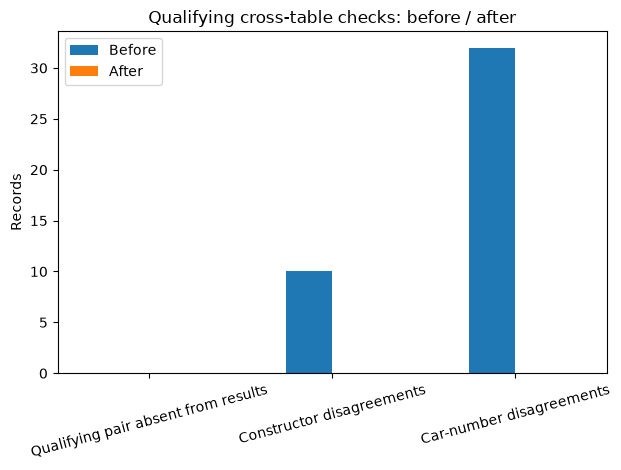

In [137]:
# These are manually checked observations from official qualifying pages.
qualifying_official_numbers = pd.DataFrame([(434, 21), (1417, 21), (1418, 20), (1442, 5), (1655, 20), (1668, 21), (1676, 11), (1686, 11), (1712, 21), (1742, 10), (1778, 18), (1910, 19), (1918, 18), (1923, 9), (1932, 19), (1937, 18), (1954, 18), (1957, 19), (1980, 18), (1981, 19), (1995, 7), (2025, 19), (2026, 18), (2212, 2), (2235, 2), (2287, 25), (2376, 4), (2438, 25), (2460, 25), (2591, 17), (3016, 6), (3045, 21)], columns=["qualifyId", "Official number"])
qualifying_number_sources = {'2': 'https://www.formula1.com/en/results/2009/races/844/malaysia/qualifying', '3': 'https://www.formula1.com/en/results/2009/races/845/china/qualifying', '38': 'https://www.formula1.com/en/results/2007/races/810/bahrain/qualifying', '104': 'https://www.formula1.com/en/results/2004/races/767/italy/qualifying', '125': 'https://www.formula1.com/en/results/2002/races/721/malaysia/qualifying/0', '177': 'https://www.formula1.com/en/results/1999/races/689/san-marino/qualifying', '191': 'https://www.formula1.com/en/results/1998/races/671/australia/qualifying/0', '192': 'https://www.formula1.com/en/results/1998/races/672/brazil/qualifying', '193': 'https://www.formula1.com/en/results/1998/races/673/argentina/qualifying', '199': 'https://www.formula1.com/en/results/1998/races/679/great-britain/qualifying/0', '201': 'https://www.formula1.com/en/results/1998/races/681/germany/qualifying', '211': 'https://www.formula1.com/en/results/1997/races/658/monaco/qualifying', '212': 'https://www.formula1.com/en/results/1997/races/659/spain/qualifying/0', '213': 'https://www.formula1.com/en/results/1997/races/660/canada/qualifying', '214': 'https://www.formula1.com/en/results/1997/races/661/france/qualifying/0', '215': 'https://www.formula1.com/en/results/1997/races/662/great-britain/qualifying/0', '216': 'https://www.formula1.com/en/results/1997/races/663/germany/qualifying', '241': 'https://www.formula1.com/en/results/1995/races/622/argentina/qualifying', '242': 'https://www.formula1.com/en/results/1995/races/623/san-marino/qualifying', '244': 'https://www.formula1.com/en/results/1995/races/625/monaco/qualifying', '247': 'https://www.formula1.com/en/results/1995/races/628/great-britain/qualifying', '250': 'https://www.formula1.com/en/results/1995/races/631/belgium/qualifying', '251': 'https://www.formula1.com/en/results/1995/races/632/italy/qualifying', '256': 'https://www.formula1.com/en/results/1995/races/637/australia/qualifying'}
qualifying_number_evidence = qualifying_number_disagreements.merge(
    qualifying_official_numbers, on="qualifyId", validate="one_to_one"
)
assert set(qualifying_number_disagreements["qualifyId"]) == set(qualifying_official_numbers["qualifyId"])
qualifying_number_evidence["Official qualifying source"] = qualifying_number_evidence["raceId"].astype(str).map(qualifying_number_sources)
assert qualifying_number_evidence["Official qualifying source"].notna().all()
assert qualifying_number_evidence["Official number"].eq(qualifying_number_evidence["number_results"]).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", 120):
    display(qualifying_number_evidence[["qualifyId", "year", "name", "surname", "number_qualifying", "number_results", "Official number", "Official qualifying source"]])

qualifying_before_number_fix = qualifying_clean.copy(deep=True)
number_corrections = qualifying_official_numbers.set_index("qualifyId")["Official number"]
number_fix_mask = qualifying_clean["qualifyId"].isin(number_corrections.index)
qualifying_clean.loc[number_fix_mask, "number"] = qualifying_clean.loc[number_fix_mask, "qualifyId"].map(number_corrections)
pd.testing.assert_frame_equal(qualifying_before_number_fix.drop(columns="number"), qualifying_clean.drop(columns="number"))
pd.testing.assert_frame_equal(qualifying_before_number_fix.loc[~number_fix_mask], qualifying_clean.loc[~number_fix_mask])
qualifying_cross_after = qualifying_clean.merge(
    qualifying_result_reference, on=["raceId", "driverId"], how="left",
    suffixes=("_qualifying", "_results"), indicator=True, validate="one_to_one"
)
qualifying_consistency_change = pd.DataFrame({
    "Before": qualifying_discovery_counts,
    "After": [qualifying_cross_after["_merge"].eq("left_only").sum(),
              qualifying_cross_after["constructorId_qualifying"].ne(qualifying_cross_after["constructorId_results"]).sum(),
              qualifying_cross_after["number_qualifying"].ne(qualifying_cross_after["number_results"]).sum()]
})
display(qualifying_consistency_change)
qualifying_consistency_change.plot.bar(title="Qualifying cross-table checks: before / after", ylabel="Records", rot=15)
plt.tight_layout(); plt.show()


### Missing qualifying times: what the checks mean

The order is **Q1 -> Q2 -> Q3**. We compare Q2 with Q1, Q3 with Q2, and Q3 with Q1 in the three-session era. The direct Q3/Q1 check is redundant when the two adjacent checks pass, but is included so all three comparisons are visible. The results table is shown earlier, before the identity corrections.

These checks look for a recorded later-session time with an earlier time missing. They do not prove participation or explain every missing value. A recorded Q1 with missing Q2/Q3, or recorded Q1/Q2 with missing Q3, is not by itself a contradiction.

`NaN` means **no recorded time**. Possible reasons include earlier elimination, no valid lap, a cancelled session, a different historical format, or incomplete coverage. We do not assign one of those reasons to an individual record without evidence. Q1/Q2/Q3 times alone cannot establish which reason applies.

Both `\N` and blank strings become `NaN`; the before/after counts below verify that no missing values were lost or introduced during conversion. Times remain numeric seconds in the existing columns. The yearly coverage table and chart show how missingness varies through history. The separate results-pair coverage table shows absent qualifying records; absence alone is not an error flag.

**Missing-data treatment remains pending discussion.** No zero, median, invented time, row removal or missing indicator is added here. Passing these consistency checks does not mean there are no missing values.


### 3.9.4 Qualifying: Missing Data Coverage & Final Validation
Visualizing missing data trends across different seasons to distinguish between true errors and expected historical sparsity (e.g., gaps in older eras). Concludes with a comprehensive suite of strict assertion tests to guarantee dataset integrity before moving forward.

,Raw sentinel,Raw blank,Clean missing,Raw type,Clean type
qualifyId,0,0,0,object,int64
raceId,0,0,0,object,int64
driverId,0,0,0,object,int64
constructorId,0,0,0,object,int64
number,0,0,0,object,int64
position,0,0,0,object,int64
q1,156,0,156,object,float64
q2,4625,22,4647,object,float64
q3,6819,46,6865,object,float64


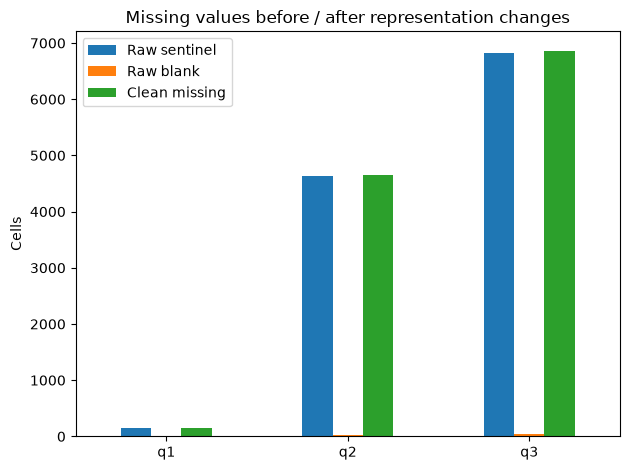

,Raw q1,Clean q1 (seconds)
0,1:26.572,86.572
1,1:26.103,86.103
2,1:25.664,85.664
3,1:25.994,85.994
4,1:25.960,85.960


,q1,q2,q3
year,,,
1994,0.26,100.00,100.00
1995,5.74,100.00,100.00
1996,2.03,100.00,100.00
1997,0.45,100.00,100.00
1998,1.31,100.00,100.00
1999,1.54,100.00,100.00
2000,0.00,100.00,100.00
2001,0.00,100.00,100.00
2002,0.00,100.00,100.00


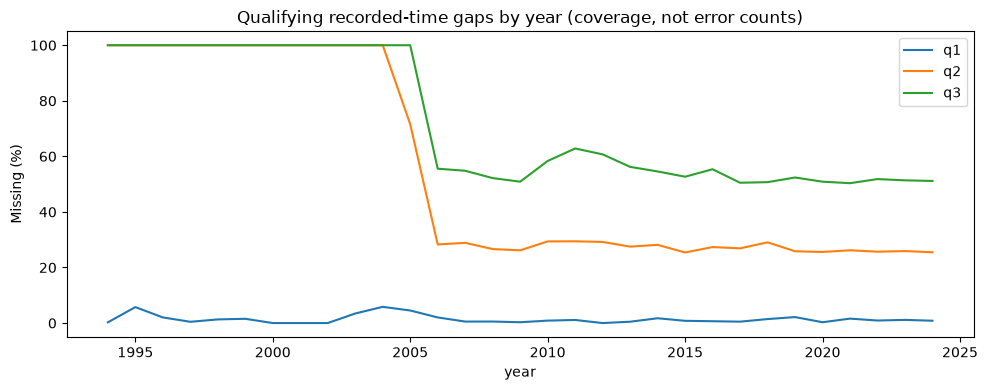

,Results pairs,Pairs without qualifying row,Missing fraction
year,,,
1950,156,156,1.000000
1951,175,175,1.000000
1952,212,212,1.000000
1953,230,230,1.000000
1954,213,213,1.000000
...,...,...,...
2020,340,0,0.000000
2021,440,1,0.002273
2022,440,0,0.000000


In [138]:
qualifying_missing_evidence = pd.DataFrame({
    "Raw sentinel": qual_txt.eq(r"\N").sum(),
    "Raw blank": qual_txt.apply(lambda col: col.str.strip().eq("").sum()),
    "Clean missing": qualifying_clean.isna().sum(),
    "Raw type": qual_txt.dtypes.astype(str),
    "Clean type": qualifying_clean.dtypes.astype(str)
})
display(qualifying_missing_evidence)
assert (qualifying_missing_evidence["Raw sentinel"] + qualifying_missing_evidence["Raw blank"]).eq(qualifying_missing_evidence["Clean missing"]).all()
qualifying_missing_evidence.loc[["q1", "q2", "q3"], ["Raw sentinel", "Raw blank", "Clean missing"]].plot.bar(title="Missing values before / after representation changes", ylabel="Cells", rot=0)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Raw q1": qual_txt["q1"].head(), "Clean q1 (seconds)": qualifying_clean["q1"].head()}))
qualifying_missing_by_year = qualifying_clean.merge(races[["raceId", "year"]], on="raceId", validate="many_to_one").groupby("year")[["q1", "q2", "q3"]].agg(lambda col: col.isna().mean() * 100)
display(qualifying_missing_by_year.round(2))
qualifying_missing_by_year.plot(title="Qualifying recorded-time gaps by year (coverage, not error counts)", ylabel="Missing (%)", figsize=(10, 4))
plt.tight_layout(); plt.show()
# Look in both directions: are some results pairs absent from qualifying?
qualifying_coverage = results[["raceId", "driverId"]].drop_duplicates().merge(
    qualifying_clean[["raceId", "driverId"]], on=["raceId", "driverId"], how="left", indicator=True, validate="one_to_one"
).merge(races[["raceId", "year"]], on="raceId", validate="many_to_one")
qualifying_coverage["Qualifying row absent"] = qualifying_coverage["_merge"].eq("left_only")
qualifying_coverage_by_year = qualifying_coverage.groupby("year")["Qualifying row absent"].agg(["size", "sum", "mean"])
qualifying_coverage_by_year.columns = ["Results pairs", "Pairs without qualifying row", "Missing fraction"]
display(qualifying_coverage_by_year)


In [139]:
qualifying_checks = []
def add_qualifying_check(check, violations):
    qualifying_checks.append({"Check": check, "Violations": int(violations), "Status": "DONE" if violations == 0 else "NEEDS INVESTIGATION"})

add_qualifying_check("Full duplicate rows", qualifying_clean.duplicated().sum())
add_qualifying_check("Duplicate primary keys", qualifying_clean["qualifyId"].duplicated().sum())
add_qualifying_check("Duplicate race / driver pairs", qualifying_clean.duplicated(["raceId", "driverId"]).sum())
add_qualifying_check("Repeated qualifying position within race (observed)", qualifying_clean.duplicated(["raceId", "position"]).sum())
required_qualifying = ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"]
add_qualifying_check("Missing required fields", qualifying_clean[required_qualifying].isna().sum().sum())
for col in required_qualifying:
    values = pd.to_numeric(qualifying_clean[col], errors="coerce")
    # Car number 0 is permitted; IDs and positions must be positive integers.
    invalid = values.isna() | ~np.isfinite(values) | values.mod(1).ne(0) | (values.lt(0) if col == "number" else values.le(0))
    add_qualifying_check(col + ": invalid integer value", invalid.sum())
for col, parent in [("raceId", races), ("driverId", drivers), ("constructorId", constructors)]:
    add_qualifying_check(col + ": missing foreign-key target", (~qualifying_clean[col].isin(parent[col])).sum())
for col in ["q1", "q2", "q3"]:
    values = qualifying_clean[col].dropna()
    add_qualifying_check(col + ": non-positive or non-finite seconds", ((values <= 0) | ~np.isfinite(values)).sum())
    assert pd.api.types.is_numeric_dtype(qualifying_clean[col])
add_qualifying_check("Remaining literal sentinels or blanks", qualifying_clean.astype(str).apply(lambda col: col.str.strip().isin([r"\N", ""])).sum().sum())
for check, count in qualifying_consistency_change["After"].items():
    add_qualifying_check(check, count)
assert list(qualifying_clean.columns) == list(qualifying.columns)
assert len(qualifying_clean) == len(qualifying)
pd.testing.assert_frame_equal(qualifying, qualifying_raw_snapshot)
assert qualifying_csv_hash_before == hashlib.sha256((DATA_DIR / "qualifying.csv").read_bytes()).hexdigest()
qualifying_final_checks = pd.DataFrame(qualifying_checks)
display(qualifying_final_checks)
assert qualifying_final_checks["Violations"].eq(0).all()
print("PASS: all rows and original nine columns retained; raw DataFrame and CSV unchanged.")


,Check,Violations,Status
0,Full duplicate rows,0,DONE
1,Duplicate primary keys,0,DONE
2,Duplicate race / driver pairs,0,DONE
3,Repeated qualifying position within race (obse...,0,DONE
4,Missing required fields,0,DONE
5,qualifyId: invalid integer value,0,DONE
6,raceId: invalid integer value,0,DONE
7,driverId: invalid integer value,0,DONE
8,constructorId: invalid integer value,0,DONE
9,number: invalid integer value,0,DONE


PASS: all rows and original nine columns retained; raw DataFrame and CSV unchanged.


### Qualifying: nine requested checks

| Requirement | Status | Evidence |
|---|---|---|
| 1. Within-table and cross-table checks | PARTIALLY DONE | General checks cover every row; all discovered team and car-number disagreements have source evidence. The three recorded-session comparisons are shown earlier. Individual missing-value causes and treatment remain incomplete. |
| 2. Evidence and visualizations | DONE | Full disagreement tables, official source links, before/after mismatch plot, missing-value representation plot, and yearly coverage evidence. |
| 3. Duplicates and required identifiers | DONE | Final check table tests full rows, primary keys, race/driver pairs, observed race/position duplicates and required fields. All pass. |
| 4. Placeholder missing values | DONE | Both sentinel and blank counts reconcile exactly to clean missing counts. |
| 5. Semantic types | DONE | Integer IDs, car numbers and positions; q1/q2/q3 numeric seconds in their existing columns. No date field in this table. |
| 6. Primary and foreign keys | DONE | Unique non-null qualifyId; raceId, driverId and constructorId reference existing parent records. |
| 7. Consistency discovery before correction | DONE | Full-table comparison shown before corrections; team disagreements 10 → 0 and car-number disagreements 32 → 0. |
| 8. Raw data unchanged | DONE | Raw DataFrame equality and CSV hash checks; only qualifying_clean is corrected. |
| 9. Objective evidence only | DONE | Corrections follow cross-table contradictions plus official qualifying records. Missing session times, historical coverage gaps, grid differences and unusual positive times are not automatically error flags. |

**Qualifying-time decision for this project:** Keep unavailable q1/q2/q3 times as recognized missing values in `qualifying_clean`; do not invent session times in the source table. The selected E3 feature set excludes these columns. The optional qualifying model versions fit median imputation on training rows, then transform validation/test rows. The coverage audit remains partially complete because the exact reason for every historical absence has not been verified.

**Limit:** We have not verified an individual cause for every absent qualifying row or missing session time. These remain explicitly documented coverage limitations, not invented corrections or proven errors. The audit passing does not mean the source is complete or that every value has been independently verified.

### Races table: cleaning evidence and validation

One row represents one race. `raceId` is its primary key and `(year, round)` identifies a round within a season. `circuitId` references circuits and `year` references seasons. Multiple races at the same circuit are allowed.

The flow is: inspect raw values → show type conversions → check constraints and related tables → discover schedule gaps → compare official evidence → fill 88 verified 2021 scheduled times and correct two Monaco dates → show before/after and preservation checks. All corrections affect `races_clean` only; the original rows and columns are retained.


## 3.10 races.csv

### 3.10.1 Races: Initial Auditing & Time Conversions
Establishing the baseline snapshot, quantifying raw placeholders (`\N` and blanks), and safely casting schedule columns to strict `datetime` and `timedelta` (clock offset) formats.

Raw rows / columns: (1125, 18)


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


,sentinel (\N),Blank strings,% missing
raceId,0,0,0.00
year,0,0,0.00
round,0,0,0.00
circuitId,0,0,0.00
name,0,0,0.00
date,0,0,0.00
time,731,0,64.98
url,0,0,0.00
fp1_date,1035,0,92.00
fp1_time,1057,0,93.96


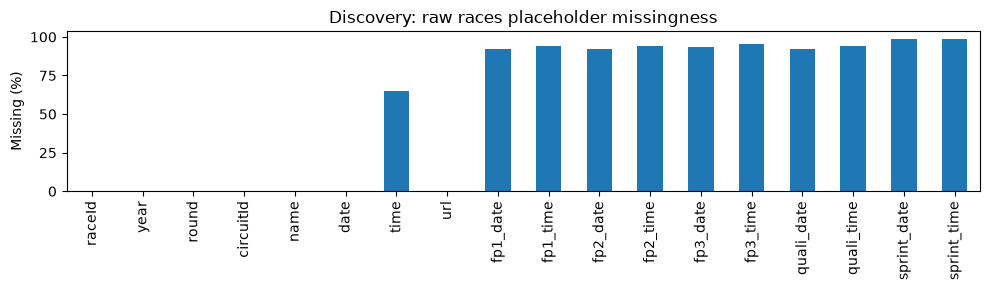

In [140]:
import hashlib
races_raw_snapshot = races.copy(deep=True)
races_csv_hash_before = hashlib.sha256((DATA_DIR / "races.csv").read_bytes()).hexdigest()
races_text = pd.read_csv(DATA_DIR / "races.csv", dtype=str, keep_default_na=False)
print("Raw rows / columns:", races.shape)
display(races.head())
before_r = pd.DataFrame({"sentinel (\\N)": races_text.eq(r"\N").sum()})
before_r["Blank strings"] = races_text.apply(lambda col: col.str.strip().eq("").sum())
before_r["% missing"] = before_r[["sentinel (\\N)", "Blank strings"]].sum(axis=1) / len(races) * 100
display(before_r.round(2))
before_r["% missing"].plot.bar(figsize=(10, 3), title="Discovery: raw races placeholder missingness", ylabel="Missing (%)")
plt.tight_layout(); plt.show()


#### 1. Show the existing cleaning before and after

Literal `\N` placeholders become proper missing values. Dates become datetime values; time-of-day columns become timedeltas measured from midnight. These clock values are not lap durations. A displayed `0 days` is normal because a time of day fits within one day.

The tables below check that conversion did not silently create missing values. A conversion failure would be displayed for investigation rather than filled or corrected by this audit.


,sentinel_before,NaN_after,match
raceId,0,0,True
year,0,0,True
round,0,0,True
circuitId,0,0,True
name,0,0,True
date,0,0,True
time,731,731,True
url,0,0,True
fp1_date,1035,1035,True
fp1_time,1057,1057,True


,Before type,After type,Missing before,Missing after,New missing from conversion
raceId,int64,int64,0,0,0
year,int64,int64,0,0,0
round,int64,int64,0,0,0
circuitId,int64,int64,0,0,0
name,object,object,0,0,0
date,object,datetime64[ns],0,0,0
time,object,timedelta64[ns],731,731,0
url,object,object,0,0,0
fp1_date,object,datetime64[ns],1035,1035,0
fp1_time,object,timedelta64[ns],1057,1057,0


,raceId,date before,date after,time before,time after,fp1_date before,fp1_date after,fp1_time before,fp1_time after
1036,1074,2022-03-20,2022-03-20,15:00:00,0 days 15:00:00,2022-03-18,2022-03-18,12:00:00,0 days 12:00:00
1058,1075,2022-03-27,2022-03-27,17:00:00,0 days 17:00:00,2022-03-25,2022-03-25,14:00:00,0 days 14:00:00
1059,1076,2022-04-10,2022-04-10,05:00:00,0 days 05:00:00,2022-04-08,2022-04-08,03:00:00,0 days 03:00:00
1060,1077,2022-04-24,2022-04-24,13:00:00,0 days 13:00:00,2022-04-22,2022-04-22,11:30:00,0 days 11:30:00
1061,1078,2022-05-08,2022-05-08,19:30:00,0 days 19:30:00,2022-05-06,2022-05-06,18:30:00,0 days 18:30:00


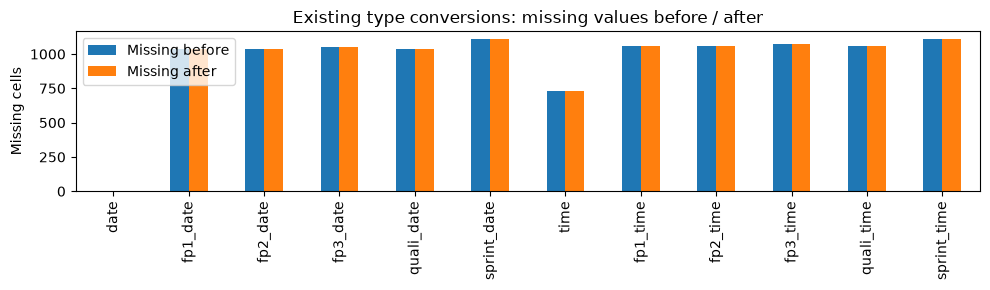

,Rows,Columns,Placeholder / missing cells
Raw,1125,18,11349
Clean,1125,18,11349


In [141]:
# Retain the existing cleaning operations and the existing column names.
races_clean = pd.read_csv(DATA_DIR / "races.csv", keep_default_na=False, na_values=[r"\N"])
races_before_types = races_clean.copy(deep=True)
check_r = pd.DataFrame({"sentinel_before": before_r["sentinel (\\N)"], "NaN_after": races_clean.isna().sum()})
check_r["match"] = check_r["sentinel_before"].eq(check_r["NaN_after"])
display(check_r)
date_cols = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_cols:
    races_clean[col] = pd.to_datetime(races_clean[col], errors="coerce")
time_columns = ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]
for column in time_columns:
    races_clean[column] = pd.to_timedelta(races_clean[column], errors="raise")

races_type_evidence = pd.DataFrame({
    "Before type": races_before_types.dtypes.astype(str),
    "After type": races_clean.dtypes.astype(str),
    "Missing before": races_before_types.isna().sum(),
    "Missing after": races_clean.isna().sum()
})
races_type_evidence["New missing from conversion"] = races_type_evidence["Missing after"] - races_type_evidence["Missing before"]
display(races_type_evidence)
for col in date_cols + time_columns:
    failed = races_before_types[col].notna() & races_clean[col].isna()
    if failed.any():
        print("Conversion needs investigation:", col)
        display(races_before_types.loc[failed, ["raceId", "year", "name", col]])
races_conversion_examples = pd.DataFrame({"raceId": races_clean["raceId"]})
for col in ["date", "time", "fp1_date", "fp1_time"]:
    races_conversion_examples[col + " before"] = races_before_types[col]
    races_conversion_examples[col + " after"] = races_clean[col]
example_mask = races_before_types["time"].notna() & races_before_types["fp1_time"].notna()
display(races_conversion_examples.loc[example_mask].head(5))
races_missing_comparison = races_type_evidence.loc[date_cols + time_columns, ["Missing before", "Missing after"]]
races_missing_comparison.plot.bar(figsize=(10, 3), title="Existing type conversions: missing values before / after", ylabel="Missing cells")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Rows": [len(races), len(races_clean)], "Columns": [races.shape[1], races_clean.shape[1]],
                      "Placeholder / missing cells": [int(before_r["sentinel (\\N)"].sum()), int(races_clean.isna().sum().sum())]}, index=["Raw", "Clean"]))


#### 2. Within-table constraints

We check full duplicate rows, the primary key, the season/round combination, required fields, positive integer identifiers, date/year agreement, clock ranges and round sequencing. The exception table shows any records found by each rule.

**Do not require raceId to be chronological:** it is an identifier. Race order is checked using year, round and date. Missing optional schedule values are reported separately, not automatically treated as invalid records.


### 3.10.2 Races: Data Integrity & Calendar Sequencing
Validating core structural rules (no duplicate IDs, required fields exist) and auditing the calendar logic to flag non-contiguous season rounds or dates that impossibly move backwards mid-season.

In [142]:
races_checks = []
races_exception_tables = {}
def record_races_check(label, mask):
    mask = mask.fillna(False)
    races_checks.append({"Check": label, "Records": int(mask.sum()), "Result": "PASS" if not mask.any() else "INVESTIGATE"})
    if mask.any():
        races_exception_tables[label] = races_clean.loc[mask].copy()
        print(label)
        display(races_exception_tables[label])

record_races_check("Full duplicate rows", races_clean.duplicated(keep=False))
record_races_check("Duplicate raceId", races_clean.duplicated("raceId", keep=False))
record_races_check("Duplicate year / round", races_clean.duplicated(["year", "round"], keep=False))
required_races = ["raceId", "year", "round", "circuitId", "name", "date", "url"]
record_races_check("Missing required fields", races_clean[required_races].isna().any(axis=1))
record_races_check("Blank required names / URLs", races_clean[["name", "url"]].apply(lambda col: col.str.strip().eq("")).any(axis=1))
for col in ["raceId", "year", "round", "circuitId"]:
    values = pd.to_numeric(races_clean[col], errors="coerce")
    record_races_check(col + ": invalid positive integer", values.isna() | ~np.isfinite(values) | values.le(0) | values.mod(1).ne(0))
record_races_check("Race date does not match year", races_clean["date"].notna() & races_clean["year"].ne(races_clean["date"].dt.year))
record_races_check("Literal sentinel or blank still present", races_clean.astype(str).apply(lambda col: col.str.strip().isin([r"\N", ""])).any(axis=1))
for col in time_columns:
    record_races_check(col + ": clock outside one day", races_clean[col].notna() & (races_clean[col].lt(pd.Timedelta(0)) | races_clean[col].ge(pd.Timedelta(days=1))))

rounds = races_clean.groupby("year")["round"].agg(n_races="count", first="min", last="max")
rounds["gap"] = rounds["last"] - rounds["n_races"]
races_round_exceptions = rounds.loc[rounds["first"].ne(1) | rounds["gap"].ne(0)]
print("Seasons with non-contiguous rounds:", len(races_round_exceptions))
display(races_round_exceptions)
races_in_round_order = races_clean.sort_values(["year", "round"])
races_date_reversals = races_in_round_order.loc[races_in_round_order.groupby("year")["date"].diff().lt(pd.Timedelta(0))]
print("Dates moving backwards as season rounds increase:", len(races_date_reversals))
display(races_date_reversals[["raceId", "year", "round", "name", "date"]])
display(pd.DataFrame(races_checks))


Seasons with non-contiguous rounds:

 0


,n_races,first,last,gap
year,,,,


Dates moving backwards as season rounds increase: 0


,raceId,year,round,name,date


,Check,Records,Result
0,Full duplicate rows,0,PASS
1,Duplicate raceId,0,PASS
2,Duplicate year / round,0,PASS
3,Missing required fields,0,PASS
4,Blank required names / URLs,0,PASS
5,raceId: invalid positive integer,0,PASS
6,year: invalid positive integer,0,PASS
7,round: invalid positive integer,0,PASS
8,circuitId: invalid positive integer,0,PASS
9,Race date does not match year,0,PASS


#### 3. Relationships with other tables

First, check that the circuit and season referenced by each race exist. Then check race references from every related table in the opposite direction. These checks examine **all rows**, not hand-picked events.

A child row referring to a nonexistent race needs investigation. A race with no rows in a particular child table is only a coverage observation: older qualifying, timing and pit-stop data are incomplete, constructors' competition began later, and most races have no sprint. Absence does not by itself prove an error. Differences between sprint schedule coverage and sprint-result coverage are listed for review, not automatically corrected.


### 3.10.3 Races: Relational Mapping & Sprint Coverage
Verifying foreign keys against the parent reference tables, mapping child table coverage (ensuring lap times, results, etc., link to valid races), and auditing discrepancies between Sprint schedules and actual Sprint results.

In [143]:
races_fk_checks = []
for col, parent, parent_name in [("circuitId", circuits, "circuits"), ("year", seasons, "seasons")]:
    invalid = races_clean[col].notna() & ~races_clean[col].isin(parent[col])
    races_fk_checks.append({"Foreign key": col, "Parent": parent_name, "Missing identifiers": int(races_clean[col].isna().sum()), "Orphans": int(invalid.sum())})
    if invalid.any():
        display(races_clean.loc[invalid])
display(pd.DataFrame(races_fk_checks))

races_child_coverage = []
for table_name in ["results", "qualifying", "lap_times", "pit_stops", "sprint_results", "driver_standings", "constructor_standings", "constructor_results"]:
    child = globals()[table_name]
    absent_identifier = child["raceId"].isna()
    orphan = child["raceId"].notna() & ~child["raceId"].isin(races_clean["raceId"])
    races_child_coverage.append({"Table": table_name, "Missing raceId": int(absent_identifier.sum()), "Orphan rows": int(orphan.sum()),
                                 "Races with records": int(races_clean["raceId"].isin(child["raceId"]).sum()),
                                 "Races without records (coverage only)": int((~races_clean["raceId"].isin(child["raceId"])).sum())})
    if (absent_identifier | orphan).any():
        print("Reference needs investigation:", table_name)
        display(child.loc[absent_identifier | orphan])
display(pd.DataFrame(races_child_coverage))

races_sprint_coverage = races_clean[["raceId", "year", "name", "sprint_date"]].copy()
races_sprint_coverage["Has sprint results"] = races_sprint_coverage["raceId"].isin(sprint_results["raceId"])
races_sprint_coverage["Has sprint date"] = races_sprint_coverage["sprint_date"].notna()
races_sprint_coverage_review = races_sprint_coverage.loc[races_sprint_coverage["Has sprint results"].ne(races_sprint_coverage["Has sprint date"])]
print("Sprint schedule / result coverage differences to review:", len(races_sprint_coverage_review))
display(races_sprint_coverage_review)


,Foreign key,Parent,Missing identifiers,Orphans
0,circuitId,circuits,0,0
1,year,seasons,0,0


,Table,Missing raceId,Orphan rows,Races with records,Races without records (coverage only)
0,results,0,0,1125,0
1,qualifying,0,0,494,631
2,lap_times,0,0,544,581
3,pit_stops,0,0,285,840
4,sprint_results,0,0,18,1107
5,driver_standings,0,0,1125,0
6,constructor_standings,0,0,1061,64
7,constructor_results,0,0,1060,65


Sprint schedule / result coverage differences to review: 0


,raceId,year,name,sprint_date,Has sprint results,Has sprint date


#### 4. Schedule relationships and missing-value coverage

Check recorded session dates against the race date, and list clocks without corresponding dates. Also show dates whose clocks are missing; those are incomplete coverage, not proof that a session did not happen. Session dates may equal the race date, so same-day qualifying is allowed. We do not impose one modern weekend format on every historical event.

The missing-value summary covers all schedule date and clock columns. It describes the gaps; it does not fill them or claim that their individual causes have been established.


fp1: date without clock


,raceId,year,name,date,fp1_date,fp1_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-16,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-26,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-19,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-04-30,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-07,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-21,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-04,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-25,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-18,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-02,NaT


fp2: date without clock


,raceId,year,name,date,fp2_date,fp2_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-16,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-26,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-19,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-04-30,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-07,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-21,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-04,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-25,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-18,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-02,NaT


fp3: date without clock


...

,raceId,year,name,date,quali_date,quali_time
1035,1053,2021,Emilia Romagna Grand Prix,2021-04-18,2021-04-17,NaT
1037,1052,2021,Bahrain Grand Prix,2021-03-28,2021-03-27,NaT
1038,1051,2021,Qatar Grand Prix,2021-11-21,2021-11-20,NaT
1039,1054,2021,Portuguese Grand Prix,2021-05-02,2021-05-01,NaT
1040,1055,2021,Spanish Grand Prix,2021-05-09,2021-05-08,NaT
1041,1056,2021,Monaco Grand Prix,2021-05-23,2021-05-22,NaT
1042,1057,2021,Azerbaijan Grand Prix,2021-06-06,2021-06-05,NaT
1043,1058,2021,Styrian Grand Prix,2021-06-27,2021-06-26,NaT
1044,1059,2021,French Grand Prix,2021-06-20,2021-06-19,NaT
1045,1060,2021,Austrian Grand Prix,2021-07-04,2021-07-03,NaT


sprint: date without clock


,raceId,year,name,date,sprint_date,sprint_time
1046,1061,2021,British Grand Prix,2021-07-18,2021-07-17,NaT
1050,1065,2021,Italian Grand Prix,2021-09-12,2021-09-11,NaT
1055,1071,2021,São Paulo Grand Prix,2021-11-14,2021-11-13,NaT


,Session,Date after race (review),Clock without date (coverage review),Date without clock (coverage only)
0,fp1,0,0,22
1,fp2,0,0,22
2,fp3,0,0,19
3,quali,0,0,22
4,sprint,0,0,3


,Missing count,Missing (%)
date,0,0.00
fp1_date,1035,92.00
fp2_date,1035,92.00
fp3_date,1053,93.60
quali_date,1035,92.00
sprint_date,1107,98.40
time,731,64.98
fp1_time,1057,93.96
fp2_time,1057,93.96
fp3_time,1072,95.29


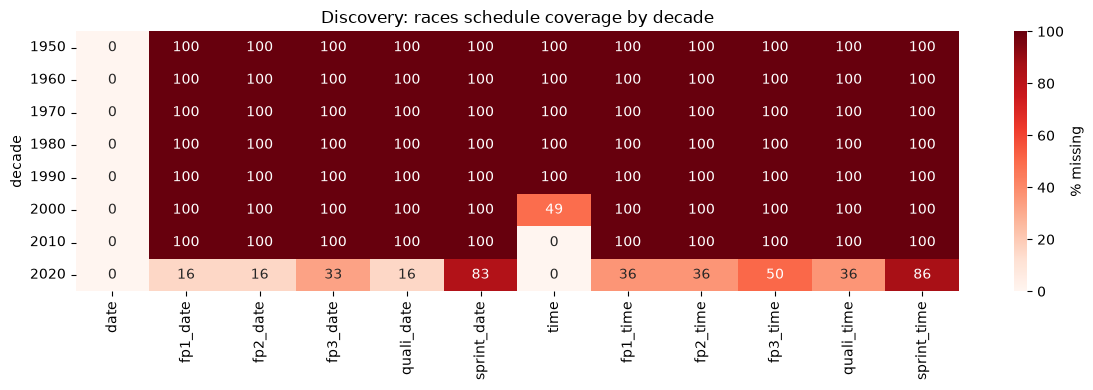

In [144]:
races_schedule_checks = []
races_schedule_review_tables = {}
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    date_col = session + "_date"
    time_col = session + "_time"
    after_race = races_clean[date_col].notna() & races_clean[date_col].gt(races_clean["date"])
    clock_without_date = races_clean[time_col].notna() & races_clean[date_col].isna()
    date_without_clock = races_clean[date_col].notna() & races_clean[time_col].isna()
    races_schedule_checks.append({"Session": session, "Date after race (review)": int(after_race.sum()),
                                  "Clock without date (coverage review)": int(clock_without_date.sum()),
                                  "Date without clock (coverage only)": int(date_without_clock.sum())})
    for label, mask in [("date after race", after_race), ("clock without date", clock_without_date), ("date without clock", date_without_clock)]:
        if mask.any():
            key = session + ": " + label
            races_schedule_review_tables[key] = races_clean.loc[mask, ["raceId", "year", "name", "date", date_col, time_col]].copy()
            print(key)
            display(races_schedule_review_tables[key])
display(pd.DataFrame(races_schedule_checks))
races_schedule_missing = pd.DataFrame({"Missing count": races_clean[date_cols + time_columns].isna().sum(),
                                       "Missing (%)": races_clean[date_cols + time_columns].isna().mean() * 100})
display(races_schedule_missing.round(2))
races_schedule_by_decade = races_clean.assign(decade=(races_clean["year"] // 10) * 10).groupby("decade")[date_cols + time_columns].agg(lambda col: col.isna().mean() * 100)
plt.figure(figsize=(12, 4))
sns.heatmap(races_schedule_by_decade, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.yticks(rotation=0)
plt.title("Discovery: races schedule coverage by decade")
plt.tight_layout(); plt.show()


#### 5. Recover the missing 2021 scheduled times using official evidence

**Meaning:** these fields contain scheduled session dates and start times in UTC. A scheduled time does not prove a session took place or started on time. We fill observed official schedule information, not averages or guesses.

We first check **all races and all five session pairs** for a date with no time. This discovers 88 gaps, all in 2021. Only then do we compare those gaps with official sources. The original historical gaps remain separate.

**Important exception:** Russia FP3 was cancelled. Its filled value is its **planned** start time, not an actual start. [Official cancellation report](https://www.formula1.com/en/latest/article/final-practice-session-for-the-russian-grand-prix-cancelled-due-to-heavy.5M2CsqmNkudVMRbsfu4EIT). No FP3 times are invented for Sprint weekends.


Session date exists but start time is missing: 88


,year,Session,Missing times
0,2021,fp1,22
1,2021,fp2,22
2,2021,fp3,19
3,2021,quali,22
4,2021,sprint,3


,raceId,year,name,Session,Date before,Time before
0,1053,2021,Emilia Romagna Grand Prix,fp1,2021-04-16,NaT
1,1052,2021,Bahrain Grand Prix,fp1,2021-03-26,NaT
2,1051,2021,Qatar Grand Prix,fp1,2021-11-19,NaT
3,1054,2021,Portuguese Grand Prix,fp1,2021-04-30,NaT
4,1055,2021,Spanish Grand Prix,fp1,2021-05-07,NaT
5,1056,2021,Monaco Grand Prix,fp1,2021-05-21,NaT
6,1057,2021,Azerbaijan Grand Prix,fp1,2021-06-04,NaT
7,1058,2021,Styrian Grand Prix,fp1,2021-06-25,NaT
8,1059,2021,French Grand Prix,fp1,2021-06-18,NaT
9,1060,2021,Austrian Grand Prix,fp1,2021-07-02,NaT


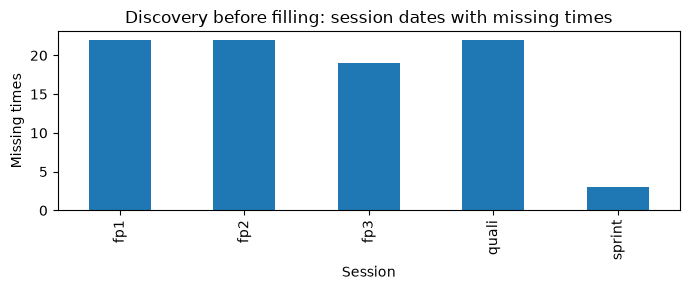

In [145]:
# Discover the gaps across the whole table before changing any values.
races_before_official_schedule = races_clean.copy(deep=True)
schedule_gaps = []
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    missing_time = races_clean[session + "_date"].notna() & races_clean[session + "_time"].isna()
    found = races_clean.loc[missing_time, ["raceId", "year", "name"]].copy()
    found["Session"] = session
    found["Date before"] = races_clean.loc[missing_time, session + "_date"]
    found["Time before"] = races_clean.loc[missing_time, session + "_time"]
    schedule_gaps.append(found)
schedule_gaps = pd.concat(schedule_gaps, ignore_index=True)
print("Session date exists but start time is missing:", len(schedule_gaps))
display(schedule_gaps.groupby(["year", "Session"]).size().rename("Missing times").reset_index())
with pd.option_context("display.max_rows", None):
    display(schedule_gaps)
schedule_gaps.groupby("Session").size().plot.bar(
    figsize=(7, 3), title="Discovery before filling: session dates with missing times", ylabel="Missing times")
plt.tight_layout(); plt.show()
assert len(schedule_gaps) == 88 and schedule_gaps["year"].eq(2021).all()


##### Compare each discovered gap with the official schedule

The small reference table below was transcribed from the 22 linked **official Formula 1 race pages**. The pages' structured schedule timestamps explicitly end in `Z`, meaning UTC. The code needs no internet connection when run on Kaggle.

The comparison covers all 88 gaps and also compares their existing dates. It discovers **two date disagreements**: Monaco FP1 and FP2 are recorded as 21 May, while the official schedule gives **20 May 2021**. These are corrected using the same sources, not by assuming every practice session happens on Friday.


### 3.10.5 Races: 2021 Schedule Reconstruction & Final Validation
Injecting officially verified UTC start times for the 2021 season to repair the identified schedule gaps. Concludes with a rigorous suite of assertion tests confirming that exactly 90 cells were updated without unintended data loss.

In [146]:
# Columns: race ID, official page, then the scheduled UTC start of each session.
official_2021_rows = [
    [1052, 'bahrain', '2021-03-26T11:30:00.000Z', '2021-03-26T15:00:00.000Z', '2021-03-27T12:00:00.000Z', '2021-03-27T15:00:00.000Z', None],
    [1053, 'emiliaromagna', '2021-04-16T09:00:00.000Z', '2021-04-16T12:30:00.000Z', '2021-04-17T09:00:00.000Z', '2021-04-17T12:00:00.000Z', None],
    [1054, 'portugal', '2021-04-30T10:30:00.000Z', '2021-04-30T14:00:00.000Z', '2021-05-01T11:00:00.000Z', '2021-05-01T14:00:00.000Z', None],
    [1055, 'spain', '2021-05-07T09:30:00.000Z', '2021-05-07T13:00:00.000Z', '2021-05-08T10:00:00.000Z', '2021-05-08T13:00:00.000Z', None],
    [1056, 'monaco', '2021-05-20T09:30:00.000Z', '2021-05-20T13:00:00.000Z', '2021-05-22T10:00:00.000Z', '2021-05-22T13:00:00.000Z', None],
    [1057, 'azerbaijan', '2021-06-04T08:30:00.000Z', '2021-06-04T12:00:00.000Z', '2021-06-05T09:00:00.000Z', '2021-06-05T12:00:00.000Z', None],
    [1059, 'france', '2021-06-18T09:30:00.000Z', '2021-06-18T13:00:00.000Z', '2021-06-19T10:00:00.000Z', '2021-06-19T13:00:00.000Z', None],
    [1058, 'styria', '2021-06-25T09:30:00.000Z', '2021-06-25T13:00:00.000Z', '2021-06-26T10:00:00.000Z', '2021-06-26T13:00:00.000Z', None],
    [1060, 'austria', '2021-07-02T09:30:00.000Z', '2021-07-02T13:00:00.000Z', '2021-07-03T10:00:00.000Z', '2021-07-03T13:00:00.000Z', None],
    [1061, 'great-britain', '2021-07-16T13:30:00.000Z', '2021-07-17T11:00:00.000Z', None, '2021-07-16T17:00:00.000Z', '2021-07-17T15:30:00.000Z'],
    [1062, 'hungary', '2021-07-30T09:30:00.000Z', '2021-07-30T13:00:00.000Z', '2021-07-31T10:00:00.000Z', '2021-07-31T13:00:00.000Z', None],
    [1063, 'belgium', '2021-08-27T09:30:00.000Z', '2021-08-27T13:00:00.000Z', '2021-08-28T10:00:00.000Z', '2021-08-28T13:00:00.000Z', None],
    [1064, 'netherlands', '2021-09-03T09:30:00.000Z', '2021-09-03T13:00:00.000Z', '2021-09-04T10:00:00.000Z', '2021-09-04T13:00:00.000Z', None],
    [1065, 'italy', '2021-09-10T12:30:00.000Z', '2021-09-11T10:00:00.000Z', None, '2021-09-10T16:00:00.000Z', '2021-09-11T14:30:00.000Z'],
    [1066, 'russia', '2021-09-24T08:30:00.000Z', '2021-09-24T12:00:00.000Z', '2021-09-25T09:00:00.000Z', '2021-09-25T12:00:00.000Z', None],
    [1067, 'turkey', '2021-10-08T08:30:00.000Z', '2021-10-08T12:00:00.000Z', '2021-10-09T09:00:00.000Z', '2021-10-09T12:00:00.000Z', None],
    [1069, 'united-states', '2021-10-22T16:30:00.000Z', '2021-10-22T20:00:00.000Z', '2021-10-23T18:00:00.000Z', '2021-10-23T21:00:00.000Z', None],
    [1070, 'mexico', '2021-11-05T17:30:00.000Z', '2021-11-05T21:00:00.000Z', '2021-11-06T17:00:00.000Z', '2021-11-06T20:00:00.000Z', None],
    [1071, 'brazil', '2021-11-12T15:30:00.000Z', '2021-11-13T15:00:00.000Z', None, '2021-11-12T19:00:00.000Z', '2021-11-13T19:30:00.000Z'],
    [1051, 'qatar', '2021-11-19T10:30:00.000Z', '2021-11-19T14:00:00.000Z', '2021-11-20T11:00:00.000Z', '2021-11-20T14:00:00.000Z', None],
    [1072, 'saudi-arabia', '2021-12-03T13:30:00.000Z', '2021-12-03T17:00:00.000Z', '2021-12-04T14:00:00.000Z', '2021-12-04T17:00:00.000Z', None],
    [1073, 'united-arab-emirates', '2021-12-10T09:30:00.000Z', '2021-12-10T13:00:00.000Z', '2021-12-11T10:00:00.000Z', '2021-12-11T13:00:00.000Z', None],
]
official_2021 = pd.DataFrame(official_2021_rows, columns=[
    "raceId", "page", "fp1", "fp2", "fp3", "quali", "sprint"])
official_2021["Source"] = "https://www.formula1.com/en/racing/2021/" + official_2021["page"]
official_schedule = official_2021.melt(
    id_vars=["raceId", "Source"], value_vars=["fp1", "fp2", "fp3", "quali", "sprint"],
    var_name="Session", value_name="Official start UTC").dropna(subset=["Official start UTC"])
official_schedule["Official start UTC"] = pd.to_datetime(official_schedule["Official start UTC"], utc=True)
official_schedule["Official date"] = official_schedule["Official start UTC"].dt.tz_localize(None).dt.normalize()
official_schedule["Official time UTC"] = pd.to_timedelta(official_schedule["Official start UTC"].dt.strftime("%H:%M:%S"))
official_schedule["Note"] = "Scheduled start, not actual start"
official_schedule.loc[
    official_schedule["raceId"].eq(1066) & official_schedule["Session"].eq("fp3"), "Note"
] = "CANCELLED: planned start only"

schedule_evidence = schedule_gaps.merge(official_schedule, on=["raceId", "Session"], how="left", validate="one_to_one")
assert len(schedule_evidence) == 88
assert schedule_evidence["Official start UTC"].notna().all()
schedule_evidence["Date matches"] = schedule_evidence["Date before"].eq(schedule_evidence["Official date"])
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(schedule_evidence[["raceId", "name", "Session", "Date before", "Official date", "Time before", "Official time UTC", "Note", "Source"]])
date_disagreements = schedule_evidence.loc[~schedule_evidence["Date matches"]]
print("Existing dates differing from official dates:", len(date_disagreements))
display(date_disagreements[["raceId", "name", "Session", "Date before", "Official date", "Source"]])
assert len(date_disagreements) == 2


,raceId,name,Session,Date before,Official date,Time before,Official time UTC,Note,Source
0,1053,Emilia Romagna Grand Prix,fp1,2021-04-16,2021-04-16,NaT,0 days 09:00:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/emiliaromagna
1,1052,Bahrain Grand Prix,fp1,2021-03-26,2021-03-26,NaT,0 days 11:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/bahrain
2,1051,Qatar Grand Prix,fp1,2021-11-19,2021-11-19,NaT,0 days 10:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/qatar
3,1054,Portuguese Grand Prix,fp1,2021-04-30,2021-04-30,NaT,0 days 10:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/portugal
4,1055,Spanish Grand Prix,fp1,2021-05-07,2021-05-07,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/spain
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/monaco
6,1057,Azerbaijan Grand Prix,fp1,2021-06-04,2021-06-04,NaT,0 days 08:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/azerbaijan
7,1058,Styrian Grand Prix,fp1,2021-06-25,2021-06-25,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/styria
8,1059,French Grand Prix,fp1,2021-06-18,2021-06-18,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/france
9,1060,Austrian Grand Prix,fp1,2021-07-02,2021-07-02,NaT,0 days 09:30:00,"Scheduled start, not actual start",https://www.formula1.com/en/racing/2021/austria


Existing dates differing from official dates: 2


,raceId,name,Session,Date before,Official date,Source
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,https://www.formula1.com/en/racing/2021/monaco
27,1056,Monaco Grand Prix,fp2,2021-05-21,2021-05-20,https://www.formula1.com/en/racing/2021/monaco


##### Apply only the verified corrections to the clean copy

Fill the missing clock for each discovered gap. Where its date disagrees with the official date, correct that date too. The evidence tables remain separate; **no columns are added to `races_clean`**.

Only 88 time cells and two Monaco date cells should change. The raw table, older missing schedules, and sessions with no scheduled date remain unchanged.


,raceId,Race,Session,Date before,Date after,Time before,Time after UTC,Note
0,1053,Emilia Romagna Grand Prix,fp1,2021-04-16,2021-04-16,NaT,0 days 09:00:00,"Scheduled start, not actual start"
1,1052,Bahrain Grand Prix,fp1,2021-03-26,2021-03-26,NaT,0 days 11:30:00,"Scheduled start, not actual start"
2,1051,Qatar Grand Prix,fp1,2021-11-19,2021-11-19,NaT,0 days 10:30:00,"Scheduled start, not actual start"
3,1054,Portuguese Grand Prix,fp1,2021-04-30,2021-04-30,NaT,0 days 10:30:00,"Scheduled start, not actual start"
4,1055,Spanish Grand Prix,fp1,2021-05-07,2021-05-07,NaT,0 days 09:30:00,"Scheduled start, not actual start"
5,1056,Monaco Grand Prix,fp1,2021-05-21,2021-05-20,NaT,0 days 09:30:00,"Scheduled start, not actual start"
6,1057,Azerbaijan Grand Prix,fp1,2021-06-04,2021-06-04,NaT,0 days 08:30:00,"Scheduled start, not actual start"
7,1058,Styrian Grand Prix,fp1,2021-06-25,2021-06-25,NaT,0 days 09:30:00,"Scheduled start, not actual start"
8,1059,French Grand Prix,fp1,2021-06-18,2021-06-18,NaT,0 days 09:30:00,"Scheduled start, not actual start"
9,1060,Austrian Grand Prix,fp1,2021-07-02,2021-07-02,NaT,0 days 09:30:00,"Scheduled start, not actual start"


,Missing before,Missing after
Session,,
fp1,22,0
fp2,22,0
fp3,19,0
quali,22,0
sprint,3,0


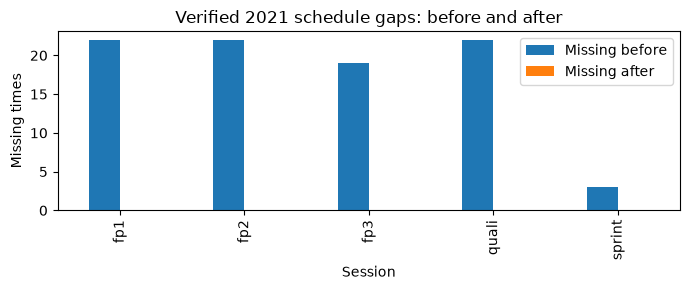

,Changed cells
fp1_date,1
fp1_time,22
fp2_date,1
fp2_time,22
fp3_time,19
quali_time,22
sprint_time,3


,Session,Check after filling,Records
0,fp1,Date after race,0
1,fp1,Time without date,0
2,fp1,Date without time,0
3,fp1,Clock outside one day,0
4,fp2,Date after race,0
5,fp2,Time without date,0
6,fp2,Date without time,0
7,fp2,Clock outside one day,0
8,fp3,Date after race,0
9,fp3,Time without date,0


PASS: 88 verified times filled; 2 Monaco dates corrected; other cells unchanged.
Russia FP3 remains documented as cancelled: its stored clock is scheduled, not actual.
Remaining missing schedule values across all years (not automatically errors):


,Still missing
date,0
fp1_date,1035
fp2_date,1035
fp3_date,1053
quali_date,1035
sprint_date,1107
time,731
fp1_time,1035
fp2_time,1035
fp3_time,1053


In [147]:
for _, record in schedule_evidence.iterrows():
    row = races_clean["raceId"].eq(record["raceId"])
    session = record["Session"]
    assert row.sum() == 1
    assert races_clean.loc[row, session + "_time"].isna().all()
    races_clean.loc[row, session + "_time"] = record["Official time UTC"]
    if not record["Date matches"]:
        races_clean.loc[row, session + "_date"] = record["Official date"]

# Show every changed session before and after.
schedule_after = []
for _, record in schedule_evidence.iterrows():
    row = races_clean.loc[races_clean["raceId"].eq(record["raceId"])].iloc[0]
    session = record["Session"]
    schedule_after.append({"raceId": record["raceId"], "Race": record["name"], "Session": session,
        "Date before": record["Date before"], "Date after": row[session + "_date"],
        "Time before": record["Time before"], "Time after UTC": row[session + "_time"], "Note": record["Note"]})
schedule_after = pd.DataFrame(schedule_after)
with pd.option_context("display.max_rows", None):
    display(schedule_after)

schedule_before_after = schedule_after.groupby("Session").agg(
    **{"Missing before": ("Time before", lambda col: col.isna().sum()),
       "Missing after": ("Time after UTC", lambda col: col.isna().sum())})
display(schedule_before_after)
schedule_before_after.plot.bar(figsize=(7, 3), title="Verified 2021 schedule gaps: before and after", ylabel="Missing times")
plt.tight_layout(); plt.show()

# Check exactly which cells changed, including missing values safely.
same_cells = races_before_official_schedule.eq(races_clean) | (races_before_official_schedule.isna() & races_clean.isna())
changed_cells = (~same_cells).sum()
display(changed_cells[changed_cells.gt(0)].rename("Changed cells").to_frame())
assert changed_cells.sum() == 90
assert changed_cells[["fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]].sum() == 88
assert changed_cells[["fp1_date", "fp2_date"]].sum() == 2
assert schedule_after["Time after UTC"].notna().all()
pd.testing.assert_frame_equal(races_clean.loc[races_clean["year"].ne(2021)], races_before_official_schedule.loc[races_clean["year"].ne(2021)])

# Repeat relevant schedule checks after the correction.
post_schedule_checks = []
for session in ["fp1", "fp2", "fp3", "quali", "sprint"]:
    dates = races_clean[session + "_date"]
    clocks = races_clean[session + "_time"]
    violations = {
        "Date after race": dates.gt(races_clean["date"]),
        "Time without date": clocks.notna() & dates.isna(),
        "Date without time": dates.notna() & clocks.isna(),
        "Clock outside one day": clocks.notna() & (clocks.lt(pd.Timedelta(0)) | clocks.ge(pd.Timedelta(days=1)))}
    for check, mask in violations.items():
        post_schedule_checks.append({"Session": session, "Check after filling": check, "Records": int(mask.sum())})
display(pd.DataFrame(post_schedule_checks))
assert all(check["Records"] == 0 for check in post_schedule_checks)
print("PASS: 88 verified times filled; 2 Monaco dates corrected; other cells unchanged.")
print("Russia FP3 remains documented as cancelled: its stored clock is scheduled, not actual.")
print("Remaining missing schedule values across all years (not automatically errors):")
display(races_clean[date_cols + time_columns].isna().sum().rename("Still missing").to_frame())


In [148]:
# Independently reconstruct the allowed changes from the raw CSV.
races_expected = pd.read_csv(DATA_DIR / "races.csv", keep_default_na=False, na_values=[r"\N"])
for col in date_cols:
    races_expected[col] = pd.to_datetime(races_expected[col], errors="coerce")
for col in time_columns:
    races_expected[col] = pd.to_timedelta(races_expected[col], errors="raise")
for _, record in official_schedule.iterrows():
    row = races_expected["raceId"].eq(record["raceId"])
    session = record["Session"]
    races_expected.loc[row, session + "_date"] = record["Official date"]
    races_expected.loc[row, session + "_time"] = record["Official time UTC"]
pd.testing.assert_frame_equal(races_clean, races_expected)
pd.testing.assert_frame_equal(races, races_raw_snapshot)
pd.testing.assert_frame_equal(races, pd.read_csv(DATA_DIR / "races.csv"))
assert races_csv_hash_before == hashlib.sha256((DATA_DIR / "races.csv").read_bytes()).hexdigest()
assert list(races_clean.columns) == list(races.columns)
assert len(races_clean) == len(races)
print("PASS: raw CSV and raw DataFrame unchanged; only verified schedule corrections added to type conversions; original rows and columns retained.")


PASS: raw CSV and raw DataFrame unchanged; only verified schedule corrections added to type conversions; original rows and columns retained.


#### 6. Status and remaining work

| Requirement | Status | Evidence |
|---|---|---|
| 1. General validation and investigation | PARTIALLY DONE | Structural and relationship checks shown. All 88 date-present/time-missing gaps investigated; older schedule coverage remains incomplete. |
| 2. Evidence and visualizations | DONE | Discovery tables/plots, official comparisons with links, date disagreements, all 88 before/after rows, and missingness comparison plot. |
| 3. Duplicates and required fields | DONE | All-row checks for full rows, raceId, year/round and required fields. |
| 4. Placeholder handling | DONE | Literal placeholders converted to proper missing values; 88 verified 2021 clocks restored. Missing does not automatically mean invalid. |
| 5. Semantic types | DONE | Datetime dates, timedelta clocks from midnight, numeric identifiers. Official timestamps explicitly UTC. |
| 6. Primary and foreign keys | DONE | Primary key, outgoing circuit/season references, and incoming race references checked. No IDs are changed by schedule correction. |
| 7. Discovery before action | DONE for shown scope | All-row gap detection precedes official comparison and correction; date mismatches are displayed first. |
| 8. Raw preservation | DONE | Raw equality and CSV hash checks; exactly 90 changed clean cells, with no rows or columns added or removed. |
| 9. Objective evidence only | DONE for shown scope | External values used only for discovered gaps and the two date contradictions revealed by their comparison. Russia FP3 explicitly identified as scheduled but cancelled. |

**Meaning of remaining missing values:** race clocks before 2005 and session schedules before 2021 have incomplete source coverage. Their exact historical values have not been recovered or guessed. For 2021–2024, the 18 missing FP3 dates coincide with Sprint-result weekends, which have no third practice. Sprint dates match the 18 races with Sprint results; other weekends have no recorded Sprint. These structurally absent sessions must not receive invented start times.

This section does not claim every historical schedule value is verified or every missing field resolved. No median filling, zero filling or record deletion was applied.


### 3.10.6 Historical coverage and race-feature selection

We use all historical years and need a consistent set of model inputs.

Before removing schedule features, we inspect:
•⁠  ⁠Their missing counts and percentages.
•⁠  ⁠Which years contain missing values.
•⁠  ⁠Whether entire historical periods have no observations.

High missingness alone does not prove that a column should be removed.
Our decision considers the historical coverage and meaning of each field.

BEFORE: (1125, 18)


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,0 days 06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,0 days 09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,0 days 07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,0 days 12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,0 days 12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT


,Missing count,Missing (%)
time,731,64.98
fp1_date,1035,92.00
fp1_time,1035,92.00
fp2_date,1035,92.00
fp2_time,1035,92.00
fp3_date,1053,93.60
fp3_time,1053,93.60
quali_date,1035,92.00
quali_time,1035,92.00
sprint_date,1107,98.40


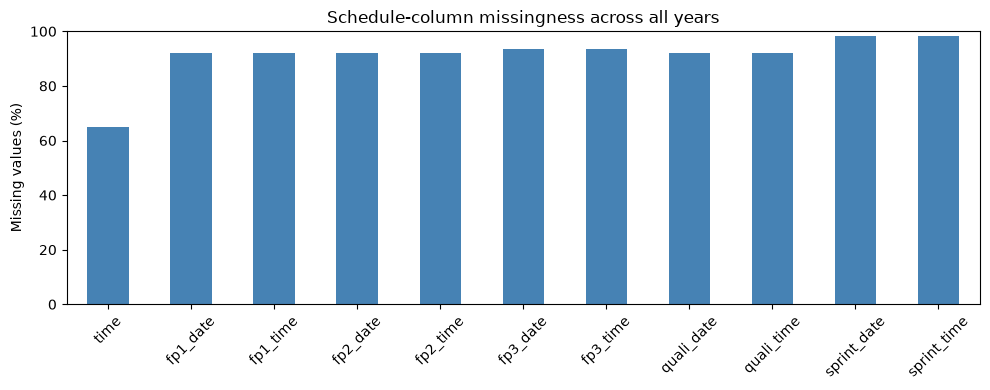

In [149]:
races_before_feature_selection = races_clean.copy(deep=True)

schedule_columns = [
    "time",
    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_date", "sprint_time"
]

print("BEFORE:", races_before_feature_selection.shape)

display(races_before_feature_selection.head())

schedule_missing = pd.DataFrame({
    "Missing count":
        races_before_feature_selection[schedule_columns].isna().sum(),
    "Missing (%)":
        races_before_feature_selection[schedule_columns].isna().mean() * 100
})

display(schedule_missing.round(2))

schedule_missing["Missing (%)"].plot.bar(
    figsize=(10, 4), color="steelblue", rot=45
)

plt.ylabel("Missing values (%)")
plt.ylim(0, 100)
plt.title("Schedule-column missingness across all years")
plt.tight_layout()
plt.show()

,time,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
year,,,,,,,,,,,
1950,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1951,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1952,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1953,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1954,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1955,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1956,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1957,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1958,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


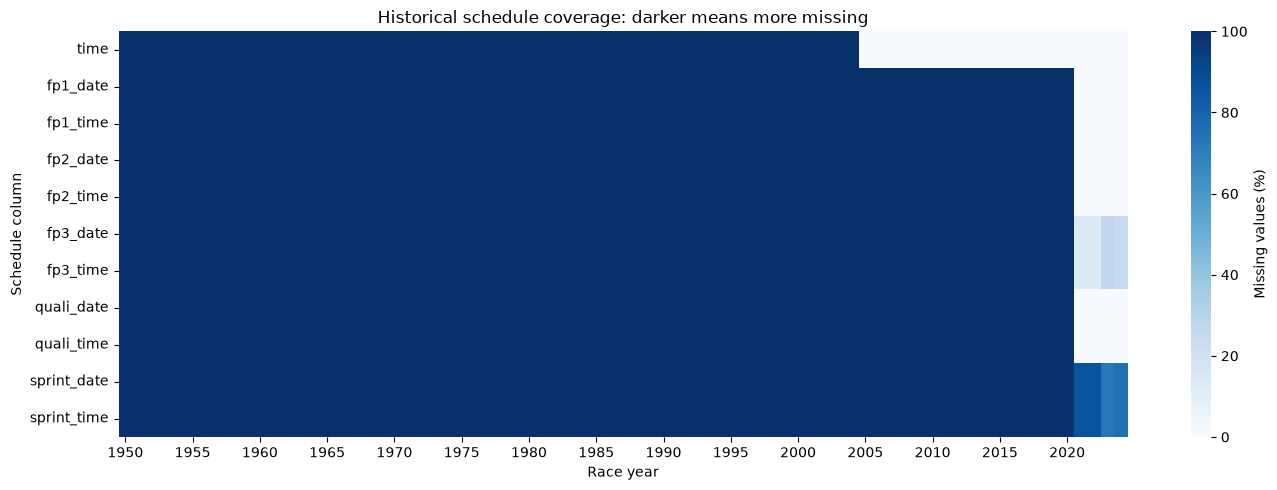

In [150]:
schedule_missing_by_year = (
    races_before_feature_selection[schedule_columns]
    .isna()
    .groupby(races_before_feature_selection["year"])
    .mean() * 100
)

with pd.option_context("display.max_rows", None):
    display(schedule_missing_by_year.round(1))

plt.figure(figsize=(14, 5))

sns.heatmap(
    schedule_missing_by_year.T,
    cmap="Blues",
    vmin=0,
    vmax=100,
    xticklabels=5,
    cbar_kws={"label": "Missing values (%)"}
)

plt.xlabel("Race year")
plt.ylabel("Schedule column")
plt.title("Historical schedule coverage: darker means more missing")
plt.tight_layout()
plt.show()

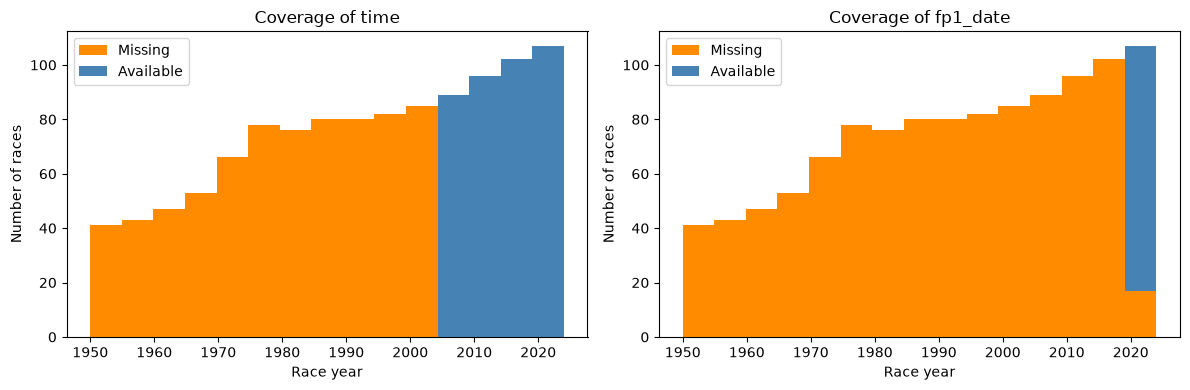

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column in zip(axes, ["time", "fp1_date"]):
    missing = races_before_feature_selection[column].isna()

    ax.hist(
        [
            races_before_feature_selection.loc[missing, "year"],
            races_before_feature_selection.loc[~missing, "year"]
        ],
        bins=15,
        stacked=True,
        label=["Missing", "Available"],
        color=["darkorange", "steelblue"]
    )

    ax.set_title(f"Coverage of {column}")
    ax.set_xlabel("Race year")
    ax.set_ylabel("Number of races")
    ax.legend()

plt.tight_layout()
plt.show()

### Decision: exclude schedule features across all years

The yearly coverage table and plots show that:

•⁠  ⁠Race start time is entirely missing in 1950–2004.
•⁠  ⁠Practice and qualifying schedules are entirely missing before 2021.
•⁠  ⁠FP3 and sprint schedules also have structural absences:
  some weekends do not contain those sessions.

Therefore, these columns do not provide consistently observed inputs
across our historical modeling period.

We exclude all 11 schedule columns from the race table used for modeling.
Filling decades of unavailable schedules with a median would produce
estimates rather than recover historical observations.

This is a coverage-based feature-selection decision. It does not claim
that removing the columns has already improved model performance.

We retain every race. The original CSV, raw races table and full
races_clean table remain unchanged.

,Before,After
Rows,1125,1125
Columns,18,7
Missing cells,11261,0


Removed columns:
['time', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']
Remaining columns:
['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'url']


,raceId,year,round,circuitId,name,date,url
0,1,2009,1,1,Australian Grand Prix,2009-03-29,http://en.wikipedia.org/wiki/2009_Australian_G...
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,http://en.wikipedia.org/wiki/2009_Chinese_Gran...
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,http://en.wikipedia.org/wiki/2009_Spanish_Gran...


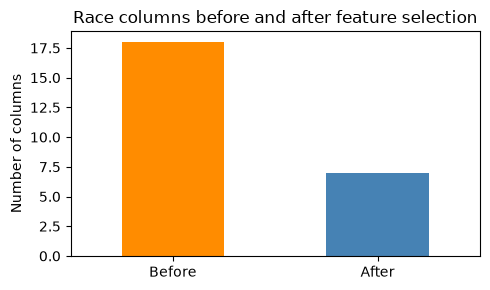

Passed: 11 schedule columns excluded; every race retained.


In [152]:
races_model = races_before_feature_selection.drop(
    columns=schedule_columns
).copy()

race_feature_comparison = pd.DataFrame({
    "Before": [
        len(races_before_feature_selection),
        races_before_feature_selection.shape[1],
        races_before_feature_selection.isna().sum().sum()
    ],
    "After": [
        len(races_model),
        races_model.shape[1],
        races_model.isna().sum().sum()
    ]
}, index=["Rows", "Columns", "Missing cells"])

display(race_feature_comparison)

print("Removed columns:")
print(schedule_columns)

print("Remaining columns:")
print(races_model.columns.tolist())

display(races_model.head())

race_feature_comparison.loc["Columns"].plot.bar(
    figsize=(5, 3), rot=0, color=["darkorange", "steelblue"]
)

plt.ylabel("Number of columns")
plt.title("Race columns before and after feature selection")
plt.tight_layout()
plt.show()

# Verify that every retained value and every race was preserved.
pd.testing.assert_frame_equal(
    races_model,
    races_before_feature_selection.drop(columns=schedule_columns)
)

pd.testing.assert_frame_equal(
    races_clean,
    races_before_feature_selection
)

pd.testing.assert_frame_equal(races, races_raw_snapshot)

assert races_model["raceId"].notna().all()
assert races_model["raceId"].is_unique

print("Passed: 11 schedule columns excluded; every race retained.")

In [153]:
races_clean = races_clean.drop(columns=['fp1_date','fp1_time','fp2_date','fp2_time','fp3_date','fp3_time','sprint_date','sprint_time','quali_date','quali_time'])

In [154]:
races_clean = races_clean.drop(columns=['time'])

### Result of race-feature selection

The race table prepared for modeling contains 1,125 races and 7 columns:
raceId, year, round, circuitId, name, date and url.

No races were deleted, and no missing schedules were filled with
invented values. The missing-cell count decreased because the
schedule columns were excluded, not because their information
was recovered.

Identifiers and descriptive fields are retained for joining and
inspection; they are not automatically all prediction features.

## 3.11 results.csv

### 3.11.1 Results: Race-Driver Duplicates & Shared Drives
Loading the raw `results` dataset and cross-referencing it with metadata to audit duplicate race-driver combinations. This analysis explicitly separates historical shared drives (permitted before 1958) from modern data anomalies, and flags conflicting podium outcomes for a single driver.

In [155]:
res_raw = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])
meta = (res_raw
        .merge(races[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
        .merge(drivers[["driverId", "surname"]], on="driverId")
        .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
        .merge(status, on="statusId"))
assert len(meta) == len(res_raw)          # joins must not add or drop rows

key = ["raceId", "driverId"]
dups = meta[meta.duplicated(key, keep=False)].sort_values(key + ["resultId"])

pairs = dups.groupby(key).agg(
    year=("year", "first"),
    n_rows=("resultId", "size"),
    n_constructors=("constructorId", "nunique"),
    n_started=("grid", lambda s: int((s > 0).sum())),
    n_podium_rows=("positionOrder", lambda s: int((s <= 3).sum())),
)
pairs["era"] = np.where(pairs["year"] <= 1958, "1950-1958", "after 1958")
pairs["podium_disagree"] = (pairs["n_podium_rows"] > 0) & (pairs["n_podium_rows"] < pairs["n_rows"])

print("pairs:", len(pairs), "| extra rows:", int((pairs["n_rows"] - 1).sum()))
display(pairs.groupby("era").agg(
    pairs=("n_rows", "size"),
    same_constructor=("n_constructors", lambda s: int((s == 1).sum())),
    none_started=("n_started", lambda s: int((s == 0).sum())),
    podium_disagree=("podium_disagree", "sum")))

cols = ["resultId", "year", "race", "surname", "constructor", "grid",
        "positionOrder", "points", "laps", "status"]
print("\nPairs after 1958:")
display(dups[dups["year"] > 1958][cols])

print("\nFirst pairs where the rows disagree on podium:")
disagree = pairs[pairs["podium_disagree"]].index
display(dups.set_index(key).loc[disagree].reset_index()[["raceId"] + cols].head(20))

pairs: 85 | extra rows: 91


,pairs,same_constructor,none_started,podium_disagree
era,,,,
1950-1958,79,66,1,20
after 1958,6,3,2,1



Pairs after 1958:


,resultId,year,race,surname,constructor,grid,positionOrder,points,laps,status
13188,13189,1978,Italian Grand Prix,Ertl,ATS,0,26,0.0,0,Did not qualify
13191,13192,1978,Italian Grand Prix,Ertl,Ensign,0,29,0.0,0,Did not prequalify
17362,17363,1964,United States Grand Prix,Clark,Lotus-Climax,1,7,0.0,102,Out of fuel
24298,24304,1964,United States Grand Prix,Clark,Lotus-Climax,1,12,0.0,54,Injection
17740,17741,1962,British Grand Prix,Greene,Lotus-Climax,0,22,0.0,0,Withdrew
17743,17744,1962,British Grand Prix,Greene,Gilby,0,25,0.0,0,Withdrew
17961,17962,1961,British Grand Prix,Moss,Ferguson,20,19,0.0,56,Disqualified
17963,17964,1961,British Grand Prix,Moss,Lotus-Climax,5,21,0.0,44,Brakes
18062,18063,1961,United States Grand Prix,Gregory,Lotus-Climax,11,17,0.0,23,Gearbox
24297,24303,1961,United States Grand Prix,Gregory,Lotus-Climax,15,11,0.0,92,+8 Laps



First pairs where the rows disagree on podium:


,raceId,resultId,year,race,surname,constructor,grid,positionOrder,points,laps,status
0,746,18083,1960,Argentine Grand Prix,Moss,Cooper-Climax,1,17,0.0,40,Suspension
1,746,22372,1960,Argentine Grand Prix,Moss,Cooper-Climax,8,3,0.0,80,Finished
2,780,18817,1957,British Grand Prix,Moss,Vanwall,1,12,0.0,51,Engine
3,780,20291,1957,British Grand Prix,Moss,Vanwall,3,1,5.0,90,Finished
4,780,18806,1957,British Grand Prix,Brooks,Vanwall,3,1,4.0,90,Finished
5,780,20293,1957,British Grand Prix,Brooks,Vanwall,1,12,0.0,51,Engine
6,784,18895,1956,Argentine Grand Prix,Fangio,Ferrari,1,13,0.0,22,Fuel pump
7,784,20267,1956,Argentine Grand Prix,Fangio,Ferrari,3,1,5.0,98,Finished
8,785,18899,1956,Monaco Grand Prix,Fangio,Ferrari,1,4,1.5,99,+1 Lap
9,785,20270,1956,Monaco Grand Prix,Fangio,Ferrari,9,2,4.0,100,Finished


In [156]:
d = dups.copy()
d["grid_sort"] = d["grid"].where(d["grid"] > 0, 10_000)                 # grid 0 sorts last
best_slot = d.groupby(key)["grid_sort"].min().rename("best_slot")         # best declared start slot
credit    = (d.groupby(key)["positionOrder"].min() <= 3).rename("credit") # podium credited in any row

rules = {"lowest resultId":        ["resultId"],
         "best positionOrder":     ["positionOrder", "resultId"],
         "smallest started grid":  ["grid_sort", "resultId"]}

out = []
for name, cols in rules.items():
    kept = (d.sort_values(key + cols).drop_duplicates(key)
              .set_index(key).join(best_slot).join(credit))
    out.append({"rule": name,
                "podium rate": round((kept["positionOrder"] <= 3).mean(), 3),
                "label != credited podium": int(((kept["positionOrder"] <= 3) != kept["credit"]).sum()),
                "kept grid != best slot": int((kept["grid_sort"] != kept["best_slot"]).sum())})
pd.DataFrame(out)

,rule,podium rate,label != credited podium,kept grid != best slot
0,lowest resultId,0.071,16,27
1,best positionOrder,0.259,0,56
2,smallest started grid,0.059,17,0


### **Results table** 

### 3.11.2 Results: Initial Auditing & Time Conversions
Loading the raw `results` dataset, tracking `\N` sentinel frequencies, and casting duration columns (`fastestLapTime` and `time`) into numeric seconds. This includes a manual, evidence-backed correction for a specific total-duration discrepancy (Belgium 2024).

In [157]:
print("shape:", results.shape)
print("columns:", list(results.columns))
results.head()

shape: (26759, 18)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [158]:
before_res = pd.DataFrame({"sentinel (\\N)": (results == r"\N").sum()})
before_res["% missing"] = (100 * before_res["sentinel (\\N)"] / len(results)).round(2)
before_res

,sentinel (\N),% missing
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,6,0.02
grid,0,0.00
position,10953,40.93
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


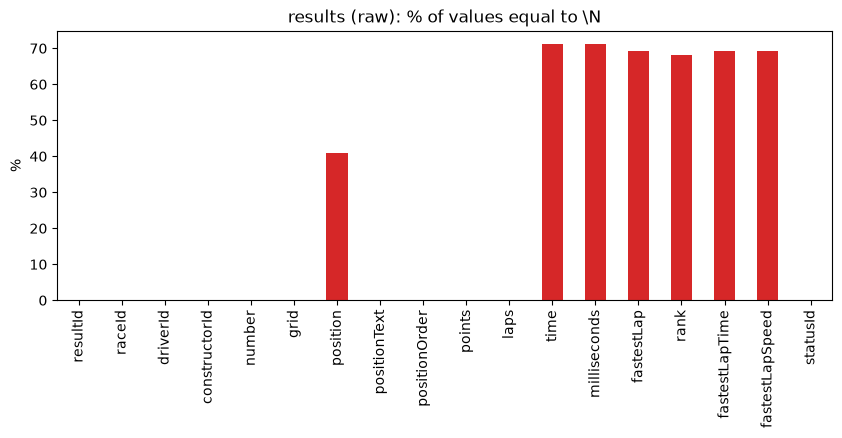

In [159]:
before_res["% missing"].plot(kind="bar", color="tab:red", figsize=(10, 3.5),
                             title="results (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [160]:
results_clean = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])
results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [161]:
check_res = pd.DataFrame({"sentinel_before": before_res["sentinel (\\N)"],
                          "NaN_after": results_clean.isnull().sum()})
check_res["match"] = check_res["sentinel_before"] == check_res["NaN_after"]
check_res

,sentinel_before,NaN_after,match
resultId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,6,6,True
grid,0,0,True
position,10953,10953,True
positionText,0,0,True
positionOrder,0,0,True
points,0,0,True


In [162]:
# Convert the existing fastestLapTime column to numeric seconds.
n_before = results_clean["fastestLapTime"].isna().sum()
results_clean["fastestLapTime"] = results_clean["fastestLapTime"].map(to_seconds)
print("new missing values created:", results_clean["fastestLapTime"].isna().sum() - n_before)
results_clean[["fastestLapTime"]].dropna().head()


new missing values created: 0


,fastestLapTime
0,87.452
1,87.739
2,88.090
3,88.603
4,87.418


In [163]:
# Convert the existing race time column to numeric seconds.
# Original + values are gaps; other values are total elapsed times.
# Conversion does not make gaps and total durations comparable.
time_before = results_clean["time"].copy()
results_clean["time"] = results_clean["time"].map(to_seconds)
assert time_before.notna().equals(results_clean["time"].notna())
assert pd.api.types.is_numeric_dtype(results_clean["time"])
print("Race time converted to seconds without losing populated values.")
results_clean[["time", "milliseconds"]].dropna().head(10)


Race time converted to seconds without losing populated values.


,time,milliseconds
0,5690.616,5690616.0
1,5.478,5696094.0
2,8.163,5698779.0
3,17.181,5707797.0
4,18.014,5708630.0
22,5478.555,5478555.0
23,19.570,5498125.0
24,38.450,5517005.0
25,45.832,5524387.0
26,46.548,5525103.0


### Check race duration against milliseconds before correcting anything

We check every populated **total-duration** record. The original `time` values starting with `+` are gaps, so they must not be compared directly with total elapsed `milliseconds`. For each comparable row, `time` converted to seconds and multiplied by 1,000 should equal `milliseconds`.

The table below displays all mismatches discovered by this general check, with race and driver details. It runs before the correction.


In [164]:
# Select total times using the original strings; results_clean.time is already seconds.
original_duration_text = results.set_index("resultId")["time"]
is_total_duration = ~results_clean["resultId"].map(original_duration_text).astype("string").str.startswith("+", na=False)
duration_check = results_clean.loc[
    is_total_duration & results_clean["time"].notna() & results_clean["milliseconds"].notna(),
    ["resultId", "raceId", "driverId", "time", "milliseconds"]
].copy()
duration_check["Expected milliseconds"] = (duration_check["time"] * 1000).round().astype("int64")
duration_check["Difference (ms)"] = duration_check["milliseconds"] - duration_check["Expected milliseconds"]
duration_mismatches = duration_check.loc[duration_check["Difference (ms)"].ne(0)].copy()
duration_mismatches = duration_mismatches.merge(
    races_clean[["raceId", "year", "name"]], on="raceId", validate="many_to_one"
).merge(drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
print("Comparable total-duration records checked:", len(duration_check))
print("Mismatches before correction:", len(duration_mismatches))
display(duration_mismatches)


Comparable total-duration records checked: 1128
Mismatches before correction: 1


,resultId,raceId,driverId,time,milliseconds,Expected milliseconds,Difference (ms),year,name,forename,surname
0,26564,1134,847,4797.04,4797566.0,4797040,526.0,2024,Belgian Grand Prix,George,Russell


### Verify the discovered mismatch using the official result

The [official Formula 1 Belgian Grand Prix 2024 result](https://www.formula1.com/en/results/2024/races/1242/belgium/race-result) lists car 63, George Russell, Mercedes, 44 laps, **1:19:57.040**, disqualified, zero points. This matches our driver, race, car and recorded time.

That duration equals **4,797,040 milliseconds**, whereas the raw CSV contains **4,797,566**. We therefore correct only `results_clean.milliseconds` for `resultId = 26564`. Russell's disqualification, position, points and other values are preserved. This is a verified disagreement between two representations of the same duration, not a flag based on an unusual value.


,resultId,raceId,driverId,Official time,Official milliseconds,Source,Before milliseconds,After milliseconds
0,26564,1134,847,1:19:57.040,4797040,https://www.formula1.com/en/results/2024/races...,4797566.0,4797040.0


Mismatches after correction: 0


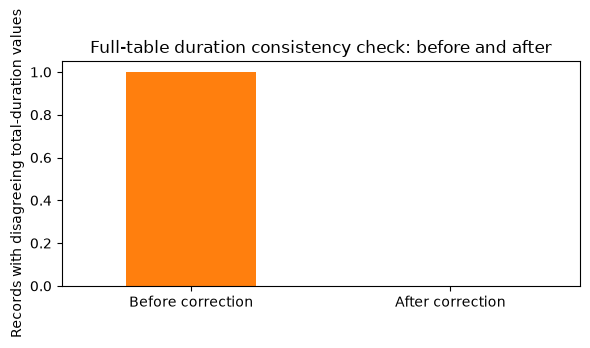

In [165]:
# Fixed observation checked on the official F1 result page.
verified_duration = pd.DataFrame({
    "resultId": [26564], "raceId": [1134], "driverId": [847],
    "Official time": ["1:19:57.040"], "Official milliseconds": [4797040],
    "Source": ["https://www.formula1.com/en/results/2024/races/1242/belgium/race-result"]
})
assert set(duration_mismatches["resultId"]) == set(verified_duration["resultId"])
assert duration_mismatches["Expected milliseconds"].tolist() == verified_duration["Official milliseconds"].tolist()
results_before_duration_fix = results_clean.copy(deep=True)
for _, correction in verified_duration.iterrows():
    match = (results_clean["resultId"].eq(correction["resultId"])
             & results_clean["raceId"].eq(correction["raceId"])
             & results_clean["driverId"].eq(correction["driverId"]))
    assert match.sum() == 1
    assert results_clean.loc[match, "time"].iloc[0] == to_seconds(correction["Official time"])
    results_clean.loc[match, "milliseconds"] = correction["Official milliseconds"]

# Prove that other columns and unaffected rows were preserved.
pd.testing.assert_frame_equal(
    results_before_duration_fix.drop(columns="milliseconds"),
    results_clean.drop(columns="milliseconds")
)
unaffected = ~results_clean["resultId"].isin(verified_duration["resultId"])
pd.testing.assert_frame_equal(results_before_duration_fix.loc[unaffected], results_clean.loc[unaffected])
duration_before_after = verified_duration.merge(
    results_before_duration_fix[["resultId", "milliseconds"]].rename(columns={"milliseconds": "Before milliseconds"}),
    on="resultId", validate="one_to_one"
).merge(
    results_clean[["resultId", "milliseconds"]].rename(columns={"milliseconds": "After milliseconds"}),
    on="resultId", validate="one_to_one"
)
display(duration_before_after)

# Repeat the same full-table check after the correction.
checked_after = results_clean.set_index("resultId").loc[duration_check["resultId"], "milliseconds"].to_numpy()
remaining_duration_mismatches = int((checked_after != duration_check["Expected milliseconds"].to_numpy()).sum())
assert remaining_duration_mismatches == 0
print("Mismatches after correction:", remaining_duration_mismatches)
pd.Series({"Before correction": len(duration_mismatches), "After correction": remaining_duration_mismatches}).plot.bar(
    rot=0, color=["tab:orange", "tab:green"], figsize=(6, 3)
)
plt.ylabel("Records with disagreeing total-duration values")
plt.title("Full-table duration consistency check: before and after")
plt.tight_layout()
plt.show()


### 3.11.3 Results: Shared Drive Consolidation & Integrity Checks
Resolving multi-entry driver-race pairs (historical shared drives). The pipeline consolidates these by keeping the car with the best finishing position while summing the total points earned. Concludes with foreign key validation across all parent reference tables and a missingness heatmap by decade.

In [166]:
print("positionOrder missing:", results_clean["positionOrder"].isna().sum(), "(must be 0)")
print("positionOrder < 1    :", (results_clean["positionOrder"] < 1).sum(), "(must be 0)")
print("grid range:", results_clean["grid"].min(), "->", results_clean["grid"].max())
print("negative points:", (results_clean["points"] < 0).sum())

positionOrder missing: 0 (must be 0)
positionOrder < 1    : 0 (must be 0)
grid range: 0 -> 34
negative points: 0


In [167]:
n_dup = results_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("extra rows (same driver twice in the same race):", n_dup)

extra rows (same driver twice in the same race): 91


In [168]:
dup_rows = results_clean[results_clean.duplicated(["raceId", "driverId"], keep=False)].sort_values(["raceId", "driverId", "resultId"])
print("rows involved:", len(dup_rows))
dup_rows[["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "statusId"]].head(20)

rows involved: 176


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
13188,13189,540,229,54,0,26,0.0,0,81
13191,13192,540,229,57,0,29,0.0,0,97
17362,17363,717,373,172,1,7,0.0,102,60
24298,24304,717,373,172,1,12,0.0,54,98
17740,17741,733,465,172,0,22,0.0,0,54
17743,17744,733,465,97,0,25,0.0,0,54
17961,17962,742,475,102,20,19,0.0,56,2
17963,17964,742,475,172,5,21,0.0,44,23
18062,18063,745,418,172,11,17,0.0,23,6
24297,24303,745,418,172,15,11,0.0,92,18


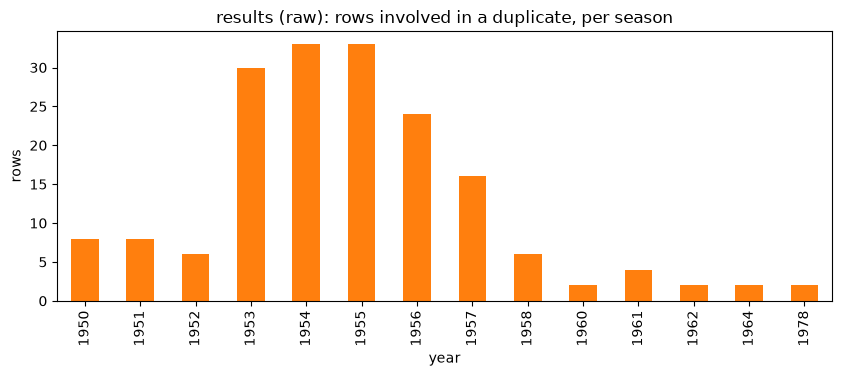

number of started rows per duplicated pair:


grid
2    76
3     6
0     3
Name: count, dtype: int64

In [169]:
years = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId", "year"])
dup_plot = dup_rows.merge(years, on="raceId", how="left")     # copy for plotting only

dup_plot.groupby("year").size().plot(kind="bar", color="tab:orange", figsize=(10, 3.5),
                                     title="results (raw): rows involved in a duplicate, per season")
plt.ylabel("rows")
plt.show()

# In how many duplicated pairs did exactly one of the rows start from a real grid slot (grid > 0)?
started_per_pair = dup_rows.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).sum())
print("number of started rows per duplicated pair:")
started_per_pair.value_counts()

In [170]:
# Summarize every original entry BEFORE selecting one car.
key = ["raceId", "driverId"]
results_before_combine = results_clean.copy(deep=True)
clean_driver_race_details = results_before_combine.groupby(key).agg(
    original_entries=("resultId", "size"), constructor_choices=("constructorId", "nunique")
).reset_index()
per_pair = (results_before_combine.groupby(key)
            .agg(total_points=("points", "sum"),
                 n_raw_rows=("resultId", "size"))
            .reset_index())

# Keep all other details from the car with the best (lowest) positionOrder.
# If positionOrder is tied, keep the smallest resultId for a repeatable choice.
kept = (results_before_combine
        .sort_values(key + ["positionOrder", "resultId"])
        .drop_duplicates(key, keep="first")
        .drop(columns="points"))
results_clean = kept.merge(per_pair, on=key, validate="one_to_one")
results_clean = results_clean.rename(columns={"total_points": "points"})
# Retained for compatibility with the existing checks below.
results_clean["positionOrder_row"] = results_clean["positionOrder"]
results_clean = results_clean.sort_values("resultId").reset_index(drop=True)

print("Rows before:", len(results_before_combine))
print("Rows after:", len(results_clean))
print("Entries combined:", len(results_before_combine) - len(results_clean))
print("Driver-race groups with multiple entries:", int(results_clean["n_raw_rows"].gt(1).sum()))


Rows before: 26759
Rows after: 26668
Entries combined: 91
Driver-race groups with multiple entries: 85


In [171]:
assert not results_clean.duplicated(["raceId", "driverId"]).any()
print("OK: (raceId, driverId) is unique")

OK: (raceId, driverId) is unique


Before combining: all entries in these groups


,raceId,driverId,resultId,constructorId,number,grid,positionOrder,points,laps,statusId
0,540,229,13189,54,10.0,0,26,0.0,0,81
1,540,229,13192,57,23.0,0,29,0.0,0,97
2,717,373,17363,172,1.0,1,7,0.0,102,60
175,717,373,24304,172,2.0,1,12,0.0,54,98
3,733,465,17741,172,48.0,0,22,0.0,0,54
...,...,...,...,...,...,...,...,...,...,...
85,838,627,20143,154,20.0,6,12,0.0,10,25
91,839,579,20184,51,60.0,7,13,0.0,34,5
86,839,579,20164,51,18.0,1,15,1.0,23,6
90,839,647,20183,6,48.0,6,2,3.0,80,1


After combining: best-finishing car details and summed points


,raceId,driverId,resultId,constructorId,number,grid,positionOrder,points,laps,statusId,n_raw_rows
13188,540,229,13189,54,10.0,0,26,0.0,0,81,2
17361,717,373,17363,172,1.0,1,7,0.0,102,60,2
17739,733,465,17741,172,48.0,0,22,0.0,0,54,2
17959,742,475,17962,102,26.0,20,19,0.0,56,2,2
24207,745,418,24303,172,21.0,15,11,0.0,92,18,2
...,...,...,...,...,...,...,...,...,...,...,...
20116,831,642,20189,51,40.0,7,3,3.0,79,11,2
20107,835,529,20179,113,17.0,9,5,1.0,136,12,2
20110,838,627,20182,154,26.0,15,6,0.0,56,18,2
20112,839,579,20184,51,60.0,7,13,1.0,34,5,2


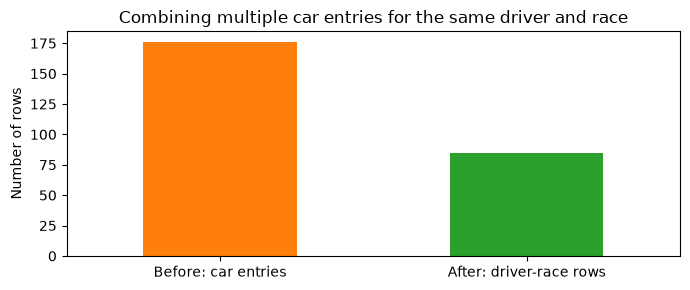

In [172]:
# Check the combined result against ALL original entries.
expected = results_before_combine.groupby(key).agg(
    points=("points", "sum"),
    n_raw_rows=("resultId", "size"),
    positionOrder=("positionOrder", "min")
).sort_index()
actual = results_clean.set_index(key)[expected.columns].sort_index()
pd.testing.assert_frame_equal(actual, expected)
assert results_clean["n_raw_rows"].sum() == len(results_before_combine)

# Show every multi-entry group before and after combining it.
multiple_keys = per_pair.loc[per_pair["n_raw_rows"].gt(1), key]
show_columns = key + ["resultId", "constructorId", "number", "grid", "positionOrder", "points", "laps", "statusId"]
print("Before combining: all entries in these groups")
display(results_before_combine.merge(multiple_keys, on=key)[show_columns].sort_values(key + ["positionOrder"]))
print("After combining: best-finishing car details and summed points")
display(results_clean.loc[results_clean["n_raw_rows"].gt(1), show_columns + ["n_raw_rows"]].sort_values(key))

# Visual evidence of how the row count changes in the affected groups.
counts = pd.Series({
    "Before: car entries": int(per_pair.loc[per_pair["n_raw_rows"].gt(1), "n_raw_rows"].sum()),
    "After: driver-race rows": int(results_clean["n_raw_rows"].gt(1).sum())
})
ax = counts.plot.bar(rot=0, figsize=(7, 3), color=["tab:orange", "tab:green"])
ax.set_ylabel("Number of rows")
ax.set_title("Combining multiple car entries for the same driver and race")
plt.tight_layout()
plt.show()


In [173]:
assert not results_clean.duplicated(key).any()
assert len(results_clean) == 26668
print("credited podium rows:", int((results_clean["positionOrder"] <= 3).sum()), "(expect 3395)")
print("rows from multi-row pairs:", int((results_clean["n_raw_rows"] > 1).sum()), "(expect 85)")

# The 18 races with 4 or 5 podium rows: do they all contain a shared pair?
pod = results_clean[results_clean["positionOrder"] <= 3].groupby("raceId").size()
odd = pod[pod != 3].index
(results_clean[results_clean["raceId"].isin(odd)]
   .groupby("raceId").agg(podium_rows=("positionOrder", lambda s: int((s <= 3).sum())),
                          shared_pairs=("n_raw_rows", lambda s: int((s > 1).sum())))
   .join(races_clean.set_index("raceId")[["year", "name"]]).sort_values("year"))

credited podium rows: 3395 (expect 3395)
rows from multi-row pairs: 85 (expect 85)


,podium_rows,shared_pairs,year,name
raceId,,,,
839,4,2,1950,Italian Grand Prix
828,5,3,1951,French Grand Prix
826,4,0,1951,Indianapolis 500
831,4,1,1951,Italian Grand Prix
810,4,1,1953,Dutch Grand Prix
809,4,8,1953,Indianapolis 500
806,4,1,1954,Italian Grand Prix
804,4,1,1954,German Grand Prix
794,4,0,1955,Indianapolis 500


In [174]:
podium_per_race = (results_clean["positionOrder"] <= 3).groupby(results_clean["raceId"]).sum()
print(podium_per_race.value_counts())
print("races with != 3 podium rows:", int((podium_per_race != 3).sum()))

positionOrder
3    1107
4      16
5       2
Name: count, dtype: int64
races with != 3 podium rows: 18


In [175]:
print("resultId unique  :", results_clean["resultId"].is_unique)
print("resultId no nulls:", results_clean["resultId"].notna().all())

resultId unique  : True
resultId no nulls: True


In [176]:
# Initialize this reference once; its own section later audits the same clean variable.
status_clean = status.copy(deep=True).replace(r"\N", np.nan)
races_ids = races_clean["raceId"]
drivers_ids = drivers_clean["driverId"]
constructors_ids = constructors_clean["constructorId"]
status_ids = status_clean["statusId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids),
                         ("statusId", "status.statusId", status_ids)]:
    orphans = int((~results_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"results.{col}", "points to": parent,
                 "null values": int(results_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,results.raceId,races.raceId,0,0,True
1,results.driverId,drivers.driverId,0,0,True
2,results.constructorId,constructors.constructorId,0,0,True
3,results.statusId,status.statusId,0,0,True


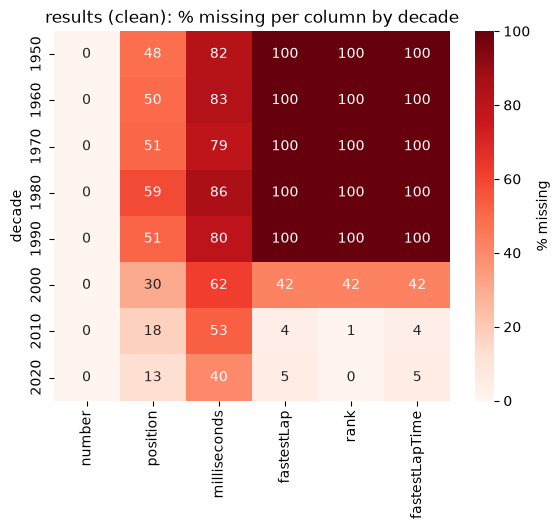

In [177]:
import seaborn as sns

res_year = results_clean.merge(years, on="raceId", how="left")     # copy for plotting only
cols = ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapTime"]
miss_dec = (res_year.assign(decade=(res_year["year"] // 10) * 10)
                    .groupby("decade")[cols]
                    .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("results (clean): % missing per column by decade")
plt.show()

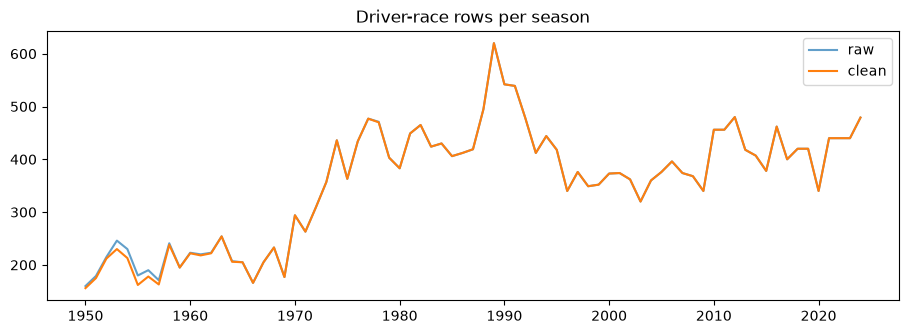

In [178]:
before_rows = pd.read_csv(DATA_DIR / "results.csv", usecols=["raceId"]).merge(years, on="raceId").groupby("year").size()
after_rows  = res_year.groupby("year").size()

plt.figure(figsize=(11, 3.5))
plt.plot(before_rows.index, before_rows.values, label="raw", alpha=0.7)
plt.plot(after_rows.index, after_rows.values, label="clean")
plt.title("Driver-race rows per season")
plt.legend()
plt.show()

In [179]:
pd.DataFrame({
    "rows": [len(results), len(results_clean)],
    "columns": [results.shape[1], results_clean.shape[1]],
    "missing values": [int(before_res["sentinel (\\N)"].sum()), int(results_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_res["sentinel (\\N)"].sum()), 0],
    "duplicate (raceId, driverId)": [n_dup, 0],
}, index=["before", "after"])

,rows,columns,missing values,text '\N' left,"duplicate (raceId, driverId)"
before,26759,18,122887,122887,91
after,26668,20,122260,0,0


### Combining multiple car entries for one driver in one race

A driver can have several historical entries for the same race after using more than one car. These entries are not automatically data errors. For our one-row-per-driver-per-race table, we apply this agreed rule:

- Count the original entries first and store that count in `n_raw_rows`.
- Add the points from all entries into the existing `points` column.
- Keep the other fields from the entry with the lowest (best) `positionOrder`. If tied, use the smallest `resultId` for a repeatable choice.
- Keep `positionOrder_row` for compatibility with the checks below; it equals the selected car's `positionOrder`.

The before/after tables and graph above show 176 car entries combined into 85 driver-race rows. The assertions verify the points, entry counts and best finishing order for every group. Raw `results` and CSV files keep every original entry.

**Reason for this design choice:** one prediction represents one driver in one race. The best recorded finish represents that driver's podium outcome. Retaining the remaining fields from the same entry preserves a recorded car-entry combination instead of arbitrarily mixing car details. Summed points separately represent the driver's total across entries.

The selected grid, constructor, laps and status describe the retained car entry; they are not a reconstruction of the driver's original starting car. This historical representation is retained as an explicit modeling assumption. The scope and limitation are documented in section 5.2.


In [180]:
pd.set_option("display.width", 200)
rows = (results_clean[results_clean["raceId"].isin([826, 794]) & (results_clean["positionOrder"] <= 3)]
        .merge(drivers_clean[["driverId", "surname"]], on="driverId")
        .merge(constructors_clean[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
        .merge(status_clean, on="statusId"))
rows[["raceId", "resultId", "surname", "constructor", "number", "grid", "positionOrder",
      "positionOrder_row", "points", "laps", "status"]].sort_values(["raceId", "positionOrder"])

,raceId,resultId,surname,constructor,number,grid,positionOrder,positionOrder_row,points,laps,status
0,794,19101,Sweikert,Kurtis Kraft,6.0,14,1,1,8.0,200,Finished
1,794,19102,Bettenhausen,Kurtis Kraft,10.0,2,2,2,3.0,200,Finished
7,794,20261,Russo,Kurtis Kraft,10.0,2,2,2,3.0,200,Finished
2,794,19103,Davies,Kurtis Kraft,15.0,10,3,3,4.0,200,Finished
3,826,19872,Wallard,Kurtis Kraft,99.0,2,1,1,9.0,200,Finished
4,826,19873,Nazaruk,Kurtis Kraft,83.0,7,2,2,6.0,200,Finished
5,826,19874,McGrath,Kurtis Kraft,9.0,3,3,3,2.0,200,Finished
6,826,20185,Ayulo,Kurtis Kraft,9.0,3,3,3,2.0,200,Finished


### 3.11.4 Results: Grid Anomalies, Indy 500 & Qualifying Verification
Investigating structural anomalies such as records with zero grid slots or zero completed laps. This isolates the Indianapolis 500 (which skews F1 statistics) and cross-references grid positions against the `qualifying` table to verify historical coverage and pit-lane starts.

In [181]:
rc = (results_clean
      .merge(races_clean[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
      .merge(status_clean, on="statusId"))
rc["grid0"] = rc["grid"] == 0
rc["laps0"] = rc["laps"] == 0

print("grid==0 rows:", int(rc["grid0"].sum()), "| laps==0 rows:", int(rc["laps0"].sum()))
display(pd.crosstab(rc["grid0"], rc["laps0"], margins=True))      # do the two overlap?

by_decade = rc.assign(decade=(rc["year"] // 10) * 10).groupby("decade").agg(
    rows=("grid", "size"), grid0_pct=("grid0", lambda s: round(100 * s.mean(), 1)),
    laps0_pct=("laps0", lambda s: round(100 * s.mean(), 1)))
display(by_decade)

print("\nTop statuses among grid==0 rows:")
display(rc.loc[rc["grid0"], "status"].value_counts().head(10))
print("positionText among grid==0 rows:", rc.loc[rc["grid0"], "positionText"].value_counts().head(8).to_dict())
print("podium rows with grid==0:", int(((rc["positionOrder"] <= 3) & rc["grid0"]).sum()))

# Indianapolis 500
indy = rc[rc["race"] == "Indianapolis 500"]
non_indy_drivers = set(rc.loc[rc["race"] != "Indianapolis 500", "driverId"])
print("\nIndy 500 races:", indy["raceId"].nunique(), "| years:", sorted(indy["year"].unique()))
print("rows:", len(indy), f"({100 * len(indy) / len(rc):.2f}% of all rows)",
      "| grid==0:", int(indy["grid0"].sum()), "| shared pairs:", int((indy["n_raw_rows"] > 1).sum()))
print("drivers appearing only in the Indy 500:",
      len(set(indy["driverId"]) - non_indy_drivers), "of", indy["driverId"].nunique())

grid==0 rows: 1635 | laps==0 rows: 2529


laps0,False,True,All
grid0,,,
False,24067,966,25033
True,72,1563,1635
All,24139,2529,26668


,rows,grid0_pct,laps0_pct
decade,,,
1950,1922,3.5,7.2
1960,2108,9.3,11.9
1970,3806,9.2,12.6
1980,4503,12.7,16.1
1990,4250,8.4,13.5
2000,3643,0.2,4.6
2010,4297,0.7,3.2
2020,2139,2.7,2.7



Top statuses among grid==0 rows:


status
Did not qualify       1012
Did not prequalify     330
Withdrew               163
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Name: count, dtype: int64

positionText among grid==0 rows: {'F': 1346, 'W': 202, 'R': 14, '17': 9, '13': 7, 'E': 7, '10': 7, '15': 6}
podium rows with grid==0: 0

Indy 500 races: 11 | years: [np.int64(1950), np.int64(1951), np.int64(1952), np.int64(1953), np.int64(1954), np.int64(1955), np.int64(1956), np.int64(1957), np.int64(1958), np.int64(1959), np.int64(1960)]
rows: 381 (1.43% of all rows) | grid==0: 0 | shared pairs: 21
drivers appearing only in the Indy 500: 103 of 107


In [182]:
indy_ids = races_clean.loc[races_clean["name"] == "Indianapolis 500", "raceId"]
results_clean["is_indy500"]    = results_clean["raceId"].isin(indy_ids)
results_clean["has_grid_slot"] = results_clean["grid"] > 0

steps = [("all cleaned rows",               pd.Series(True, index=results_clean.index)),
         ("... excluding Indy 500",         ~results_clean["is_indy500"]),
         ("... and requiring a grid slot",  ~results_clean["is_indy500"] & results_clean["has_grid_slot"])]
out = []
for label, keep in steps:
    sub = results_clean[keep]
    out.append({"population": label, "rows": len(sub),
                "podium rows": int((sub["positionOrder"] <= 3).sum()),
                "podium rate": round((sub["positionOrder"] <= 3).mean(), 4)})
pd.DataFrame(out)

,population,rows,podium rows,podium rate
0,all cleaned rows,26668,3395,0.1273
1,... excluding Indy 500,26287,3359,0.1278
2,... and requiring a grid slot,24652,3359,0.1363


In [183]:
single = results_clean[results_clean["n_raw_rows"] == 1]
pt_num = pd.to_numeric(single["positionText"], errors="coerce")
# Only positive values are numeric classified positions; negative codes are categories.
cl = single["position"].gt(0)

print("positionText letter codes:", single.loc[pt_num.isna(), "positionText"].value_counts().to_dict())
print("Positive classified position vs numeric positionText, disagree:", int((cl != pt_num.notna()).sum()))
both = cl & pt_num.notna()
print("position != positionText (numeric):", int((single.loc[both, "position"] != pt_num[both]).sum()))
print("position != positionOrder (classified rows):",
      int((single.loc[cl, "position"] != single.loc[cl, "positionOrder"]).sum()))
podium = single[single["positionOrder"] <= 3]
print("podium rows without numeric position 1-3:", int((~pt_num[podium.index].isin([1, 2, 3])).sum()))

positionText letter codes: {'R': 8805, 'F': 1364, 'W': 334, 'N': 190, 'D': 150, 'E': 9}
Positive classified position vs numeric positionText, disagree: 2
position != positionText (numeric): 0
position != positionOrder (classified rows): 13
podium rows without numeric position 1-3: 1


In [184]:
key = ["raceId", "driverId"]
qg = (results_clean[key + ["grid", "has_grid_slot", "is_indy500"]]
      .merge(races_clean[["raceId", "year"]], on="raceId")
      .merge(qualifying_clean[key + ["position"]].rename(columns={"position": "q_pos"}),
             on=key, how="left", validate="one_to_one"))

# qualifying rows with no matching result row
orph = qualifying_clean.merge(results_clean[key], on=key, how="left", indicator=True)
print("qualifying rows with no result row:", int((orph["_merge"] == "left_only").sum()))

both = qg[qg["q_pos"].notna() & qg["has_grid_slot"]]
diff = both["grid"] - both["q_pos"]
print("rows with qualifying position and a grid slot:", len(both))
print("grid == qualifying position:", round(100 * (diff == 0).mean(), 1), "%")
print("grid - qualifying position, most common:", diff.value_counts().head(8).to_dict())
print("qualifying position present but no grid slot:", int((qg["q_pos"].notna() & ~qg["has_grid_slot"]).sum()))

qualifying rows with no result row: 0
rows with qualifying position and a grid slot: 10407
grid == qualifying position: 76.7 %
grid - qualifying position, most common: {0.0: 7985, -1.0: 1454, -2.0: 282, 5.0: 108, 3.0: 93, -3.0: 85, 1.0: 75, 2.0: 70}
qualifying position present but no grid slot: 87


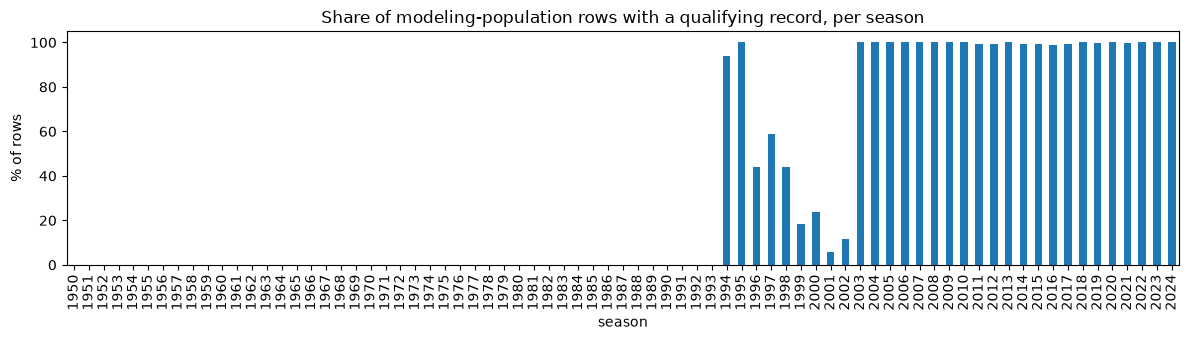

In [185]:
pop = qg[~qg["is_indy500"] & qg["has_grid_slot"]]
cov = pop.assign(has_q=pop["q_pos"].notna()).groupby("year")["has_q"].mean() * 100
ax = cov.plot(kind="bar", figsize=(12, 3.5), color="tab:blue",
              title="Share of modeling-population rows with a qualifying record, per season")
ax.set_ylabel("% of rows"); ax.set_xlabel("season")
plt.tight_layout(); plt.show()

In [186]:
sres = (results_clean
        .merge(races_clean[["raceId", "year", "name"]].rename(columns={"name": "race"}), on="raceId")
        .merge(drivers_clean[["driverId", "surname"]], on="driverId")
        .merge(status_clean, on="statusId"))
single = sres[sres["n_raw_rows"] == 1]
pt_num = pd.to_numeric(single["positionText"], errors="coerce")
# Only positive values are numeric classified positions; negative codes are categories.
cl = single["position"].gt(0)
cols = ["resultId", "year", "race", "surname", "grid", "position", "positionText",
        "positionOrder", "points", "laps", "status"]

print("A) position vs positionText numeric disagree:")
display(single.loc[cl != pt_num.notna(), cols])
print("B) position != positionOrder on classified rows:")
display(single.loc[cl & (single["position"] != single["positionOrder"]), cols])
print("C) podium rows without numeric position 1-3:")
display(single.loc[(single["positionOrder"] <= 3) & ~pt_num.isin([1, 2, 3]), cols])

# Qualified but no grid slot
qn = (qg[qg["q_pos"].notna() & ~qg["has_grid_slot"]][key + ["year"]]
      .merge(results_clean[key + ["laps", "statusId"]], on=key)
      .merge(status_clean, on="statusId"))
print("\nqualified but no grid slot:", len(qn), "| completed laps:", int((qn["laps"] > 0).sum()))
display(qn["status"].value_counts().head(8))
display(qn["year"].value_counts().sort_index())

A) position vs positionText numeric disagree:


,resultId,year,race,surname,grid,position,positionText,positionOrder,points,laps,status
1148,1149,2005,Australian Grand Prix,Button,8,NaN,11,11,0.0,56,+1 Lap
1151,1152,2005,Australian Grand Prix,Sato,20,NaN,14,14,0.0,55,+2 Laps


B) position != positionOrder on classified rows:


,resultId,year,race,surname,grid,position,positionText,positionOrder,points,laps,status
10656,10657,1983,Brazilian Grand Prix,Lauda,9,3.0,3,2,4.0,63,Finished
10657,10658,1983,Brazilian Grand Prix,Laffite,18,4.0,4,3,3.0,63,Finished
10658,10659,1983,Brazilian Grand Prix,Tambay,3,5.0,5,4,2.0,63,Finished
10659,10660,1983,Brazilian Grand Prix,Surer,20,6.0,6,5,1.0,63,Finished
10660,10661,1983,Brazilian Grand Prix,Prost,2,7.0,7,6,0.0,62,+1 Lap
10661,10662,1983,Brazilian Grand Prix,Warwick,5,8.0,8,7,0.0,62,+1 Lap
10662,10663,1983,Brazilian Grand Prix,Serra,23,9.0,9,8,0.0,62,+1 Lap
10663,10664,1983,Brazilian Grand Prix,Arnoux,6,10.0,10,9,0.0,62,+1 Lap
10664,10665,1983,Brazilian Grand Prix,Sullivan,21,11.0,11,10,0.0,62,+1 Lap
10665,10666,1983,Brazilian Grand Prix,Mansell,22,12.0,12,11,0.0,61,+2 Laps


C) podium rows without numeric position 1-3:


,resultId,year,race,surname,grid,position,positionText,positionOrder,points,laps,status
10657,10658,1983,Brazilian Grand Prix,Laffite,18,4.0,4,3,3.0,63,Finished



qualified but no grid slot: 87 | completed laps: 71


status
+1 Lap              26
Finished            22
+2 Laps              7
Did not qualify      5
Accident             4
Withdrew             4
Collision damage     3
Retired              2
Name: count, dtype: int64

year
1994     3
1995     1
2009     1
2011     3
2012     2
2015     2
2016     4
2017     2
2018     1
2019    11
2020     5
2021    12
2022    11
2023    18
2024    11
Name: count, dtype: int64

### 3.11.5 Results: Defining the Final Modeling Population
Finalizing the explicit criteria for inclusion in the predictive model. This establishes the `in_population` flag by excluding the Indy 500 and requiring a valid grid slot, while explicitly accommodating known edge cases (drivers who officially raced starting from the pit lane).

In [187]:
results_clean["grid0_raced"] = (results_clean["grid"] == 0) & (results_clean["laps"] > 0)
results_clean["in_population"] = (~results_clean["is_indy500"]
                                  & (results_clean["has_grid_slot"] | results_clean["grid0_raced"]))

print("grid0_raced rows:", int(results_clean["grid0_raced"].sum()), "(expect 72)")
print(results_clean[results_clean["grid0_raced"]].merge(races_clean[["raceId", "year"]], on="raceId")["year"]
      .value_counts().sort_index().to_dict())

pop = results_clean[results_clean["in_population"]]
print("population rows:", len(pop), "(expect 24724) | podium rows:",
      int((pop["positionOrder"] <= 3).sum()), "(expect 3359) | rate:",
      round((pop["positionOrder"] <= 3).mean(), 4))

grid0_raced rows: 72 (expect 72)
{2015: 1, 2016: 4, 2017: 1, 2018: 1, 2019: 12, 2020: 5, 2021: 11, 2022: 10, 2023: 16, 2024: 11}
population rows: 24724 (expect 24724) | podium rows: 3359 (expect 3359) | rate: 0.1359


In [188]:
results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   resultId           26668 non-null  int64  
 1   raceId             26668 non-null  int64  
 2   driverId           26668 non-null  int64  
 3   constructorId      26668 non-null  int64  
 4   number             26662 non-null  float64
 5   grid               26668 non-null  int64  
 6   position           15796 non-null  float64
 7   positionText       26668 non-null  object 
 8   positionOrder      26668 non-null  int64  
 9   laps               26668 non-null  int64  
 10  time               7680 non-null   float64
 11  milliseconds       7680 non-null   float64
 12  fastestLap         8252 non-null   float64
 13  rank               8510 non-null   float64
 14  fastestLapTime     8252 non-null   float64
 15  fastestLapSpeed    8252 non-null   float64
 16  statusId           266

In [189]:
# Verified timing corrections above run before these columns are removed.
# Remove directly from results_clean; the raw results table remains unchanged.
results_dropped_columns = [
    "time", "milliseconds", "fastestLap", "rank",
    "fastestLapTime", "fastestLapSpeed"
]
results_column_counts_before = pd.Series({
    "Rows": len(results_clean), "Columns": results_clean.shape[1],
    "Missing cells": int(results_clean.isna().sum().sum())
})
results_clean.drop(columns=results_dropped_columns, inplace=True)
results_column_counts_after = pd.Series({
    "Rows": len(results_clean), "Columns": results_clean.shape[1],
    "Missing cells": int(results_clean.isna().sum().sum())
})
display(pd.DataFrame({"Before": results_column_counts_before,
                      "After": results_column_counts_after}))
print("Removed columns:", results_dropped_columns)
print("Remaining columns:", results_clean.columns.tolist())
display(results_clean.head())
assert len(results_clean) == results_column_counts_before["Rows"]
assert not set(results_dropped_columns).intersection(results_clean.columns)
assert results_clean["resultId"].notna().all() and results_clean["resultId"].is_unique
assert not results_clean.duplicated(["raceId", "driverId"]).any()


,Before,After
Rows,26668,26668
Columns,24,18
Missing cells,122260,10878


Removed columns: ['time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed']
Remaining columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'laps', 'statusId', 'points', 'n_raw_rows', 'positionOrder_row', 'is_indy500', 'has_grid_slot', 'grid0_raced', 'in_population']


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,laps,statusId,points,n_raw_rows,positionOrder_row,is_indy500,has_grid_slot,grid0_raced,in_population
0,1,18,1,1,22.0,1,1.0,1,1,58,1,10.0,1,1,False,True,False,True
1,2,18,2,2,3.0,5,2.0,2,2,58,1,8.0,1,2,False,True,False,True
2,3,18,3,3,7.0,7,3.0,3,3,58,1,6.0,1,3,False,True,False,True
3,4,18,4,4,5.0,11,4.0,4,4,58,1,5.0,1,4,False,True,False,True
4,5,18,5,1,23.0,3,5.0,5,5,58,1,4.0,1,5,False,True,False,True


# Shared verified corrections — preserved after the Kareem import

These source-backed lap/result corrections were retained from the existing notebook. The imported Kareem analysis above runs before these corrections. Its printed population counts therefore describe that earlier stage.


### Correct 41 verified completed-lap totals

The lap-times audit above compares against **raw `results`**. Its 90 differences are a before-cleaning investigation list, not 90 errors in lap times.

We checked official Formula 1 classifications. In **41 driver–race records**, the official completed-lap total differs from `results.laps` and agrees with the number of timing rows. For example, Barrichello completed **18 laps** in France 2006, while our raw results say **28**. The [official classification](https://www.formula1.com/en/results/2006/races/800/france/race-result) supports changing 28 to 18.

The evidence table below records each original value, the manually checked official value, and its source URL (reviewed 12 October 2026). Running this notebook does not download the sources. We replace only `laps` in `results_clean`; raw tables and CSV files stay unchanged. We do not calculate the replacement from the timing count alone.


In [190]:
# Manually checked official completed-lap totals.
# Columns: race, driver reference, original laps, official laps.
verified_lap_totals = pd.DataFrame([
    (20, 'sutil', 56, 55),
    (24, 'piquet_jr', 43, 39),
    (26, 'fisichella', 16, 26),
    (40, 'liuzzi', 2, 1),
    (42, 'heidfeld', 56, 55),
    (63, 'webber', 55, 53),
    (63, 'barrichello', 28, 18),
    (71, 'friesacher', 55, 53),
    (82, 'raikkonen', 32, 35),
    (89, 'albers', 50, 51),
    (89, 'michael_schumacher', 20, 22),
    (98, 'heidfeld', 40, 43),
    (99, 'bruni', 66, 65),
    (110, 'barrichello', 47, 46),
    (110, 'button', 33, 32),
    (110, 'verstappen', 31, 30),
    (110, 'michael_schumacher', 27, 26),
    (110, 'montoya', 25, 24),
    (110, 'pizzonia', 25, 24),
    (110, 'panis', 18, 17),
    (110, 'firman', 18, 17),
    (110, 'wilson', 16, 15),
    (115, 'pizzonia', 64, 66),
    (117, 'button', 23, 21),
    (138, 'mcnish', 12, 13),
    (154, 'marques', 31, 32),
    (196, 'frentzen', 5, 9),
    (344, 'glock', 55, 50),
    (344, 'trulli', 47, 42),
    (344, 'rosa', 31, 30),
    (344, 'bruno_senna', 14, 13),
    (842, 'sutil', 55, 56),
    (866, 'pic', 69, 67),
    (876, 'rosa', 43, 42),
    (876, 'perez', 21, 20),
    (910, 'gutierrez', 33, 32),
    (910, 'kobayashi', 26, 24),
    (910, 'perez', 23, 22),
    (910, 'hulkenberg', 16, 14),
    (910, 'grosjean', 11, 10),
    (910, 'ericsson', 8, 7),
], columns=["raceId", "driverRef", "Raw laps", "Official laps"])

lap_result_sources = {
    20: "https://www.formula1.com/en/results/2008/races/827/bahrain/race-result",
    24: "https://www.formula1.com/en/results/2008/races/831/canada/race-result",
    26: "https://www.formula1.com/en/results/2008/races/833/great-britain/race-result",
    40: "https://www.formula1.com/en/results/2007/races/812/monaco/race-result",
    42: "https://www.formula1.com/en/results/2007/races/814/united-states/race-result",
    63: "https://www.formula1.com/en/results/2006/races/800/france/race-result",
    71: "https://www.formula1.com/en/results/2005/races/771/australia/race-result",
    82: "https://www.formula1.com/en/results/2005/races/782/germany/race-result",
    89: "https://www.formula1.com/en/results/2005/races/789/china/race-result",
    98: "https://www.formula1.com/en/results/2004/races/761/united-states/race-result",
    99: "https://www.formula1.com/en/results/2004/races/762/france/race-result",
    110: "https://www.formula1.com/en/results/2003/races/739/brazil/race-result",
    115: "https://www.formula1.com/en/results/2003/races/744/canada/race-result",
    117: "https://www.formula1.com/en/results/2003/races/746/france/race-result",
    138: "https://www.formula1.com/en/results/2002/races/734/italy/race-result",
    154: "https://www.formula1.com/en/results/2001/races/716/belgium/race-result",
    196: "https://www.formula1.com/en/results/1998/races/676/monaco/race-result",
    344: "https://www.formula1.com/en/results/2010/races/867/canada/race-result",
    842: "https://www.formula1.com/en/results/2011/races/29/malaysia/race-result",
    866: "https://www.formula1.com/en/results/2012/races/16/canada/race-result",
    876: "https://www.formula1.com/en/results/2012/races/24/india/race-result",
    910: "https://www.formula1.com/en/results/2014/races/908/hungary/race-result",
}
verified_lap_totals["Source"] = verified_lap_totals["raceId"].map(lap_result_sources)
verified_lap_totals = verified_lap_totals.merge(
    drivers_clean[["driverId", "driverRef", "forename", "surname"]],
    on="driverRef", validate="many_to_one"
).merge(races_clean[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert len(verified_lap_totals) == 41
assert not verified_lap_totals.duplicated(["raceId", "driverId"]).any()
assert verified_lap_totals["Source"].notna().all()

# Show independent timing counts alongside the official observations.
verified_lap_totals = verified_lap_totals.merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index(),
    on=["raceId", "driverId"], validate="one_to_one"
)
assert len(verified_lap_totals) == 41
assert verified_lap_totals["Timing rows"].eq(verified_lap_totals["Official laps"]).all()
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(verified_lap_totals[["raceId", "year", "name", "driverId", "forename", "surname",
                                "Raw laps", "Timing rows", "Official laps", "Source"]])


,raceId,year,name,driverId,forename,surname,Raw laps,Timing rows,Official laps,Source
0,20,2008,Bahrain Grand Prix,16,Adrian,Sutil,56,55,55,https://www.formula1.com/en/results/2008/races/827/bahrain/race-result
1,24,2008,Canadian Grand Prix,12,Nelson,Piquet Jr.,43,39,39,https://www.formula1.com/en/results/2008/races/831/canada/race-result
2,26,2008,British Grand Prix,21,Giancarlo,Fisichella,16,26,26,https://www.formula1.com/en/results/2008/races/833/great-britain/race-result
3,40,2007,Monaco Grand Prix,24,Vitantonio,Liuzzi,2,1,1,https://www.formula1.com/en/results/2007/races/812/monaco/race-result
4,42,2007,United States Grand Prix,2,Nick,Heidfeld,56,55,55,https://www.formula1.com/en/results/2007/races/814/united-states/race-result
5,63,2006,French Grand Prix,17,Mark,Webber,55,53,53,https://www.formula1.com/en/results/2006/races/800/france/race-result
6,63,2006,French Grand Prix,22,Rubens,Barrichello,28,18,18,https://www.formula1.com/en/results/2006/races/800/france/race-result
7,71,2005,Australian Grand Prix,40,Patrick,Friesacher,55,53,53,https://www.formula1.com/en/results/2005/races/771/australia/race-result
8,82,2005,German Grand Prix,8,Kimi,Räikkönen,32,35,35,https://www.formula1.com/en/results/2005/races/782/germany/race-result
9,89,2005,Chinese Grand Prix,27,Christijan,Albers,50,51,51,https://www.formula1.com/en/results/2005/races/789/china/race-result


In [191]:
# Keep a snapshot so we can prove what changed.
results_before_lap_fix = results_clean.copy(deep=True)
raw_laps_for_check = results[["raceId", "driverId", "laps"]].merge(
    verified_lap_totals, on=["raceId", "driverId"], validate="many_to_one"
)
assert len(raw_laps_for_check) == 41
assert raw_laps_for_check["laps"].eq(raw_laps_for_check["Raw laps"]).all()

for _, correction in verified_lap_totals.iterrows():
    match = (results_clean["raceId"].eq(correction["raceId"])
             & results_clean["driverId"].eq(correction["driverId"]))
    assert match.sum() == 1
    # Accept the corrected value too, so rerunning this cell is safe.
    assert results_clean.loc[match, "laps"].isin(
        [correction["Raw laps"], correction["Official laps"]]
    ).all()
    results_clean.loc[match, "laps"] = correction["Official laps"]

results_lap_corrections = verified_lap_totals.merge(
    results_clean[["raceId", "driverId", "laps"]].rename(columns={"laps": "Clean laps"}),
    on=["raceId", "driverId"], validate="one_to_one"
)
assert len(results_lap_corrections) == 41
assert results_lap_corrections["Clean laps"].eq(results_lap_corrections["Official laps"]).all()
pd.testing.assert_frame_equal(
    results_before_lap_fix.drop(columns="laps"), results_clean.drop(columns="laps")
)
reviewed_pairs = pd.MultiIndex.from_frame(verified_lap_totals[["raceId", "driverId"]])
all_pairs = pd.MultiIndex.from_frame(results_clean[["raceId", "driverId"]])
pd.testing.assert_series_equal(
    results_before_lap_fix.loc[~all_pairs.isin(reviewed_pairs), "laps"],
    results_clean.loc[~all_pairs.isin(reviewed_pairs), "laps"]
)
assert results_clean.shape == results_before_lap_fix.shape
assert results_clean.columns.equals(results_before_lap_fix.columns)
# Original columns must remain except for the six explicitly removed above.
required_result_columns = set(results.columns) - set(results_dropped_columns)
assert required_result_columns.issubset(results_clean.columns)
assert not set(results_dropped_columns).intersection(results_clean.columns)
with pd.option_context("display.max_rows", None):
    display(results_lap_corrections[["raceId", "year", "name", "forename", "surname",
                                    "Raw laps", "Clean laps", "Official laps"]])
print("Verified: 41 corrected lap totals; same rows and columns; all other values preserved.")


,raceId,year,name,forename,surname,Raw laps,Clean laps,Official laps
0,20,2008,Bahrain Grand Prix,Adrian,Sutil,56,55,55
1,24,2008,Canadian Grand Prix,Nelson,Piquet Jr.,43,39,39
2,26,2008,British Grand Prix,Giancarlo,Fisichella,16,26,26
3,40,2007,Monaco Grand Prix,Vitantonio,Liuzzi,2,1,1
4,42,2007,United States Grand Prix,Nick,Heidfeld,56,55,55
5,63,2006,French Grand Prix,Mark,Webber,55,53,53
6,63,2006,French Grand Prix,Rubens,Barrichello,28,18,18
7,71,2005,Australian Grand Prix,Patrick,Friesacher,55,53,53
8,82,2005,German Grand Prix,Kimi,Räikkönen,32,35,35
9,89,2005,Chinese Grand Prix,Christijan,Albers,50,51,51


Verified: 41 corrected lap totals; same rows and columns; all other values preserved.


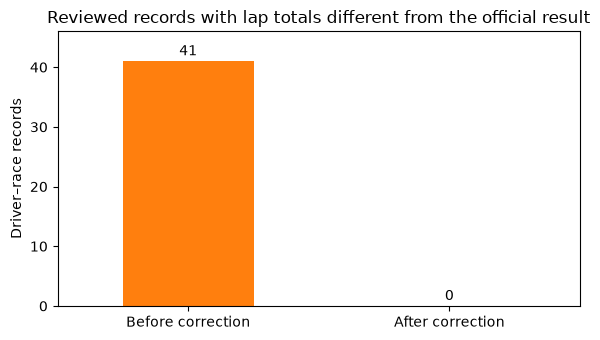

Raw comparison: 90 differences. Clean comparison: 49 differences remain.


In [192]:
# Plot only the 41 reviewed records, against the official values.
wrong_before = results_lap_corrections["Raw laps"].ne(results_lap_corrections["Official laps"]).sum()
wrong_after = results_lap_corrections["Clean laps"].ne(results_lap_corrections["Official laps"]).sum()
ax = pd.Series({"Before correction": wrong_before, "After correction": wrong_after}).plot(
    kind="bar", color=["tab:orange", "tab:green"], figsize=(6, 3.5), rot=0
)
ax.set_title("Reviewed records with lap totals different from the official result")
ax.set_ylabel("Driver–race records")
ax.set_ylim(0, 46)
for i, count in enumerate([wrong_before, wrong_after]):
    ax.text(i, count + 1, str(count), ha="center")
plt.tight_layout()
plt.show()

# Compare the same covered driver–race pairs after the correction.
results_lap_check_after = results_clean[["raceId", "driverId", "laps"]].merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index(),
    on=["raceId", "driverId"], validate="one_to_one"
)
remaining_lap_count_differences = results_lap_check_after.loc[
    results_lap_check_after["laps"].ne(results_lap_check_after["Timing rows"])
].copy()
assert len(remaining_lap_count_differences) == 49
print("Raw comparison: 90 differences. Clean comparison: 49 differences remain.")


### Position after the first 41 corrections

- **Fixed:** 41 verified completed-lap totals in the existing `results_clean.laps` column. No result rows, timing rows, driver IDs, positions, points or statuses were changed by this correction.
- **20 China 2014 differences:** explained by the early finishing flag and classified race distance. Preserve them.
- **11 suspected driver-assignment differences:** investigate lap charts before changing driver IDs. Similar counts alone do not prove who owns each time.
- **16 timing-coverage differences:** official classifications confirm more completed laps than the local timing rows. The cause and exact missing timings still need investigation; do not invent durations.
- **1 Brazil 2024 difference:** Hülkenberg was disqualified; the [FIA timing document, page 11](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf) records 30 laps. The zero in raw results must not be read as proof that he did not start. Preserve it pending a separate policy for disqualified-result lap totals.
- **1 unresolved difference:** Monteiro, Germany 2006. Obtain stronger evidence before changing its lap total.

These remaining groups total **49 differences**. The two positive-lap result entries with no timing rows (Alesi, Italy 2001; Alguersuari, Italy 2009) are still open separately; they are not part of the original 90 matched-pair differences. The earlier `lap_unresolved_count_discrepancies` variable is a **pre-correction raw-data investigation list**. Use `remaining_lap_count_differences` for the updated count.

This is an intermediate summary. The investigation below checks the remaining cases and updates these decisions.


### Complete investigation of lap-count differences

#### 1. Check that we are comparing the same information

The [Jolpica results documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/results.md), for the successor to Ergast, defines `laps` as **the laps this driver completed**. The [lap-data documentation](https://github.com/jolpica/jolpica-f1/blob/main/docs/endpoints/laps.md) describes individual numbered laps and timing records.

A driver can complete 18 laps and stop during lap 19. We compare **completed-lap totals**, not the lap mentioned in a retirement report. A timing-row count is a consistency check, not automatically a replacement value. In China 2014, classified distance differs from recorded timing distance; that exception must remain.

The first 41 official observations above were rechecked against the actual classification rows on **12 October 2026**. Driver, race year, event and completed-lap total were matched. The timing counts also agree with those observations. This verifies the corrected totals, not every individual timing value.

The notebook contains fixed source observations so it runs on Kaggle without downloading websites. The audit compares local data programmatically with these observations. Source URLs let the reviewer inspect each reference.

#### 2. Test the suspected 2001 driver mix-up using every recorded lap time

Across Hungary, Belgium, Italy, USA and Japan 2001, Alesi and Trulli have incorrect timing assignments. We used the contemporary **Atlas F1 lap-time charts**, whose footer attributes the raw timing data to the FIA. This is a historical mirror of FIA timing, not a current FIA-hosted document.

We extracted the full sequences under each driver's name, excluding the chart's `999:999` no-time markers. **All 449 local lap durations match the other driver's chart sequence exactly, at the same lap number.** This is much stronger than two totals happening to match. Official F1 classifications also confirm the drivers' completed-lap totals.

We correct `driverId` only in these nine existing timing groups. The lap number, position, time and milliseconds stay attached to the same record. No timing rows are created or deleted. In Italy, the 52 rows wrongly labelled Trulli become Alesi's rows; Trulli completed zero laps.


In [193]:
# Fixed source observations: milliseconds for each numbered lap in the chart.
# Key is "raceId:correct driverId"; list order means laps 1, 2, 3, ...
source_2001_lap_times = {
  "153:15": [
    88062,
    81259,
    80808,
    80721,
    80641,
    80669,
    80825,
    80963,
    80521,
    80390,
    80327,
    80445,
    80783,
    80500,
    80478,
    80404,
    80711,
    80703,
    80640,
    80772,
    80326,
    80568,
    80980,
    81357,
    81640,
    80973,
    81188,
    81409,
    84940,
    107893,
    79020,
    79183,
    81284,
    80190,
    80540,
    81740,
    80209,
    80349,
    80767,
    79926,
    80161,
    80598,
    82339,
    80467,
    80521,
    80400,
    80658,
    83166,
    102836,
    78536,
    78868,
    79278,
    79631
  ],
  "153:55": [
    93615,
    82648,
    82280,
    81930,
    82166,
    82385,
    82604,
    83457,
    83995,
    81971,
    80868,
    81538,
    80556,
    80767,
    80793,
    79889,
    80002,
    79997,
    80765,
    80227,
    80245,
    80353,
    80520,
    80247,
    80048,
    80633,
    80103,
    80030,
    80519,
    83983,
    103982,
    79134,
    79755,
    80100,
    80510,
    81280,
    83273,
    81360,
    80540,
    81057,
    80787,
    79899,
    79918,
    81767,
    80495,
    79741,
    79464,
    79334,
    79398,
    79533,
    82884,
    103773,
    79615,
    80597,
    80289,
    80129,
    80929,
    80361,
    80442,
    80269,
    80383,
    80969,
    81242,
    81158,
    80029,
    81078,
    80005,
    80197,
    81346,
    82231,
    80769,
    83101,
    79516,
    80385,
    79903
  ],
  "154:15": [
    120736,
    113632,
    112353,
    111828,
    111975,
    119456,
    128586,
    112413,
    112280,
    112542,
    112569,
    113158,
    113114,
    113276,
    113331,
    113503,
    113358,
    115251,
    120483,
    133434,
    113108,
    112938,
    113358,
    113413,
    113406,
    113484,
    113689,
    113637,
    113718,
    113667,
    113991
  ],
  "154:55": [
    121334,
    113747,
    114139,
    112253,
    111996,
    112228,
    119357,
    129677,
    112839,
    112881,
    112617,
    112957,
    112855,
    113522,
    113163,
    113533,
    113452,
    115720,
    113871,
    120103,
    130376,
    113455,
    113252,
    113307,
    113434,
    113704,
    113848,
    113927,
    114271,
    113991,
    113843,
    117769,
    114642,
    114207,
    114246,
    114170
  ],
  "155:55": [
    99178,
    89227,
    90216,
    88093,
    88740,
    88098,
    88923,
    88158,
    88098,
    88669,
    88837,
    88901,
    88540,
    88515,
    88048,
    87452,
    86943,
    86614,
    86928,
    87031,
    87052,
    90147,
    110198,
    87733,
    86865,
    86619,
    86934,
    86365,
    87313,
    87282,
    87401,
    90892,
    113358,
    89027,
    87709,
    88788,
    86969,
    87587,
    87696,
    87702,
    87655,
    87567,
    87472,
    89903,
    87722,
    87858,
    87515,
    89449,
    87490,
    87119,
    86802,
    87289
  ],
  "156:15": [
    85958,
    78819,
    77643,
    77167,
    77384,
    77577,
    77372,
    77366,
    77634,
    77364,
    76637,
    76601,
    76920,
    76837,
    76906,
    76756,
    76573,
    76510,
    76345,
    76348,
    76069,
    76130,
    76116,
    76118,
    75970,
    76190,
    75831,
    75958,
    75731,
    75936,
    75881,
    75862,
    76438,
    76338,
    76124,
    76396,
    76689,
    76559,
    106857,
    80539,
    76179,
    76746,
    76429,
    76516,
    76671,
    76579,
    76747,
    76626,
    76638,
    76480,
    76653,
    76462,
    76562,
    76522,
    76187,
    75820,
    75737,
    75497,
    75515,
    75547,
    75571,
    76144,
    75199,
    75230,
    75514,
    75310,
    75474,
    75370,
    75486,
    75665,
    75824,
    76463,
    78451
  ],
  "156:55": [
    88292,
    78146,
    77809,
    77359,
    77414,
    77582,
    77525,
    77547,
    78029,
    78070,
    77867,
    77818,
    77425,
    76993,
    77293,
    76890,
    77593,
    76754,
    76498,
    76329,
    76465,
    76336,
    76074,
    76284,
    76104,
    76359,
    76065,
    76067,
    76044,
    75902,
    76195,
    76137,
    76127,
    75911,
    75813,
    75949,
    106504,
    80841,
    76860,
    77063,
    77245,
    78067,
    77443,
    77330,
    77137,
    78086,
    77471,
    77371,
    77629,
    78235,
    77003,
    76931,
    77094,
    76852,
    76610,
    76437,
    76188,
    76053,
    75920,
    76054,
    77983,
    78177,
    76084,
    75843,
    76098,
    75754,
    75659,
    76173,
    79537,
    76278,
    76064,
    75732
  ],
  "157:15": [
    107817,
    100144,
    100382,
    99786,
    99691,
    99890,
    99639,
    99547,
    99507,
    99472,
    99303,
    99597,
    100121,
    100087,
    99982,
    104222,
    123182,
    99785,
    99752,
    99796,
    99671,
    100103,
    100293,
    101160,
    100209,
    99965,
    99406,
    98857,
    98936,
    99073,
    99126,
    99141,
    103197,
    123685,
    99491,
    100557,
    100305,
    100804,
    100363,
    100195,
    100206,
    100368,
    100364,
    101452,
    100440,
    100027,
    102301,
    100285,
    101506,
    99871,
    100305,
    100452
  ],
  "157:55": [
    109511,
    101046,
    101495,
    100225,
    100347
  ]
}

# Each mapping applies only to this race, not to the driver's other races.
lap_driver_corrections = pd.DataFrame([
    (153, 15, 55),
    (153, 55, 15),
    (154, 15, 55),
    (154, 55, 15),
    (155, 15, 55),
    (156, 15, 55),
    (156, 55, 15),
    (157, 15, 55),
    (157, 55, 15),
], columns=["raceId", "Old driverId", "New driverId"])
lap_chart_rounds = {153: 13, 154: 14, 155: 15, 156: 16, 157: 17}
lap_identity_checks = []
lap_identity_samples = []
for _, correction in lap_driver_corrections.iterrows():
    race_id = int(correction["raceId"])
    old_id = int(correction["Old driverId"])
    new_id = int(correction["New driverId"])
    local = lap_times.loc[
        lap_times["raceId"].eq(race_id) & lap_times["driverId"].eq(old_id)
    ].sort_values("lap")
    source_times = source_2001_lap_times[f"{race_id}:{new_id}"]
    assert local["lap"].tolist() == list(range(1, len(source_times) + 1))
    every_time_matches = local["milliseconds"].tolist() == source_times
    assert every_time_matches
    source_url = f"https://www.atlasf1.com/2001/laptimes.html?raceid={lap_chart_rounds[race_id]}"
    lap_identity_checks.append({
        "raceId": race_id, "Old driverId": old_id, "New driverId": new_id,
        "Compared laps": len(local), "Every time matches": every_time_matches,
        "Source": source_url
    })
    for lap_number in [1, 2, len(source_times)]:
        lap_identity_samples.append({
            "raceId": race_id, "Old driverId": old_id, "New driverId": new_id,
            "lap": lap_number,
            "Local seconds": local.loc[local["lap"].eq(lap_number), "milliseconds"].iloc[0] / 1000,
            "Chart seconds": source_times[lap_number - 1] / 1000
        })
lap_identity_checks = pd.DataFrame(lap_identity_checks)
lap_identity_samples = pd.DataFrame(lap_identity_samples)
assert lap_identity_checks["Compared laps"].sum() == 449
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(lap_identity_checks)
    display(lap_identity_samples)


,raceId,Old driverId,New driverId,Compared laps,Every time matches,Source
0,153,15,55,75,True,https://www.atlasf1.com/2001/laptimes.html?raceid=13
1,153,55,15,53,True,https://www.atlasf1.com/2001/laptimes.html?raceid=13
2,154,15,55,36,True,https://www.atlasf1.com/2001/laptimes.html?raceid=14
3,154,55,15,31,True,https://www.atlasf1.com/2001/laptimes.html?raceid=14
4,155,15,55,52,True,https://www.atlasf1.com/2001/laptimes.html?raceid=15
5,156,15,55,72,True,https://www.atlasf1.com/2001/laptimes.html?raceid=16
6,156,55,15,73,True,https://www.atlasf1.com/2001/laptimes.html?raceid=16
7,157,15,55,5,True,https://www.atlasf1.com/2001/laptimes.html?raceid=17
8,157,55,15,52,True,https://www.atlasf1.com/2001/laptimes.html?raceid=17


,raceId,Old driverId,New driverId,lap,Local seconds,Chart seconds
0,153,15,55,1,93.615,93.615
1,153,15,55,2,82.648,82.648
2,153,15,55,75,79.903,79.903
3,153,55,15,1,88.062,88.062
4,153,55,15,2,81.259,81.259
5,153,55,15,53,79.631,79.631
6,154,15,55,1,121.334,121.334
7,154,15,55,2,113.747,113.747
8,154,15,55,36,114.170,114.170
9,154,55,15,1,120.736,120.736


In [194]:
# Use the original IDs as the mask so swaps cannot overwrite each other.
# This also makes rerunning the correction safe.
assert lap_times_clean.index.equals(lap_times.index)
lap_times_before_identity_fix = lap_times.copy(deep=True)
lap_times_before_identity_fix["time"] = lap_times_before_identity_fix["milliseconds"] / 1000
for _, correction in lap_driver_corrections.iterrows():
    match = (lap_times["raceId"].eq(correction["raceId"])
             & lap_times["driverId"].eq(correction["Old driverId"]))
    lap_times_clean.loc[match, "driverId"] = int(correction["New driverId"])

pd.testing.assert_frame_equal(
    lap_times_before_identity_fix.drop(columns="driverId"),
    lap_times_clean.drop(columns="driverId")
)
assert lap_times_clean.shape == lap_times.shape == (589081, 6)
assert lap_times_clean.columns.equals(lap_times.columns)
assert lap_times_clean["driverId"].ne(lap_times["driverId"]).sum() == 449
assert not lap_times_clean.duplicated(["raceId", "driverId", "lap"]).any()

# Show all affected driver-race totals, including Alesi's previously absent group.
identity_pairs = pd.concat([
    lap_driver_corrections[["raceId", "Old driverId"]].rename(columns={"Old driverId": "driverId"}),
    lap_driver_corrections[["raceId", "New driverId"]].rename(columns={"New driverId": "driverId"})
]).drop_duplicates()
lap_identity_before_after = identity_pairs.merge(
    lap_times.groupby(["raceId", "driverId"]).size().rename("Rows before").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(
    lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Rows after").reset_index(),
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(results_clean[["raceId", "driverId", "laps"]], on=["raceId", "driverId"], validate="one_to_one")
# Zero represents a count of existing records, not a filled timing value.
lap_identity_before_after[["Rows before", "Rows after"]] = (
    lap_identity_before_after[["Rows before", "Rows after"]].fillna(0).astype(int)
)
lap_identity_before_after = lap_identity_before_after.merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(races_clean[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert lap_identity_before_after["Rows after"].eq(lap_identity_before_after["laps"]).all()
display(lap_identity_before_after[["raceId", "year", "name", "forename", "surname", "Rows before", "Rows after", "laps"]])


,raceId,year,name,forename,surname,Rows before,Rows after,laps
0,153,2001,Hungarian Grand Prix,Jarno,Trulli,75,53,53
1,153,2001,Hungarian Grand Prix,Jean,Alesi,53,75,75
2,154,2001,Belgian Grand Prix,Jarno,Trulli,36,31,31
3,154,2001,Belgian Grand Prix,Jean,Alesi,31,36,36
4,155,2001,Italian Grand Prix,Jarno,Trulli,52,0,0
5,156,2001,United States Grand Prix,Jarno,Trulli,72,73,73
6,156,2001,United States Grand Prix,Jean,Alesi,73,72,72
7,157,2001,Japanese Grand Prix,Jarno,Trulli,5,52,52
8,157,2001,Japanese Grand Prix,Jean,Alesi,52,5,5
9,155,2001,Italian Grand Prix,Jean,Alesi,0,52,52


#### 3. Hülkenberg, Brazil 2024: a disqualified driver still completed laps

The [FIA sector analysis, page 11](https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf) lists car 27, Nico Hülkenberg, with laps 1–30. All **29 duration values for laps 2–30** exactly match our timing records. The first lap is shown as a clock time in this document, so we do not claim to independently verify its duration from that field.

The [FIA decision, document 75](https://www.fia.com/sites/default/files/decision-document/2024%20S%C3%A3o%20Paulo%20Grand%20Prix%20-%20Infringement%20-%20Car%2027%20-%20Physical%20assistance.pdf) confirms disqualification for receiving outside assistance. Disqualification removes the valid race result; it does not mean the driver never raced.

**Decision:** use **30 observed completed laps** in `results_clean.laps`, consistent with the completed-lap definition. Keep the disqualification status, finishing position, points and all timing rows unchanged. This is an explicit normalization of an exceptional zero in the source, not a claim that the official final classification awards him 30 classified laps. China 2014 remains a separately documented classified-distance exception.


In [195]:
hulk_source_milliseconds = [87576, 87180, 87959, 85532, 85155, 85526, 84701, 84425, 85084, 85005, 84372, 84796, 84910, 84845, 85646, 84397, 85094, 84415, 84354, 83764, 84062, 84583, 84756, 90410, 106643, 230215, 168684, 127542, 174656]
hulk_timing_check = lap_times_clean.loc[
    lap_times_clean["raceId"].eq(1141) & lap_times_clean["driverId"].eq(807)
    & lap_times_clean["lap"].between(2, 30), ["lap", "milliseconds"]
].sort_values("lap").copy()
hulk_timing_check["FIA milliseconds"] = hulk_source_milliseconds
assert hulk_timing_check["lap"].tolist() == list(range(2, 31))
assert hulk_timing_check["milliseconds"].eq(hulk_timing_check["FIA milliseconds"]).all()
display(hulk_timing_check)

hulk_match = results_clean["raceId"].eq(1141) & results_clean["driverId"].eq(807)
assert hulk_match.sum() == 1
hulk_other_values = results_clean.loc[hulk_match].drop(columns="laps").copy()
assert results_clean.loc[hulk_match, "laps"].isin([0, 30]).all()
results_clean.loc[hulk_match, "laps"] = 30
pd.testing.assert_frame_equal(hulk_other_values, results_clean.loc[hulk_match].drop(columns="laps"))
hulk_before_after = pd.DataFrame({
    "Table version": ["Raw", "Clean"], "Completed laps": [0, 30],
    "Timing rows": [30, 30], "Status": ["Disqualified", "Disqualified"]
})
display(hulk_before_after)


,lap,milliseconds,FIA milliseconds
585897,2,87576,87576
585898,3,87180,87180
585899,4,87959,87959
585900,5,85532,85532
585901,6,85155,85155
585902,7,85526,85526
585903,8,84701,84701
585904,9,84425,84425
585905,10,85084,85084
585906,11,85005,85005


,Table version,Completed laps,Timing rows,Status
0,Raw,0,30,Disqualified
1,Clean,30,30,Disqualified


#### 4. Investigate all 16 incomplete timing sequences

For each affected driver and race, the official F1 classification confirms `results.laps`, but fewer rows exist in `lap_times`. The table below also compares the **official fastest-lap number and exact time** with the same duration in our local table.

- In **8 sequences**, the official fastest-lap time exists at a different local lap number. Example: Petrov, Monaco 2010, official lap 60 at 76.405 seconds appears locally at lap 59. Therefore, the issue includes lap numbering; it is not safe to append missing rows at the end.
- Bourdais, Spain 2008, has no local row matching his official fastest time of 85.999 seconds at lap 6.
- In the other 7 sequences, the checked fastest-lap observation matches its local number. This confirms that one observation, not the complete sequence.

**Decision:** preserve the 16 sequences in `lap_times_clean`, record every affected pair below, and exclude them from the optional `lap_times_analysis_ready` view. Do not fill times with a mean/median or shift all lap numbers from one anchor. Recovering them requires a full authoritative lap chart; the exact missing timings and the cause of the incomplete extraction remain unknown. These timings are not inputs to the existing pre-race modeling table.


In [196]:
# Fixed observations transcribed from the official classifications and fastest-lap tables.
# The local matching-lap field is recalculated below, not assumed.
timing_coverage_evidence = pd.DataFrame([{'raceId': 21, 'driverId': 7, 'Official laps': 7, 'Official fastest lap': 6, 'Official fastest time': '1:25.999', 'Source': 'https://www.formula1.com/en/results/2008/races/828/spain/fastest-laps'}, {'raceId': 339, 'driverId': 5, 'Official laps': 46, 'Official fastest lap': 44, 'Official fastest time': '1:42.701', 'Source': 'https://www.formula1.com/en/results/2010/races/862/malaysia/fastest-laps'}, {'raceId': 342, 'driverId': 808, 'Official laps': 73, 'Official fastest lap': 60, 'Official fastest time': '1:16.405', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 812, 'Official laps': 70, 'Official fastest lap': 69, 'Official fastest time': '1:19.553', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 15, 'Official laps': 70, 'Official fastest lap': 69, 'Official fastest time': '1:19.340', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 5, 'Official laps': 58, 'Official fastest lap': 57, 'Official fastest time': '1:18.401', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 811, 'Official laps': 58, 'Official fastest lap': 58, 'Official fastest time': '1:20.130', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 342, 'driverId': 810, 'Official laps': 25, 'Official fastest lap': 19, 'Official fastest time': '1:22.255', 'Source': 'https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps'}, {'raceId': 348, 'driverId': 18, 'Official laps': 69, 'Official fastest lap': 61, 'Official fastest time': '1:24.205', 'Source': 'https://www.formula1.com/en/results/2010/races/871/hungary/fastest-laps'}, {'raceId': 349, 'driverId': 807, 'Official laps': 43, 'Official fastest lap': 28, 'Official fastest time': '1:51.864', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 20, 'Official laps': 43, 'Official fastest lap': 22, 'Official fastest time': '1:50.868', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 5, 'Official laps': 43, 'Official fastest lap': 23, 'Official fastest time': '1:55.797', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 810, 'Official laps': 43, 'Official fastest lap': 25, 'Official fastest time': '1:55.705', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 10, 'Official laps': 43, 'Official fastest lap': 31, 'Official fastest time': '1:55.268', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 15, 'Official laps': 43, 'Official fastest lap': 24, 'Official fastest time': '1:55.103', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}, {'raceId': 349, 'driverId': 29, 'Official laps': 42, 'Official fastest lap': 31, 'Official fastest time': '1:55.484', 'Source': 'https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps'}])
coverage_details = []
for _, observation in timing_coverage_evidence.iterrows():
    local = lap_times_clean.loc[
        lap_times_clean["raceId"].eq(observation["raceId"])
        & lap_times_clean["driverId"].eq(observation["driverId"])
    ]
    official_seconds = to_seconds(observation["Official fastest time"])
    matches = local.loc[local["milliseconds"].eq(round(official_seconds * 1000)), "lap"]
    coverage_details.append({
        **observation.to_dict(), "Timing rows": len(local),
        "Unrepresented lap count": int(observation["Official laps"]) - len(local),
        "Local matching lap": ", ".join(matches.astype(str)),
        "Finding": "Fastest time absent" if matches.empty else
                   "Fastest lap number differs" if not matches.eq(observation["Official fastest lap"]).any() else
                   "Fastest lap matches; coverage incomplete",
        "Classification source": observation["Source"].replace("fastest-laps", "race-result")
    })
timing_coverage_evidence = pd.DataFrame(coverage_details).merge(
    drivers_clean[["driverId", "forename", "surname"]], on="driverId", validate="many_to_one"
).merge(races_clean[["raceId", "year", "name"]], on="raceId", validate="many_to_one")
assert len(timing_coverage_evidence) == 16
assert timing_coverage_evidence["Unrepresented lap count"].gt(0).all()
assert timing_coverage_evidence["Finding"].eq("Fastest lap number differs").sum() == 8
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(timing_coverage_evidence[["raceId", "year", "name", "forename", "surname", "Official laps", "Timing rows",
        "Unrepresented lap count", "Official fastest lap", "Official fastest time", "Local matching lap", "Finding", "Source", "Classification source"]])


,raceId,year,name,forename,surname,Official laps,Timing rows,Unrepresented lap count,Official fastest lap,Official fastest time,Local matching lap,Finding,Source,Classification source
0,21,2008,Spanish Grand Prix,Sébastien,Bourdais,7,4,3,6,1:25.999,,Fastest time absent,https://www.formula1.com/en/results/2008/races/828/spain/fastest-laps,https://www.formula1.com/en/results/2008/races/828/spain/race-result
1,339,2010,Malaysian Grand Prix,Heikki,Kovalainen,46,44,2,44,1:42.701,44,Fastest lap matches; coverage incomplete,https://www.formula1.com/en/results/2010/races/862/malaysia/fastest-laps,https://www.formula1.com/en/results/2010/races/862/malaysia/race-result
2,342,2010,Monaco Grand Prix,Vitaly,Petrov,73,72,1,60,1:16.405,59,Fastest lap number differs,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
3,342,2010,Monaco Grand Prix,Karun,Chandhok,70,68,2,69,1:19.553,67,Fastest lap number differs,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
4,342,2010,Monaco Grand Prix,Jarno,Trulli,70,68,2,69,1:19.340,67,Fastest lap number differs,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
5,342,2010,Monaco Grand Prix,Heikki,Kovalainen,58,57,1,57,1:18.401,56,Fastest lap number differs,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
6,342,2010,Monaco Grand Prix,Bruno,Senna,58,56,2,58,1:20.130,56,Fastest lap number differs,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
7,342,2010,Monaco Grand Prix,Lucas,di Grassi,25,23,2,19,1:22.255,19,Fastest lap matches; coverage incomplete,https://www.formula1.com/en/results/2010/races/865/monaco/fastest-laps,https://www.formula1.com/en/results/2010/races/865/monaco/race-result
8,348,2010,Hungarian Grand Prix,Jenson,Button,69,68,1,61,1:24.205,61,Fastest lap matches; coverage incomplete,https://www.formula1.com/en/results/2010/races/871/hungary/fastest-laps,https://www.formula1.com/en/results/2010/races/871/hungary/race-result
9,349,2010,Belgian Grand Prix,Nico,Hülkenberg,43,42,1,28,1:51.864,28,Fastest lap matches; coverage incomplete,https://www.formula1.com/en/results/2010/races/872/belgium/fastest-laps,https://www.formula1.com/en/results/2010/races/872/belgium/race-result


#### 5. Italy 2009: stronger evidence, but no complete sequence verification

The [official classification](https://www.formula1.com/en/results/2009/races/855/italy/race-result) records Buemi with 52 laps, Alguersuari with 19, and Webber with zero. The [official fastest-lap table](https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps) gives:

| Actual driver | Official fastest lap | Exact time | Local sequence carrying it |
|---|---:|---:|---|
| Buemi | 50 | 85.564 seconds | Webber, 52 rows |
| Alguersuari | 17 | 87.846 seconds | Buemi, 19 rows |

The matching driver-specific time, lap number and completed-lap count strongly support an identity problem. However, we have not independently compared the full sequences with an authoritative chart. **Preserve the original IDs for now and exclude these two existing groups from `lap_times_analysis_ready`.** Alguersuari's missing group remains explicitly linked to this investigation, not treated as an unrelated missing driver.


In [197]:
italy_2009_evidence = pd.DataFrame([
    (13, 17, "Webber", "Buemi", 52, 50, 85564),
    (13, 67, "Buemi", "Alguersuari", 19, 17, 87846)
], columns=["raceId", "Local driverId", "Local driver", "Official driver", "Official laps", "Official fastest lap", "Official milliseconds"])
italy_2009_details = []
for _, observation in italy_2009_evidence.iterrows():
    local = lap_times_clean.loc[
        lap_times_clean["raceId"].eq(13) & lap_times_clean["driverId"].eq(observation["Local driverId"])
    ]
    match = local.loc[local["lap"].eq(observation["Official fastest lap"])]
    assert len(match) == 1
    assert match["milliseconds"].iloc[0] == observation["Official milliseconds"]
    assert len(local) == observation["Official laps"]
    italy_2009_details.append({**observation.to_dict(), "Local rows": len(local),
                               "Local milliseconds at this lap": match["milliseconds"].iloc[0],
                               "Action": "Preserve; full-chart verification still needed"})
italy_2009_evidence = pd.DataFrame(italy_2009_details)
display(italy_2009_evidence)


,raceId,Local driverId,Local driver,Official driver,Official laps,Official fastest lap,Official milliseconds,Local rows,Local milliseconds at this lap,Action
0,13,17,Webber,Buemi,52,50,85564,52,85564,Preserve; full-chart verification still needed
1,13,67,Buemi,Alguersuari,19,17,87846,19,87846,Preserve; full-chart verification still needed


#### 6. Monteiro, Germany 2006: separate evidence strength from confidence

Our raw result says 66 laps, while 65 timing rows exist. The [Toyota F1 official race-result archive](https://toyotagazooracing.com/archive/ms/public/en/gp/12_germany/result/race.html) confirms disqualification but leaves the lap total blank. The [Grandprix.com contemporary classification](https://www.grandprix.com/races/german-gp-2006-race-results.html) and [GP Racing Stats](https://gpracingstats.com/seasons/2006-world-championship/2006-german-grand-prix/) both report 65.

**Decision:** 65 is supported by the local timings and two historical publications, but we do not call it an officially verified total. Keep 66 unchanged in `results_clean` and keep the disqualification. Include the pair in the distance/sequence review list and exclude it from the optional analysis-ready timing view until primary numeric evidence is found. The sources could share an upstream record, so agreement alone is not proof of independence.

#### 7. China 2014: preserve a verified difference in meaning

The [official classification note](https://www.formula1.com/en/results/2014/races/901/china/race-result) says the result was declared at lap 54 of 56 after the early chequered flag. Our 20 finishing-driver timing sequences exceed their classified totals by two. **Keep both measurements.** Removing the extra timings or increasing classified laps would erase valid information.


In [198]:
monteiro_review = pd.DataFrame({
    "raceId": [64], "driverId": [33], "Raw/clean result laps": [66],
    "Timing rows": [int((lap_times_clean["raceId"].eq(64) & lap_times_clean["driverId"].eq(33)).sum())],
    "Historical publications report": [65],
    "Official archive": ["Disqualified; numeric lap total blank"],
    "Decision": ["Preserve pending primary numeric evidence"]
})
display(monteiro_review)

# A separate review list: no flags or helper columns are added to the clean table.
lap_timing_review_pairs = pd.concat([
    timing_coverage_evidence[["raceId", "driverId"]].assign(Reason="Incomplete coverage / lap numbering needs full chart"),
    pd.DataFrame({"raceId": [13, 13], "driverId": [17, 67],
                  "Reason": ["Suspected identity issue; full chart needed"] * 2}),
    pd.DataFrame({"raceId": [64], "driverId": [33],
                  "Reason": ["Completed-lap count not primarily verified"]})
], ignore_index=True)
assert len(lap_timing_review_pairs) == 19
review_index = pd.MultiIndex.from_frame(lap_timing_review_pairs[["raceId", "driverId"]])
timing_index = pd.MultiIndex.from_frame(lap_times_clean[["raceId", "driverId"]])
lap_times_analysis_ready = lap_times_clean.loc[~timing_index.isin(review_index)].copy()
print("Clean timing rows retained:", len(lap_times_clean))
print("Rows held out from the optional analysis view:", len(lap_times_clean) - len(lap_times_analysis_ready))
print("Analysis-view rows:", len(lap_times_analysis_ready))
print("The existing model does not use lap_times; this view does not change its inputs.")


,raceId,driverId,Raw/clean result laps,Timing rows,Historical publications report,Official archive,Decision
0,64,33,66,65,65,Disqualified; numeric lap total blank,Preserve pending primary numeric evidence


Clean timing rows retained: 589081
Rows held out from the optional analysis view: 887
Analysis-view rows: 588194
The existing model does not use lap_times; this view does not change its inputs.


#### 8. Final before-and-after checks

The graph below follows the same cross-table check through each stage. It does not prove correctness by itself; the source comparisons above justify each action.

After correcting 41 totals, nine timing assignments, and Hülkenberg's completed-lap total, **39 count differences remain**: 20 explained China cases and 19 explicitly reviewed cases (16 incomplete sequences, two Italy 2009 groups, and Monteiro). Alesi's previously missing timing group is recovered by reassignment; Alguersuari's is still open.

The optional analysis view holds out entire unresolved sequences instead of fabricating lap times. The clean tables preserve their original columns. This is an explicit handling policy and a documented limitation, not a claim that the remaining data has been recovered. Positions/points/statuses used for the podium target were not changed by these corrections.


,Original discrepancy cases
41 corrected result totals,41
9 corrected timing assignments,9
1 normalized disqualified lap total,1
20 explained China differences,20
19 open cases with review policy,19


,raceId,driverId,laps
4721,13,153,19


,raceId,driverId,laps,Timing rows,Reason
0,21,7,7,4,Incomplete coverage / lap numbering needs full...
1,64,33,66,65,Completed-lap count not primarily verified
2,13,67,52,19,Suspected identity issue; full chart needed
3,13,17,0,52,Suspected identity issue; full chart needed
4,339,5,46,44,Incomplete coverage / lap numbering needs full...
5,342,808,73,72,Incomplete coverage / lap numbering needs full...
6,342,812,70,68,Incomplete coverage / lap numbering needs full...
7,342,15,70,68,Incomplete coverage / lap numbering needs full...
8,342,5,58,57,Incomplete coverage / lap numbering needs full...
9,342,811,58,56,Incomplete coverage / lap numbering needs full...


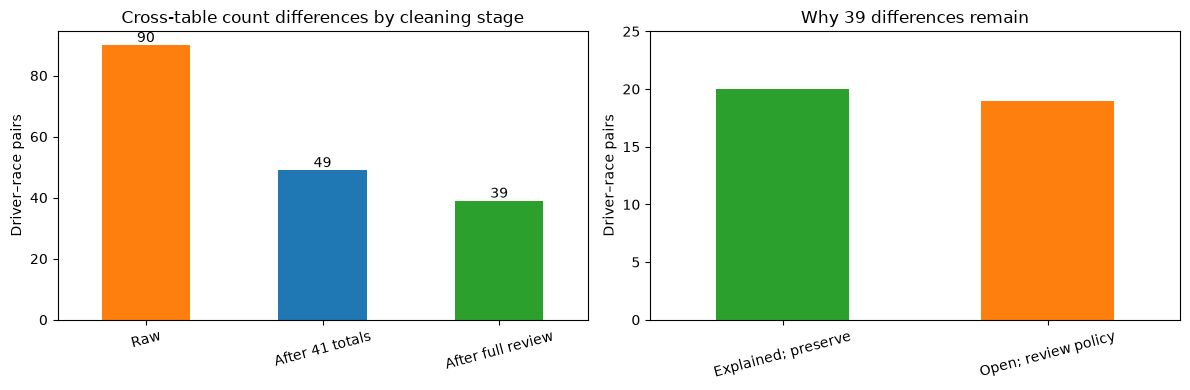

Final checks: 42 result lap totals changed; 449 timing driver IDs changed.
No timing rows added/deleted; timing durations unchanged; one positive-lap timing group still missing.


In [199]:
final_lap_pair_counts = lap_times_clean.groupby(["raceId", "driverId"]).size().rename("Timing rows").reset_index()
final_lap_audit = results_clean[["raceId", "driverId", "laps"]].merge(
    final_lap_pair_counts, on=["raceId", "driverId"], validate="one_to_one"
)
final_lap_differences = final_lap_audit.loc[final_lap_audit["laps"].ne(final_lap_audit["Timing rows"])].copy()
final_lap_differences = final_lap_differences.merge(
    lap_timing_review_pairs, on=["raceId", "driverId"], how="left", validate="one_to_one"
)
final_lap_differences.loc[final_lap_differences["raceId"].eq(903), "Reason"] = "China 2014: recorded versus classified distance"
assert len(final_lap_differences) == 39
assert final_lap_differences["Reason"].notna().all()
assert final_lap_differences["raceId"].eq(903).sum() == 20
remaining_lap_count_differences = final_lap_differences.copy()

final_positive_laps_without_timings = results_clean.loc[results_clean["raceId"].isin(
    races_clean.loc[races_clean["year"].ge(1996), "raceId"]
) & results_clean["laps"].gt(0)].merge(
    final_lap_pair_counts, on=["raceId", "driverId"], how="left", validate="one_to_one"
)
final_positive_laps_without_timings = final_positive_laps_without_timings.loc[
    final_positive_laps_without_timings["Timing rows"].isna()
]
assert final_positive_laps_without_timings[["raceId", "driverId"]].values.tolist() == [[13, 153]]

lap_resolution_summary = pd.Series({
    "41 corrected result totals": 41,
    "9 corrected timing assignments": 9,
    "1 normalized disqualified lap total": 1,
    "20 explained China differences": 20,
    "19 open cases with review policy": 19
}, name="Original discrepancy cases").to_frame()
assert lap_resolution_summary.iloc[:, 0].sum() == 90
display(lap_resolution_summary)
display(final_positive_laps_without_timings[["raceId", "driverId", "laps"]])
with pd.option_context("display.max_rows", None):
    display(final_lap_differences)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stages = pd.Series({"Raw": 90, "After 41 totals": 49, "After full review": len(final_lap_differences)})
stages.plot(kind="bar", ax=axes[0], color=["tab:orange", "tab:blue", "tab:green"], rot=15)
axes[0].set_title("Cross-table count differences by cleaning stage")
axes[0].set_ylabel("Driver–race pairs")
for i, value in enumerate(stages): axes[0].text(i, value + 1, str(value), ha="center")
pd.Series({"Explained; preserve": 20, "Open; review policy": 19}).plot(
    kind="bar", ax=axes[1], color=["tab:green", "tab:orange"], rot=15
)
axes[1].set_title("Why 39 differences remain")
axes[1].set_ylabel("Driver–race pairs")
axes[1].set_ylim(0, 25)
plt.tight_layout()
plt.show()

# Prove the final result changes are limited to the reviewed laps column.
raw_comparison = results_clean.merge(
    results[["resultId", "laps"]].rename(columns={"laps": "Raw laps"}),
    on="resultId", validate="one_to_one"
)
final_results_lap_changes = raw_comparison.loc[raw_comparison["laps"].ne(raw_comparison["Raw laps"])].copy()
assert len(final_results_lap_changes) == 42
print("Final checks: 42 result lap totals changed; 449 timing driver IDs changed.")
print("No timing rows added/deleted; timing durations unchanged; one positive-lap timing group still missing.")


#### Follow each original flag to its decision

The next table connects **every original cross-table count difference** to its investigation and decision. It shows the original two counts, the source used, and whether we corrected, explained, or preserved the case for further review. The graph before the corrections shows how we discovered the cases; this table shows what happened to each one.

The two positive-lap entries with no timing group were found by a separate **left join** from `results` to `lap_times`. They are listed separately because they are not part of the 90 matched-pair differences. Alesi's group is recovered by the verified 2001 reassignment. Alguersuari's missing group is linked to the Italy 2009 identity investigation and remains unresolved. We do not count these as two extra independent causes.

**What is finished:** the consistency checks, the evidence tables, the supported corrections, and the before/after checks. **What remains unresolved:** the 19 reviewed timing/count cases, including the Italy 2009 assignment problem. They remain visible in the clean data and are held out of the optional timing-analysis view. Recovering exact missing timings or changing uncertain assignments requires stronger source evidence; we do not invent values to make the tables agree.


In [200]:
# One decision for each original count flag; corrections must originate in that list.
lap_case_decisions = []
for _, row in verified_lap_totals.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Correct result laps", "Outcome": "Corrected", "Evidence source": row["Source"]})
for _, row in lap_identity_checks.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["Old driverId"],
        "Decision": "Reassign timing group to driverId " + str(int(row["New driverId"])),
        "Outcome": "Corrected", "Evidence source": row["Source"]})
hulk_pair = results.loc[
    results["driverId"].eq(807) & results["raceId"].isin(races_clean.loc[
        races_clean["year"].eq(2024) & races_clean["name"].eq("São Paulo Grand Prix"), "raceId"]),
    ["raceId", "driverId"]
]
assert len(hulk_pair) == 1
lap_case_decisions.append({**hulk_pair.iloc[0].to_dict(),
    "Decision": "Normalize completed laps to 30; keep disqualification", "Outcome": "Corrected",
    "Evidence source": "https://www.fia.com/sites/default/files/2024_21_bra_f1_r0_timing_racesectoranalysis_v01.pdf"})
for _, row in lap_consistency_flags_before.loc[lap_consistency_flags_before["raceId"].eq(903)].iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Keep recorded and classified distances", "Outcome": "Explained; preserved",
        "Evidence source": "https://www.formula1.com/en/results/2014/races/901/china/race-result"})
for _, row in timing_coverage_evidence.iterrows():
    lap_case_decisions.append({"raceId": row["raceId"], "driverId": row["driverId"],
        "Decision": "Preserve; full timing chart needed", "Outcome": "Open; held out of timing analysis",
        "Evidence source": row["Source"] + " | " + row["Classification source"]})
for driver_id in [17, 67]:
    lap_case_decisions.append({"raceId": 13, "driverId": driver_id,
        "Decision": "Preserve suspected wrong assignment; full chart needed",
        "Outcome": "Open; held out of timing analysis",
        "Evidence source": "https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps"})
lap_case_decisions.append({"raceId": 64, "driverId": 33,
    "Decision": "Preserve 66; primary numeric lap evidence needed",
    "Outcome": "Open; held out of timing analysis",
    "Evidence source": "https://toyotagazooracing.com/archive/ms/public/en/gp/12_germany/result/race.html | https://www.grandprix.com/races/german-gp-2006-race-results.html"})
lap_case_decisions = pd.DataFrame(lap_case_decisions)
assert len(lap_case_decisions) == 90
assert not lap_case_decisions.duplicated(["raceId", "driverId"]).any()
assert set(map(tuple, lap_case_decisions[["raceId", "driverId"]].values)) == set(
    map(tuple, lap_consistency_flags_before[["raceId", "driverId"]].values))
lap_consistency_case_log = lap_consistency_flags_before.merge(
    lap_case_decisions, on=["raceId", "driverId"], validate="one_to_one"
)
display(lap_consistency_case_log.groupby("Outcome").size().to_frame("Original flags"))
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(lap_consistency_case_log)

lap_missing_group_case_log = lap_missing_positive_entries[[
    "raceId", "driverId", "year", "name", "forename", "surname", "laps"
]].copy()
lap_missing_group_case_log["Finding"] = "Completed laps in results, but no timing group"
lap_missing_group_case_log["Decision"] = lap_missing_group_case_log["raceId"].map({
    155: "Recovered Alesi timings through full-chart verified reassignment",
    13: "Still missing; linked to the Italy 2009 assignment investigation"
})
assert lap_missing_group_case_log["Decision"].notna().all()
display(lap_missing_group_case_log)


,Original flags
Outcome,
Corrected,51
Explained; preserved,20
Open; held out of timing analysis,19


,raceId,driverId,year,name,forename,surname,Original result laps,Original timing rows,Count difference,Flag,Decision,Outcome,Evidence source
0,13,17,2009,Italian Grand Prix,Mark,Webber,0,52,52,More timing rows than completed laps,Preserve suspected wrong assignment; full chart needed,Open; held out of timing analysis,https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps
1,13,67,2009,Italian Grand Prix,Sébastien,Buemi,52,19,-33,Fewer timing rows than completed laps,Preserve suspected wrong assignment; full chart needed,Open; held out of timing analysis,https://www.formula1.com/en/results/2009/races/855/italy/fastest-laps
2,20,16,2008,Bahrain Grand Prix,Adrian,Sutil,56,55,-1,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2008/races/827/bahrain/race-result
3,21,7,2008,Spanish Grand Prix,Sébastien,Bourdais,7,4,-3,Fewer timing rows than completed laps,Preserve; full timing chart needed,Open; held out of timing analysis,https://www.formula1.com/en/results/2008/races/828/spain/fastest-laps | https://www.formula1.com/en/results/2008/races/828/spain/race-result
4,24,12,2008,Canadian Grand Prix,Nelson,Piquet Jr.,43,39,-4,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2008/races/831/canada/race-result
5,26,21,2008,British Grand Prix,Giancarlo,Fisichella,16,26,10,More timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2008/races/833/great-britain/race-result
6,40,24,2007,Monaco Grand Prix,Vitantonio,Liuzzi,2,1,-1,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2007/races/812/monaco/race-result
7,42,2,2007,United States Grand Prix,Nick,Heidfeld,56,55,-1,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2007/races/814/united-states/race-result
8,63,17,2006,French Grand Prix,Mark,Webber,55,53,-2,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2006/races/800/france/race-result
9,63,22,2006,French Grand Prix,Rubens,Barrichello,28,18,-10,Fewer timing rows than completed laps,Correct result laps,Corrected,https://www.formula1.com/en/results/2006/races/800/france/race-result


,raceId,driverId,year,name,forename,surname,laps,Finding,Decision
132,155,55,2001,Italian Grand Prix,Jean,Alesi,52,"Completed laps in results, but no timing group",Recovered Alesi timings through full-chart ver...
256,13,153,2009,Italian Grand Prix,Jaime,Alguersuari,19,"Completed laps in results, but no timing group",Still missing; linked to the Italy 2009 assign...


In [201]:
# Keep the imported helper flags consistent after the verified lap correction.
results_clean["grid0_raced"] = results_clean["grid"].eq(0) & results_clean["laps"].gt(0)
results_clean["in_population"] = ~results_clean["is_indy500"] & (results_clean["has_grid_slot"] | results_clean["grid0_raced"])


## 3.12 seasons.csv

### 3.12.0 Initial Loading & Baseline
Loading the seasons dataset, automatically parsing `\N` sentinels into standard missing values, and verifying the baseline structural integrity.

In [202]:
seasons_clean = pd.read_csv(DATA_DIR / "seasons.csv",na_values=[r"\N"]) 

In [203]:
seasons_clean.head()

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [204]:
seasons_clean.isnull().sum()

year    0
url     0
dtype: int64

In [205]:
seasons_clean.value_counts()

year  url                                                              
1950  http://en.wikipedia.org/wiki/1950_Formula_One_season                 1
2006  http://en.wikipedia.org/wiki/2006_Formula_One_season                 1
2004  http://en.wikipedia.org/wiki/2004_Formula_One_season                 1
2003  http://en.wikipedia.org/wiki/2003_Formula_One_season                 1
2002  http://en.wikipedia.org/wiki/2002_Formula_One_season                 1
                                                                          ..
1974  http://en.wikipedia.org/wiki/1974_Formula_One_season                 1
1973  http://en.wikipedia.org/wiki/1973_Formula_One_season                 1
1972  http://en.wikipedia.org/wiki/1972_Formula_One_season                 1
1971  http://en.wikipedia.org/wiki/1971_Formula_One_season                 1
2024  https://en.wikipedia.org/wiki/2024_Formula_One_World_Championship    1
Name: count, Length: 75, dtype: int64

## 3.13 sprint_results.csv

### 3.13.1 Baseline Loading & Time Conversions
Importing the sprint results, mapping missing placeholders, and defining a conversion function to transform textual durations (`time` and `fastestLapTime`) into strict numeric seconds.

In [206]:
sprint_results_clean =  pd.read_csv(DATA_DIR / "sprint_results.csv",na_values=[r"\N"])


In [207]:
sprint_results.isnull().sum()

resultId          0
raceId            0
driverId          0
constructorId     0
number            0
grid              0
position          0
positionText      0
positionOrder     0
points            0
laps              0
time              0
milliseconds      0
fastestLap        0
fastestLapTime    0
statusId          0
dtype: int64

In [208]:
sprint_results_clean.isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64

In [209]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ KB


In [210]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


In [211]:
sprint_results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


In [212]:
def time_to_seconds(x):
    if pd.isna(x):
        return np.nan
    parts = str(x).strip().lstrip("+").split(":")
    if not 1 <= len(parts) <= 3:
        raise ValueError(f"Unexpected duration: {x}")
    values = [float(part) for part in parts]
    if not all(np.isfinite(v) and v >= 0 for v in values) or any(v >= 60 for v in values[1:]):
        raise ValueError(f"Invalid duration: {x}")
    seconds = 0.0
    for value in values:
        seconds = seconds * 60 + value
    return seconds


In [213]:
# Keep time in one column and convert its values to numeric seconds.
# Winner: total duration. Other populated records: gap to the winner.
# These meanings must not be mixed when analyzing the column.
sprint_time_before = sprint_results_clean["time"].copy()
sprint_is_gap = sprint_time_before.astype("string").str.startswith("+", na=False)
# Check the total/gap pattern only before the first conversion.
if not pd.api.types.is_numeric_dtype(sprint_time_before):
    assert sprint_results_clean.loc[sprint_time_before.notna() & ~sprint_is_gap, "positionOrder"].eq(1).all()
sprint_results_clean["time"] = pd.to_numeric(sprint_time_before.map(time_to_seconds), errors="raise")
display(sprint_results_clean[["positionOrder", "time"]].head(10))


,positionOrder,time
0,1,1538.426
1,2,1.430
2,3,7.502
3,4,11.278
4,5,24.111
5,6,30.959
6,7,43.527
7,8,44.439
8,9,46.652
9,10,47.395


In [214]:
# Store lap duration in the existing column, in seconds.
sprint_lap_time_before = sprint_results_clean["fastestLapTime"].copy()
sprint_results_clean["fastestLapTime"] = pd.to_numeric(
    sprint_lap_time_before.map(time_to_seconds), errors="raise")
display(sprint_results_clean[["fastestLapTime"]].head(10))


,fastestLapTime
0,90.013
1,89.937
2,89.958
3,90.163
4,90.566
5,90.640
6,91.773
7,91.687
8,92.208
9,92.183


In [215]:
# Check that populated values survived conversion.
assert sprint_time_before.notna().equals(sprint_results_clean["time"].notna())
assert sprint_lap_time_before.notna().equals(sprint_results_clean["fastestLapTime"].notna())
print("Sprint time and fastestLapTime converted without losing populated values.")


Sprint time and fastestLapTime converted without losing populated values.


### Sprint timing: investigate missing values and fill with an unavailable code

The original CSV contains 20 missing `time` values and 20 missing `milliseconds` values in the same rows. These drivers completed fewer laps than the sprint winner. No final timing value was supplied; the dataset does not establish the exact reason for every omission. Both fastest-lap fields are missing together in 9 rows: 6 have zero completed laps and 3 have 1–2 completed laps. Zero completed laps does not prove a non-start; positive laps with absent fastest-lap information indicate an unrecorded measurement. Do not substitute Grand Prix lap times for sprint lap times.

**Treatment:** fill missing values in `time`, `milliseconds`, `fastestLap` and `fastestLapTime` with **-1 = unavailable in the source**. This is a documented placeholder, not a real measurement, a claimed cause, or a statistical estimate. Mean/median/interpolation would invent timings, and time mixes winner total duration with other recorded gaps. No rows or columns are removed. All originally populated values and the raw table remain unchanged.

**Use:** exclude -1 from timing statistics, comparisons and plots. Nonnegative timing values may be valid, including a zero gap; fastest-lap numbers and durations must be positive. Even after excluding -1, separate winner total time from follower gaps using the original text or positionOrder before interpreting time. No recovery of actual missing measurements is claimed. The fill is applied here, under sprint_results in data cleaning, after semantic conversion and before distribution plots and global validation.


Before filling: sprint records with unavailable timing


,raceId,driverId,laps,positionText,statusId,time,milliseconds,fastestLap,fastestLapTime
19,1061,815,16,R,76,NaN,NaN,6.0,91.465
39,1065,842,0,R,3,NaN,NaN,NaN,NaN
79,1077,855,0,R,31,NaN,NaN,NaN,NaN
98,1084,20,21,19,130,NaN,NaN,4.0,70.317
99,1084,4,0,N,10,NaN,NaN,NaN,NaN
119,1095,848,12,R,31,NaN,NaN,4.0,75.998
138,1101,852,2,R,130,NaN,NaN,NaN,NaN
139,1101,858,0,W,3,NaN,NaN,NaN,NaN
178,1110,815,8,R,130,NaN,NaN,2.0,122.516
179,1110,4,2,R,3,NaN,NaN,NaN,NaN


,Missing before,Missing after,Unavailable code (-1) after
time,20,0,20
milliseconds,20,0,20
fastestLap,9,0,9
fastestLapTime,9,0,9


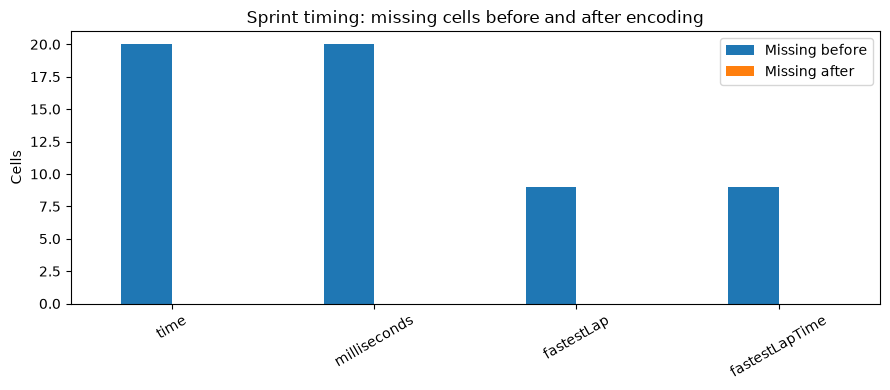

After filling: same records; -1 means unavailable


,raceId,driverId,laps,positionText,statusId,time,milliseconds,fastestLap,fastestLapTime
19,1061,815,16,R,76,-1.0,-1.0,6.0,91.465
39,1065,842,0,R,3,-1.0,-1.0,-1.0,-1.000
79,1077,855,0,R,31,-1.0,-1.0,-1.0,-1.000
98,1084,20,21,19,130,-1.0,-1.0,4.0,70.317
99,1084,4,0,N,10,-1.0,-1.0,-1.0,-1.000
119,1095,848,12,R,31,-1.0,-1.0,4.0,75.998
138,1101,852,2,R,130,-1.0,-1.0,-1.0,-1.000
139,1101,858,0,W,3,-1.0,-1.0,-1.0,-1.000
178,1110,815,8,R,130,-1.0,-1.0,2.0,122.516
179,1110,4,2,R,3,-1.0,-1.0,-1.0,-1.000


In [216]:
sprint_timing_columns = ["time", "milliseconds", "fastestLap", "fastestLapTime"]
sprint_timing_before_fill = sprint_results_clean[sprint_timing_columns].copy(deep=True)
sprint_other_columns_before_fill = sprint_results_clean.drop(columns=sprint_timing_columns).copy(deep=True)
sprint_missing_rows = sprint_timing_before_fill.isna().any(axis=1)
print("Before filling: sprint records with unavailable timing")
display(sprint_results_clean.loc[sprint_missing_rows,
    ["raceId", "driverId", "laps", "positionText", "statusId"] + sprint_timing_columns])
assert sprint_timing_before_fill["time"].isna().equals(sprint_timing_before_fill["milliseconds"].isna())
assert sprint_timing_before_fill["fastestLap"].isna().equals(sprint_timing_before_fill["fastestLapTime"].isna())
sprint_results_clean[sprint_timing_columns] = sprint_results_clean[sprint_timing_columns].fillna(-1)
for column in sprint_timing_columns:
    originally_present = sprint_timing_before_fill[column].notna()
    pd.testing.assert_series_equal(sprint_results_clean.loc[originally_present, column],
                                   sprint_timing_before_fill.loc[originally_present, column])
    assert sprint_results_clean.loc[~originally_present, column].eq(-1).all()
assert sprint_results_clean[sprint_timing_columns].notna().all().all()
pd.testing.assert_frame_equal(sprint_results_clean.drop(columns=sprint_timing_columns), sprint_other_columns_before_fill)
sprint_timing_fill_summary = pd.DataFrame({
    "Missing before": sprint_timing_before_fill.isna().sum(),
    "Missing after": sprint_results_clean[sprint_timing_columns].isna().sum(),
    "Unavailable code (-1) after": sprint_results_clean[sprint_timing_columns].eq(-1).sum()
})
display(sprint_timing_fill_summary)
sprint_timing_fill_summary[["Missing before", "Missing after"]].plot.bar(
    figsize=(9, 4), title="Sprint timing: missing cells before and after encoding", ylabel="Cells", rot=30)
plt.tight_layout()
plt.show()
print("After filling: same records; -1 means unavailable")
display(sprint_results_clean.loc[sprint_missing_rows,
    ["raceId", "driverId", "laps", "positionText", "statusId"] + sprint_timing_columns])


### 3.13.2 Duplication Auditing
Checking the composite key (`raceId`, `driverId`) to ensure no driver is incorrectly recorded twice in the same sprint event.

In [217]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            360 non-null    float64
 12  milliseconds    360 non-null    float64
 13  fastestLap      360 non-null    float64
 14  fastestLapTime  360 non-null    float64
 15  statusId        360 non-null    int64  
dtypes: float64(5), int64(10), object(1)
memory usage: 45.1+ KB


In [218]:
sprint_results_clean.duplicated(
    subset=["raceId", "driverId"]
).sum()

np.int64(0)

In [219]:
duplicates = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
]

duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId


### 3.13.3 Foreign Key Validation & Referential Integrity
Sprint resultId is this table's own primary key, not a reference to results.resultId. Check raceId, driverId, constructorId and statusId against their cleaned parent tables. Connect sprint and Grand Prix outcomes deliberately by raceId/driverId, never resultId.


In [220]:
# Map each foreign key to its referenced table and primary key
foreign_keys = {
    'raceId': (races_clean, 'raceId'),
    'driverId': (drivers_clean, 'driverId'),
    'constructorId': (constructors_clean, 'constructorId'),
    'statusId': (status_clean, 'statusId')
}

for sprint_fk_column, (reference_table, sprint_parent_key) in foreign_keys.items():
    # Values in the sprint table
    fk_values = sprint_results_clean[sprint_fk_column]

    # Values available in the referenced table
    pk_values = reference_table[sprint_parent_key]

    # Find foreign keys that do not exist in the referenced table
    invalid = fk_values.notna() & ~fk_values.isin(pk_values)

    print(f'\n--- {sprint_fk_column} -> {sprint_parent_key} ---')
    print(f'Total rows: {len(sprint_results_clean)}')
    print(f'Invalid foreign keys: {invalid.sum()}')
    print(f'Valid foreign keys: {(fk_values.notna() & ~invalid).sum()}')
    print(f'Missing foreign keys: {fk_values.isna().sum()}')

    if invalid.any():
        print('Invalid values:')
        print(fk_values[invalid].unique())
    else:
        print('All non-null foreign keys reference existing records.')
    assert fk_values.notna().all(), f"Missing sprint {sprint_fk_column}"
    assert not invalid.any(), f"Unmatched sprint {sprint_fk_column}"



--- raceId -> raceId ---
Total rows: 360
Invalid foreign keys: 0
Valid foreign keys: 360
Missing foreign keys: 0
All non-null foreign keys reference existing records.

--- driverId -> driverId ---
Total rows: 360
Invalid foreign keys: 0
Valid foreign keys: 360
Missing foreign keys: 0
All non-null foreign keys reference existing records.

--- constructorId -> constructorId ---
Total rows: 360
Invalid foreign keys: 0
Valid foreign keys: 360
Missing foreign keys: 0
All non-null foreign keys reference existing records.

--- statusId -> statusId ---
Total rows: 360
Invalid foreign keys: 0
Valid foreign keys: 360
Missing foreign keys: 0
All non-null foreign keys reference existing records.


In [221]:
for sprint_fk_column, (reference_table, sprint_parent_key) in foreign_keys.items():
    duplicate_count = reference_table[sprint_parent_key].duplicated().sum()

    print(f'{sprint_parent_key}: {duplicate_count} duplicate values')

    if duplicate_count > 0:
        print(reference_table.loc[
            reference_table[sprint_parent_key].duplicated(keep=False),
            [sprint_parent_key]
        ].sort_values(sprint_parent_key).drop_duplicates())

raceId: 0 duplicate values
driverId: 0 duplicate values
constructorId: 0 duplicate values
statusId: 0 duplicate values


### 3.13.4 Feature Distribution Analysis
Winner durations and follower gaps are plotted separately because they have different meanings. Each plot excludes unavailable codes; the car-number and outcome codes are never interpreted as continuous measurements.


In [222]:
sprint_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   resultId        360 non-null    int64 
 1   raceId          360 non-null    int64 
 2   driverId        360 non-null    int64 
 3   constructorId   360 non-null    int64 
 4   number          360 non-null    int64 
 5   grid            360 non-null    int64 
 6   position        360 non-null    object
 7   positionText    360 non-null    object
 8   positionOrder   360 non-null    int64 
 9   points          360 non-null    int64 
 10  laps            360 non-null    int64 
 11  time            360 non-null    object
 12  milliseconds    360 non-null    object
 13  fastestLap      360 non-null    object
 14  fastestLapTime  360 non-null    object
 15  statusId        360 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 45.1+ KB


In [223]:
sprint_results['position'].unique()

array(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '\\N', '20'],
      dtype=object)

In [224]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            360 non-null    float64
 12  milliseconds    360 non-null    float64
 13  fastestLap      360 non-null    float64
 14  fastestLapTime  360 non-null    float64
 15  statusId        360 non-null    int64  
dtypes: float64(5), int64(10), object(1)
memory usage: 45.1+ KB


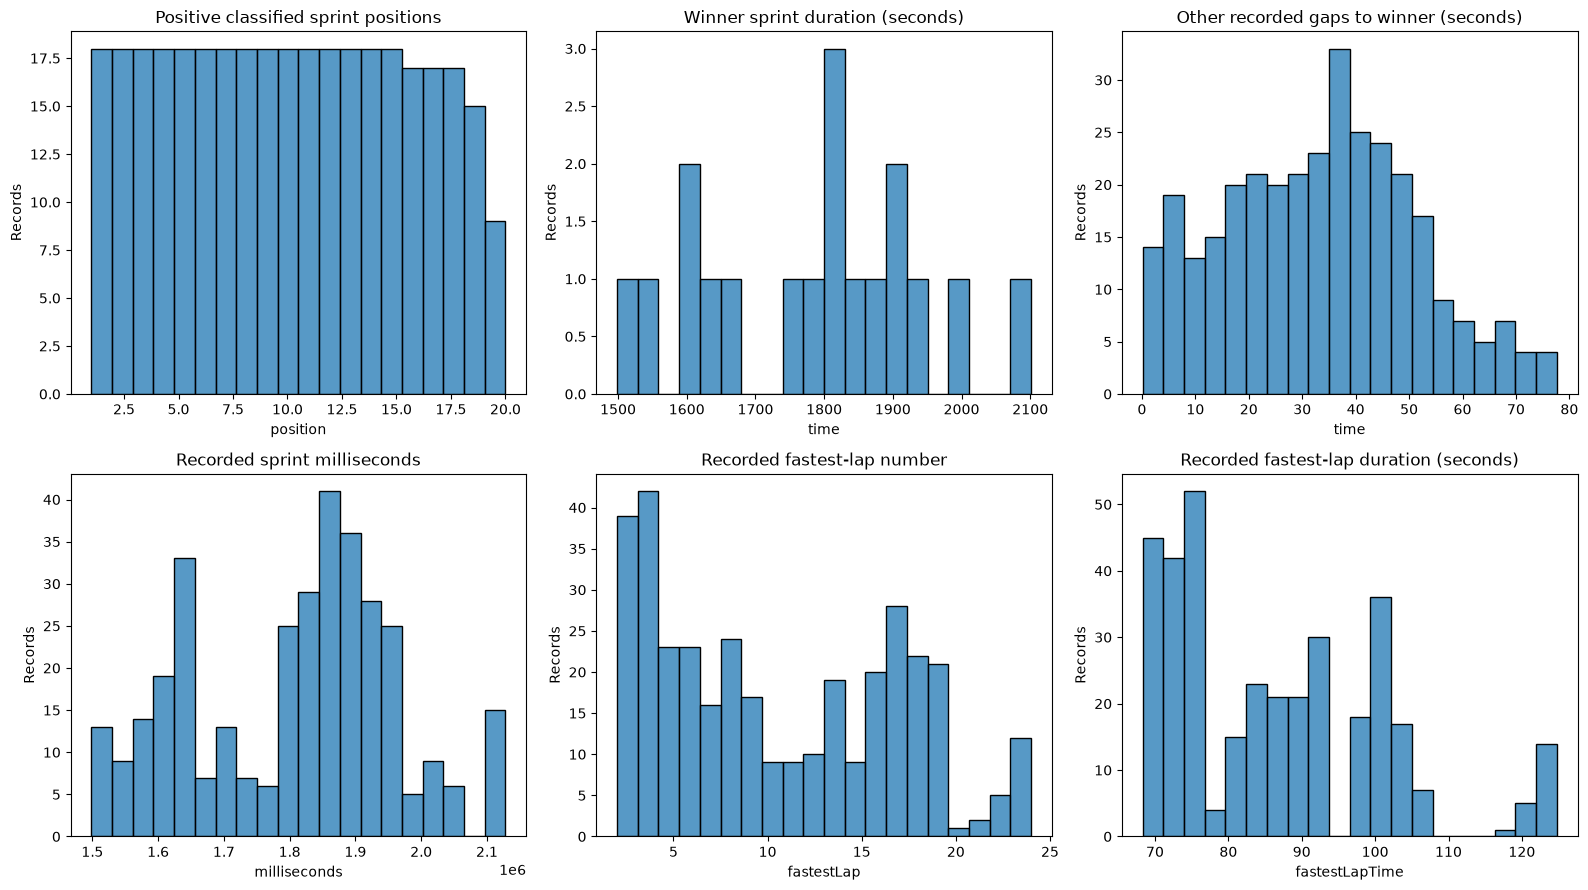

In [225]:
# All distributions use accumulated cleaned values; -1 is unavailable.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sprint_plot_specs = [
    ("position", sprint_results_clean["position"].gt(0), "Positive classified sprint positions"),
    ("time", sprint_results_clean["positionOrder"].eq(1) & sprint_results_clean["time"].ge(0), "Winner sprint duration (seconds)"),
    ("time", sprint_results_clean["positionOrder"].gt(1) & sprint_results_clean["time"].ge(0), "Other recorded gaps to winner (seconds)"),
    ("milliseconds", sprint_results_clean["milliseconds"].ge(0), "Recorded sprint milliseconds"),
    ("fastestLap", sprint_results_clean["fastestLap"].gt(0), "Recorded fastest-lap number"),
    ("fastestLapTime", sprint_results_clean["fastestLapTime"].gt(0), "Recorded fastest-lap duration (seconds)")
]
for ax, (column, keep, title) in zip(axes.flat, sprint_plot_specs):
    sns.histplot(data=sprint_results_clean.loc[keep], x=column, bins=20, kde=False, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Records")
plt.tight_layout()
plt.show()


## 3.14 status.csv

### 3.14.0 Initial Loading & Key Validation
Loading the final reference table, converting placeholders, and guaranteeing that the primary key (`statusId`) contains no duplicate entries.

In [226]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [227]:
# Already initialized for earlier relationship checks; do not reload/reset accumulated cleaning.
status_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


### Duration units in the cleaned tables

Conversions replace values in the existing columns; raw tables and CSV files retain their original values. `qualifying_clean.q1/q2/q3`, `results_clean.fastestLapTime` and `sprint_results_clean.fastestLapTime` are numeric **seconds**. `races_clean.time` is a pandas duration since midnight representing the scheduled time of day, not race duration.

`sprint_results_clean.time` is numeric seconds with the original field's meaning preserved: the winner's total duration, and other populated records' gaps to the winner. The conversion checks this pattern against `positionOrder`. Do not compare or average totals and gaps together. For a total sprint-duration analysis, use the existing `milliseconds` column where available, divided by 1000. Missing values remain missing. Run the notebook from the top so earlier loads recreate clean copies before conversion.
`results_clean.time` is also numeric seconds. In the original `results.time`, a leading `+` identifies a gap, while an unprefixed value is a total elapsed time. Removing the text prefix during conversion does not change that meaning: do not average totals and gaps together. Refer to the unchanged raw `results.time` using `resultId` when distinguishing them. Use `milliseconds / 1000` where available for total-duration comparisons; retain its missing values. No new columns are added.


In [228]:
status.isnull().sum()

statusId    0
status      0
dtype: int64

In [229]:
status.duplicated(subset=["statusId"]).sum()

np.int64(0)

### Final reference-table audit

The global validation below checks all cleaned tables, including status primary keys and incoming references. Earlier raw displays are baseline evidence; downstream calculations use the accumulated cleaned variables.


### Fill missing race and sprint positions using recorded outcomes

Positive `position` values remain classified positions. For missing positions with numeric `positionText`, recover the recorded number: Jenson Button (raceId 71, driverId 18) = 11 and Takuma Sato (raceId 71, driverId 11) = 14. In both rows, numeric positionText agrees with positionOrder. These are recovered values, not estimated averages.

For remaining missing positions, use these project-defined category codes:

| Code | positionText | Meaning |
|---:|---|---|
| -1 | R | Retired |
| -2 | F | Failed to qualify |
| -3 | W | Withdrew |
| -4 | D | Disqualified |
| -5 | E | Excluded |
| -6 | N | Not classified |

These negative values are category labels, not finishing ranks or verified reasons for missingness. Keep positionText for interpretation. Fill only missing values in results_clean and sprint_results_clean; preserve existing positive positions, float64 type, row counts, positionOrder, and raw source tables. No extra data column is added.

Podium targets and race-order analyses continue to use positionOrder. Never identify podiums with encoded position <= 3, because negative outcome codes satisfy that condition. Other tables' position columns (qualifying and championship standings) have separate meanings and are unchanged. Earlier missingness displays show the pre-treatment baseline; the comparison below shows the final treatment.

**Safe use:** classified-position checks and numeric position plots use `position > 0`, which works before and after outcome encoding. Missingness checks still use isna(), because they measure actual empty cells. Race/sprint outcome position fields are explicitly forbidden as model inputs.


In [230]:
position_outcome_codes = {"R": -1, "F": -2, "W": -3, "D": -4, "E": -5, "N": -6}
position_fill_summary = []
for table_name, table in [("results", results_clean), ("sprint_results", sprint_results_clean)]:
    position_before_fill = table["position"].copy()
    order_before_fill = table["positionOrder"].copy()
    text_before_fill = table["positionText"].copy()
    missing_position = position_before_fill.isna()
    text = table["positionText"].astype("string").str.strip()
    numeric_text = pd.to_numeric(text, errors="coerce")
    recover_numeric = missing_position & numeric_text.notna()
    assert numeric_text.loc[recover_numeric].eq(table.loc[recover_numeric, "positionOrder"]).all()
    if recover_numeric.any():
        print(table_name + ": recover numeric positions from positionText")
        display(table.loc[recover_numeric, ["raceId", "driverId", "position", "positionText", "positionOrder"]])
    table.loc[recover_numeric, "position"] = numeric_text.loc[recover_numeric].astype(float)
    encode_outcome = missing_position & numeric_text.isna()
    outcome_codes = text.map(position_outcome_codes)
    assert outcome_codes.loc[encode_outcome].notna().all(), "Unmapped positionText outcome"
    table.loc[encode_outcome, "position"] = outcome_codes.loc[encode_outcome].astype(float)
    assert table["position"].notna().all()
    assert table["position"].gt(0).eq(numeric_text.notna()).all()
    assert table.loc[table["position"].gt(0), "position"].eq(numeric_text.loc[table["position"].gt(0)]).all()
    assert table["position"].gt(0).all() or table.loc[table["position"].le(0), "position"].isin(position_outcome_codes.values()).all()
    pd.testing.assert_series_equal(table.loc[~missing_position, "position"], position_before_fill.loc[~missing_position])
    pd.testing.assert_series_equal(table["positionOrder"], order_before_fill)
    pd.testing.assert_series_equal(table["positionText"], text_before_fill)
    assert table.loc[encode_outcome, "position"].eq(outcome_codes.loc[encode_outcome]).all()
    assert table["position"].dtype == position_before_fill.dtype
    position_fill_summary.append({"Table": table_name, "Missing before": int(missing_position.sum()),
                                  "Numeric positions recovered": int(recover_numeric.sum()),
                                  "Outcome codes filled": int(encode_outcome.sum()),
                                  "Missing after": int(table["position"].isna().sum())})
    print(table_name + ": negative outcome-code counts")
    display(table.loc[table["position"].lt(0), ["position", "positionText"]].value_counts().rename("Rows"))
display(pd.DataFrame(position_fill_summary))
# Explicit checks for the two recovered race classifications.
for driver_id, expected_position in [(18, 11), (11, 14)]:
    recovered = results_clean.loc[results_clean["raceId"].eq(71) & results_clean["driverId"].eq(driver_id), "position"]
    assert len(recovered) == 1 and recovered.eq(expected_position).all()


results: recover numeric positions from positionText


,raceId,driverId,position,positionText,positionOrder
1148,71,18,NaN,11,11
1151,71,11,NaN,14,14


results: negative outcome-code counts


position  positionText
-1.0      R               8819
-2.0      F               1366
-3.0      W                335
-6.0      N                190
-4.0      D                151
-5.0      E                  9
Name: Rows, dtype: int64

sprint_results: negative outcome-code counts


position  positionText
-1.0      R               13
-6.0      N                1
-3.0      W                1
Name: Rows, dtype: int64

,Table,Missing before,Numeric positions recovered,Outcome codes filled,Missing after
0,results,10872,2,10870,0
1,sprint_results,15,0,15,0


### Recover missing event car numbers and encode unresolved values

`results_clean.number` identifies the car's number for that exact event. Four missing values are recovered from historical entry lists, matched by raceId and driverId:

| raceId | driverId | Driver | Event | Recovered number |
|---:|---:|---|---|---:|
| 732 | 462 | Colin Davis | France 1962 | 4 |
| 732 | 446 | Carlo Abate | France 1962 | 6 |
| 732 | 437 | Ian Burgess | France 1962 | 44 |
| 741 | 485 | Juan Manuel Bordeu | France 1961 | 28 |

Sources: [STATS F1 France 1962 entry list](https://www.statsf1.com/en/1962/france/engages.aspx) and [France 1961 entry list](https://www.statsf1.com/en/1961/france/engages.aspx). These are secondary historical records, not official FIA/F1 sources. Values are assigned event entry numbers; they do not imply these drivers started. No number is borrowed from another race or from drivers.number.

Tony Marsh (raceId 732, driverId 459) and Mike Hailwood (raceId 728, driverId 305) remain unverified. Their missing numbers are filled with **-1 = unknown event car number**. This is a project-defined category code, not an actual racing number or an estimate. Existing number 0 values are preserved because 0 is a genuine historical racing number. Car numbers are identifiers, not quantities or ranks.

Only the six missing numbers in results_clean are filled. Existing numbers, rows, other columns, raw results and CSV files remain unchanged. No additional column is introduced. The before/after table and assertions below document the treatment.


In [231]:
# Fill only missing event car numbers; leave every existing number unchanged.
number_before_fill = results_clean["number"].copy()
missing_number_before = number_before_fill.isna()
number_other_columns_before = results_clean.drop(columns="number").copy(deep=True)
event_number_recovery = {(732, 462): 4, (732, 446): 6, (732, 437): 44, (741, 485): 28}
unknown_event_numbers = {(732, 459), (728, 305)}
expected_number_pairs = set(event_number_recovery) | unknown_event_numbers
observed_missing_pairs = set(map(tuple, results_clean.loc[missing_number_before, ["raceId", "driverId"]].to_numpy()))
assert observed_missing_pairs.issubset(expected_number_pairs), "Unexpected missing car number: investigate before filling"
for (race_id, driver_id), car_number in event_number_recovery.items():
    match = results_clean["raceId"].eq(race_id) & results_clean["driverId"].eq(driver_id)
    assert match.sum() == 1
    assert results_clean.loc[match, "number"].isna().all() or results_clean.loc[match, "number"].eq(car_number).all()
    results_clean.loc[match & missing_number_before, "number"] = car_number
for race_id, driver_id in unknown_event_numbers:
    match = results_clean["raceId"].eq(race_id) & results_clean["driverId"].eq(driver_id)
    assert match.sum() == 1
    assert results_clean.loc[match, "number"].isna().all() or results_clean.loc[match, "number"].eq(-1).all()
    results_clean.loc[match & missing_number_before, "number"] = -1
assert results_clean["number"].notna().all()
pd.testing.assert_series_equal(results_clean.loc[~missing_number_before, "number"], number_before_fill.loc[~missing_number_before])
pd.testing.assert_frame_equal(results_clean.drop(columns="number"), number_other_columns_before)
number_fill_evidence = results_clean.loc[missing_number_before, ["resultId", "raceId", "driverId", "number"]].copy()
number_fill_evidence.insert(3, "Number before", number_before_fill.loc[missing_number_before])
number_fill_evidence = number_fill_evidence.rename(columns={"number": "Number after"})
display(number_fill_evidence)
print("Missing numbers before:", int(missing_number_before.sum()))
print("Missing numbers after:", int(results_clean["number"].isna().sum()))
print("Unknown event numbers (-1):", int(results_clean["number"].eq(-1).sum()))


,resultId,raceId,driverId,Number before,Number after
17714,17716,732,459,NaN,-1.0
17715,17717,732,462,NaN,4.0
17716,17718,732,446,NaN,6.0
17717,17719,732,437,NaN,44.0
17937,17940,741,485,NaN,28.0
20228,20322,728,305,NaN,-1.0


Missing numbers before: 6
Missing numbers after: 0
Unknown event numbers (-1): 2


## 3.15 Post-Cleaning Pipeline Validation
Aggregating the fully cleaned tables into a centralized dictionary to run a final, global verification pass against the raw data baseline.

### 3.15.1 Global Structural & Relational Auditing
Executing dataset-wide profiles and relational key checks (`pk_check`, `fk_check`) to prove that the cleaning pipeline successfully resolved missing data and orphaned foreign keys without dropping expected rows.

In [232]:
clean = {
    "circuits": circuits_clean, "constructor_results": constructor_results_clean,
    "constructor_standings": constructor_standings_clean, "constructors": constructors_clean,
    "driver_standings": driver_standings_clean, "drivers": drivers_clean,
    "lap_times": lap_times_clean, "pit_stops": pit_stops_clean,
    "qualifying": qualifying_clean, "races": races_clean, "results": results_clean,
    "seasons": seasons_clean, "sprint_results": sprint_results_clean, "status": status_clean,
}

after_profile = table_profile(clean)
after_pk = pk_check(clean)
after_fk = fk_check(clean)

display(before_profile.join(after_profile, lsuffix="_before", rsuffix="_after"))
display(before_pk.join(after_pk, lsuffix="_before", rsuffix="_after"))
display(pd.DataFrame({"orphans_before": before_fk, "orphans_after": after_fk}))


,rows_before,cols_before,sentinel_\N_before,NaN_before,duplicate_rows_before,text_cols_before,rows_after,cols_after,sentinel_\N_after,NaN_after,duplicate_rows_after,text_cols_after
table,,,,,,,,,,,,
circuits,77,9,0,0,0,5,77,9,0,0,0,5
constructor_results,12625,5,12608,0,0,1,12620,5,0,0,0,0
constructor_standings,13391,7,0,0,0,1,13391,7,0,0,0,1
constructors,212,5,0,0,0,4,212,5,0,0,0,4
driver_standings,34863,7,0,0,0,1,34863,7,0,0,0,1
drivers,861,9,1559,0,0,8,861,7,0,0,0,5
lap_times,589081,6,0,0,0,1,589081,6,0,0,0,0
pit_stops,11371,7,0,0,0,2,11371,7,0,0,0,0
qualifying,10494,9,11600,68,0,3,10494,9,0,11668,0,0


,duplicate_keys_before,null_keys_before,duplicate_keys_after,null_keys_after
circuits,0,0,0,0
constructor_results,0,0,0,0
constructor_standings,0,0,0,0
constructors,0,0,0,0
driver_standings,0,0,0,0
drivers,0,0,0,0
lap_times,0,0,0,0
pit_stops,0,0,0,0
qualifying,0,0,0,0
races,0,0,0,0


,orphans_before,orphans_after
races.circuitId -> circuits.circuitId,0,0
races.year -> seasons.year,0,0
results.raceId -> races.raceId,0,0
results.driverId -> drivers.driverId,0,0
results.constructorId -> constructors.constructorId,0,0
results.statusId -> status.statusId,0,0
qualifying.raceId -> races.raceId,0,0
qualifying.driverId -> drivers.driverId,0,0
qualifying.constructorId -> constructors.constructorId,0,0
sprint_results.raceId -> races.raceId,0,0


### Final data-cleaning audit gate

This pass/fail gate runs after all cleaning and filling. It checks the live `_clean` variables, allowed missingness, outcome/unavailable codes, key relationships and raw preservation. Qualifying q1/q2/q3 are currently the only permitted missing fields; the clean source table retains unavailable session times as missing. The final E3 model does not use them; the separate qualifying model experiments fit their imputer on training rows only. Remaining individual historical causes are documented as coverage limits. Unexpected missing fields stop execution. Before/after snapshots remain evidence; all downstream analyses use the accumulated clean tables.


In [233]:
final_pk_audit = pk_check(clean)
final_fk_audit = fk_check(clean)
assert final_pk_audit.eq(0).all().all(), "Final primary-key failure"
assert final_fk_audit.eq(0).all(), "Final foreign-key failure"
assert not results_clean.duplicated(["raceId", "driverId"]).any()
assert not sprint_results_clean.duplicated(["raceId", "driverId"]).any()
allowed_missing_columns = {"qualifying": {"q1", "q2", "q3"}}
final_missing_audit = []
for table_name, table in clean.items():
    assert table is globals()[table_name + "_clean"], f"Stale cleaned table reference: {table_name}"
    counts = table.isna().sum()
    unexpected = set(counts[counts.gt(0)].index) - allowed_missing_columns.get(table_name, set())
    assert not unexpected, f"Unexpected missing fields in {table_name}: {unexpected}"
    for column in table.select_dtypes(include=["object", "string"]).columns:
        text = table[column].astype("string").str.strip()
        assert not text.eq(r"\N").fillna(False).any(), f"Remaining sentinel: {table_name}.{column}"
        assert not text.eq("").fillna(False).any(), f"Remaining blank: {table_name}.{column}"
    for column, count in counts[counts.gt(0)].items():
        final_missing_audit.append({"Table": table_name, "Column": column, "Missing": int(count),
                                    "Missing (%)": round(100 * count / len(table), 2)})
for table in [results_clean, sprint_results_clean]:
    numeric_position_text = pd.to_numeric(table["positionText"], errors="coerce")
    expected_position = numeric_position_text.fillna(table["positionText"].map(position_outcome_codes))
    assert table["position"].eq(expected_position).all(), "Position/outcome-code inconsistency"
    assert table["positionOrder"].gt(0).all()
    assert table["position"].gt(0).eq(numeric_position_text.notna()).all()
assert results_clean["number"].ge(0).all() or results_clean.loc[results_clean["number"].lt(0), "number"].eq(-1).all()
assert set(map(tuple, results_clean.loc[results_clean["number"].eq(-1), ["raceId", "driverId"]].to_numpy())) == unknown_event_numbers
for column in sprint_timing_columns:
    assert sprint_results_clean[column].ge(0).all() or sprint_results_clean.loc[sprint_results_clean[column].lt(0), column].eq(-1).all()
    assert sprint_results_clean[column].eq(-1).equals(sprint_timing_before_fill[column].eq(-1) | sprint_timing_before_fill[column].isna())
for table_name, table in raw.items():
    current_fingerprint = (table.shape, tuple(table.columns), tuple(map(str, table.dtypes)),
                           hashlib.sha256(pd.util.hash_pandas_object(table, index=True).values.tobytes()).hexdigest())
    assert current_fingerprint == raw_table_fingerprints[table_name], f"Original table modified: {table_name}"
    assert hashlib.sha256((DATA_DIR / (table_name + ".csv")).read_bytes()).hexdigest() == raw_csv_fingerprints[table_name], f"Raw CSV modified: {table_name}"
display(final_pk_audit)
display(final_fk_audit.rename("Unmatched references").to_frame())
display(pd.DataFrame(final_missing_audit))
print("PASS: cleaned keys/references, driver-race grain, allowed missingness, documented codes, and original-table/CSV preservation.")


,duplicate_keys,null_keys
circuits,0,0
constructor_results,0,0
constructor_standings,0,0
constructors,0,0
driver_standings,0,0
drivers,0,0
lap_times,0,0
pit_stops,0,0
qualifying,0,0
races,0,0


,Unmatched references
races.circuitId -> circuits.circuitId,0
races.year -> seasons.year,0
results.raceId -> races.raceId,0
results.driverId -> drivers.driverId,0
results.constructorId -> constructors.constructorId,0
results.statusId -> status.statusId,0
qualifying.raceId -> races.raceId,0
qualifying.driverId -> drivers.driverId,0
qualifying.constructorId -> constructors.constructorId,0
sprint_results.raceId -> races.raceId,0


,Table,Column,Missing,Missing (%)
0,qualifying,q1,156,1.49
1,qualifying,q2,4647,44.28
2,qualifying,q3,6865,65.42


PASS: cleaned keys/references, driver-race grain, allowed missingness, documented codes, and original-table/CSV preservation.


In [234]:
results_clean

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,laps,statusId,points,n_raw_rows,positionOrder_row,is_indy500,has_grid_slot,grid0_raced,in_population
0,1,18,1,1,22.0,1,1.0,1,1,58,1,10.0,1,1,False,True,False,True
1,2,18,2,2,3.0,5,2.0,2,2,58,1,8.0,1,2,False,True,False,True
2,3,18,3,3,7.0,7,3.0,3,3,58,1,6.0,1,3,False,True,False,True
3,4,18,4,4,5.0,11,4.0,4,4,58,1,5.0,1,4,False,True,False,True
4,5,18,5,1,23.0,3,5.0,5,5,58,1,4.0,1,5,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26663,26760,1144,825,210,20.0,14,16.0,16,16,57,11,0.0,1,16,False,True,False,True
26664,26761,1144,859,215,30.0,12,17.0,17,17,55,5,0.0,1,17,False,True,False,True
26665,26762,1144,822,15,77.0,9,-1.0,R,18,30,130,0.0,1,18,False,True,False,True
26666,26763,1144,861,3,43.0,20,-1.0,R,19,26,5,0.0,1,19,False,True,False,True


### 3.15.2 Target Class & Feature Sanity (Post-Cleaning)
Re-plotting the core metrics (Podium vs. Non-Podium balance, grid starting positions, and field sizes) on the cleaned dataset. This confirms that historical duplicates were safely eradicated and that the structural transformations did not skew the target distributions required for the machine learning model.

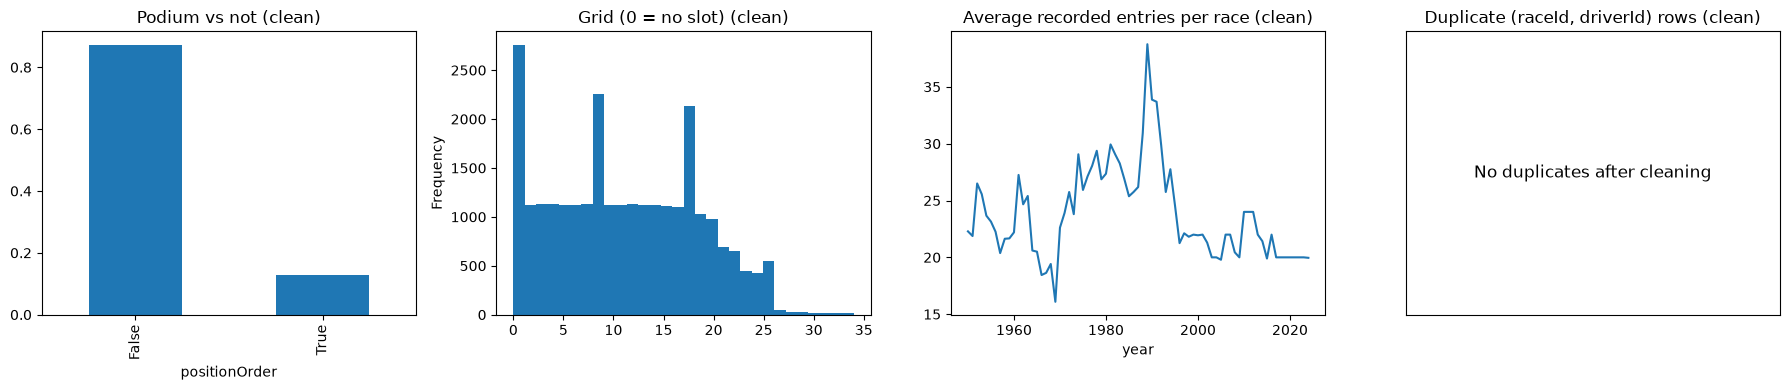

In [235]:
# 3) Target balance, grid==0, field size, and duplicate driver-race rows by season (AFTER cleaning)
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
res["positionOrder"] = pd.to_numeric(res["positionOrder"], errors="coerce")
res["grid"] = pd.to_numeric(res["grid"], errors="coerce")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
(res["positionOrder"] <= 3).value_counts(normalize=True).plot(
    kind="bar", ax=axes[0], title="Podium vs not (clean)")
res["grid"].plot(kind="hist", bins=30, ax=axes[1], title="Grid (0 = no slot) (clean)")
res.groupby(["year", "raceId"]).size().groupby("year").mean().plot(
    ax=axes[2], title="Average recorded entries per race (clean)")

dup = res[res.duplicated(["raceId", "driverId"], keep=False)]
if dup.empty:
    axes[3].text(0.5, 0.5, "No duplicates after cleaning", ha="center", va="center", fontsize=12)
    axes[3].set_title("Duplicate (raceId, driverId) rows (clean)")
    axes[3].set_xticks([]); axes[3].set_yticks([])
else:
    dup.groupby("year").size().plot(kind="bar", ax=axes[3], title="Duplicate (raceId, driverId) rows (clean)")

plt.tight_layout(); plt.show()

# 4. Data Engineering Questions

## 4.1 Question 1:

**Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Distinguish qualifying position from grid (which can differ due to penalties).**


In [236]:
circuits_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [237]:
races_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   raceId     1125 non-null   int64         
 1   year       1125 non-null   int64         
 2   round      1125 non-null   int64         
 3   circuitId  1125 non-null   int64         
 4   name       1125 non-null   object        
 5   date       1125 non-null   datetime64[ns]
 6   url        1125 non-null   object        
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 61.7+ KB


In [238]:
# Select the columns needed for Question 1.
q1_results = results_clean[
    ["raceId", "driverId", "grid", "positionOrder"]
]
q1_races = races_clean[["raceId", "circuitId", "year"]]
q1_circuits = circuits_clean[["circuitId", "name"]]

# Add the circuit ID and year to each driver–race record.
q1 = q1_results.merge(q1_races, on="raceId", how="left")

# Add the circuit name.
q1 = q1.merge(q1_circuits, on="circuitId", how="left")
q1 = q1.rename(columns={"name": "circuit_name"})

q1.head()

,raceId,driverId,grid,positionOrder,circuitId,year,circuit_name
0,18,1,1,1,1,2008,Albert Park Grand Prix Circuit
1,18,2,5,2,1,2008,Albert Park Grand Prix Circuit
2,18,3,7,3,1,2008,Albert Park Grand Prix Circuit
3,18,4,11,4,1,2008,Albert Park Grand Prix Circuit
4,18,5,3,5,1,2008,Albert Park Grand Prix Circuit


In [239]:
assert not q1.duplicated(["raceId", "driverId"]).any()

In [240]:
front_row = q1[q1["grid"].isin([1, 2])].copy()

In [241]:
front_row["podium"] = front_row["positionOrder"] <= 3

In [242]:
front_row["period"] = "Before 2014"

front_row.loc[
    front_row["year"] >= 2014, "period"
] = "2014 onward"

### Question 1 calculation: at least one front-row driver on the podium

A race is successful when **either driver, or both drivers**, from grid positions 1 and 2 reach positions 1–3 in positionOrder. This follows the TA clarification: one race counts +1 if at least one front-row driver podiums, even if both do. The rate is **successful races / eligible races × 100**, calculated separately before 2014 and from 2014 onward. Circuit rankings use the percentage, with successful and eligible counts shown alongside it. Ties share a rank; a 100% rate based on few races is not proof of a reliably superior circuit.

Require exactly two front-row driver records covering both grid slots 1 and 2. This checks coverage of the full front row; it does not require two podiums. Races without that comparable front-row coverage are excluded and the counts are displayed below. Results are computed from accumulated cleaned tables. Grid is used because qualifying rank can differ after penalties; qualifying position is not substituted for the actual recorded grid. Historical best-entry attribution remains a limitation for combined multi-entry results.


In [243]:
# One row per race: success means AT LEAST ONE front-row driver podiums.
race_summary = (
    front_row.groupby(["raceId", "circuitId", "circuit_name", "period"])
    .agg(front_row_drivers=("driverId", "size"),
         front_row_slots=("grid", "nunique"),
         podium_drivers=("podium", "sum"))
    .reset_index()
)
# Require records for both numbered slots, 1 and 2, for a comparable full front row.
# This is a coverage requirement, not a requirement that both drivers podium.
race_summary = race_summary.loc[
    race_summary["front_row_drivers"].eq(2) & race_summary["front_row_slots"].eq(2)
].copy()
race_summary["any_front_row_podium"] = race_summary["podium_drivers"].ge(1)
assert race_summary["podium_drivers"].between(0, 2).all()


In [244]:
q1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   raceId         26668 non-null  int64 
 1   driverId       26668 non-null  int64 
 2   grid           26668 non-null  int64 
 3   positionOrder  26668 non-null  int64 
 4   circuitId      26668 non-null  int64 
 5   year           26668 non-null  int64 
 6   circuit_name   26668 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.4+ MB


In [245]:
q1["raceId"].nunique()

1125

In [246]:
q1

,raceId,driverId,grid,positionOrder,circuitId,year,circuit_name
0,18,1,1,1,1,2008,Albert Park Grand Prix Circuit
1,18,2,5,2,1,2008,Albert Park Grand Prix Circuit
2,18,3,7,3,1,2008,Albert Park Grand Prix Circuit
3,18,4,11,4,1,2008,Albert Park Grand Prix Circuit
4,18,5,3,5,1,2008,Albert Park Grand Prix Circuit
...,...,...,...,...,...,...,...
26663,1144,825,14,16,24,2024,Yas Marina Circuit
26664,1144,859,12,17,24,2024,Yas Marina Circuit
26665,1144,822,9,18,24,2024,Yas Marina Circuit
26666,1144,861,20,19,24,2024,Yas Marina Circuit


In [247]:
circuit_counts = (
    race_summary.groupby(["circuitId", "circuit_name", "period"])
    .agg(successful_races=("any_front_row_podium", "sum"),
         eligible_races=("raceId", "size"))
    .reset_index()
)
circuit_counts["conversion_rate_pct"] = 100 * circuit_counts["successful_races"] / circuit_counts["eligible_races"]
circuit_counts["rank"] = circuit_counts.groupby("period")["conversion_rate_pct"].rank(ascending=False, method="min")
circuit_counts = circuit_counts.sort_values(
    ["period", "conversion_rate_pct", "eligible_races"], ascending=[True, False, False])
assert circuit_counts["conversion_rate_pct"].between(0, 100).all()
assert circuit_counts["eligible_races"].sum() == len(race_summary)
display(circuit_counts.round(2))
for period, group in circuit_counts.groupby("period", sort=False):
    leaders = group.loc[group["rank"].eq(1)]
    print(period + ": highest observed race-level conversion rate")
    display(leaders[["circuit_name", "successful_races", "eligible_races", "conversion_rate_pct"]].round(2))
print("Small race counts can produce 100% rates; compare the denominators before interpreting ranks.")


,circuitId,circuit_name,period,successful_races,eligible_races,conversion_rate_pct,rank
22,13,Circuit de Spa-Francorchamps,2014 onward,11,11,100.0,1.0
40,24,Yas Marina Circuit,2014 onward,11,11,100.0,1.0
10,6,Circuit de Monaco,2014 onward,10,10,100.0,1.0
89,69,Circuit of the Americas,2014 onward,10,10,100.0,1.0
12,7,Circuit Gilles Villeneuve,2014 onward,9,9,100.0,1.0
...,...,...,...,...,...,...,...
72,52,Circuit Mont-Tremblant,Before 2014,1,2,50.0,62.0
79,59,Circuito da Boavista,Before 2014,1,2,50.0,62.0
69,49,Montjuïc,Before 2014,1,4,25.0,67.0
77,57,Zeltweg,Before 2014,0,1,0.0,68.0


2014 onward: highest observed race-level conversion rate


,circuit_name,successful_races,eligible_races,conversion_rate_pct
22,Circuit de Spa-Francorchamps,11,11,100.0
40,Yas Marina Circuit,11,11,100.0
10,Circuit de Monaco,10,10,100.0
89,Circuit of the Americas,10,10,100.0
12,Circuit Gilles Villeneuve,9,9,100.0
38,Suzuka Circuit,9,9,100.0
49,Autódromo Hermanos Rodríguez,9,9,100.0
93,Sochi Autodrom,8,8,100.0
29,Shanghai International Circuit,7,7,100.0
17,Hockenheimring,4,4,100.0


Before 2014: highest observed race-level conversion rate


,circuit_name,successful_races,eligible_races,conversion_rate_pct
14,Circuit de Nevers Magny-Cours,18,18,100.0
3,Sepang International Circuit,15,15,100.0
44,Autódromo do Estoril,13,13,100.0
5,Bahrain International Circuit,9,9,100.0
63,Long Beach,8,8,100.0
9,Istanbul Park,7,7,100.0
43,Circuito de Jerez,7,7,100.0
61,Dijon-Prenois,6,6,100.0
28,Fuji Speedway,4,4,100.0
78,Aintree,4,4,100.0


Small race counts can produce 100% rates; compare the denominators before interpreting ranks.


In [248]:
circuit_counts.eligible_races.sum()

np.int64(1103)

In [249]:
print("All races:", q1["raceId"].nunique())

print(
    "Races with at least one front-row record:",
    front_row["raceId"].nunique()
)

print(
    "Races with both front-row records:",
    race_summary["raceId"].nunique()
)

All races: 1125
Races with at least one front-row record: 1124
Races with both front-row records: 1103


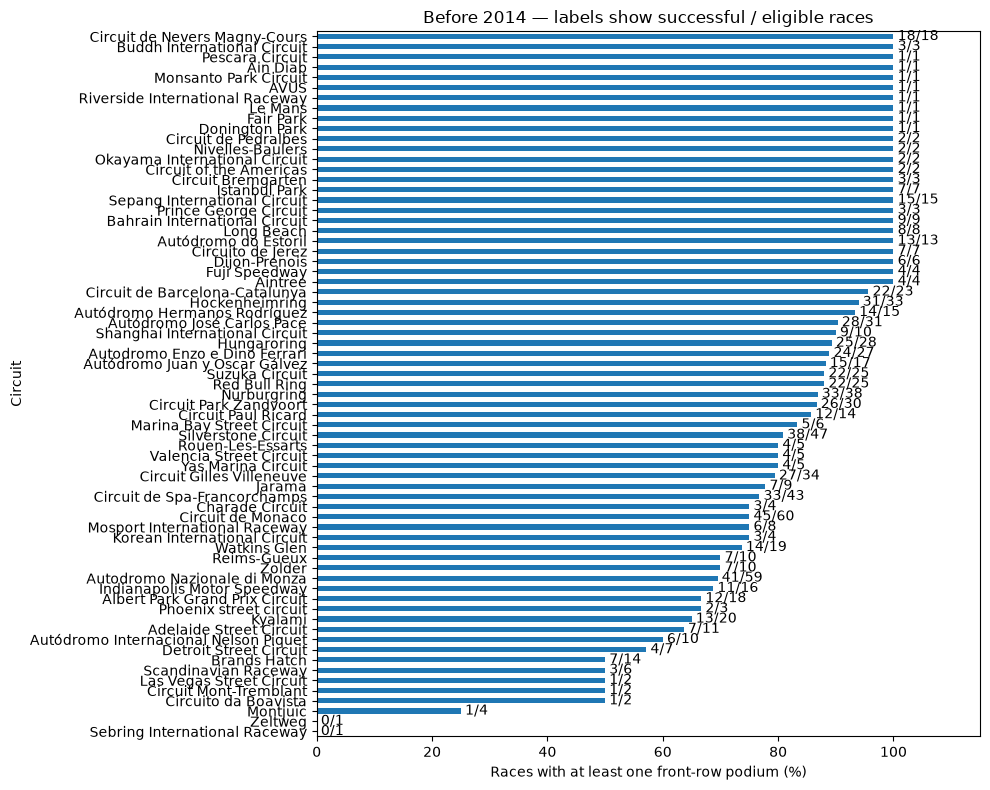

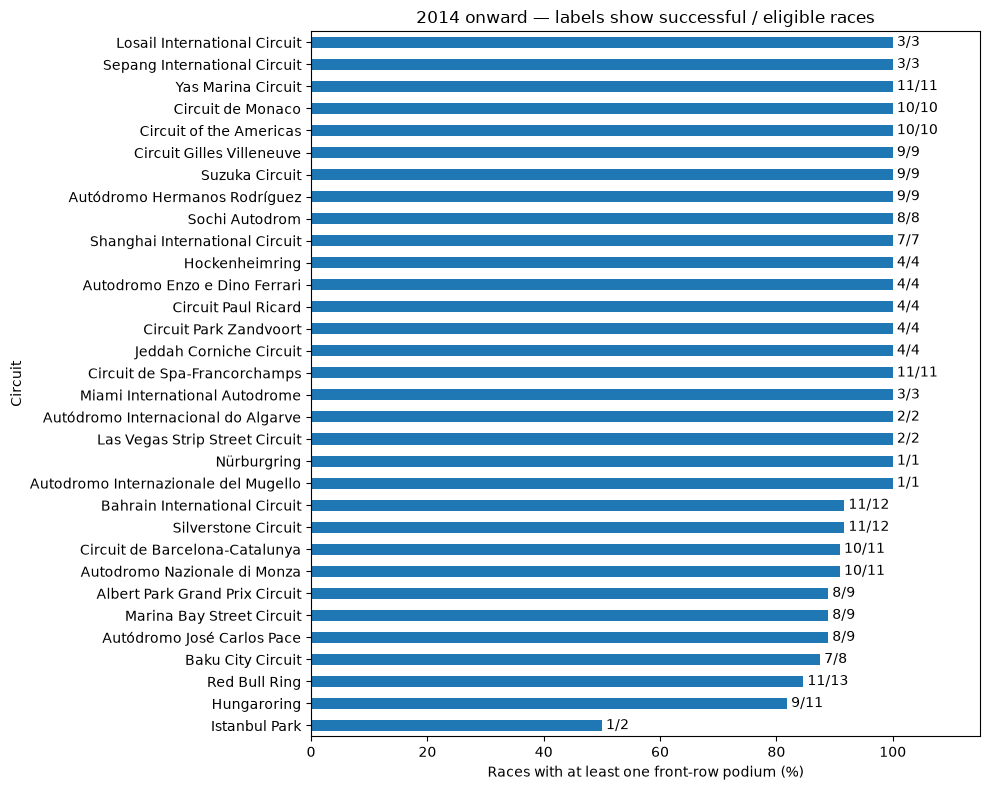

In [250]:
for period in ["Before 2014", "2014 onward"]:
    counts = circuit_counts.loc[circuit_counts["period"].eq(period)].sort_values("conversion_rate_pct")
    ax = counts.plot.barh(x="circuit_name", y="conversion_rate_pct", figsize=(10, 8), legend=False)
    labels = [f"{success}/{total}" for success, total in zip(counts["successful_races"], counts["eligible_races"])]
    ax.bar_label(ax.containers[0], labels=labels, padding=3)
    ax.set_xlabel("Races with at least one front-row podium (%)")
    ax.set_ylabel("Circuit")
    ax.set_title(period + " — labels show successful / eligible races")
    ax.set_xlim(0, 115)
    plt.tight_layout()
    plt.show()


In [251]:
# Answer Question 1 using the same computed ranking shown above.
from IPython.display import Markdown
for period in ["Before 2014", "2014 onward"]:
    period_table = circuit_counts.loc[circuit_counts["period"].eq(period)]
    leaders = period_table.loc[period_table["rank"].eq(1)].sort_values(
        ["eligible_races", "circuit_name"], ascending=[False, True])
    examples = leaders.head(5)
    names = "; ".join(f"{r.circuit_name} ({int(r.successful_races)}/{int(r.eligible_races)})"
                      for r in examples.itertuples())
    remaining = len(leaders) - len(examples)
    display(Markdown(f"**{period}:** {len(leaders)} circuits tie for the highest observed "
                     f"rate of **{leaders['conversion_rate_pct'].iloc[0]:.1f}%**. Examples with the "
                     f"largest race counts are {names}" +
                     (f"; and {remaining} more tied circuits appear in the full table above." if remaining else ".") +
                     " The counts show how much evidence supports each 100% rate."))
shared_circuits = circuit_counts.pivot_table(index="circuitId", columns="period", values="rank").dropna()
changed_ranks = int(shared_circuits["Before 2014"].ne(shared_circuits["2014 onward"]).sum())
display(Markdown(f"**Did the ranking change?** Among {len(shared_circuits)} circuits represented in both "
                 f"periods, {changed_ranks} have a different within-period rank. The full rates and sample "
                 "sizes are shown above. This analysis uses the *starting grid* (slots 1 and 2), which may "
                 "differ from qualifying order after penalties. A race succeeds when **at least one** of "
                 "those two drivers finishes on the podium."))


**Before 2014:** 25 circuits tie for the highest observed rate of **100.0%**. Examples with the largest race counts are Circuit de Nevers Magny-Cours (18/18); Sepang International Circuit (15/15); Autódromo do Estoril (13/13); Bahrain International Circuit (9/9); Long Beach (8/8); and 20 more tied circuits appear in the full table above. The counts show how much evidence supports each 100% rate.

**2014 onward:** 21 circuits tie for the highest observed rate of **100.0%**. Examples with the largest race counts are Circuit de Spa-Francorchamps (11/11); Yas Marina Circuit (11/11); Circuit de Monaco (10/10); Circuit of the Americas (10/10); Autódromo Hermanos Rodríguez (9/9); and 16 more tied circuits appear in the full table above. The counts show how much evidence supports each 100% rate.

**Did the ranking change?** Among 24 circuits represented in both periods, 21 have a different within-period rank. The full rates and sample sizes are shown above. This analysis uses the *starting grid* (slots 1 and 2), which may differ from qualifying order after penalties. A race succeeds when **at least one** of those two drivers finishes on the podium.

## 4.2 Question 2:


**Do drivers podium more often when racing at a circuit in their home country thanelsewhere, after controlling for starting position (i.e., comparing drivers whostarted from similar grid positions, so the effect isn’t just because home drivershappen to qualify better)?**


### Question 2 — Home country and podiums, controlling for grid

**Question:** Do drivers finish on the podium more often in their home country than elsewhere, when comparing similar starting positions?

Example: if home drivers usually start first and away drivers usually start tenth, a higher home podium rate could simply reflect better starting positions. We therefore compare **home and away records at the same grid position**, then combine those comparisons using the same weights for both groups.

One record is one driver in one Grand Prix. `grid` is the actual starting-grid position, not the qualifying position. `positionOrder` is the final ordering; values 1–3 identify podium places. `nationality` identifies the driver's represented country, and `circuits.country` identifies where the circuit is located. Home means these countries match; it does not mean the driver's residence or the race's title.


In [252]:
# Step 1: join the four tables.
q2 = results_clean[["raceId", "driverId", "grid", "positionOrder", "laps", "positionText"]].copy()
q2 = q2.merge(races_clean[["raceId", "circuitId", "year"]], on="raceId", how="left", validate="many_to_one")
q2 = q2.merge(circuits_clean[["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
q2 = q2.merge(drivers_clean[["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
q2 = q2.rename(columns={"country": "circuit_country", "nationality": "driver_nationality"})
assert not q2.duplicated(["raceId", "driverId"]).any()


#### Define home without guessing from missing mappings

Nationality words and country names differ: `British` maps to `UK`, for example. Dual nationalities match either listed country. Every observed nationality is mapped explicitly; an unknown label triggers a check instead of silently becoming away. A mapped country with no circuit in this dataset has only away records. Historical `East German` and `Rhodesian` labels retain their historical countries.

This uses the country and nationality labels standardized earlier in the notebook, including USA/United States and Argentine/Argentinian.


In [253]:
# Step 2: map nationality to country, then label home and away.
nat_to_countries = {
    "American": {"United States"},
    "American-Italian": {"United States", "Italy"},
    "Argentine": {"Argentina"},
    "Argentine-Italian": {"Argentina", "Italy"},
    "Australian": {"Australia"},
    "Austrian": {"Austria"},
    "Belgian": {"Belgium"},
    "Brazilian": {"Brazil"},
    "British": {"UK"},
    "Canadian": {"Canada"},
    "Chinese": {"China"},
    "Dutch": {"Netherlands"},
    "French": {"France"},
    "German": {"Germany"},
    "Hungarian": {"Hungary"},
    "Indian": {"India"},
    "Italian": {"Italy"},
    "Japanese": {"Japan"},
    "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"},
    "Monegasque": {"Monaco"},
    "Portuguese": {"Portugal"},
    "Russian": {"Russia"},
    "South African": {"South Africa"},
    "Spanish": {"Spain"},
    "Swedish": {"Sweden"},
    "Swiss": {"Switzerland"},
    "Finnish": {"Finland"},
    "Polish": {"Poland"},
    "Colombian": {"Colombia"},
    "Irish": {"Ireland"},
    "Danish": {"Denmark"},
    "Czech": {"Czech Republic"},
    "Venezuelan": {"Venezuela"},
    "New Zealander": {"New Zealand"},
    "Chilean": {"Chile"},
    "Liechtensteiner": {"Liechtenstein"},
    "Rhodesian": {"Rhodesia"},
    "Uruguayan": {"Uruguay"},
    "Thai": {"Thailand"},
    "East German": {"East Germany"},
    "Indonesian": {"Indonesia"},
}

assert q2[["driver_nationality", "circuit_country"]].notna().all().all()
unknown = set(q2["driver_nationality"]) - set(nat_to_countries)
assert not unknown, f"Add mappings for: {unknown}"
q2["home_countries"] = q2["driver_nationality"].map(nat_to_countries)
q2["is_home"] = [country in homes for country, homes in zip(q2["circuit_country"], q2["home_countries"])]
q2["podium"] = q2["positionOrder"].between(1, 3)


#### Select starters under the agreed dataset rule, then comparable grid positions

Question 2 and Question 3 use the same operational participation rule: include a driver–race record when completed laps are positive OR the same raceId/driverId has a cleaned lap-time or pit-stop record. Exclude records without any of those activity indicators. These are dataset-supported/inferred starters; the rule does not independently establish every actual first-lap start. No external non-start exceptions are used.

Question 2 then requires a positive recorded grid because it compares home and away at the same numbered starting position. Grid 0 does not mean non-start: a driver can pass the participation rule and still be excluded only from this grid-controlled comparison. The same full-year scope, nationality mapping and common grid weights are retained.


In [254]:
# Step 3: one shared participation screen for Questions 2 and 3.
def screen_race_activity(frame):
    screened = frame.copy()
    original_count = len(screened)
    assert not screened.duplicated(["raceId", "driverId"]).any()
    for table, flag in [(lap_times_clean, "has_lap_record"), (pit_stops_clean, "has_pit_record")]:
        pairs = table[["raceId", "driverId"]].drop_duplicates().assign(**{flag: True})
        screened = screened.merge(pairs, on=["raceId", "driverId"], how="left", validate="one_to_one")
        screened[flag] = screened[flag].eq(True)
    screened["has_completed_laps"] = screened["laps"].gt(0)
    screened["has_recorded_activity"] = screened[["has_completed_laps", "has_lap_record", "has_pit_record"]].any(axis=1)
    assert len(screened) == original_count
    return screened

q2_screened = screen_race_activity(q2)
q2_eligible = q2_screened["has_recorded_activity"] & q2_screened["grid"].gt(0)
q2_population_audit = pd.Series({
    "Driver-race records before screen": len(q2_screened),
    "Excluded: no recorded race activity": int((~q2_screened["has_recorded_activity"]).sum()),
    "Activity present, excluded only for non-positive/missing grid": int((q2_screened["has_recorded_activity"] & ~q2_screened["grid"].gt(0)).sum()),
    "Included in grid-controlled comparison": int(q2_eligible.sum())
}, name="Records")
display(q2_population_audit.to_frame())
q2 = q2_screened.loc[q2_eligible].copy()
assert q2["has_recorded_activity"].all() and q2["grid"].gt(0).all()
assert q2["positionOrder"].notna().all()
assert not q2.duplicated(["raceId", "driverId"]).any()


,Records
Driver-race records before screen,26668
Excluded: no recorded race activity,2527
"Activity present, excluded only for non-positive/missing grid",72
Included in grid-controlled comparison,24069


In [255]:
# Step 4: show the raw rates, then compare the same exact grid positions.
overall = q2.groupby("is_home")["podium"].agg(records="size", podiums="sum", rate="mean")
overall.index = overall.index.map({False: "Away", True: "Home"})
overall["podium_rate_pct"] = 100 * overall["rate"]
display(overall[["records", "podiums", "podium_rate_pct"]].round(2))

by_grid = q2.groupby(["grid", "is_home"])["podium"].agg(records="size", podiums="sum", rate="mean")
rate_by_grid = by_grid["rate"].unstack("is_home").rename(columns={False: "Away", True: "Home"})
counts_by_grid = by_grid["records"].unstack("is_home").rename(columns={False: "Away", True: "Home"})

# Compare only grid positions with BOTH home and away observations.
shared_rates = rate_by_grid.dropna(subset=["Away", "Home"])
shared_counts = counts_by_grid.loc[shared_rates.index]
assert not shared_rates.empty
print("Records outside shared grid positions:", len(q2) - int(shared_counts.sum().sum()))
display((100 * shared_rates).round(2))
display(shared_counts.astype(int))


,records,podiums,podium_rate_pct
is_home,,,
Away,21845,3129,14.32
Home,2224,266,11.96


Records outside shared grid positions: 13


is_home,Away,Home
grid,,
1,65.81,58.89
2,57.37,54.12
3,47.27,54.12
4,35.23,32.14
5,25.30,32.05
6,19.68,13.33
7,13.11,16.85
8,10.61,6.90
9,8.54,9.71


is_home,Away,Home
grid,,
1,1015,90
2,1011,85
3,1009,85
4,1019,84
5,1012,78
6,1001,90
7,1007,89
8,999,87
9,984,103


#### Combine the comparisons fairly

We give home and away the **same distribution of grid positions**. Each grid position's weight is its share of the combined records at the shared positions.

For example, if the combined records are 60% grid 1 and 40% grid 2, both the home rate and away rate are calculated as `0.6 × grid-1 rate + 0.4 × grid-2 rate`. This prevents one group receiving an advantage simply because more of its records start near the front.

This is a descriptive adjustment for grid position. Driver ability, constructor strength and season are not controlled, so any difference is an association rather than proof that racing at home causes more podiums. Small home counts at some grid positions should also be considered.


In [256]:
# Step 5: use the same grid weights for home and away.
grid_counts = shared_counts.sum(axis=1)
weights = grid_counts / grid_counts.sum()
adjusted_pct = 100 * shared_rates.mul(weights, axis=0).sum()
assert np.isclose(weights.sum(), 1)
display(adjusted_pct.rename("Grid-adjusted podium rate (%)").round(2))

difference = adjusted_pct["Home"] - adjusted_pct["Away"]
print(f"After adjusting for grid: Home = {adjusted_pct['Home']:.2f}%, Away = {adjusted_pct['Away']:.2f}%.")
print(f"Home minus away = {difference:.2f} percentage points.")
if difference > 0:
    print("Home records have a higher podium rate after this grid adjustment.")
else:
    print("Home records do not have a higher podium rate after this grid adjustment.")
print("This comparison does not establish a causal home advantage.")


is_home
Away    14.14
Home    13.84
Name: Grid-adjusted podium rate (%), dtype: float64

After adjusting for grid: Home = 13.84%, Away = 14.14%.
Home minus away = -0.30 percentage points.
Home records do not have a higher podium rate after this grid adjustment.
This comparison does not establish a causal home advantage.


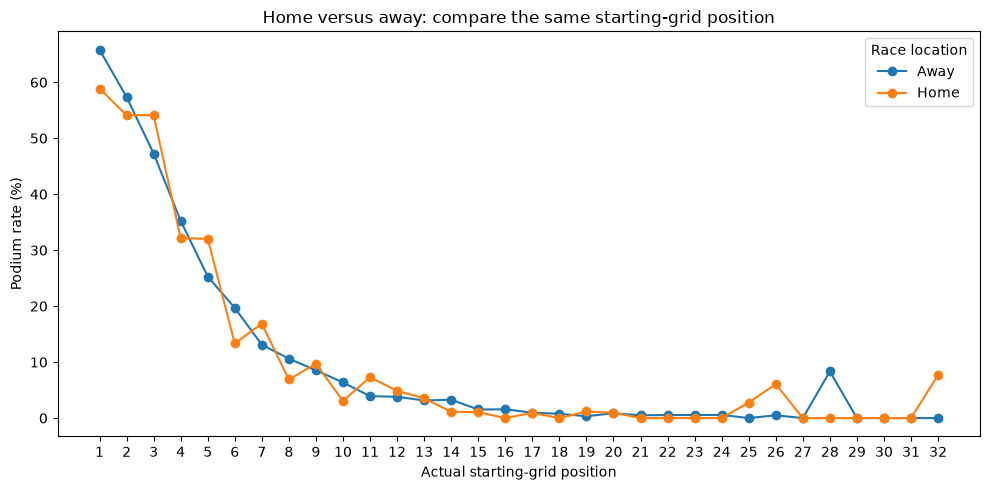

In [257]:
# Step 6: plot podium rates for the same grid positions.
import matplotlib.pyplot as plt
ax = (100 * shared_rates).plot(marker="o", figsize=(10, 5))
ax.set_xlabel("Actual starting-grid position")
ax.set_ylabel("Podium rate (%)")
ax.set_title("Home versus away: compare the same starting-grid position")
ax.set_xticks(shared_rates.index)
ax.legend(title="Race location")
plt.tight_layout()
plt.show()


#### Answer

The preceding calculated tables and generated text report the updated unadjusted and grid-adjusted rates under the shared participation rule. A positive home-minus-away difference means a higher home podium rate after giving both groups the same grid distribution; a negative difference means a lower home rate.

The comparison includes only dataset-supported starters with positive grid positions, and the adjusted comparison uses positions observed in both home and away groups. This describes an association, not a causal home advantage or a significance test. Read the per-grid counts alongside the rates.


In [258]:
# Answer Question 2 from the shared-grid calculation above.
from IPython.display import Markdown
q2_direction = "higher" if difference > 0 else ("lower" if difference < 0 else "equal")
display(Markdown(
    f"**Answer:** After giving home and away drivers the same distribution of starting-grid positions, "
    f"the home podium rate is **{adjusted_pct['Home']:.2f}%** and the away rate is "
    f"**{adjusted_pct['Away']:.2f}%**. The home rate is **{abs(difference):.2f} percentage points "
    f"{q2_direction}** under this comparison. This covers the {int(shared_counts.sum().sum())} "
    "driver–race records at grid positions represented in both groups, after the shared "
    "recorded-activity screen. It describes an association after matching the grid distribution; "
    "it does not prove a home-country effect or control for driver/team ability."))


**Answer:** After giving home and away drivers the same distribution of starting-grid positions, the home podium rate is **13.84%** and the away rate is **14.14%**. The home rate is **0.30 percentage points lower** under this comparison. This covers the 24056 driver–race records at grid positions represented in both groups, after the shared recorded-activity screen. It describes an association after matching the grid distribution; it does not prove a home-country effect or control for driver/team ability.

## 4.3 Question 3:


**Which constructors have the highest mechanical-retirement rate in 2014–2021 vs.2022–2024?**


### Question 3 — Mechanical-retirement rates

**Question:** Which constructors have the highest mechanical-retirement rate in 2014–2021 and 2022–2024?

**Analysis population:** drivers with recorded race activity. Include a driver–race row if `results_clean.laps > 0`, or if the same `(raceId, driverId)` exists in `lap_times_clean` or `pit_stops_clean`. These are alternative inclusion conditions: any one is sufficient. Grid and outcome codes do not determine eligibility.

**Rate = mechanical-labelled retirements among included drivers / drivers with recorded race activity × 100.** Two included drivers from a constructor contribute two records. This is a restricted-population estimate, not a verified rate among all actual starters: genuine first-lap retirements with no recorded activity may be excluded, potentially biasing comparisons.

The mechanical labels include `Retired` and `Damage` by project assumption. No external incident overrides are used. All source tables remain unchanged.


In [259]:
# Step 1: join the four tables.
q3 = results_clean[["raceId", "driverId", "constructorId", "statusId", "laps", "positionText"]].copy()
q3 = q3.merge(races_clean[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
q3 = q3.merge(constructors_clean[["constructorId", "name"]], on="constructorId", how="left", validate="many_to_one")
q3 = q3.merge(status_clean[["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
q3 = q3.rename(columns={"name": "constructor_name"})

# Step 2: keep the requested years and label the two periods.
q3 = q3[q3["year"].between(2014, 2024)].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
assert not q3.duplicated(["raceId", "driverId"]).any()
assert q3[["year", "constructor_name", "status", "laps", "positionText"]].notna().all().all()
print("Races in each period:")
print(q3.groupby("period")["raceId"].nunique())


Races in each period:
period
2014-2021    160
2022-2024     68
Name: raceId, dtype: int64


#### Select drivers with recorded race activity

1. Include if completed laps are positive.
2. Otherwise include if a matching race lap-time or pit-stop record exists.
3. Otherwise exclude from this analysis, whatever the grid or outcome code.

`grid = 0` does not exclude a participant. A positive grid slot does not establish participation. `W`, `R`, `D`, `E`, `N` and `F` do not override activity evidence. Excluded rows mean **no recorded activity in these tables**, not proven non-starts.

Matching uses both `raceId` and `driverId`. Related-table keys are deduplicated before merging so multiple laps/stops cannot multiply the result rows. Zero-lap records with related activity are displayed as contradictions for review, without changing source values. No external non-start list is used.


In [260]:
# Step 3: include only records supported by race activity in our cleaned tables.
q3 = screen_race_activity(q3)
display(q3.groupby("period")["has_recorded_activity"].agg(total_records="size", included_records="sum"))
print("Excluded: no recorded activity:", (~q3["has_recorded_activity"]).sum())
display(q3.loc[~q3["has_recorded_activity"], ["raceId", "driverId", "constructor_name", "laps", "positionText", "status"]])
print("Zero completed laps but related race activity (review contradictions):")
display(q3.loc[~q3["has_completed_laps"] & q3["has_recorded_activity"],
               ["raceId", "driverId", "laps", "positionText", "status", "has_lap_record", "has_pit_record"]])
q3_participants = q3.loc[q3["has_recorded_activity"]].copy()
assert q3_participants["has_recorded_activity"].all()
assert not q3_participants.duplicated(["raceId", "driverId"]).any()
print("Drivers with recorded race activity:", len(q3_participants))

# Shared years + positive grid must identify the same participants in Q2 and Q3.
q3_positive_grid = q3_participants[["raceId", "driverId"]].merge(
    results_clean[["raceId", "driverId", "grid"]], on=["raceId", "driverId"], validate="one_to_one")
expected_q2_pairs = set(map(tuple, q3_positive_grid.loc[q3_positive_grid["grid"].gt(0), ["raceId", "driverId"]].to_numpy()))
actual_q2_pairs = set(map(tuple, q2.loc[q2["year"].between(2014, 2024), ["raceId", "driverId"]].to_numpy()))
assert actual_q2_pairs == expected_q2_pairs, "Q2/Q3 participation filters disagree"


,total_records,included_records
period,,
2014-2021,3267,3163
2022-2024,1359,1324


Excluded: no recorded activity: 139


,raceId,driverId,constructor_name,laps,positionText,status
19,900,13,Williams,0,R,Collision
20,900,155,Caterham,0,R,Collision
43,901,815,Force India,0,W,Withdrew
130,905,815,Force India,0,R,Collision
131,905,813,Lotus F1,0,W,Withdrew
...,...,...,...,...,...,...
4563,1141,848,Williams,0,W,Withdrew
4564,1141,840,Aston Martin,0,W,Withdrew
4604,1143,861,Williams,0,R,Collision
4605,1143,839,Alpine F1 Team,0,R,Collision


Zero completed laps but related race activity (review contradictions):


,raceId,driverId,laps,positionText,status,has_lap_record,has_pit_record


Drivers with recorded race activity: 4487


#### Classify mechanical labels within the selected population

Instructor guidance treats `Tyre`, `Puncture`, `Tyre puncture`, `Fire` and `Safety belt` as mechanical, except `Refuelling`. Our simplifying rule also includes wheel, wheel-nut, bodywork, seat, technical and vibration labels. `Retired` and `Damage` count as mechanical by explicit project assumption, although those labels do not establish a mechanical cause.

Accident, collision and other labels in the non-mechanical set do not enter the numerator. Finished and lap-deficit labels remain separate. Every observed label must be mapped; unexpected labels cause a failed check rather than silently becoming non-mechanical. There is no uncertain category and no externally sourced incident exception list.


In [261]:
# Step 4: classify every observed status explicitly.
mechanical_statuses = {
    "Engine", "Brakes", "Power Unit", "Gearbox", "Suspension", "Hydraulics",
    "Electrical", "Power loss", "Oil leak", "Overheating", "Water pressure",
    "Mechanical", "Turbo", "Exhaust", "Fuel pressure", "Battery", "ERS",
    "Electronics", "Water leak", "Radiator", "Transmission", "Oil pressure",
    "Steering", "Fuel leak", "Clutch", "Throttle", "Driveshaft", "Fuel system",
    "Drivetrain", "Brake duct", "Spark plugs", "Cooling system", "Water pump",
    "Fuel pump", "Differential", "Tyre", "Puncture", "Tyre puncture", "Fire", "Safety belt",
    "Wheel", "Wheel nut", "Undertray", "Seat", "Technical", "Vibrations",
    "Front wing", "Rear wing", "Retired", "Damage"
}
non_mechanical_statuses = {
    "Accident", "Collision", "Collision damage", "Spun off", "Disqualified",
    "Excluded", "Illness", "Out of fuel", "Withdrew", "Refuelling", "Debris"
}
finished = q3_participants["status"].eq("Finished") | q3_participants["status"].str.fullmatch(r"\+\d+ Laps?")
known_status = finished | q3_participants["status"].isin(mechanical_statuses | non_mechanical_statuses)
assert known_status.all(), "Unmapped statuses: " + str(q3_participants.loc[~known_status, "status"].unique())
assert mechanical_statuses.isdisjoint(non_mechanical_statuses)
q3_participants["is_mechanical"] = q3_participants["status"].isin(mechanical_statuses)

display(q3_participants.groupby(["status", "is_mechanical"]).size().reset_index(name="records"))


,status,is_mechanical,records
0,+1 Lap,False,1178
1,+2 Laps,False,208
2,+3 Laps,False,24
3,+4 Laps,False,6
4,+5 Laps,False,1
...,...,...,...
60,Water pressure,True,7
61,Water pump,True,1
62,Wheel,True,11
63,Wheel nut,True,3


In [262]:
# Step 5: count recorded participants and mechanical-labelled retirements for every constructor.
rates = q3_participants.groupby(["period", "constructorId", "constructor_name"]).agg(
    recorded_participants=("driverId", "size"),
    mechanical_retirements=("is_mechanical", "sum")
).reset_index()

rates["mechanical_rate_pct"] = 100 * rates["mechanical_retirements"] / rates["recorded_participants"]
rates["main_rank"] = rates.groupby("period")["mechanical_rate_pct"].rank(ascending=False, method="min")

for period in ["2014-2021", "2022-2024"]:
    print("\n", period)
    display(rates[rates["period"] == period].sort_values("mechanical_rate_pct", ascending=False).round(2))

assert rates["recorded_participants"].sum() == len(q3_participants)
assert (rates["mechanical_retirements"] <= rates["recorded_participants"]).all()



 2014-2021


,period,constructorId,constructor_name,recorded_participants,mechanical_retirements,mechanical_rate_pct,main_rank
12,2014-2021,207,Caterham,32,10,31.25,1.0
13,2014-2021,208,Lotus F1,70,17,24.29,2.0
3,2014-2021,5,Toro Rosso,234,42,17.95,3.0
2,2014-2021,4,Renault,194,30,15.46,4.0
0,2014-2021,1,McLaren,310,47,15.16,5.0
7,2014-2021,15,Sauber,195,25,12.82,6.0
15,2014-2021,210,Haas F1 Team,234,29,12.39,7.0
5,2014-2021,9,Red Bull,310,37,11.94,8.0
17,2014-2021,213,AlphaTauri,75,8,10.67,9.0
11,2014-2021,206,Marussia,29,3,10.34,10.0



 2022-2024


,period,constructorId,constructor_name,recorded_participants,mechanical_retirements,mechanical_rate_pct,main_rank
24,2022-2024,51,Alfa Romeo,87,11,12.64,1.0
30,2022-2024,215,RB F1 Team,46,5,10.87,2.0
29,2022-2024,214,Alpine F1 Team,133,14,10.53,3.0
20,2022-2024,3,Williams,128,10,7.81,4.0
21,2022-2024,6,Ferrari,131,9,6.87,5.0
23,2022-2024,15,Sauber,48,3,6.25,6.0
25,2022-2024,117,Aston Martin,134,8,5.97,7.0
28,2022-2024,213,AlphaTauri,85,5,5.88,8.0
27,2022-2024,210,Haas F1 Team,131,7,5.34,9.0
26,2022-2024,131,Mercedes,133,6,4.51,10.0


#### Read the ranking and compare periods

`recorded_participants` counts included driver–race records; `mechanical_retirements` counts mechanical-labelled outcomes among them. Rank constructors by the percentage, not raw failure totals. All constructors are shown; small denominators can produce unstable rankings. Constructor IDs remain separate across rebrands. Compare IDs present in both periods using percentage-point changes.

This analysis uses Grand Prix results, not sprint results. No status/lap values are filled. The denominator excludes all rows without activity evidence, including possible first-lap starters. Therefore these are rates among drivers with recorded race activity, not guaranteed rates among all starters. Outcome fields are suitable for this retrospective question but not as same-race pre-race model inputs.


In [263]:
# Step 6: compare constructors that appear in both periods.
comparison = rates.pivot(index=["constructorId", "constructor_name"], columns="period", values="mechanical_rate_pct").dropna()
comparison["change_percentage_points"] = comparison["2022-2024"] - comparison["2014-2021"]
display(comparison.round(2))

# Generate the written answer directly from the calculated rates.
for period in ["2014-2021", "2022-2024"]:
    period_rates = rates[rates["period"] == period]
    leaders = period_rates[period_rates["mechanical_rate_pct"] == period_rates["mechanical_rate_pct"].max()]
    for _, team in leaders.iterrows():
        print(f"{period}: {team['constructor_name']} has the highest rate under the chosen classification: "
              f"{team['mechanical_retirements']} / {team['recorded_participants']} recorded_participants = "
              f"{team['mechanical_rate_pct']:.2f}%.")


,period,2014-2021,2022-2024,change_percentage_points
constructorId,constructor_name,,,
1,McLaren,15.16,3.73,-11.43
3,Williams,9.65,7.81,-1.83
6,Ferrari,6.17,6.87,0.70
9,Red Bull,11.94,4.48,-7.46
15,Sauber,12.82,6.25,-6.57
51,Alfa Romeo,4.17,12.64,8.48
117,Aston Martin,4.65,5.97,1.32
131,Mercedes,5.05,4.51,-0.54
210,Haas F1 Team,12.39,5.34,-7.05


2014-2021: Caterham has the highest rate under the chosen classification: 10 / 32 recorded_participants = 31.25%.
2022-2024: Alfa Romeo has the highest rate under the chosen classification: 11 / 87 recorded_participants = 12.64%.


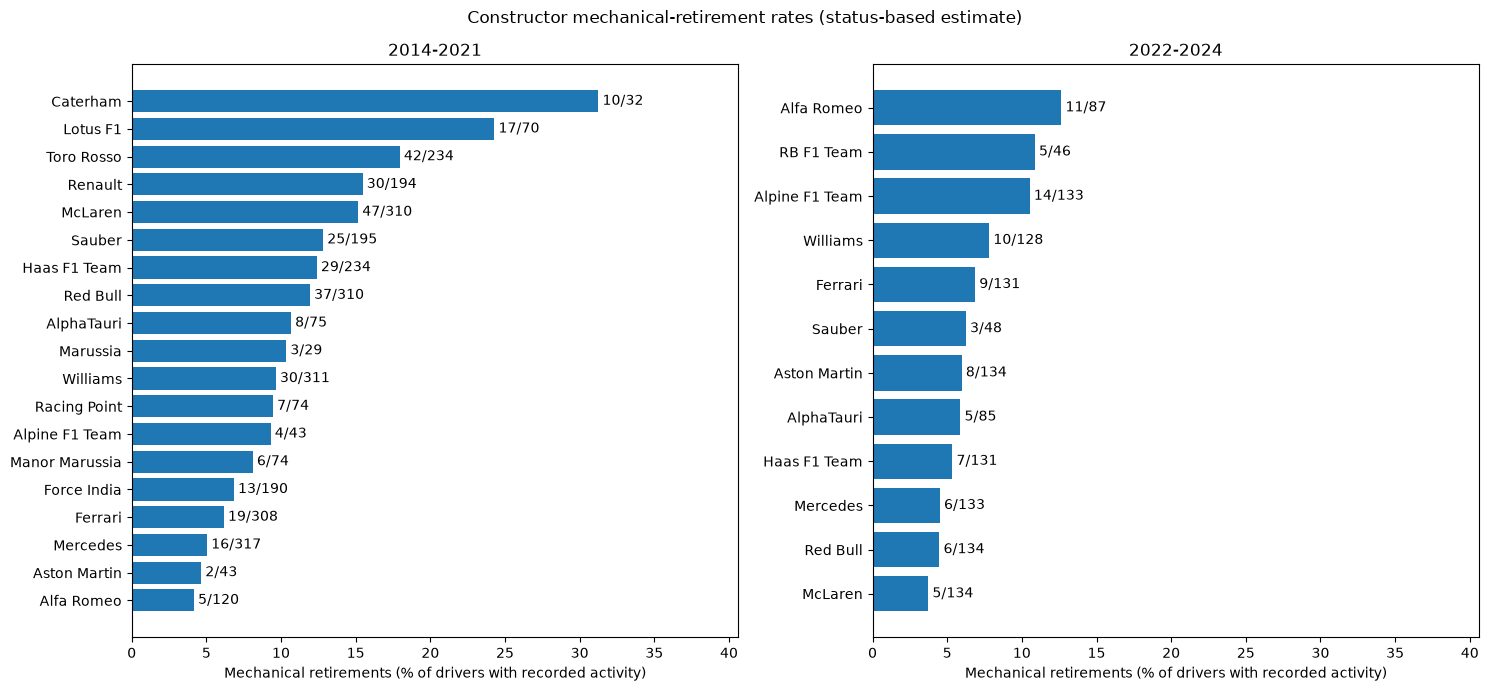

In [264]:
# Step 7: visualize the main rates; labels show failures / recorded_participants.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    data = rates[rates["period"] == period].sort_values("mechanical_rate_pct")
    bars = ax.barh(data["constructor_name"], data["mechanical_rate_pct"])
    labels = [f"{failures}/{recorded_participants}" for failures, recorded_participants in zip(data["mechanical_retirements"], data["recorded_participants"])]
    ax.bar_label(bars, labels=labels, padding=3)
    ax.set_title(period)
    ax.set_xlabel("Mechanical retirements (% of drivers with recorded activity)")
    ax.set_xlim(0, rates["mechanical_rate_pct"].max() * 1.3)
fig.suptitle("Constructor mechanical-retirement rates (status-based estimate)")
plt.tight_layout()
plt.show()


#### Answer and limits

The calculated tables, generated answer and chart above show the results under the recorded-activity rule. Read each mechanical-labelled count alongside its participant count. Rankings must be refreshed after running this section; earlier numbers from the previous population no longer apply.

Eligibility uses only the cleaned dataset: completed laps or a matching lap-time/pit-stop record. Excluded rows have no recorded activity; they are not claimed to be confirmed non-starters. Incomplete timing coverage and first-lap retirements can affect the denominator and rates. `Retired` and `Damage` are mechanical by project assumption, so the numerator is also a broad estimate. There are no external participation or incident overrides and no uncertainty scenario.


In [265]:
# Answer Question 3 from the calculated rates, retaining the stated population and status assumptions.
from IPython.display import Markdown
for period in ["2014-2021", "2022-2024"]:
    period_rates = rates.loc[rates["period"].eq(period)]
    leaders = period_rates.loc[period_rates["mechanical_rate_pct"].eq(period_rates["mechanical_rate_pct"].max())]
    leaders_text = "; ".join(f"{r.constructor_name}: {int(r.mechanical_retirements)}/"
                             f"{int(r.recorded_participants)} ({r.mechanical_rate_pct:.2f}%)"
                             for r in leaders.itertuples())
    display(Markdown(f"**{period} answer:** Highest observed mechanical-labelled retirement rate "
                     f"(ties included): {leaders_text}. Small participant counts can make rates unstable."))
display(Markdown("**How to read these rates:** The denominator is drivers with recorded race activity "
                 "(completed laps or matching lap/pit records), not all independently verified starters. "
                 "Some first-lap starters may be absent. `Retired` and `Damage` count as mechanical under "
                 "the team's documented assumption, although those labels do not prove a component failure. "
                 "The chart and full comparison above show all constructor rates."))


**2014-2021 answer:** Highest observed mechanical-labelled retirement rate (ties included): Caterham: 10/32 (31.25%). Small participant counts can make rates unstable.

**2022-2024 answer:** Highest observed mechanical-labelled retirement rate (ties included): Alfa Romeo: 11/87 (12.64%). Small participant counts can make rates unstable.

**How to read these rates:** The denominator is drivers with recorded race activity (completed laps or matching lap/pit records), not all independently verified starters. Some first-lap starters may be absent. `Retired` and `Damage` count as mechanical under the team's documented assumption, although those labels do not prove a component failure. The chart and full comparison above show all constructor rates.

# 5. Feature selection and engineering — exploration

This replaces the earlier demo. **No feature set, data split, general imputation method or model is finalized here. No-history form uses the explicit zero-with-history-count convention documented below.** We explore all recorded years, as requested. Candidate tables are separate from the cleaned source tables.

Lab 1 (page 12) motivates engineered features, outcome comparisons and correlation rankings. Lab 2 (page 6) motivates rejecting target leakage. MS1 Part 3 requires exploratory justification; Part 5 later tests feature groups by retraining. These documents motivate the workflow, not the predictive usefulness of any particular F1 feature.

Dataset-wide target plots are descriptive evidence, not held-out performance. When the modeling workflow is decided, data-driven selection must be checked within its training/validation procedure. No split column or year cutoff is assigned in this section.


## 5.1 Define the prediction and audit candidate columns

One row represents one recorded driver–race result, with `podium = 1` when `positionOrder` is 1–3. The provisional information cutoff is after qualifying and before the Grand Prix starts. Current-race position, points, laps and retirement status cannot be current-race predictors.

We retain every cleaned driver–race row, including historical Indianapolis entries and non-start records. This is an exploration population, not a claim that every row is an eligible future prediction. We show population diagnostics rather than quietly filtering on post-race flags such as `in_population`.

The inventory below classifies columns by availability and purpose before looking at target correlations. A numeric identifier is not an ordered measurement. All proposed identity features need categorical treatment later.


In [266]:
# Keep evidence that the exploration does not change any cleaned source table.
feature_source_checks = {
    name: (table.shape, tuple(table.columns), pd.util.hash_pandas_object(table, index=True).sum())
    for name, table in clean.items()
}
feature_pre_race_columns = {
    "results": {"grid", "number"},
    "qualifying": {"position", "q1", "q2", "q3"},
    "races": {"year", "round", "date"},
    "drivers": {"dob", "nationality"},
    "constructors": {"nationality"},
    "circuits": {"location", "country", "lat", "lng", "alt"}
}
feature_inventory_rows = []
for table_name, table in clean.items():
    for column in table.columns:
        if column.endswith("Id") or column in {"year"} and table_name == "seasons":
            role = "Join/identity field; do not interpret its numeric code as magnitude"
        elif column in feature_pre_race_columns.get(table_name, set()):
            role = "Candidate source; verify coverage and meaning before selection"
        elif table_name in {"driver_standings", "constructor_standings"}:
            role = "After-round standing; requires strictly earlier-round lookup"
        elif table_name in {"results", "constructor_results", "lap_times", "pit_stops", "status"}:
            role = "Current-race outcome/audit; exclude as direct pre-race input"
        elif table_name == "sprint_results":
            role = "Conditional: earlier sprint only; modern-only coverage needs review"
        else:
            role = "Description/reference; no predictive use established"
        feature_inventory_rows.append({"Table": table_name, "Column": column,
            "Missing (%)": table[column].isna().mean() * 100, "Initial role": role})
feature_column_inventory = pd.DataFrame(feature_inventory_rows)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(feature_column_inventory.round(2))


,Table,Column,Missing (%),Initial role
0,circuits,circuitId,0.00,Join/identity field; do not interpret its numeric code as magnitude
1,circuits,circuitRef,0.00,Description/reference; no predictive use established
2,circuits,name,0.00,Description/reference; no predictive use established
3,circuits,location,0.00,Candidate source; verify coverage and meaning before selection
4,circuits,country,0.00,Candidate source; verify coverage and meaning before selection
5,circuits,lat,0.00,Candidate source; verify coverage and meaning before selection
6,circuits,lng,0.00,Candidate source; verify coverage and meaning before selection
7,circuits,alt,0.00,Candidate source; verify coverage and meaning before selection
8,circuits,url,0.00,Description/reference; no predictive use established
9,constructor_results,constructorResultsId,0.00,Join/identity field; do not interpret its numeric code as magnitude


## 5.2 Build a fresh candidate table

Left joins preserve all driver–race rows. Keys, date and final outcome stay available for checking, but are not automatically inputs.

At this stage, copy the recorded `results_clean.grid` values, including zeros. Section 5.9 then adjusts `feature_candidates.grid` for modeling and adds `no_grid_slot`; the recorded values in `results_clean` remain available for comparison. Grid zero is a special recorded code, not a numbered slot ahead of pole position and not sufficient proof of a race start/non-start. Qualifying position and starting grid remain separate.

**Historical modeling assumption — retained design choice:** `results_clean` supplies the grid from the best-finishing recorded entry for each multiple-entry driver–race group, using the policy explained in the results section. We retain this policy for the historical training data.

The duplicate-group inspection found 85 affected driver–race groups (about 0.35% of training records), all in 1950–1978 and none in validation or test. In 81 groups the entries have different grids; in 4 they have identical grids. Choosing the best finish does not always choose the best grid: among those 81 groups, it retains the smallest grid number in 25, the largest in 55, and an intermediate value in 1.

**Scope of the assumption:** the retained grid describes the selected entry. Because selection uses finishing order, this is an outcome-dependent historical input-selection convention, not a verified reconstruction of the driver's pre-race starting entry. The inspection did not measure its effect on model scores or demonstrate score inflation. The table below keeps affected groups visible. Constructor identity/history remain masked in the 16 groups involving different constructors.

The original grid values are checked against results_clean after joining. Raw CSVs and cleaned source tables are unchanged.


In [267]:
raw_driver_race_details = results.groupby(["raceId", "driverId"]).agg(
    original_entries=("resultId", "size"),
    constructor_choices=("constructorId", "nunique")
).reset_index()
feature_candidates = results_clean[["raceId", "driverId", "constructorId", "grid", "positionOrder", "points"]].copy()
feature_candidates = feature_candidates.merge(raw_driver_race_details, on=["raceId", "driverId"], validate="one_to_one")
feature_candidates = feature_candidates.merge(
    races_clean[["raceId", "year", "round", "date", "circuitId"]],
    on="raceId", how="left", validate="many_to_one")
feature_candidates = feature_candidates.merge(
    drivers_clean[["driverId", "dob", "nationality"]].rename(columns={"nationality": "driver_nationality"}),
    on="driverId", how="left", validate="many_to_one")
feature_candidates = feature_candidates.merge(
    circuits_clean[["circuitId", "country", "lat", "lng", "alt"]].rename(columns={
        "country": "circuit_country", "lat": "circuit_lat", "lng": "circuit_lng", "alt": "circuit_alt"}),
    on="circuitId", how="left", validate="many_to_one")
feature_candidates = feature_candidates.merge(
    qualifying_clean[["raceId", "driverId", "position", "q1", "q2", "q3"]].rename(columns={"position": "qualifying_position"}),
    on=["raceId", "driverId"], how="left", validate="one_to_one")
feature_candidates = feature_candidates.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
feature_candidates["circuit_identity"] = feature_candidates["circuitId"].astype("string")
feature_candidates["podium"] = feature_candidates["positionOrder"].between(1, 3).astype(int)
feature_candidates["constructor_identity"] = feature_candidates["constructorId"].astype("string").where(
    feature_candidates["constructor_choices"].eq(1))
assert len(feature_candidates) == len(results_clean)
assert not feature_candidates.duplicated(["raceId", "driverId"]).any()
assert feature_candidates[["date", "year", "dob", "circuit_country"]].notna().all().all()
print("Rows retained:", len(feature_candidates))
print("Multiple-entry driver-race groups:", feature_candidates["original_entries"].gt(1).sum())
print("Groups involving different constructors:", feature_candidates["constructor_choices"].gt(1).sum())
print("Records with grid zero:", feature_candidates["grid"].eq(0).sum())
with pd.option_context("display.max_rows", None):
    display(feature_candidates.loc[feature_candidates["original_entries"].gt(1),
        ["raceId", "driverId", "year", "original_entries", "constructor_choices", "grid", "constructor_identity"]])

assert feature_candidates["grid"].notna().all()
assert feature_candidates["grid"].equals(results_clean.set_index(["raceId", "driverId"])["grid"].reindex(pd.MultiIndex.from_frame(feature_candidates[["raceId", "driverId"]])).reset_index(drop=True))


Rows retained: 26668
Multiple-entry driver-race groups: 85
Groups involving different constructors: 16
Records with grid zero: 1635


,raceId,driverId,year,original_entries,constructor_choices,grid,constructor_identity
48,835,529,1950,2,2,9,<NA>
114,838,627,1950,2,1,15,154
130,839,579,1950,2,1,7,51
137,839,647,1950,2,1,6,6
227,828,579,1951,2,1,7,51
235,828,647,1951,2,1,6,6
246,828,786,1951,2,1,7,51
300,831,642,1951,2,1,7,51
340,817,642,1952,2,1,4,6
408,820,501,1952,2,1,12,105


## 5.3 Engineer interpretable candidates before measuring associations

Each calculation has a concrete meaning. This motivates trying it; it does not prove it improves prediction.

- **Age:** years between birth and race dates (continuous approximation).
- **Experience:** number of earlier recorded appearances, not a claim about confirmed race starts.
- **Driver form:** podium proportion in the previous 5 and previous 10 appearances. Both windows are explored; neither is declared best.
- **Constructor form:** podium proportion among its credited driver records in each earlier race, averaged over the previous 5/10 available races. This is a driver-credit rate, not a count of unique cars. Records involving ambiguous constructor identity do not enter this team summary.
- **Prior Grand Prix points:** sum of this driver's recorded GP points earlier in the same season. This excludes sprint points and is not an official championship standing. Scoring systems vary by era, so this candidate needs an era check.
- **Home indicator:** mapped driver nationality matches circuit country. Unknown mappings remain unknown; they are not assumed away.
- **Relative qualifying time:** driver time divided by the fastest recorded time in the same race and stage, minus one. For example, 82/80 - 1 = 2.5% slower. This controls the basic circuit-time scale, but does not make historical formats or weather identical. Modern Q2/Q3 candidates are undefined before 2006; early-2005 second-session times are not treated as knockout Q2.

Both windows use **up to** 5/10 earlier appearances or usable team races (`min_periods=1`); a complete window is not required. When there is no recorded history, form is explicitly encoded as **0**, together with the existing driver/team history count of **0**. This is a practical baseline convention, not an observed rate of zero out of zero. An experienced driver with no previous podiums also has form 0, but has a positive history count, so these cases remain distinguishable. No extra flag column is needed.

Only confirmed no-history rows receive this zero. Ambiguous cross-constructor records remain unknown; they are not assumed to be new teams. This convention is transparent and can be compared with alternatives during modeling; it is not a proven best imputation method. No qualifying time is filled.


In [268]:
feature_candidates["driver_age"] = (feature_candidates["date"] - feature_candidates["dob"]).dt.days / 365.2425
feature_candidates["driver_prior_appearances"] = feature_candidates.groupby("driverId").cumcount()
for window in [5, 10]:
    feature_candidates[f"driver_podium_last{window}"] = feature_candidates.groupby("driverId")["podium"].transform(
        lambda values: values.shift(1).rolling(window, min_periods=1).mean())
feature_candidates["driver_gp_points_before"] = feature_candidates.groupby(["year", "driverId"])["points"].transform(
    lambda values: values.cumsum().shift(1, fill_value=0))
feature_candidates["previous_driver_date"] = feature_candidates.groupby("driverId")["date"].shift(1)
known_previous_date = feature_candidates["previous_driver_date"].notna()
assert (feature_candidates.loc[known_previous_date, "previous_driver_date"] < feature_candidates.loc[known_previous_date, "date"]).all()

constructor_race_history = feature_candidates.loc[feature_candidates["constructor_choices"].eq(1)].groupby(
    ["constructorId", "raceId", "date"], as_index=False).agg(credited_podium_rate=("podium", "mean"))
constructor_race_history = constructor_race_history.sort_values(["date", "raceId"])
constructor_race_history["constructor_prior_recorded_races"] = constructor_race_history.groupby("constructorId").cumcount()
constructor_race_history["previous_constructor_date"] = constructor_race_history.groupby("constructorId")["date"].shift(1)
for window in [5, 10]:
    constructor_race_history[f"constructor_podium_last{window}"] = constructor_race_history.groupby("constructorId")["credited_podium_rate"].transform(
        lambda values: values.shift(1).rolling(window, min_periods=1).mean())
team_feature_columns = ["constructor_prior_recorded_races", "constructor_podium_last5", "constructor_podium_last10", "previous_constructor_date"]
feature_candidates = feature_candidates.merge(
    constructor_race_history[["raceId", "constructorId"] + team_feature_columns],
    on=["raceId", "constructorId"], how="left", validate="many_to_one")
feature_candidates.loc[feature_candidates["constructor_choices"].gt(1), team_feature_columns] = np.nan
known_previous_team = feature_candidates["previous_constructor_date"].notna()
assert (feature_candidates.loc[known_previous_team, "previous_constructor_date"] < feature_candidates.loc[known_previous_team, "date"]).all()

# Explicit no-history convention; preserve genuinely ambiguous constructor information.
history_columns = ["driver_podium_last5", "driver_podium_last10",
                   "constructor_podium_last5", "constructor_podium_last10"]
history_missing_before = feature_candidates[history_columns].isna().sum()
first_driver_history = feature_candidates["driver_prior_appearances"].eq(0)
first_constructor_history = feature_candidates["constructor_prior_recorded_races"].eq(0)
feature_candidates.loc[first_driver_history, ["driver_podium_last5", "driver_podium_last10"]] = 0.0
feature_candidates.loc[first_constructor_history, ["constructor_podium_last5", "constructor_podium_last10"]] = 0.0
history_missing_after = feature_candidates[history_columns].isna().sum()
assert feature_candidates[["driver_podium_last5", "driver_podium_last10"]].notna().all().all()
assert feature_candidates.loc[first_driver_history, ["driver_podium_last5", "driver_podium_last10"]].eq(0).all().all()
assert feature_candidates.loc[first_constructor_history, ["constructor_podium_last5", "constructor_podium_last10"]].eq(0).all().all()
ambiguous_constructor = feature_candidates["constructor_choices"].gt(1)
assert feature_candidates.loc[ambiguous_constructor, team_feature_columns].isna().all().all()
assert feature_candidates.loc[~ambiguous_constructor, team_feature_columns[:3]].notna().all().all()

home_countries = feature_candidates["driver_nationality"].map(nat_to_countries)
feature_candidates["is_home"] = [float(country in homes) if isinstance(homes, set) else np.nan
    for country, homes in zip(feature_candidates["circuit_country"], home_countries)]
for stage in ["q1", "q2", "q3"]:
    relative_gap = feature_candidates[stage] / feature_candidates.groupby("raceId")[stage].transform("min") - 1
    if stage != "q1":
        relative_gap = relative_gap.where(feature_candidates["year"].ge(2006))
    feature_candidates[stage + "_relative_gap"] = relative_gap

# Audit fields and current-race outcomes are not included in the candidate input list.
numeric_candidates = ["grid", "qualifying_position", "driver_age", "driver_prior_appearances",
    "driver_podium_last5", "driver_podium_last10", "constructor_prior_recorded_races",
    "constructor_podium_last5", "constructor_podium_last10", "driver_gp_points_before", "is_home",
    "year", "round", "circuit_lat", "circuit_lng", "circuit_alt",
    "q1_relative_gap", "q2_relative_gap", "q3_relative_gap"]
categorical_candidates = ["constructor_identity", "circuit_identity", "circuit_country", "driver_nationality"]
forbidden_inputs = {"podium", "positionOrder", "points", "laps", "statusId", "in_population", "original_entries"}
assert not forbidden_inputs.intersection(numeric_candidates + categorical_candidates)
print("Provisional numeric candidates:", numeric_candidates)
print("Provisional categorical candidates:", categorical_candidates)
with pd.option_context("display.max_columns", None):
    display(feature_candidates[["raceId", "driverId", "year"] + numeric_candidates + ["podium"]].head())


Provisional numeric candidates: ['grid', 'qualifying_position', 'driver_age', 'driver_prior_appearances', 'driver_podium_last5', 'driver_podium_last10', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'constructor_podium_last10', 'driver_gp_points_before', 'is_home', 'year', 'round', 'circuit_lat', 'circuit_lng', 'circuit_alt', 'q1_relative_gap', 'q2_relative_gap', 'q3_relative_gap']
Provisional categorical candidates: ['constructor_identity', 'circuit_identity', 'circuit_country', 'driver_nationality']


,raceId,driverId,year,grid,qualifying_position,driver_age,driver_prior_appearances,driver_podium_last5,driver_podium_last10,constructor_prior_recorded_races,constructor_podium_last5,constructor_podium_last10,driver_gp_points_before,is_home,year,round,circuit_lat,circuit_lng,circuit_alt,q1_relative_gap,q2_relative_gap,q3_relative_gap,podium
0,833,579,1950,3,NaN,38.886493,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1950,1,52.0786,-1.01694,153,NaN,NaN,NaN,0
1,833,589,1950,11,NaN,50.774485,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1950,1,52.0786,-1.01694,153,NaN,NaN,NaN,0
2,833,619,1950,13,NaN,36.312861,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1950,1,52.0786,-1.01694,153,NaN,NaN,NaN,0
3,833,627,1950,9,NaN,44.518368,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1950,1,52.0786,-1.01694,153,NaN,NaN,NaN,0
4,833,640,1950,8,NaN,35.987050,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1950,1,52.0786,-1.01694,153,NaN,NaN,NaN,0


### Show how the history features work

The example below lists a driver's first seven recorded races and the actual earlier podium outcomes used. The check independently averages those earlier outcomes and compares it with the engineered value. A second table shows that teammates receive the same earlier team-form value within a race. These checks address accidental inclusion of the current race; model performance is a later question.

The before/after table and bar chart show exactly which missing history values the no-history convention resolves. Existing history counts accompany the form inputs. Constructor ambiguity is displayed separately and remains unresolved.


,driverId,raceId,Date,Earlier podium outcomes,Calculated previous-5 rate,Stored previous-5 rate,Current podium (not included)
0,1,36,2007-03-18,[],0.0,0.0,1
1,1,37,2007-04-08,[1],1.0,1.0,1
2,1,38,2007-04-15,"[1, 1]",1.0,1.0,1
3,1,39,2007-05-13,"[1, 1, 1]",1.0,1.0,1
4,1,40,2007-05-27,"[1, 1, 1, 1]",1.0,1.0,1
5,1,41,2007-06-10,"[1, 1, 1, 1, 1]",1.0,1.0,1
6,1,42,2007-06-17,"[1, 1, 1, 1, 1]",1.0,1.0,1


Verified: team form is shared within each race and uses earlier race dates.


,Missing before,Missing after
driver_podium_last5,861,0
driver_podium_last10,861,0
constructor_podium_last5,360,16
constructor_podium_last10,360,16


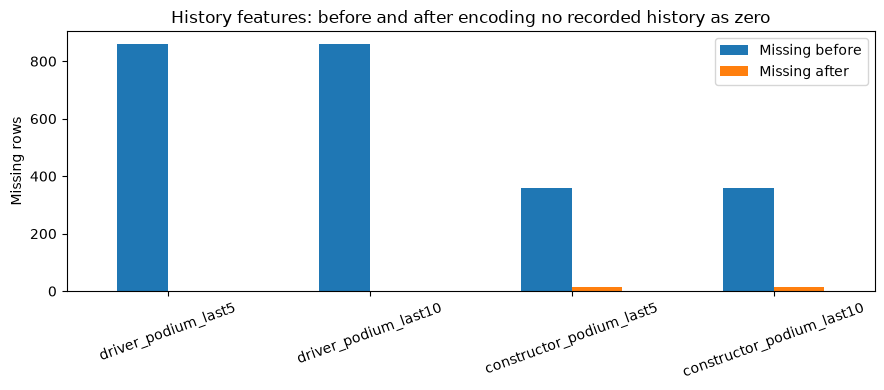

First driver-history rows encoded as zero: 861
First constructor-history rows encoded as zero: 344
Ambiguous constructor rows kept unknown: 16
Verified: both windows use up to 5/10 earlier appearances; no-history rows use zero.


In [269]:
example_driver = 1 if feature_candidates["driverId"].eq(1).any() else feature_candidates["driverId"].iloc[0]
driver_example = feature_candidates.loc[feature_candidates["driverId"].eq(example_driver)].sort_values(["date", "raceId"]).head(7)
history_examples = []
for _, row in driver_example.iterrows():
    previous = feature_candidates.loc[feature_candidates["driverId"].eq(example_driver) & feature_candidates["date"].lt(row["date"])].sort_values(["date", "raceId"]).tail(5)
    manual_rate = previous["podium"].mean() if len(previous) else 0.0
    assert (pd.isna(manual_rate) and pd.isna(row["driver_podium_last5"])) or np.isclose(manual_rate, row["driver_podium_last5"])
    history_examples.append({"driverId": example_driver, "raceId": row["raceId"], "Date": row["date"],
        "Earlier podium outcomes": previous["podium"].tolist(), "Calculated previous-5 rate": manual_rate,
        "Stored previous-5 rate": row["driver_podium_last5"], "Current podium (not included)": row["podium"]})
display(pd.DataFrame(history_examples))
team_consistency = feature_candidates.groupby(["raceId", "constructorId"])["constructor_podium_last5"].nunique()
assert team_consistency.le(1).all()
print("Verified: team form is shared within each race and uses earlier race dates.")

# Show the missingness before and after the explicit no-history convention.
history_before_after = pd.DataFrame({"Missing before": history_missing_before,
                                     "Missing after": history_missing_after})
display(history_before_after)
history_before_after.plot.bar(figsize=(9, 4), rot=20)
plt.ylabel("Missing rows")
plt.title("History features: before and after encoding no recorded history as zero")
plt.tight_layout()
plt.show()
print("First driver-history rows encoded as zero:", int(first_driver_history.sum()))
print("First constructor-history rows encoded as zero:", int(first_constructor_history.sum()))
print("Ambiguous constructor rows kept unknown:", int(ambiguous_constructor.sum()))
# Check both windows independently for the example driver's early appearances.
for _, row in driver_example.iterrows():
    earlier = feature_candidates.loc[feature_candidates["driverId"].eq(example_driver) &
        feature_candidates["date"].lt(row["date"])].sort_values(["date", "raceId"])
    for window in [5, 10]:
        expected = earlier["podium"].tail(window).mean() if len(earlier) else 0.0
        assert np.isclose(row[f"driver_podium_last{window}"], expected)
print("Verified: both windows use up to 5/10 earlier appearances; no-history rows use zero.")


## 5.4 Coverage before relevance

The next outputs report each candidate's observed count, missing percentage and missingness by year. First-appearance form now uses an explicitly documented zero with its history count. Ambiguous shared-drive information and historical qualifying coverage remain unknown and are reported separately.

All-year coverage is required evidence for our intended historical scope. A strong correlation on a recent subset does not establish historical availability. Standings and sprint outcomes remain deferred candidates: current-round standings require a prior-round join; sprint inputs require a verified pre-race cutoff and modern-only coverage assessment.


,Observed rows,Missing rows,Missing (%),Distinct observed values
grid,26668,0,0.00,35
qualifying_position,10494,16174,60.65,28
driver_age,26668,0,0.00,7620
driver_prior_appearances,26668,0,0.00,404
driver_podium_last5,26668,0,0.00,11
driver_podium_last10,26668,0,0.00,28
constructor_prior_recorded_races,26652,16,0.06,1100
constructor_podium_last5,26652,16,0.06,232
constructor_podium_last10,26652,16,0.06,387
driver_gp_points_before,26668,0,0.00,413


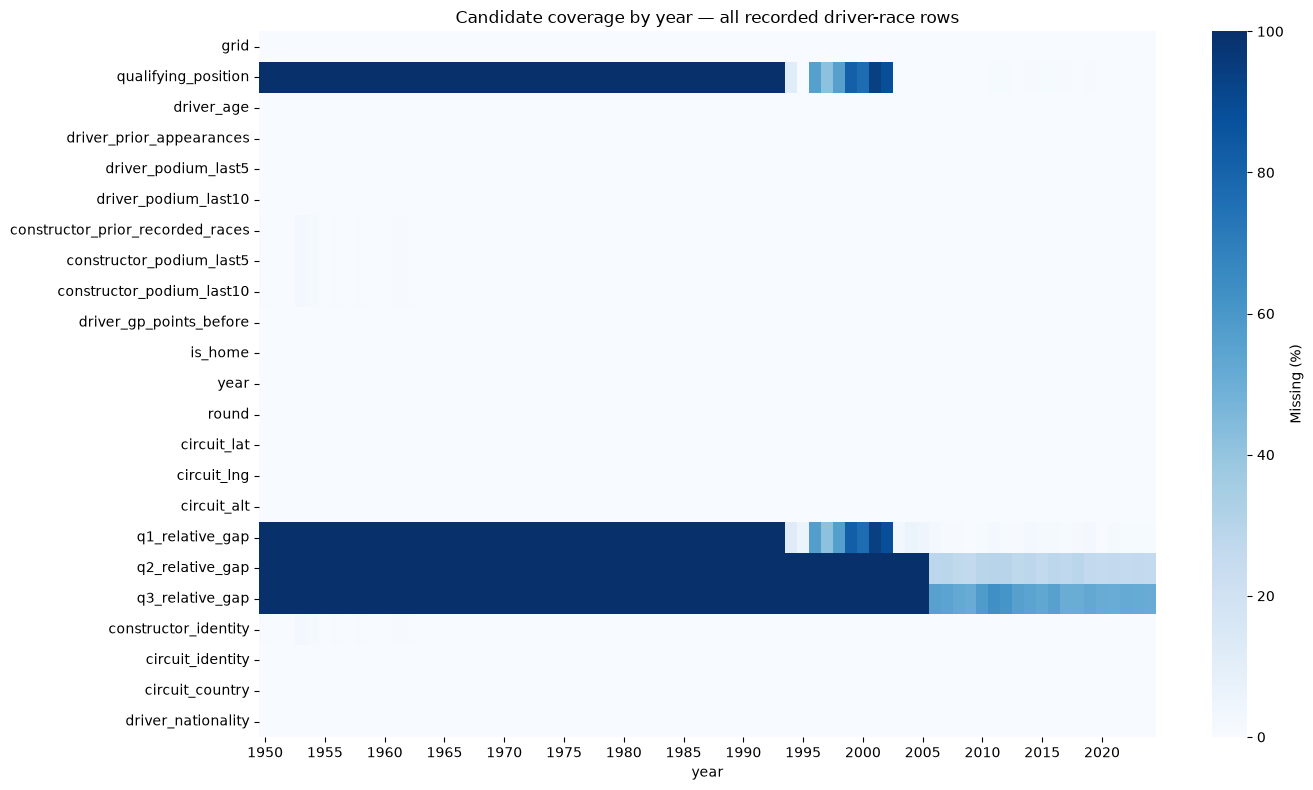

In [270]:
candidate_columns = numeric_candidates + categorical_candidates
feature_coverage = pd.DataFrame({
    "Observed rows": feature_candidates[candidate_columns].notna().sum(),
    "Missing rows": feature_candidates[candidate_columns].isna().sum(),
    "Missing (%)": feature_candidates[candidate_columns].isna().mean() * 100,
    "Distinct observed values": feature_candidates[candidate_columns].nunique()
})
with pd.option_context("display.max_rows", None):
    display(feature_coverage.round(2))
feature_missing_by_year = feature_candidates[candidate_columns].isna().groupby(feature_candidates["year"]).mean() * 100
plt.figure(figsize=(14, 8))
sns.heatmap(feature_missing_by_year.T, vmin=0, vmax=100, cmap="Blues", xticklabels=5,
            cbar_kws={"label": "Missing (%)"})
plt.title("Candidate coverage by year — all recorded driver-race rows")
plt.tight_layout()
plt.show()


## 5.5 Relationships with podium — descriptive evidence

We show correlations and outcome-group plots, following Lab 1. These describe associations, not causal effects or model improvement. There is no automatic correlation threshold for keeping or dropping a candidate.

Pearson measures a linear association; the rank-based statistic measures a monotonic association. Both are calculated using the paired observed rows for that feature. Missing rows are not filled or silently presented as observed. The paired count and coverage must be read alongside the score. Categorical labels are compared using podium rates and sample sizes rather than correlations of arbitrary numeric codes.


,Paired rows,Missing (%),Pearson,Rank correlation
Feature,,,,
q3_relative_gap,3629,86.392,-0.313,-0.508
qualifying_position,10494,60.649,-0.487,-0.492
q2_relative_gap,5740,78.476,-0.182,-0.454
driver_podium_last5,26668,0.000,0.475,0.453
driver_podium_last10,26668,0.000,0.490,0.451
constructor_podium_last5,26652,0.060,0.464,0.426
constructor_podium_last10,26652,0.060,0.471,0.424
q1_relative_gap,10338,61.234,-0.057,-0.394
grid,26668,0.000,-0.365,-0.372


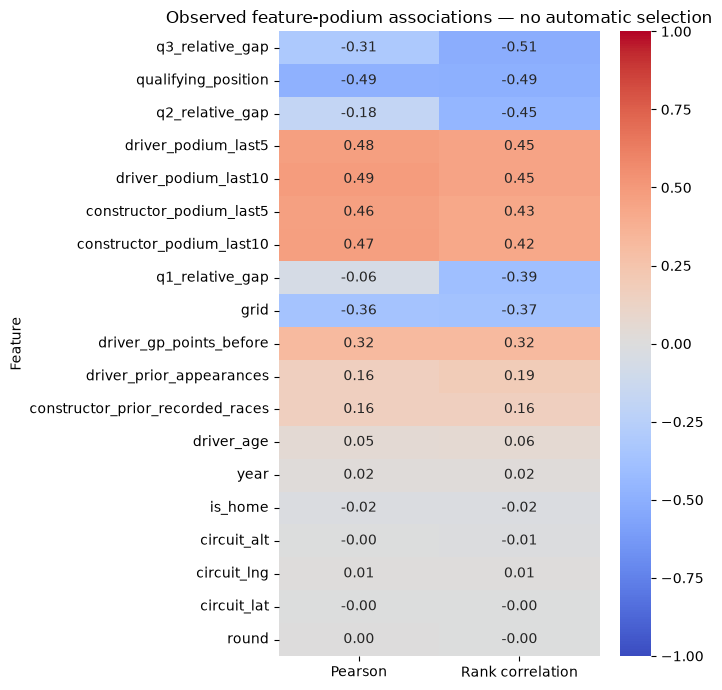

In [271]:
correlation_rows = []
for feature in numeric_candidates:
    pairs = feature_candidates[[feature, "podium"]].dropna()
    enough_variation = pairs[feature].nunique() > 1 and pairs["podium"].nunique() > 1
    pearson = pairs[feature].corr(pairs["podium"]) if enough_variation else np.nan
    rank_correlation = pairs[feature].rank().corr(pairs["podium"].rank()) if enough_variation else np.nan
    correlation_rows.append({"Feature": feature, "Paired rows": len(pairs),
        "Missing (%)": feature_coverage.loc[feature, "Missing (%)"],
        "Pearson": pearson, "Rank correlation": rank_correlation})
feature_associations = pd.DataFrame(correlation_rows).set_index("Feature")
feature_associations = feature_associations.loc[feature_associations["Rank correlation"].abs().sort_values(ascending=False).index]
display(feature_associations.round(3))
plt.figure(figsize=(7, 7))
sns.heatmap(feature_associations[["Pearson", "Rank correlation"]], annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Observed feature-podium associations — no automatic selection")
plt.tight_layout()
plt.show()


Grid — counts shown above bars; missing rows: 0


,Records,Podiums,Podium_rate,Podium (%)
Group,,,,
0,1635,0,0.000,0.000
1,1124,721,0.641,64.146
2,1119,626,0.559,55.943
3,1127,523,0.464,46.406
4,1128,386,0.342,34.220
5,1121,281,0.251,25.067
6,1120,209,0.187,18.661
7,1132,147,0.130,12.986
8,1122,112,0.100,9.982


Driver age — counts shown above bars; missing rows: 0


,Records,Podiums,Podium_rate,Podium (%)
Group,,,,
"(0, 20]",154,9,0.058,5.844
"(20, 25]",4478,403,0.090,9.000
"(25, 30]",9863,1183,0.120,11.994
"(30, 35]",7634,1195,0.157,15.654
"(35, 40]",3510,474,0.135,13.504
"(40, 50]",967,124,0.128,12.823
"(50, 100]",62,7,0.113,11.290


Driver previous-5 podium rate — counts shown above bars; missing rows: 0


...

,Records,Podiums,Podium_rate,Podium (%)
Group,,,,
"(-0.001, 0.0]",14785,346,0.023,2.340
"(0.0, 0.2]",6011,789,0.131,13.126
"(0.2, 0.4]",3208,966,0.301,30.112
"(0.4, 0.6]",1785,784,0.439,43.922
"(0.6, 0.8]",719,409,0.569,56.885
"(0.8, 1.0]",144,100,0.694,69.444


Earlier driver appearances — counts shown above bars; missing rows: 0


,Records,Podiums,Podium_rate,Podium (%)
Group,,,,
"(-1, 0]",861,21,0.024,2.439
"(0, 10]",4701,218,0.046,4.637
"(10, 30]",5318,450,0.085,8.462
"(30, 75]",6959,912,0.131,13.105
"(75, 150]",5636,1057,0.188,18.754
"(150, 500]",3193,737,0.231,23.082


Home indicator — counts shown above bars; missing rows: 0


,Records,Podiums,Podium_rate,Podium (%)
Group,,,,
0.0,24180,3129,0.129,12.940
1.0,2488,266,0.107,10.691


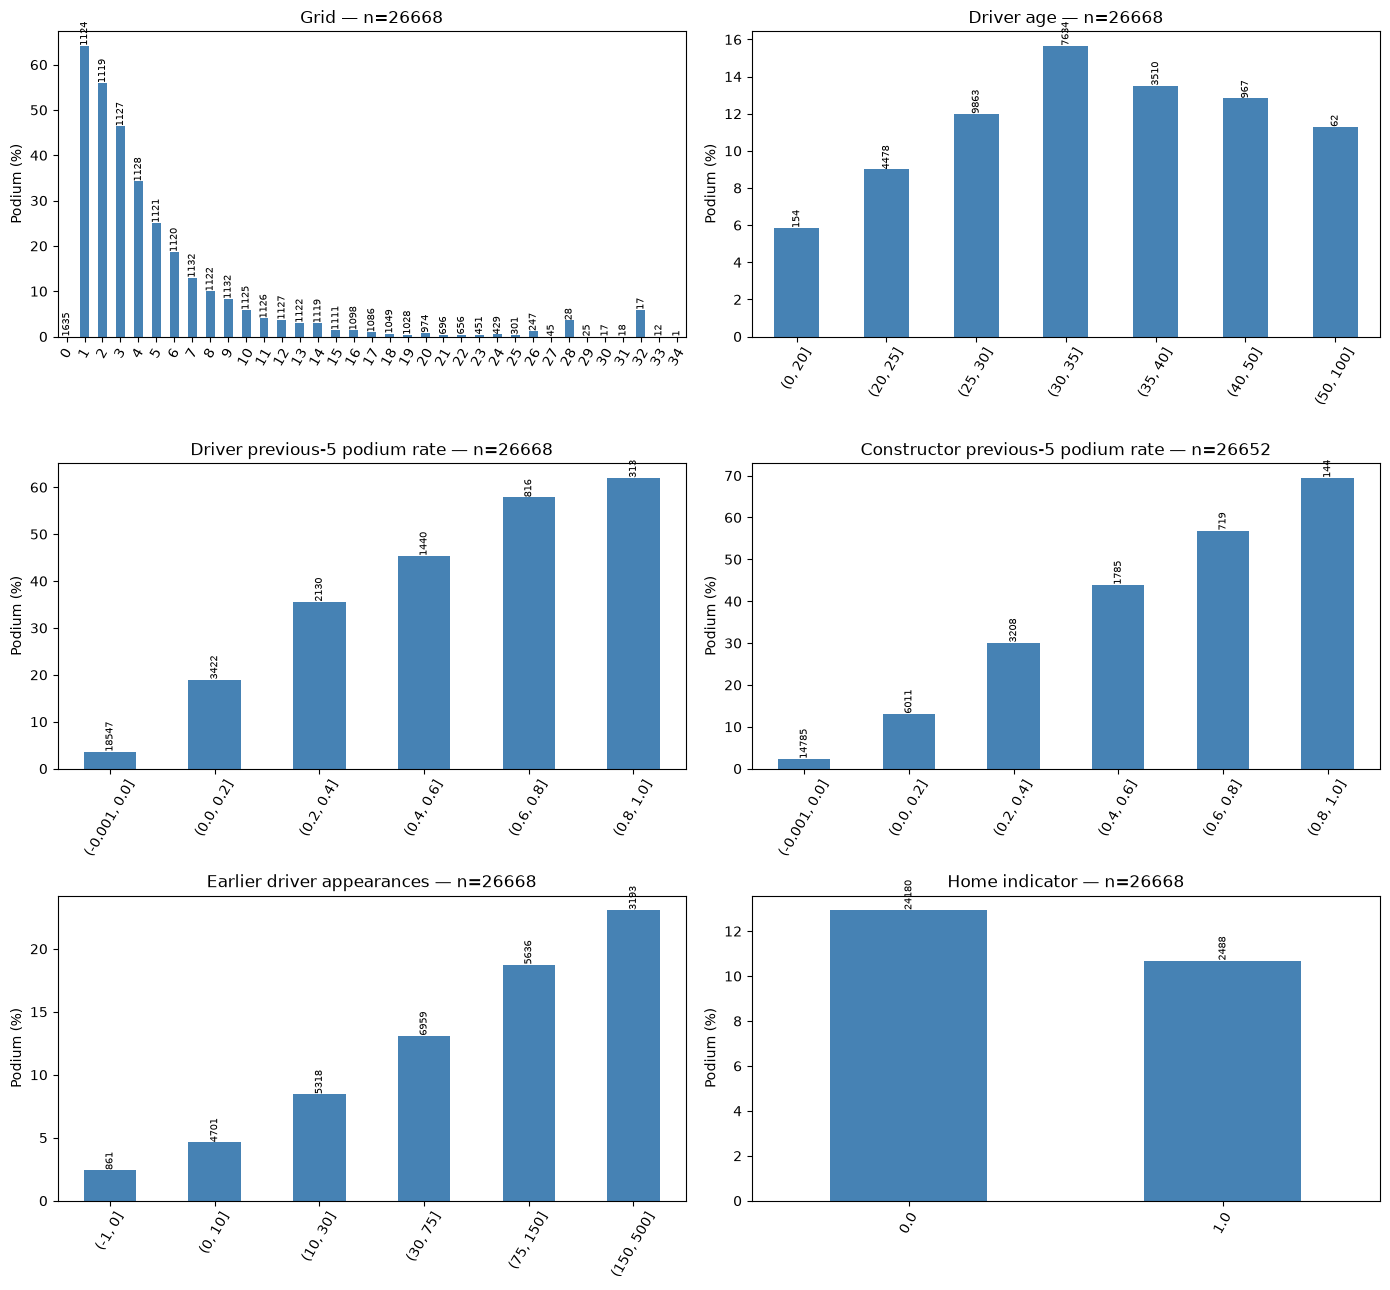

constructor_identity — interpret rates with their sample sizes


,Records,Podiums,Podium_rate,Constructor
constructor_identity,,,,
6,2417,839,0.347,Ferrari
1,1923,508,0.264,McLaren
3,1676,314,0.187,Williams
25,881,77,0.087,Tyrrell
32,871,114,0.131,Team Lotus
15,837,10,0.012,Sauber
9,788,282,0.358,Red Bull
4,787,103,0.131,Renault
18,672,0,0.000,Minardi


circuit_identity — interpret rates with their sample sizes


,Records,Podiums,Podium_rate,Circuit
circuit_identity,,,,
14,1826,226,0.124,Autodromo Nazionale di Monza
6,1657,212,0.128,Circuit de Monaco
9,1433,178,0.124,Silverstone Circuit
13,1254,172,0.137,Circuit de Spa-Francorchamps
7,1052,129,0.123,Circuit Gilles Villeneuve
20,973,124,0.127,Nürburgring
18,937,123,0.131,Autódromo José Carlos Pace
10,935,111,0.119,Hockenheimring
11,911,117,0.128,Hungaroring


circuit_country — interpret rates with their sample sizes


,Records,Podiums,Podium_rate
circuit_country,,,
Italy,2637,325,0.123
United States,2025,240,0.119
UK,1964,239,0.122
Germany,1923,238,0.124
Monaco,1657,212,0.128
Belgium,1593,208,0.131
France,1503,191,0.127
Spain,1438,183,0.127
Canada,1291,159,0.123


driver_nationality — interpret rates with their sample sizes


,Records,Podiums,Podium_rate
driver_nationality,,,
British,4543,774,0.170
Italian,3401,206,0.061
French,3087,312,0.101
German,2429,415,0.171
Brazilian,1952,293,0.150
American,1282,129,0.101
Finnish,1193,245,0.205
Spanish,912,135,0.148
Australian,892,140,0.157


In [272]:
feature_group_evidence = {}
feature_plot_specs = [
    ("grid", "Grid", None),
    ("driver_age", "Driver age", [0, 20, 25, 30, 35, 40, 50, 100]),
    ("driver_podium_last5", "Driver previous-5 podium rate", [-0.001, 0, .2, .4, .6, .8, 1]),
    ("constructor_podium_last5", "Constructor previous-5 podium rate", [-0.001, 0, .2, .4, .6, .8, 1]),
    ("driver_prior_appearances", "Earlier driver appearances", [-1, 0, 10, 30, 75, 150, 500]),
    ("is_home", "Home indicator", None)
]
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for ax, (feature, title, bins) in zip(axes.flat, feature_plot_specs):
    observed = feature_candidates[[feature, "podium"]].dropna().copy()
    observed["Group"] = pd.cut(observed[feature], bins=bins) if bins else observed[feature]
    grouped = observed.groupby("Group", observed=True)["podium"].agg(Records="size", Podiums="sum", Podium_rate="mean")
    feature_group_evidence[feature] = grouped
    grouped["Podium (%)"] = grouped["Podium_rate"] * 100
    grouped["Podium (%)"].plot.bar(ax=ax, color="steelblue")
    ax.set_title(title + " — n=" + str(len(observed)))
    ax.set_ylabel("Podium (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
    for bar, count in zip(ax.patches, grouped["Records"]):
        ax.annotate(str(count), (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=7, rotation=90)
    print(title, "— counts shown above bars; missing rows:", feature_candidates[feature].isna().sum())
    display(grouped.round(3))
plt.tight_layout()
plt.show()

categorical_group_evidence = {}
for feature in categorical_candidates:
    grouped = feature_candidates.groupby(feature, dropna=False)["podium"].agg(Records="size", Podiums="sum", Podium_rate="mean")
    if feature == "constructor_identity":
        grouped["Constructor"] = grouped.index.map(constructors_clean.set_index("constructorId")["name"].rename(index=str))
    elif feature == "circuit_identity":
        grouped["Circuit"] = grouped.index.map(circuits_clean.set_index("circuitId")["name"].rename(index=str))
    categorical_group_evidence[feature] = grouped
    print(feature, "— interpret rates with their sample sizes")
    with pd.option_context("display.max_rows", None):
        display(grouped.sort_values("Records", ascending=False).round(3))


## 5.6 Check overlapping information and historical stability

The feature-feature heatmap identifies candidates sharing information. It does not automatically remove them: a high correlation suggests a later comparison, not a universal deletion threshold. In particular, previous-5 and previous-10 form are alternatives to test.

The historical bands below are descriptive groups, not training/validation/test splits. Per-band counts accompany correlations. Differences can reflect rule changes, participation, missingness or changing competition. A global association alone does not establish that a feature behaves consistently throughout history.

Only the explicit numeric candidates from section 5.3 enter these heatmaps. `original_entries` and `constructor_choices` are useful for detecting multiple entries, but are not proposed predictors. The original `grid` is compared directly, including its recorded zeros. Raw qualifying times are retained in the table; the intended timing candidates use relative gaps instead.


In [273]:
feature_candidates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 39 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   raceId                            26668 non-null  int64         
 1   driverId                          26668 non-null  int64         
 2   constructorId                     26668 non-null  int64         
 3   grid                              26668 non-null  int64         
 4   positionOrder                     26668 non-null  int64         
 5   points                            26668 non-null  float64       
 6   original_entries                  26668 non-null  int64         
 7   constructor_choices               26668 non-null  int64         
 8   year                              26668 non-null  int64         
 9   round                             26668 non-null  int64         
 10  date                              26668 non-nu

Exploring 19 numeric candidates; inspection fields excluded.


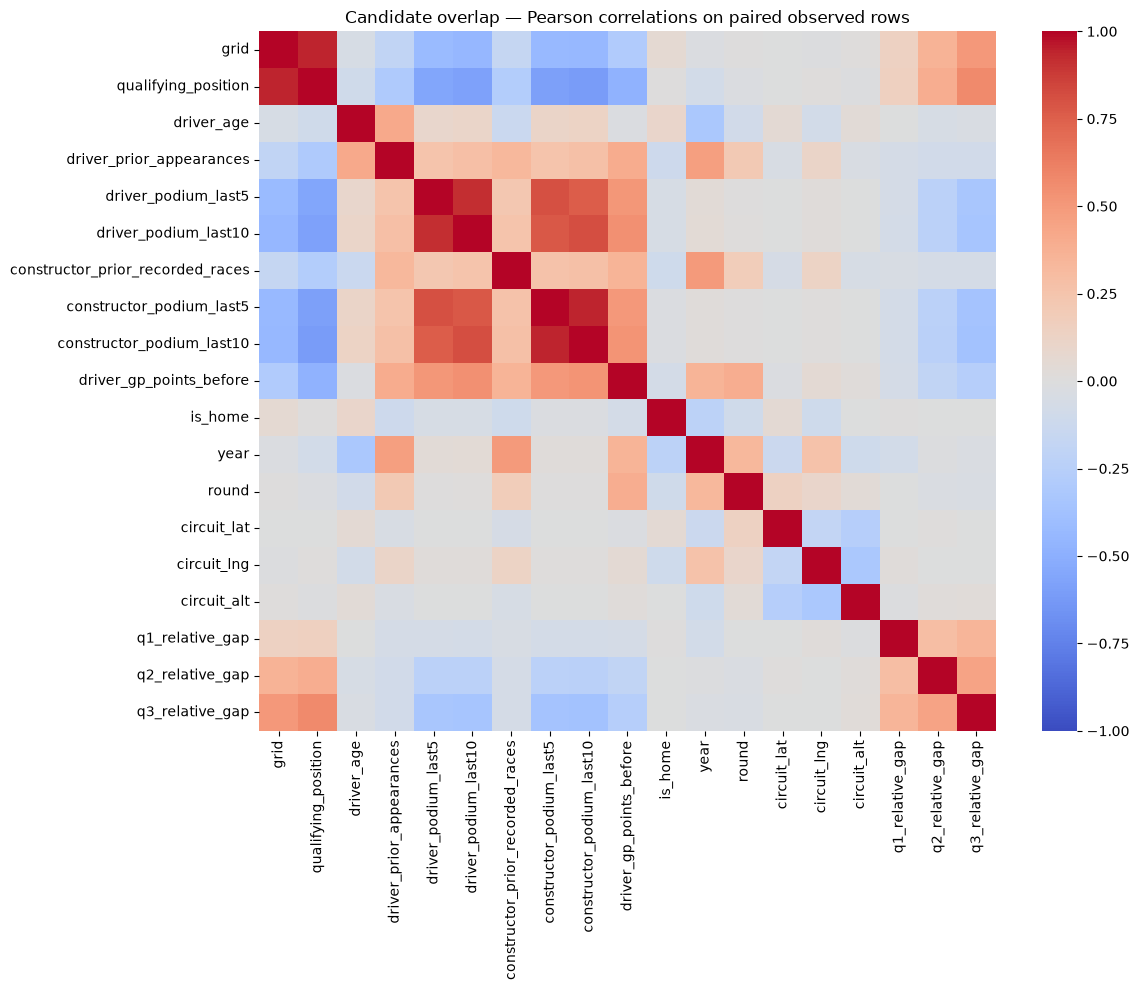

Era,1950–1979,1980–1999,2000–2005,2006–2013,2014–2020,2021–2024
Feature,,,,,,
circuit_alt,7836,8753,2165,3288,2827,1799
circuit_lat,7836,8753,2165,3288,2827,1799
circuit_lng,7836,8753,2165,3288,2827,1799
constructor_podium_last10,7820,8753,2165,3288,2827,1799
constructor_podium_last5,7820,8753,2165,3288,2827,1799
constructor_prior_recorded_races,7820,8753,2165,3288,2827,1799
driver_age,7836,8753,2165,3288,2827,1799
driver_gp_points_before,7836,8753,2165,3288,2827,1799
driver_podium_last10,7836,8753,2165,3288,2827,1799


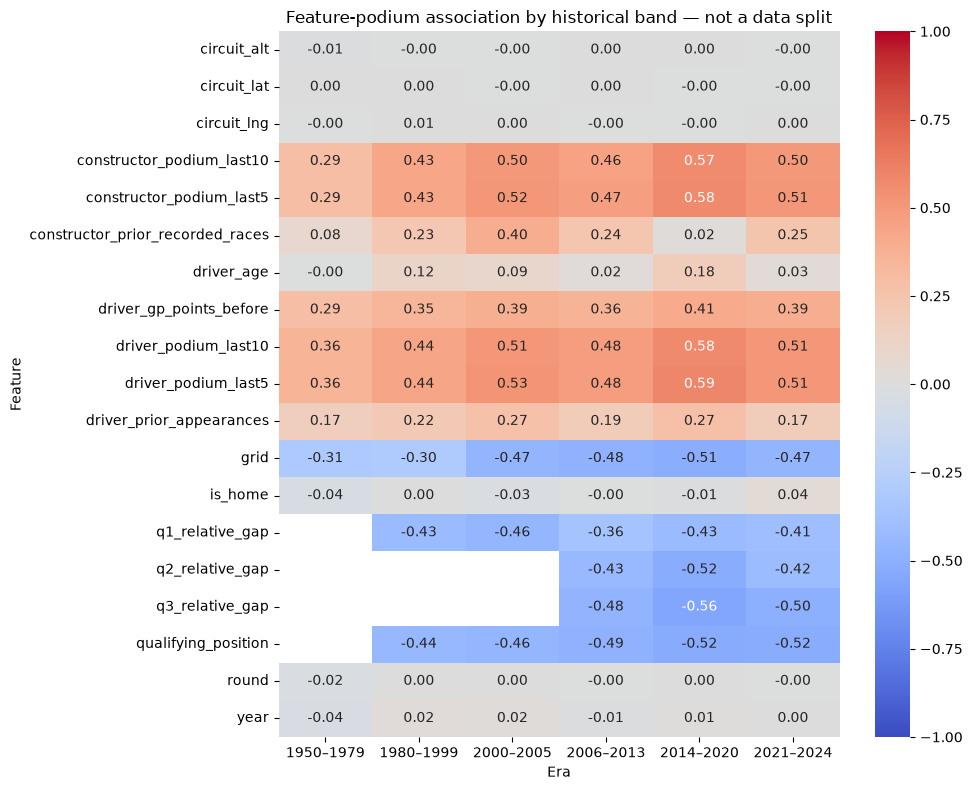

In [274]:
# Use the explicit candidate list defined in section 5.3.
# Inspection fields remain in feature_candidates for checks, not feature heatmaps.
assert not {"original_entries", "constructor_choices"}.intersection(numeric_candidates)
print(f"Exploring {len(numeric_candidates)} numeric candidates; inspection fields excluded.")

# 2. Feature Redundancy Correlation Heatmap
feature_redundancy = feature_candidates[numeric_candidates].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(
    feature_redundancy, 
    cmap="coolwarm", 
    center=0, 
    vmin=-1, 
    vmax=1, 
    annot=len(numeric_candidates) <= 15,  # Auto-enable annotations if feature count is manageable
    fmt=".2f"
)
plt.title("Candidate overlap — Pearson correlations on paired observed rows")
plt.tight_layout()
plt.show()

# 3. Exploration Era Binning
feature_candidates["Exploration era"] = pd.cut(
    feature_candidates["year"],
    bins=[1949, 1979, 1999, 2005, 2013, 2020, 2024],
    labels=["1950–1979", "1980–1999", "2000–2005", "2006–2013", "2014–2020", "2021–2024"]
)

# 4. Compute Feature-Podium Rank Correlations Across Eras
era_association_rows = []
for era, era_data in feature_candidates.groupby("Exploration era", observed=True):
    for feature in numeric_candidates:
        observed = era_data[[feature, "podium"]].dropna()
        score = (
            observed[feature].rank().corr(observed["podium"].rank()) 
            if observed[feature].nunique() > 1 and observed["podium"].nunique() > 1 
            else np.nan
        )
        era_association_rows.append({
            "Era": str(era), 
            "Feature": feature,
            "Observed rows": len(observed), 
            "Rank correlation": score
        })

feature_era_associations = pd.DataFrame(era_association_rows)

# Display observed rows breakdown table
display(feature_era_associations.pivot(index="Feature", columns="Era", values="Observed rows"))

# 5. Era-Based Feature Association Heatmap (Dynamic Height for all features)
plt.figure(figsize=(10, max(8, len(numeric_candidates) * 0.35)))
sns.heatmap(
    feature_era_associations.pivot(index="Feature", columns="Era", values="Rank correlation"),
    cmap="coolwarm", 
    center=0, 
    vmin=-1, 
    vmax=1, 
    annot=True, 
    fmt=".2f"
)
plt.title("Feature-podium association by historical band — not a data split")
plt.tight_layout()
plt.show()

### What the observed outputs support so far

- **Grid and recent form merit later model comparisons.** On observed records, the updated association table reports the original grid correlation, including recorded zeros; form correlations are approximately +0.45 for drivers and +0.43 for constructors. The grouped plots show corresponding changes in podium rates and include sample counts. These are associations, not validation gains or causal claims.
- **Five versus ten races is unresolved.** Their associations with podium are similar, and their feature-feature Pearson correlations are about 0.92 for drivers and 0.94 for constructors. This motivates comparing the two windows later instead of automatically using both or declaring five best.
- **Age illustrates why one correlation is insufficient.** Its Pearson association is only about +0.05, but the grouped plot rises toward ages 30–35 and falls afterward. That is a descriptive nonlinear pattern, not proof age adds value after accounting for driver/team quality.
- **Qualifying associations need coverage qualifications.** Qualifying position is observed for 10,494 of 26,668 rows; modern Q3 relative gap is observed for only 3,629. Their relatively large correlations describe those observed subsets. They do not solve pre-1994 missing qualifying records or pre-2006 format differences.
- **Home and geographic measurements remain uncertain.** Their small individual correlations do not prove uselessness. Home/away comparisons can reflect starting grid and driver composition; low coordinate correlations do not establish that circuit identity is irrelevant.
- **Historical consistency still matters.** Read each era's sample counts and missingness with its correlation. Prior GP points are not official championship points and are affected by scoring changes. No candidate is accepted merely because its global association ranks high.

The output decision sheet remains provisional. Confirmation requires later controlled feature-group comparisons; no final feature set or split has been imposed.


## 5.7 Record evidence for all explored candidates

This exploration inventory is followed by the chosen starting input list in section 5.8. The decision sheet connects every candidate to measured coverage and an association statistic. It deliberately says **candidate** or **coverage review**, not “selected because it improves the model.” A nonzero correlation is not a guarantee of incremental predictive value; a small correlation does not rule out nonlinear or interaction effects.

Next modeling experiments should compare feature groups, previous-5 versus previous-10 form, and alternative missing-value handling under controlled settings. The team’s final models must use the same agreed rows and feature set. No model, ablation result, or benefit from imputation is claimed here.

Current-race outcomes, schedule columns already removed, names/URLs and audit flags are not made inputs. Official standings and sprint features remain pending their own temporal/coverage evidence. Qualifying features remain pending the historical-coverage and missing-data decisions already discussed.


In [275]:
feature_decision_sheet = feature_coverage.copy()
feature_decision_sheet = feature_decision_sheet.join(feature_associations[["Pearson", "Rank correlation"]])
feature_decision_sheet["Current decision"] = "Candidate only — usefulness requires later validation"
qualifying_features = ["qualifying_position", "q1_relative_gap", "q2_relative_gap", "q3_relative_gap"]
feature_decision_sheet.loc[qualifying_features, "Current decision"] = "Coverage/format review — not accepted for all-years inputs"
feature_decision_sheet.loc[["driver_gp_points_before", "year"], "Current decision"] = "Era/scoring sensitivity review — not finalized"
feature_decision_sheet.loc[["constructor_identity", "circuit_identity", "circuit_country", "driver_nationality"], "Current decision"] = "Categorical candidate — use grouped rates, not numeric ID correlations"
feature_decision_sheet["Evidence"] = "Coverage table; grouped rates where shown; association and era tables"
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100):
    display(feature_decision_sheet.round(3))
for name, table in clean.items():
    assert feature_source_checks[name] == (table.shape, tuple(table.columns), pd.util.hash_pandas_object(table, index=True).sum())
assert len(feature_candidates) == len(results_clean)
assert not feature_candidates.duplicated(["raceId", "driverId"]).any()
print("Verified: all source clean tables unchanged; one candidate row per driver and race.")
print("Exploration complete. No final feature list, imputation, split or model has been chosen.")


,Observed rows,Missing rows,Missing (%),Distinct observed values,Pearson,Rank correlation,Current decision,Evidence
grid,26668,0,0.000,35,-0.365,-0.372,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
qualifying_position,10494,16174,60.649,28,-0.487,-0.492,Coverage/format review — not accepted for all-years inputs,Coverage table; grouped rates where shown; association and era tables
driver_age,26668,0,0.000,7620,0.050,0.057,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
driver_prior_appearances,26668,0,0.000,404,0.162,0.192,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
driver_podium_last5,26668,0,0.000,11,0.475,0.453,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
driver_podium_last10,26668,0,0.000,28,0.490,0.451,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
constructor_prior_recorded_races,26652,16,0.060,1100,0.158,0.157,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
constructor_podium_last5,26652,16,0.060,232,0.464,0.426,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
constructor_podium_last10,26652,16,0.060,387,0.471,0.424,Candidate only — usefulness requires later validation,Coverage table; grouped rates where shown; association and era tables
driver_gp_points_before,26668,0,0.000,413,0.320,0.318,Era/scoring sensitivity review — not finalized,Coverage table; grouped rates where shown; association and era tables


Verified: all source clean tables unchanged; one candidate row per driver and race.
Exploration complete. No final feature list, imputation, split or model has been chosen.


## 5.8 Document the candidate table and provisional inputs

The current exploration table is **`feature_candidates`**, not the final model input matrix. It has one row per `(raceId, driverId)`. We have not assigned `X`/`y`, chosen a split, chosen general missing-input preprocessing, or trained models in this section.

### Which tables were combined?

| Table | Join key / relationship | Information carried into the candidate table |
|---|---|---|
| `results_clean` | Base; one row per driver–race | raceId, driverId, constructorId, grid, positionOrder, points |
| `races_clean` | Left join on raceId; many results to one race | year, round, date, circuitId |
| `drivers_clean` | Left join on driverId; many results to one driver | dob and nationality, renamed driver_nationality |
| `circuits_clean` | Left join on circuitId; many races to one circuit | country, lat, lng, alt, renamed with circuit prefixes |
| `qualifying_clean` | Left join on raceId + driverId; one-to-one | position renamed qualifying_position, plus q1/q2/q3 |

All joins preserve the base rows and validate the expected relationship. A missing qualifying match remains missing; it does not remove a race result.

Raw `results` is also grouped by driver–race to obtain `original_entries` and `constructor_choices` for the shared-drive audit. No raw record is changed. `constructors_clean` supplies names for the explanatory categorical tables, not an additional joined constructor-nationality predictor. The existing nationality-to-country mapping is reused for `is_home`.


### Which information is existing, and which is engineered?

Existing columns come from the source tables above; a rename such as `position` to `qualifying_position` does not create a new measurement.

| New feature or representation | Calculation / meaning |
|---|---|
| driver_age | Days between birth and race dates / 365.2425; continuous approximate age |
| driver_prior_appearances | Number of this driver's earlier recorded appearances |
| driver_podium_last5 / last10 | Mean over up to 5/10 earlier appearances; 0 if no recorded history, accompanied by driver_prior_appearances |
| constructor_prior_recorded_races | Number of earlier usable team race summaries |
| constructor_podium_last5 / last10 | Mean credited-driver podium rate over up to 5/10 earlier usable races; 0 if no recorded history, accompanied by constructor_prior_recorded_races; ambiguous teams stay unknown |
| driver_gp_points_before | Sum of this driver's GP points earlier in the same season; excludes sprint points and is not an official championship standing |
| is_home | Circuit country belongs to the driver's mapped nationality countries |
| q1_relative_gap | Q1 time / fastest observed Q1 in this race - 1 |
| q2_relative_gap / q3_relative_gap | Same within-stage calculation; undefined before the modern format in 2006 |
| circuit_identity / constructor_identity | Categorical representations of IDs, not numerical magnitudes; constructor identity masked when original entries involve different teams |

`podium` is the target derived from positionOrder, not an input. `original_entries`, `constructor_choices`, previous-race dates and `Exploration era` support checking and plots. They are not selected predictors. Constructor form describes credited driver records, not unique cars; ambiguous cross-constructor records are excluded from its history calculation.

### Missing values in every column

The next table includes **all columns, including those with zero missing values**. It distinguishes original/renamed information, engineered candidates, target and inspection fields. Counts are recalculated from the current candidate table whenever the notebook runs.


In [276]:
feature_column_details = {
    "raceId": ("Existing", "results_clean.raceId", "Driver-race identifier"),
    "driverId": ("Existing", "results_clean.driverId", "Driver identifier"),
    "constructorId": ("Existing", "results_clean.constructorId", "Retained result's constructor identifier"),
    "grid": ("Existing", "results_clean.grid", "Recorded grid from results_clean; zero retained; multiple-entry limitation documented"),
    "positionOrder": ("Existing outcome", "results_clean.positionOrder", "Final ordering; used for target, not a current-race input"),
    "points": ("Existing outcome", "results_clean.points", "Current GP points; only earlier-race aggregates may be inputs"),
    "original_entries": ("Audit-derived", "Raw results grouped by raceId + driverId", "Original number of car entries"),
    "constructor_choices": ("Audit-derived", "Raw results grouped by raceId + driverId", "Number of distinct original constructors"),
    "year": ("Existing", "races_clean.year", "Race season; era sensitivity needs review"),
    "round": ("Existing", "races_clean.round", "Season round"),
    "date": ("Existing", "races_clean.date", "Race date for ordering, age and history"),
    "circuitId": ("Existing", "races_clean.circuitId", "Circuit join identifier"),
    "dob": ("Existing", "drivers_clean.dob", "Birth date used to calculate age"),
    "driver_nationality": ("Existing, renamed", "drivers_clean.nationality", "Driver nationality"),
    "circuit_country": ("Existing, renamed", "circuits_clean.country", "Circuit country"),
    "circuit_lat": ("Existing, renamed", "circuits_clean.lat", "Circuit latitude"),
    "circuit_lng": ("Existing, renamed", "circuits_clean.lng", "Circuit longitude"),
    "circuit_alt": ("Existing, renamed", "circuits_clean.alt", "Circuit altitude"),
    "qualifying_position": ("Existing, renamed", "qualifying_clean.position", "Qualifying order; absent matches produce missing values"),
    "q1": ("Existing", "qualifying_clean.q1", "Recorded first-session time in seconds; historical formats differ"),
    "q2": ("Existing", "qualifying_clean.q2", "Recorded second-session time in seconds; historical formats differ"),
    "q3": ("Existing", "qualifying_clean.q3", "Recorded third-stage time in seconds"),
    "circuit_identity": ("Derived representation", "circuitId as a category", "Same circuit identity represented categorically"),
    "podium": ("Target", "positionOrder between 1 and 3", "Output: 1 podium, 0 otherwise"),
    "constructor_identity": ("Guarded categorical candidate", "constructorId with ambiguous original teams masked", "Constructor identity candidate"),
    "driver_age": ("Engineered", "date minus dob", "Approximate age in years"),
    "driver_prior_appearances": ("Engineered history", "Earlier driver records", "Earlier appearances, not verified starts"),
    "driver_podium_last5": ("Engineered history", "Previous 5 driver podium outcomes", "Recent driver podium proportion"),
    "driver_podium_last10": ("Engineered history", "Previous 10 driver podium outcomes", "Alternative driver-form window"),
    "driver_gp_points_before": ("Engineered history", "Earlier same-season GP points", "GP-only cumulative points; scoring systems vary"),
    "previous_driver_date": ("Audit-derived", "Previous recorded driver date", "Checks history is earlier than current race"),
    "constructor_prior_recorded_races": ("Engineered history", "Earlier usable constructor-race summaries", "Team recorded experience"),
    "constructor_podium_last5": ("Engineered history", "Previous 5 constructor race summaries", "Recent credited-driver podium rate"),
    "constructor_podium_last10": ("Engineered history", "Previous 10 constructor race summaries", "Alternative constructor-form window"),
    "previous_constructor_date": ("Audit-derived", "Previous usable constructor date", "Checks team history is earlier than current race"),
    "is_home": ("Engineered", "Mapped driver nationality compared with circuit country", "1 home, 0 away; unknown mappings stay missing"),
    "q1_relative_gap": ("Engineered", "q1 / race's fastest observed q1 - 1", "Relative first-session time"),
    "q2_relative_gap": ("Engineered", "q2 / race's fastest observed q2 - 1; from 2006", "Relative modern Q2 time"),
    "q3_relative_gap": ("Engineered", "q3 / race's fastest observed q3 - 1; from 2006", "Relative modern Q3 time"),
    "Exploration era": ("Audit-derived", "year grouped into descriptive historical bands", "Plot grouping only; not a data split")
}
assert set(feature_column_details) == set(feature_candidates.columns), "Update the documentation for any new or removed candidate column."
feature_documentation = pd.DataFrame([
    {"Column": column, "Kind": feature_column_details[column][0],
     "Source / calculation": feature_column_details[column][1],
     "Meaning": feature_column_details[column][2],
     "Missing rows": int(feature_candidates[column].isna().sum()),
     "Missing (%)": feature_candidates[column].isna().mean() * 100}
    for column in feature_candidates.columns
])
print("Candidate table:", feature_candidates.shape)
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", 85):
    display(feature_documentation.round(2))


Candidate table: (26668, 40)


,Column,Kind,Source / calculation,Meaning,Missing rows,Missing (%)
0,raceId,Existing,results_clean.raceId,Driver-race identifier,0,0.00
1,driverId,Existing,results_clean.driverId,Driver identifier,0,0.00
2,constructorId,Existing,results_clean.constructorId,Retained result's constructor identifier,0,0.00
3,grid,Existing,results_clean.grid,Recorded grid from results_clean; zero retained; multiple-entry limitation docume...,0,0.00
4,positionOrder,Existing outcome,results_clean.positionOrder,"Final ordering; used for target, not a current-race input",0,0.00
5,points,Existing outcome,results_clean.points,Current GP points; only earlier-race aggregates may be inputs,0,0.00
6,original_entries,Audit-derived,Raw results grouped by raceId + driverId,Original number of car entries,0,0.00
7,constructor_choices,Audit-derived,Raw results grouped by raceId + driverId,Number of distinct original constructors,0,0.00
8,year,Existing,races_clean.year,Race season; era sensitivity needs review,0,0.00
9,round,Existing,races_clean.round,Season round,0,0.00


### Chosen starting inputs and the evidence behind them

We first examine these **nine recorded inputs** as hypotheses. Section 5.9 adjusts grid zero for modeling and adds `no_grid_slot`, making the section 6.1 starting set **ten** inputs. This is a baseline choice to evaluate, not a claim that these inputs are optimal. The candidate table deliberately retains other columns for inspection and later comparisons.

| Input | Meaning | Evidence / reason for including it |
|---|---|---|
| grid | Recorded starting-grid value from results_clean, including zero | The updated grid bars and correlation table provide the exploratory evidence. Zero is retained as a special code rather than turned into missing data. The positive numbered slots show the starting-position relationship; historical multiple-entry attribution remains a documented limitation. |
| driver_podium_last5 | Podium proportion over up to five earlier driver appearances | Section 5.5 form bars rise with earlier podium form; rank correlation is approximately +0.45. Uses earlier races only. |
| constructor_podium_last5 | Average credited-driver podium proportion over up to five earlier usable team races | Section 5.5 team-form bars rise with earlier form; rank correlation is approximately +0.43. The history checks exclude the current race. |
| driver_prior_appearances | Number of earlier recorded driver appearances | The experience-group plot shows differences in podium rates; rank correlation is about +0.19. Also distinguishes a newcomer with form 0 from an experienced driver with form 0. |
| constructor_prior_recorded_races | Number of earlier usable constructor-race summaries | The association table shows a modest rank correlation of about +0.16. Also distinguishes no recorded team history from previous races without podiums. Ambiguous team cases remain unknown. |
| driver_age | Approximate age at race date | The age-group plot rises toward 30–35 and falls afterward despite a small linear correlation. Included to test the observed nonlinear pattern, not because the plot proves an independent age effect. |
| driver_gp_points_before | Driver's GP points from earlier races in the same season | The association table shows rank correlation about +0.32. The era table motivates caution because scoring rules differ. These are GP-only points, not official championship standings. |
| is_home | 1 when mapped nationality matches circuit country; otherwise 0 | The home/away plot shows different observed rates, but the rank correlation is small (about -0.02) and the pattern can reflect driver/grid composition. Retained as an explicitly weak hypothesis to test alongside grid; it is not evidence of a home advantage. |
| year | Race season | The coverage/era plots show that the historical context changes. Included as a simple era-context hypothesis; its small individual rank correlation (about +0.02) does not prove usefulness. A continuous year also does not fully encode technical-rule eras. |

The strongest direct exploratory support is for grid and recent driver/team form. Home and year have weaker support and should be compared with their removal during validation; no validation gain is claimed for any input. We retain history counts alongside form to preserve the no-history meaning. All nine inputs must be available or derived at the pre-race cutoff; current-race outcomes are excluded.

### Why other explored columns are not in this starting set

| Explored information | Current decision and reason |
|---|---|
| driver_podium_last10 / constructor_podium_last10 | Defer as alternatives to last5. The redundancy heatmap shows high overlap (approximately 0.92 driver / 0.94 constructor correlation). Five is a starting window, not a demonstrated winner; compare five versus ten using validation. |
| qualifying_position and relative Q1/Q2/Q3 gaps | Defer from the all-years starting model. The coverage heatmap shows long historical gaps and stage-format differences. Strong correlations on the observed subset do not establish all-years availability. |
| circuit_identity | Keep as the next categorical feature comparison; see reminder below. The category table shows rates/counts, but no incremental model benefit has been established. |
| constructor_identity | Defer initially; recent constructor form supplies a numerical summary of past performance. This does not prove identity adds nothing. Compare it separately with appropriate encoding and historical-ambiguity handling. |
| nationality, circuit country, circuit coordinates and altitude | Defer from the compact starting set. Home already represents one nationality-country relationship, and geographic measurements show small individual associations. This is a starting simplification, not proof these columns cannot help. |
| round | Defer initially; the individual correlation is close to zero. Earlier-season points are already included. Their information is not identical; validation can test whether round adds value. |
| raw q1/q2/q3 | Retain for inspection and deriving relative timing gaps. Raw durations depend on circuit and historical format. Grid itself is already included directly. |
| IDs used only for joins, dates, birth date, names/URLs and inspection fields | Used to build or check features, not direct inputs in this starting model. original_entries and constructor_choices remain audit fields. |
| Current-race positionOrder, points, laps and status | Exclude as current-race inputs: they are outcomes known after the prediction cutoff. Earlier-race aggregates are different. |

**Output:** `podium`, equal to 1 for positionOrder 1–3 and 0 otherwise. `positionOrder` is used to create this target, not supplied to the model as an input.

These choices are supported starting hypotheses from descriptive EDA. Section 6 documents the time split; later validation and feature-group ablation determine which choices actually help. Existing outcome plots cover all years, including later test years, so they are not held-out evidence.

### What missingness still needs treatment?

The documentation table above recalculates the current counts. **Grid has no missing values in the current table.** Qualifying information and ambiguous constructor inputs remain incomplete. The candidate inputs still have these distinct gaps:

| Remaining gap | Why it is missing / next decision |
|---|---|
| qualifying_position | Entire qualifying matches are absent for many historical driver–race records, even though position is complete within qualifying_clean. |
| q1/q2/q3 and relative gaps | Missing recorded times, absent qualifying matches, and historical format differences; no time is invented here. |
| constructor_identity, constructor_prior_recorded_races, constructor_podium_last5 and last10 | 16 driver–race records involve different original constructors; zero would falsely describe them as a known new team. |

Driver form has no remaining missing values. Constructor form has zero for its first usable recorded race and remains missing only for the 16 ambiguous records. Use form **together with its history count** as a candidate input group. These choices provide a consistent baseline representation; later validation must establish usefulness and compare 5 versus 10.

`previous_driver_date` and `previous_constructor_date` are inspection fields, not inputs. Missing previous dates for first appearances are expected and do not require invented dates. Only missingness in eventual chosen inputs needs model preprocessing; fit learned filling values after the split on training data only. The next output lists every still-missing candidate input, rather than assuming which columns remain incomplete.

### Reminder: compare circuit identity during model development

`circuit_identity` is a candidate categorical input: circuit layouts differ, and the category table above displays podium rates and record counts. Those descriptive rates alone do not prove an independent benefit. It is not currently in the neural-network input list.

Later, compare the current inputs with the same inputs plus encoded circuit identity. Keep the model settings, rows and split fixed; fit the encoder on training data and handle unseen circuits. Compare validation metrics, not test metrics, to decide whether to retain it. Record the result, including a lack of improvement. Do not treat numeric circuit IDs as ordered measurements.

No feature is compulsory merely because it is available. Last5 versus last10, qualifying, context and identity features remain candidates to compare or explicitly defer. The current model is a starting subset, not a proven optimal feature set. The inspection fields removed from the heatmaps stay in the candidate table for validation only.

### Why current-race status is not an input

Current-race `status` describes the eventual result (for example Finished, Engine, Collision or Withdrew). The project predicts before the race, so the final status cannot be supplied as an input. A retirement can happen during the race, and zero laps or grid zero alone does not prove no start.

Status is useful in participation audits and the data-engineering questions. A verified withdrawal known before the prediction cutoff could help define which entrants are eligible, but filtering with final race status can introduce future information. No participation filtering is introduced in this change. Earlier-race status could support a separately engineered history feature later; that is not part of the current input set.


In [277]:
remaining_input_missing = feature_candidates[numeric_candidates + categorical_candidates].isna().sum()
remaining_input_missing = remaining_input_missing[remaining_input_missing.gt(0)].sort_values(ascending=False)
display(remaining_input_missing.rename("Missing rows").to_frame())
assert feature_candidates["driver_podium_last5"].isna().sum() == 0
assert feature_candidates["driver_podium_last10"].isna().sum() == 0
for column in ["constructor_identity", "constructor_prior_recorded_races", "constructor_podium_last5", "constructor_podium_last10"]:
    assert feature_candidates[column].isna().equals(feature_candidates["constructor_choices"].gt(1))
print("History convention verified; grid is complete; qualifying and ambiguous constructor inputs still need decisions.")


,Missing rows
q3_relative_gap,23039
q2_relative_gap,20928
q1_relative_gap,16330
qualifying_position,16174
constructor_prior_recorded_races,16
constructor_podium_last5,16
constructor_podium_last10,16
constructor_identity,16


History convention verified; grid is complete; qualifying and ambiguous constructor inputs still need decisions.


In [278]:
feature_candidates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 40 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   raceId                            26668 non-null  int64         
 1   driverId                          26668 non-null  int64         
 2   constructorId                     26668 non-null  int64         
 3   grid                              26668 non-null  int64         
 4   positionOrder                     26668 non-null  int64         
 5   points                            26668 non-null  float64       
 6   original_entries                  26668 non-null  int64         
 7   constructor_choices               26668 non-null  int64         
 8   year                              26668 non-null  int64         
 9   round                             26668 non-null  int64         
 10  date                              26668 non-nu

## 5.9 Additional pre-race features

Section 5 examined nine recorded inputs. Here we adjust `feature_candidates.grid` for modeling and add `no_grid_slot` and other pre-race candidates. The recorded `results_clean.grid` remains unchanged. Section 6.1 starts with ten model inputs.

### Qualifying features: tested as training versions, not added here

The earlier coverage tables show how qualifying availability varies by season. Grid and qualifying order are compared in the displayed exploratory results. The training-version experiments below test whether qualifying inputs help.

The feature experiments in section 6.4 therefore use all seasons without qualifying columns. Qualifying is instead tested in sections 7–9 as separate **training versions that start in 2003**, when Q1 times exist for almost every driver (section 6.7): once with the raw Q1 time (`q1`) and once with the Q1 time relative to the fastest Q1 in that race (`q1_relative_gap`, built in section 5.3).

### New candidates

| Column | Meaning | Why it may help |
|---|---|---|
| `grid` (modeling table) | Recorded grid, with **0 replaced by the highest numbered grid position in that race + 1** | The original 0 means no numbered grid slot. This adjustment prevents 0 from looking better than pole position; it does not claim a real grid box. In training seasons, none of the original grid-0 rows finished on the podium |
| `no_grid_slot` | 1 when the recorded grid was 0; otherwise 0 | Distinguishes an adjusted zero-grid value from an actual numbered slot of the same value in another race |
| `driver_standing_before` | Driver's championship position **before** this race | Season performance on the same scale in every era, unlike points, whose scoring rules changed |
| `constructor_standing_before` | Team's championship position before this race | Car performance over the season so far |
| `driver_unranked`, `constructor_unranked` | 1 when no earlier standing exists | Separates "no standing yet" from a real position |
| `driver_wins_before` | Driver's wins earlier in this season | Separates race winners from consistent lower finishers |
| `constructor_finish_rate_last10` | Share of the team's entries that reached the finish over its previous 10 races | Reliability: a fast car that breaks down misses podiums |
| `driver_circuit_visits_before`, `driver_circuit_podium_rate` | Earlier appearances at this circuit and the podium share in them | Some drivers repeatedly perform well at particular tracks |

**Leakage rules.** Championship standings are recorded *after* each round, so this race's standing contains this race's result. We always use the standing from the **previous round of the same season**. For round 1 there is no earlier round, so we use the driver's or team's **final standing from the previous season**, also known before the race. All history features shift by one race, so the current race is never included. The checks below verify this for every row.

**Missing standings.** A driver or team with no earlier standing (first race of a career, or constructors before the championship began in 1958) is placed one position behind the worst known standing in that race, and flagged as unranked. The 16 ambiguous shared-drive constructor rows stay missing, as in section 5.3.

In [279]:
race_rounds = races_clean[["raceId", "year", "round", "date"]]
race_dates = race_rounds.set_index("raceId")["date"]
rows_before_new_features = len(feature_candidates)
field_size = feature_candidates.groupby("raceId")["driverId"].transform("size")
ambiguous_constructor = feature_candidates["constructor_choices"].gt(1)

# 1. Adjust grid zero for modeling while preserving recorded values in results_clean.
recorded_grid = feature_candidates["grid"].copy(deep=True)
last_numbered_grid = recorded_grid.where(recorded_grid.gt(0)).groupby(feature_candidates["raceId"]).transform("max")
assert last_numbered_grid.notna().all(), "A race has no numbered grid slots"
feature_candidates["no_grid_slot"] = recorded_grid.eq(0).astype(int)
feature_candidates["grid"] = recorded_grid.where(recorded_grid.gt(0), last_numbered_grid + 1)
assert feature_candidates.loc[feature_candidates["no_grid_slot"].eq(1), "grid"].eq(
    last_numbered_grid.loc[feature_candidates["no_grid_slot"].eq(1)] + 1).all()
assert feature_candidates.loc[feature_candidates["no_grid_slot"].eq(0), "grid"].eq(
    recorded_grid.loc[feature_candidates["no_grid_slot"].eq(0)]).all()

# 2. Championship standing before the race.
def standings_before(standings, key):
    s = standings.merge(race_rounds, on="raceId", validate="many_to_one")
    same_season = s[[key, "year", "round", "position", "wins", "raceId"]].copy()
    same_season["round"] += 1                       # standing after round r is known before round r + 1
    same_season = same_season.rename(columns={"position": "pos_same", "wins": "wins_same", "raceId": "source_same"})
    final_round = s.groupby("year")["round"].transform("max")
    previous_season = s.loc[s["round"].eq(final_round), [key, "year", "position", "raceId"]].copy()
    previous_season["year"] += 1                    # last season's final standing, used for round 1
    previous_season = previous_season.rename(columns={"position": "pos_prev", "raceId": "source_prev"})
    out = feature_candidates[["raceId", key, "year", "round", "date"]].merge(
        same_season, on=[key, "year", "round"], how="left", validate="many_to_one"
    ).merge(previous_season, on=[key, "year"], how="left", validate="many_to_one")
    first_round = out["round"].eq(1)
    position = out["pos_same"].where(~first_round, out["pos_prev"])
    source = out["source_same"].where(~first_round, out["source_prev"])
    wins = out["wins_same"].where(~first_round, 0).fillna(0)
    # Leakage check: every standing used comes from a race dated before this one.
    known = source.notna()
    assert (source[known].map(race_dates).to_numpy() < out.loc[known, "date"].to_numpy()).all()
    unranked = position.isna()
    worst_known = position.groupby(out["raceId"]).transform("max")
    position = position.fillna(worst_known + 1).fillna(field_size)
    return position.to_numpy(), unranked.astype(int).to_numpy(), wins.to_numpy()

(feature_candidates["driver_standing_before"], feature_candidates["driver_unranked"],
 feature_candidates["driver_wins_before"]) = standings_before(driver_standings_clean, "driverId")
team_position, team_unranked, _ = standings_before(constructor_standings_clean, "constructorId")
feature_candidates["constructor_standing_before"] = np.where(ambiguous_constructor, np.nan, team_position)
feature_candidates["constructor_unranked"] = np.where(ambiguous_constructor, np.nan, team_unranked)

# 3. Team reliability: share of entries that reached the finish in the previous 10 team races.
finish_rows = feature_candidates.loc[~ambiguous_constructor, ["raceId", "driverId", "constructorId", "date"]].merge(
    results_clean[["raceId", "driverId", "statusId"]], on=["raceId", "driverId"], validate="one_to_one"
).merge(status_clean[["statusId", "status"]], on="statusId", validate="many_to_one")
finish_rows["finished"] = finish_rows["status"].eq("Finished") | finish_rows["status"].str.fullmatch(r"\+\d+ Laps?")
team_finish = finish_rows.groupby(["constructorId", "raceId", "date"], as_index=False)["finished"].mean().sort_values(["date", "raceId"])
team_finish["constructor_finish_rate_last10"] = team_finish.groupby("constructorId")["finished"].transform(
    lambda values: values.shift(1).rolling(10, min_periods=1).mean())
team_finish["previous_team_finish_date"] = team_finish.groupby("constructorId")["date"].shift(1)
feature_candidates = feature_candidates.merge(
    team_finish[["constructorId", "raceId", "constructor_finish_rate_last10", "previous_team_finish_date"]],
    on=["constructorId", "raceId"], how="left", validate="many_to_one")
feature_candidates.loc[ambiguous_constructor.to_numpy(), "constructor_finish_rate_last10"] = np.nan
known_team = feature_candidates["previous_team_finish_date"].notna()
assert (feature_candidates.loc[known_team, "previous_team_finish_date"] < feature_candidates.loc[known_team, "date"]).all()
feature_candidates = feature_candidates.drop(columns="previous_team_finish_date")

# 4. Driver history at this circuit (table is sorted by date, so shift(1) means earlier visits only).
assert feature_candidates["date"].is_monotonic_increasing
circuit_groups = feature_candidates.groupby(["driverId", "circuitId"])["podium"]
feature_candidates["driver_circuit_visits_before"] = feature_candidates.groupby(["driverId", "circuitId"]).cumcount()
feature_candidates["driver_circuit_podium_rate"] = circuit_groups.transform(
    lambda values: values.shift(1).expanding().mean()).fillna(0.0)   # 0 with a visit count of 0, as in section 5.3

new_feature_columns = ["no_grid_slot", "driver_standing_before", "driver_unranked",
                       "constructor_standing_before", "constructor_unranked", "driver_wins_before",
                       "constructor_finish_rate_last10", "driver_circuit_visits_before", "driver_circuit_podium_rate"]
assert len(feature_candidates) == rows_before_new_features
assert not feature_candidates.duplicated(["raceId", "driverId"]).any()
print("Rows unchanged:", len(feature_candidates), "| new columns:", len(new_feature_columns))

Rows unchanged: 26668 | new columns: 9


### Check the new columns

The first check repeats the standing lookup by hand for one driver's season, so the "previous round" rule can be read directly. The coverage table shows how often a fallback was used. The association table and plots use **training seasons only (≤ 2019)**, so the validation and test seasons play no part in judging these candidates.

In [280]:
# Hand check: Hamilton (driverId 1) in 2008. Each row must show the standing after the previous round.
check_rows = feature_candidates.loc[feature_candidates["driverId"].eq(1) & feature_candidates["year"].eq(2008),
                                    ["raceId", "round", "podium", "driver_standing_before", "driver_wins_before", "driver_unranked"]].head(5)
official = driver_standings_clean.loc[driver_standings_clean["driverId"].eq(1)].merge(race_rounds, on="raceId")
official = official.loc[official["year"].isin([2007, 2008]), ["year", "round", "position", "wins"]]
display(check_rows)
print("Official standings after each round (2007 final round and 2008 rounds 1-4):")
display(official.loc[(official["year"].eq(2007) & official["round"].eq(official.loc[official["year"].eq(2007), "round"].max()))
                     | (official["year"].eq(2008) & official["round"].le(4))])

training_years = feature_candidates["year"].le(2019)
new_feature_summary = pd.DataFrame({
    "Missing rows": feature_candidates[new_feature_columns].isna().sum(),
    "Rank correlation with podium (train <= 2019)": [
        feature_candidates.loc[training_years, [col, "podium"]].dropna().corr(method="spearman").iloc[0, 1]
        for col in new_feature_columns]})
new_feature_summary.loc["grid (original)", "Rank correlation with podium (train <= 2019)"] = (
    feature_candidates.loc[training_years, ["grid", "podium"]].corr(method="spearman").iloc[0, 1])
display(new_feature_summary.round(3))
print("Rows using a fallback: no grid slot", int(feature_candidates["no_grid_slot"].sum()),
      "| driver unranked", int(feature_candidates["driver_unranked"].sum()),
      "| constructor unranked", int(feature_candidates["constructor_unranked"].sum()))
print("Podium rate of grid-0 rows in training seasons:",
      round(feature_candidates.loc[training_years & feature_candidates["no_grid_slot"].eq(1), "podium"].mean(), 4))

,raceId,round,podium,driver_standing_before,driver_wins_before,driver_unranked
19524,18,1,1,2.0,0.0,0
19546,19,2,0,1.0,1.0,0
19568,20,3,0,1.0,1.0,0
19590,21,4,1,3.0,1.0,0
19612,22,5,1,2.0,1.0,0


Official standings after each round (2007 final round and 2008 rounds 1-4):


,year,round,position,wins
0,2008,1,1,1
1,2008,2,1,1
2,2008,3,3,1
3,2008,4,2,1
35,2007,17,2,4


,Missing rows,Rank correlation with podium (train <= 2019)
no_grid_slot,0.0,-0.099
driver_standing_before,0.0,-0.386
driver_unranked,0.0,-0.078
constructor_standing_before,16.0,-0.331
constructor_unranked,16.0,-0.013
driver_wins_before,0.0,0.395
constructor_finish_rate_last10,360.0,0.205
driver_circuit_visits_before,0.0,0.173
driver_circuit_podium_rate,0.0,0.268
grid (original),NaN,-0.447


Rows using a fallback: no grid slot 1635 | driver unranked 2254 | constructor unranked 2165
Podium rate of grid-0 rows in training seasons: 0.0


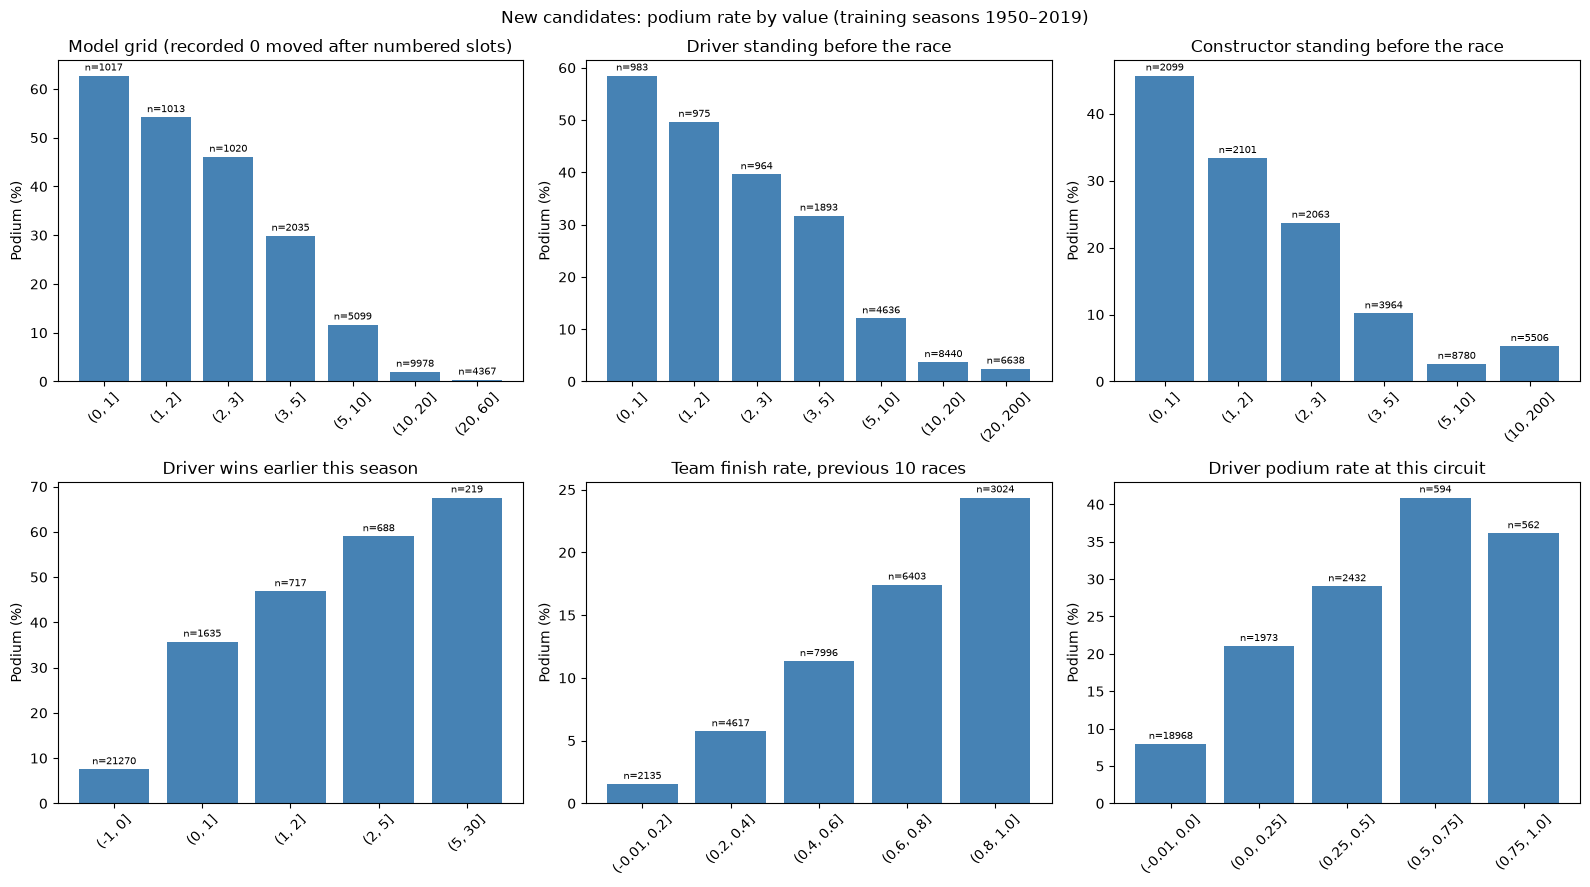

,Records,Podiums,Podium_rate
no_grid_slot,,,
0,22951,3074,0.1339
1,1578,0,0.0000


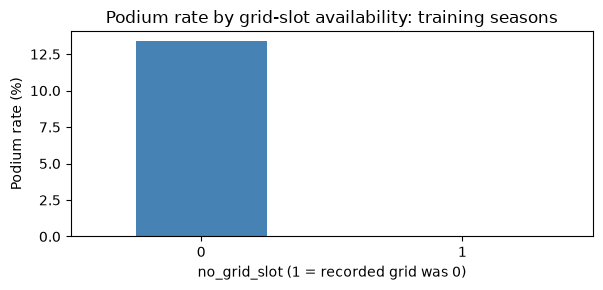

In [281]:
# Podium rate across the values of each new feature (training seasons only).
new_feature_plots = [
    ("grid", "Model grid (recorded 0 moved after numbered slots)", [0, 1, 2, 3, 5, 10, 20, 60]),
    ("driver_standing_before", "Driver standing before the race", [0, 1, 2, 3, 5, 10, 20, 200]),
    ("constructor_standing_before", "Constructor standing before the race", [0, 1, 2, 3, 5, 10, 200]),
    ("driver_wins_before", "Driver wins earlier this season", [-1, 0, 1, 2, 5, 30]),
    ("constructor_finish_rate_last10", "Team finish rate, previous 10 races", [-0.01, 0.2, 0.4, 0.6, 0.8, 1]),
    ("driver_circuit_podium_rate", "Driver podium rate at this circuit", [-0.01, 0, 0.25, 0.5, 0.75, 1]),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
train_view = feature_candidates.loc[training_years]
for ax, (column, title, bins) in zip(axes.flat, new_feature_plots):
    observed = train_view[[column, "podium"]].dropna()
    grouped = observed.groupby(pd.cut(observed[column], bins=bins), observed=True)["podium"].agg(["size", "mean"])
    bars = ax.bar(grouped.index.astype(str), grouped["mean"] * 100, color="steelblue")
    ax.bar_label(bars, labels=[f"n={n}" for n in grouped["size"]], fontsize=7, padding=2)
    ax.set_title(title)
    ax.set_ylabel("Podium (%)")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("New candidates: podium rate by value (training seasons 1950–2019)")
plt.tight_layout(); plt.show()

# Evidence for the no-grid-slot input, using training seasons only.
no_grid_evidence = train_view.groupby("no_grid_slot")["podium"].agg(Records="size", Podiums="sum", Podium_rate="mean")
display(no_grid_evidence.round(4))
ax = (no_grid_evidence["Podium_rate"] * 100).plot.bar(rot=0, color="steelblue", figsize=(6, 3))
ax.set_xlabel("no_grid_slot (1 = recorded grid was 0)")
ax.set_ylabel("Podium rate (%)")
ax.set_title("Podium rate by grid-slot availability: training seasons")
plt.tight_layout(); plt.show()

# 6. Modelling table, split and feature experiments

Uses `feature_candidates` from section 5. One row = one driver-race; target `podium` = 1 if finishing position is 1-3.
Only information known **before the race starts** is used as input.

## 6.1 Build the modelling table

Use ten starting numeric inputs: the nine examined in section 5.8, with `grid` adjusted as documented in section 5.9, plus `no_grid_slot`. The original recorded grid remains in `results_clean`. `model_df` holds the driver–race rows, target and starting inputs; later versions draw additional named inputs from `feature_candidates` on those same rows. Grid has no missing values; ambiguous constructor information still needs preprocessing decisions.


In [282]:
numeric_features = [
    "grid", "no_grid_slot", "driver_age", "driver_prior_appearances",
    "driver_podium_last5", "constructor_prior_recorded_races", "constructor_podium_last5",
    "driver_gp_points_before", "is_home",
     'year'
]
target = "podium"

model_df = feature_candidates[["raceId", "driverId", "date"] + numeric_features + [target]].copy()

# Use the adjusted modeling grid and the recorded-zero indicator.
feature_cols = numeric_features.copy()
assert len(feature_cols) == 10 and {"grid", "no_grid_slot"}.issubset(feature_cols)
assert model_df["grid"].notna().all()

# Safety checks: no current-race outcome in the inputs
forbidden = {"podium", "positionOrder", "points", "laps", "statusId", "original_entries", "constructor_choices"}
assert not forbidden.intersection(feature_cols)

print("Modelling table:", model_df.shape)
print("Podium rate:", round(model_df[target].mean(), 4))
display(model_df[feature_cols].isna().sum().rename("Missing rows").to_frame().query("`Missing rows` > 0"))

Modelling table: (26668, 14)
Podium rate: 0.1273


,Missing rows
constructor_prior_recorded_races,16
constructor_podium_last5,16


## 6.2 Train / validation / test split

We use **training 1950–2019, validation 2020–2021, and testing 2022–2024** (through the last available season). This follows the boundaries listed under “Season” on page 4 of the supplied Formula 1 introduction.

This order matches predicting later races from earlier information, keeps complete races/seasons together and retains the older years in training. The 2022 test boundary also evaluates transfer into the newer technical era described in the introduction; that can make the test harder and does not establish that these dates maximize performance.

Use validation for model, feature, preprocessing and threshold comparisons. Reserve test scores for final evaluation. Earlier section-5 outcome plots included all years, so this test period has already appeared in descriptive exploration; do not describe the complete workflow as having a test set untouched by exploration. No new test evaluation is performed when constructing this split.


In [283]:
train_mask = model_df["year"] <= 2019
val_mask   = model_df["year"].between(2020, 2021)
test_mask  = model_df["year"] >= 2022

X_train, y_train = model_df.loc[train_mask, feature_cols], model_df.loc[train_mask, target]
X_val,   y_val   = model_df.loc[val_mask,   feature_cols], model_df.loc[val_mask,   target]
X_test,  y_test  = model_df.loc[test_mask,  feature_cols], model_df.loc[test_mask,  target]

for name, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:5s} rows={len(X):6d}  podium rate={y.mean():.3f}")
assert model_df["year"].notna().all()
assert ((train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int)) == 1).all()
train_races = set(model_df.loc[train_mask, "raceId"])
val_races = set(model_df.loc[val_mask, "raceId"])
test_races = set(model_df.loc[test_mask, "raceId"])
assert train_races.isdisjoint(val_races) and train_races.isdisjoint(test_races) and val_races.isdisjoint(test_races)
assert model_df.loc[train_mask, "date"].max() < model_df.loc[val_mask, "date"].min()
assert model_df.loc[val_mask, "date"].max() < model_df.loc[test_mask, "date"].min()
print("Verified: every row belongs to one set; no race crosses sets; dates follow time order.")


Train rows= 24529  podium rate=0.125
Val   rows=   780  podium rate=0.150
Test  rows=  1359  podium rate=0.150
Verified: every row belongs to one set; no race crosses sets; dates follow time order.


## 6.3 Fill missing values and apply `StandardScaler`

Both the median imputer and the scaler are **fitted on the training set only**, then applied to validation and test, so nothing from later seasons leaks in.

In [284]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

X_train_s = scaler.fit_transform(imputer.fit_transform(X_train))
X_val_s   = scaler.transform(imputer.transform(X_val))
X_test_s  = scaler.transform(imputer.transform(X_test))

print("Train mean (should be ~0):", np.round(X_train_s.mean(), 4))
print("Train std  (should be ~1):", np.round(X_train_s.std(), 4))
print("NaNs left:", int(np.isnan(X_train_s).sum() + np.isnan(X_val_s).sum() + np.isnan(X_test_s).sum()))

Train mean (should be ~0): -0.0
Train std  (should be ~1): 1.0
NaNs left: 0


## 6.4 Modelling-table experiments: which features help?

We test the ten starting inputs (`feature_cols`) and later candidates **one change at a time**. E1 deliberately uses recorded grid values as a comparison; E2 uses the adjusted modeling grid with the same ten feature names. E3 then adds standings. This isolates the grid adjustment while keeping the rows and model fixed.

**How every experiment is measured, so only the table changes:**
- The same model each time: a random forest with fixed settings (300 trees, `max_depth=16`, `min_samples_leaf=30`, `max_features=0.6`). This is a fixed, regularised configuration (leaves of at least 30 rows) of the kind that tuning in section 8.3 favours; tuning is not repeated here, so only the table changes.
- Missing values: median imputer fitted on the training rows of that experiment only.
- **Two checks, both before the test seasons:**
  - **Validation:** train 1950–2019, score 2020–2021.
  - **Earlier check:** train 1950–2017, score 2018–2019. A two-season validation set is small (780 rows), so a change should help on both checks before we trust it.
- Each check is repeated with **three random seeds**; the log shows the mean and the spread.
- **Main score: PR-AUC** (see section 8). ROC-AUC is shown as a second view.

The test seasons (2022–2024) are not used anywhere in these experiments.

In [285]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

experiment_rf_settings = dict(n_estimators=300, max_depth=16, min_samples_leaf=30, max_features=0.6, n_jobs=-1)
experiment_checks = {
    "Val 2020-21": (model_df["year"] <= 2019, model_df["year"].between(2020, 2021)),
    "Check 2018-19": (model_df["year"] <= 2017, model_df["year"].between(2018, 2019)),
}
experiment_seeds = [0, 1, 2]
experiment_log = []

def run_feature_experiment(name, features, change, use_recorded_grid=False):
    # Train and score one version of the modelling table; never touches the test seasons.
    table = feature_candidates.loc[model_df.index, features].copy()
    if use_recorded_grid:
        assert "grid" in features
        pair_keys = pd.MultiIndex.from_frame(feature_candidates.loc[model_df.index, ["raceId", "driverId"]])
        table["grid"] = results_clean.set_index(["raceId", "driverId"])["grid"].reindex(pair_keys).to_numpy()
        assert table["grid"].notna().all()
    row = {"Experiment": name, "Change": change, "Features": len(features)}
    for check, (fit_rows, score_rows) in experiment_checks.items():
        filler = SimpleImputer(strategy="median").fit(table.loc[fit_rows])
        X_fit, X_score = filler.transform(table.loc[fit_rows]), filler.transform(table.loc[score_rows])
        y_fit, y_score = model_df.loc[fit_rows, target], model_df.loc[score_rows, target]
        pr_scores, roc_scores = [], []
        for seed in experiment_seeds:
            forest = RandomForestClassifier(**experiment_rf_settings, random_state=seed).fit(X_fit, y_fit)
            prob = forest.predict_proba(X_score)[:, 1]
            pr_scores.append(average_precision_score(y_score, prob))
            roc_scores.append(roc_auc_score(y_score, prob))
        row[f"{check} PR-AUC"] = np.mean(pr_scores)
        row[f"{check} PR-AUC spread"] = np.std(pr_scores)
        row[f"{check} ROC-AUC"] = np.mean(roc_scores)
    experiment_log.append(row)
    return features

baseline_features = list(feature_cols)
print("Starting inputs:", baseline_features)

Starting inputs: ['grid', 'no_grid_slot', 'driver_age', 'driver_prior_appearances', 'driver_podium_last5', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'driver_gp_points_before', 'is_home', 'year']


In [286]:
# E1: same ten feature names, using the original recorded grid as a comparison.
features_e1 = run_feature_experiment("E1", baseline_features, "Recorded grid + no-grid-slot flag", use_recorded_grid=True)

# E2: same ten names and rows, with grid zero moved after numbered slots.
features_e2 = run_feature_experiment("E2", list(features_e1), "Adjust grid zero after numbered slots")

# E3: add championship standings before the race.
features_e3 = run_feature_experiment(
    "E3", features_e2 + ["driver_standing_before", "constructor_standing_before", "driver_unranked", "constructor_unranked"],
    "+ driver and constructor standing before the race")

# E4: add wins earlier in the season.
features_e4 = run_feature_experiment("E4", features_e3 + ["driver_wins_before"], "+ driver wins earlier this season")

# E5: add team reliability.
features_e5 = run_feature_experiment("E5", features_e4 + ["constructor_finish_rate_last10"], "+ team finish rate, previous 10 races")

# E6: add the driver's history at this circuit.
features_e6 = run_feature_experiment(
    "E6", features_e5 + ["driver_circuit_visits_before", "driver_circuit_podium_rate"], "+ driver history at this circuit")

# E7: remove inputs with almost no association and the points total that standings now cover.
features_e7 = run_feature_experiment(
    "E7", [c for c in features_e6 if c not in {"year", "is_home", "driver_gp_points_before"}],
    "- year, is_home, driver_gp_points_before")

# E8: 10-race form windows instead of 5-race windows.
features_e8 = run_feature_experiment(
    "E8", [{"driver_podium_last5": "driver_podium_last10", "constructor_podium_last5": "constructor_podium_last10"}.get(c, c)
           for c in features_e7], "Form over 10 races instead of 5")

feature_experiment_results = pd.DataFrame(experiment_log).set_index("Experiment")
for check in experiment_checks:
    feature_experiment_results[f"{check} change vs previous"] = feature_experiment_results[f"{check} PR-AUC"].diff()
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(feature_experiment_results.round(4))

,Change,Features,Val 2020-21 PR-AUC,Val 2020-21 PR-AUC spread,Val 2020-21 ROC-AUC,Check 2018-19 PR-AUC,Check 2018-19 PR-AUC spread,Check 2018-19 ROC-AUC,Val 2020-21 change vs previous,Check 2018-19 change vs previous
Experiment,,,,,,,,,,
E1,Recorded grid + no-grid-slot flag,10,0.7014,0.0021,0.9249,0.7217,0.0012,0.9455,NaN,NaN
E2,Adjust grid zero after numbered slots,10,0.7095,0.0031,0.9272,0.7236,0.0033,0.9453,0.0080,0.0019
E3,+ driver and constructor standing before the race,14,0.7239,0.0038,0.9284,0.7318,0.0011,0.9453,0.0144,0.0082
E4,+ driver wins earlier this season,15,0.7297,0.0010,0.9287,0.7328,0.0023,0.9454,0.0058,0.0011
E5,"+ team finish rate, previous 10 races",16,0.7278,0.0061,0.9288,0.7345,0.0008,0.9460,-0.0019,0.0017
E6,+ driver history at this circuit,18,0.7276,0.0026,0.9289,0.7334,0.0017,0.9461,-0.0002,-0.0011
E7,"- year, is_home, driver_gp_points_before",15,0.7191,0.0034,0.9291,0.7312,0.0024,0.9466,-0.0085,-0.0022
E8,Form over 10 races instead of 5,15,0.7078,0.0040,0.9300,0.7303,0.0022,0.9478,-0.0112,-0.0009


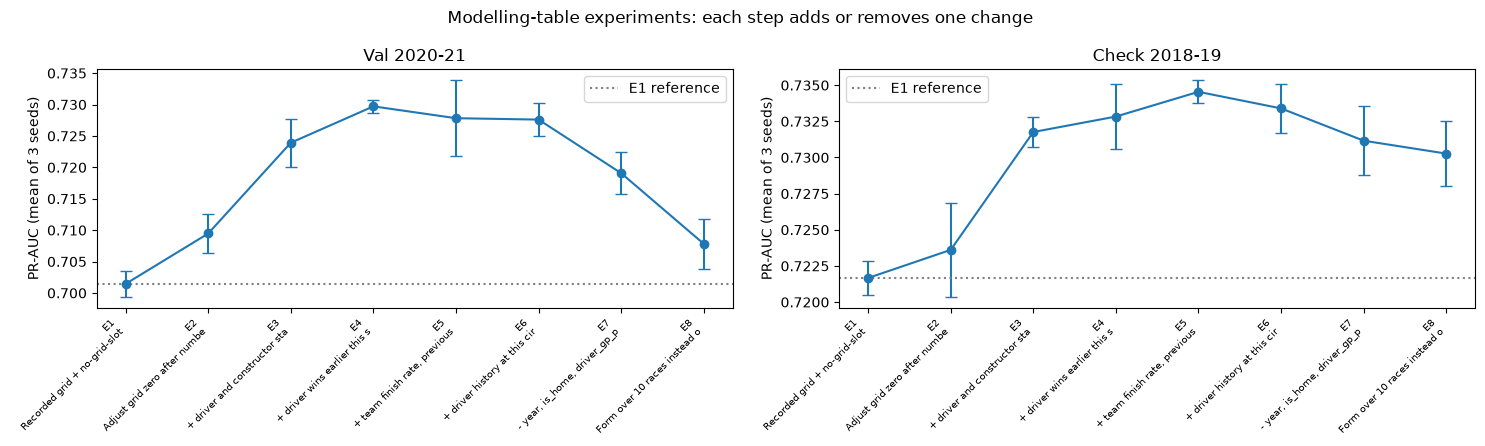

In [287]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
labels = [f"{idx}\n{change[:28]}" for idx, change in zip(feature_experiment_results.index, feature_experiment_results["Change"])]
for ax, check in zip(axes, experiment_checks):
    means = feature_experiment_results[f"{check} PR-AUC"]
    spreads = feature_experiment_results[f"{check} PR-AUC spread"]
    ax.errorbar(range(len(means)), means, yerr=spreads, marker="o", capsize=4)
    ax.axhline(means.iloc[0], color="grey", linestyle=":", label="E1 reference")
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels(labels, fontsize=7, rotation=45, ha="right")
    ax.set_ylabel("PR-AUC (mean of 3 seeds)")
    ax.set_title(check)
    ax.legend()
fig.suptitle("Modelling-table experiments: each step adds or removes one change")
plt.tight_layout(); plt.show()

## 6.5 Which single features matter: permutation importance

The experiment log shows the effect of each **change**. Permutation importance shows how much the model relies on each **single feature** in the fullest table (E6). For one feature at a time, we shuffle its values in the validation rows and measure the drop in PR-AUC; repeating the shuffle 20 times gives the error bars.

- A large drop means the model relies on the feature.
- A drop near zero means the model can do without it; a negative value means shuffling it slightly helped.

Importance is measured on validation (2020–2021), not on training data and not on test. It describes what this model relies on, not what causes podiums.

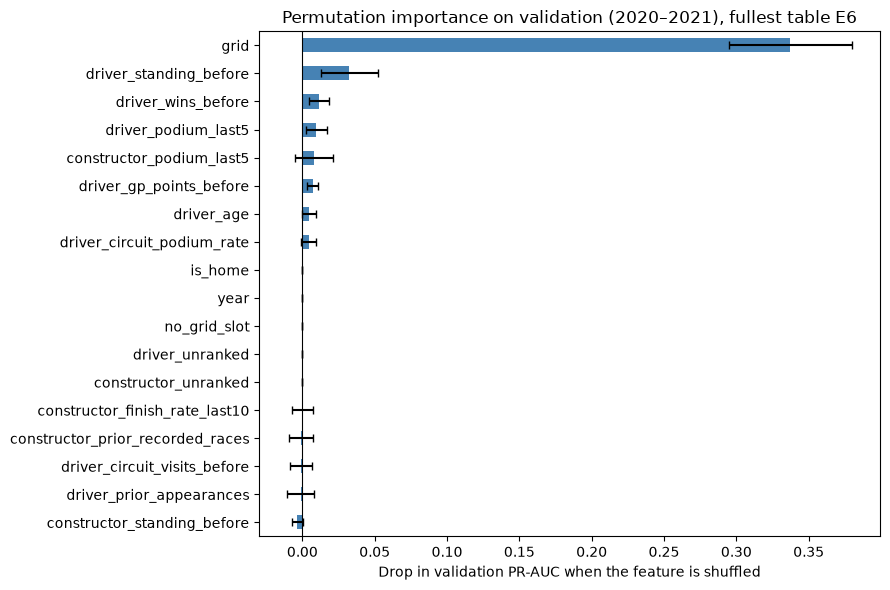

,PR-AUC drop when shuffled,Spread
grid,0.3372,0.0426
driver_standing_before,0.0323,0.0198
driver_wins_before,0.0115,0.0070
driver_podium_last5,0.0096,0.0074
constructor_podium_last5,0.0079,0.0129
driver_gp_points_before,0.0072,0.0037
driver_age,0.0045,0.0047
driver_circuit_podium_rate,0.0044,0.0053
is_home,0.0000,0.0000
year,0.0000,0.0000


In [288]:
from sklearn.inspection import permutation_importance

importance_filler = SimpleImputer(strategy="median").fit(feature_candidates.loc[model_df.index[train_mask], features_e6])
importance_X_train = importance_filler.transform(feature_candidates.loc[model_df.index[train_mask], features_e6])
importance_X_val = importance_filler.transform(feature_candidates.loc[model_df.index[val_mask], features_e6])
importance_forest = RandomForestClassifier(**experiment_rf_settings, random_state=42).fit(importance_X_train, y_train)
permutation = permutation_importance(importance_forest, importance_X_val, y_val, scoring="average_precision",
                                     n_repeats=20, random_state=42, n_jobs=-1)
feature_importance_table = pd.DataFrame({
    "PR-AUC drop when shuffled": permutation.importances_mean,
    "Spread": permutation.importances_std}, index=features_e6).sort_values("PR-AUC drop when shuffled")
ax = feature_importance_table["PR-AUC drop when shuffled"].plot.barh(
    xerr=feature_importance_table["Spread"], figsize=(9, 6), color="steelblue", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop in validation PR-AUC when the feature is shuffled")
ax.set_title("Permutation importance on validation (2020–2021), fullest table E6")
plt.tight_layout(); plt.show()
display(feature_importance_table.sort_values("PR-AUC drop when shuffled", ascending=False).round(4))

## 6.6 Confirm a removal and choose the feature set

Permutation importance gave `year` and `is_home` exactly zero. That does **not** prove they are useless: every validation row is from 2020–2021, later than any training year, so shuffling `year` *within* validation swaps 2020 and 2021, which the forest treats identically. The only fair test is to remove them and retrain, so experiment E9 removes both from E3.

**Decision rule, written before reading E9:**
- A change counts only if it moves the **average PR-AUC of the two checks** by more than **0.003**, which is about the spread between random seeds.
- Smaller changes count as "no difference"; then we prefer the **simpler table** (fewer features).
- Test seasons are not used.

In [289]:
features_e9 = run_feature_experiment("E9", [c for c in features_e3 if c not in {"year", "is_home"}], "E3 - year, is_home")

feature_experiment_results = pd.DataFrame(experiment_log).set_index("Experiment")
feature_experiment_results["Average PR-AUC (both checks)"] = feature_experiment_results[
    ["Val 2020-21 PR-AUC", "Check 2018-19 PR-AUC"]].mean(axis=1)
compared_with = {"E2": "E1", "E3": "E2", "E4": "E3", "E5": "E4", "E6": "E5", "E7": "E6", "E8": "E7", "E9": "E3"}
decision_rows = []
for experiment, reference in compared_with.items():
    change = (feature_experiment_results.loc[experiment, "Average PR-AUC (both checks)"]
              - feature_experiment_results.loc[reference, "Average PR-AUC (both checks)"])
    verdict = "Helps" if change > 0.003 else ("Hurts" if change < -0.003 else "No real difference")
    decision_rows.append({"Experiment": experiment, "Compared with": reference,
                          "Change": feature_experiment_results.loc[experiment, "Change"],
                          "Average PR-AUC change": change, "Verdict": verdict})
feature_decisions = pd.DataFrame(decision_rows).set_index("Experiment")
with pd.option_context("display.max_colwidth", None):
    display(feature_experiment_results[["Change", "Features", "Val 2020-21 PR-AUC", "Check 2018-19 PR-AUC",
                                        "Average PR-AUC (both checks)"]].round(4))
    display(feature_decisions.round(4))

selected_features = list(features_e3)
print("Selected feature set (E3):", len(selected_features), "features")
print(selected_features)
# Written results are generated from the same objects as the tables/plots.
from IPython.display import Markdown

def report_model_results(model_name, results, best_version, params=None, histories=None):
    display(Markdown(f"**{model_name}: current-run results**"))
    columns = ["Version", "Split", "Threshold", "ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]
    display(results[columns].round(4))
    validation = results.loc[results["Split"].eq("Val")].set_index("Version")
    testing = results.loc[results["Split"].eq("Test")].set_index("Version")
    selected_val, selected_test = validation.loc[best_version], testing.loc[best_version]
    spread = validation["PR-AUC"].max() - validation["PR-AUC"].min()
    display(Markdown(
        f"Selected using validation: **{best_version}**, with validation PR-AUC **{selected_val['PR-AUC']:.4f}** "
        f"and threshold **{selected_val['Threshold']:.2f}**. Its test PR-AUC is **{selected_test['PR-AUC']:.4f}**, "
        f"ROC-AUC **{selected_test['ROC-AUC']:.4f}**, and F1 **{selected_test['F1']:.4f}**. "
        f"The validation PR-AUC range across versions is **{spread:.4f}**. "
        "This observed range is not a statistical significance test."))
    comparisons = results.pivot(index="Version", columns="Split", values="PR-AUC")
    comparisons["Train minus validation"] = comparisons["Train"] - comparisons["Val"]
    comparisons["Validation minus test"] = comparisons["Val"] - comparisons["Test"]
    display(comparisons.round(4))
    display(Markdown("Positive train-minus-validation gaps indicate better training scores; era differences also affect these gaps. "
                     "Use the curves and split scores together rather than declaring overfitting from one number."))
    y = version_inputs[best_version]["y"]["Test"]
    prob = model_registry[model_name]["probs"][best_version]["Test"]
    predicted = prob >= selected_val["Threshold"]
    true_positive = int(((y == 1) & predicted).sum())
    false_positive = int(((y == 0) & predicted).sum())
    display(Markdown(f"At that threshold, the selected version identifies **{true_positive} of {int((y == 1).sum())}** "
                     f"test podiums and produces **{false_positive}** false positives. "
                     f"No-skill test PR-AUC is the podium proportion: **{y.mean():.4f}**."))
    if params is not None:
        display(pd.DataFrame.from_dict(params, orient="index").rename_axis("Version"))
    if histories is not None:
        epochs = {version: len(history.history["loss"]) for version, history in histories.items()}
        display(pd.Series(epochs, name="Epochs run").rename_axis("Version").to_frame())
        display(Markdown("Neural-network results can vary across runs, hardware and library versions. This text updates from the current run."))


,Change,Features,Val 2020-21 PR-AUC,Check 2018-19 PR-AUC,Average PR-AUC (both checks)
Experiment,,,,,
E1,Recorded grid + no-grid-slot flag,10,0.7014,0.7217,0.7116
E2,Adjust grid zero after numbered slots,10,0.7095,0.7236,0.7165
E3,+ driver and constructor standing before the race,14,0.7239,0.7318,0.7278
E4,+ driver wins earlier this season,15,0.7297,0.7328,0.7313
E5,"+ team finish rate, previous 10 races",16,0.7278,0.7345,0.7312
E6,+ driver history at this circuit,18,0.7276,0.7334,0.7305
E7,"- year, is_home, driver_gp_points_before",15,0.7191,0.7312,0.7251
E8,Form over 10 races instead of 5,15,0.7078,0.7303,0.7190
E9,"E3 - year, is_home",12,0.6899,0.7214,0.7057


,Compared with,Change,Average PR-AUC change,Verdict
Experiment,,,,
E2,E1,Adjust grid zero after numbered slots,0.0050,Helps
E3,E2,+ driver and constructor standing before the race,0.0113,Helps
E4,E3,+ driver wins earlier this season,0.0034,Helps
E5,E4,"+ team finish rate, previous 10 races",-0.0001,No real difference
E6,E5,+ driver history at this circuit,-0.0007,No real difference
E7,E6,"- year, is_home, driver_gp_points_before",-0.0054,Hurts
E8,E7,Form over 10 races instead of 5,-0.0061,Hurts
E9,E3,"E3 - year, is_home",-0.0222,Hurts


Selected feature set (E3): 14 features
['grid', 'no_grid_slot', 'driver_age', 'driver_prior_appearances', 'driver_podium_last5', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'driver_gp_points_before', 'is_home', 'year', 'driver_standing_before', 'constructor_standing_before', 'driver_unranked', 'constructor_unranked']


### Feature decision

The tables and explanation below are generated from the current run.


In [290]:
display(Markdown(f"**Selected feature configuration: E3 ({len(selected_features)} inputs).** This remains our documented choice; "
                 "the empirical scores below are regenerated on each run."))
display(feature_decisions.round(4))
for experiment in ["E1", "E3"]:
    scores = feature_experiment_results.loc[experiment]
    print(f"{experiment}: validation PR-AUC {scores['Val 2020-21 PR-AUC']:.4f}; "
          f"earlier-check PR-AUC {scores['Check 2018-19 PR-AUC']:.4f}; "
          f"average {scores['Average PR-AUC (both checks)']:.4f}")
print("Selected features:", selected_features)
print("Feature decisions use pre-test checks. Small changes do not establish statistical significance.")


**Selected feature configuration: E3 (14 inputs).** This remains our documented choice; the empirical scores below are regenerated on each run.

,Compared with,Change,Average PR-AUC change,Verdict
Experiment,,,,
E2,E1,Adjust grid zero after numbered slots,0.0050,Helps
E3,E2,+ driver and constructor standing before the race,0.0113,Helps
E4,E3,+ driver wins earlier this season,0.0034,Helps
E5,E4,"+ team finish rate, previous 10 races",-0.0001,No real difference
E6,E5,+ driver history at this circuit,-0.0007,No real difference
E7,E6,"- year, is_home, driver_gp_points_before",-0.0054,Hurts
E8,E7,Form over 10 races instead of 5,-0.0061,Hurts
E9,E3,"E3 - year, is_home",-0.0222,Hurts


E1: validation PR-AUC 0.7014; earlier-check PR-AUC 0.7217; average 0.7116
E3: validation PR-AUC 0.7239; earlier-check PR-AUC 0.7318; average 0.7278
Selected features: ['grid', 'no_grid_slot', 'driver_age', 'driver_prior_appearances', 'driver_podium_last5', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'driver_gp_points_before', 'is_home', 'year', 'driver_standing_before', 'constructor_standing_before', 'driver_unranked', 'constructor_unranked']
Feature decisions use pre-test checks. Small changes do not establish statistical significance.


## 6.7 Four training versions and shared evaluation helpers

Every model in sections 7–9 uses the **E3 feature table** chosen in section 6.6 (`selected_features`, 14 features) and is trained in four versions:

| Version | Training seasons | Features | Question it answers |
|---|---|---|---|
| **Baseline (1950+)** | 1950–2019 | E3 (14) | Reference: all history |
| **2003+** | 2003–2019 | E3 (14) | Do modern seasons alone train a better model? |
| **2003+ + q1** | 2003–2019 | E3 + `q1` (15) | Does the raw Q1 lap time add information? |
| **2003+ + q1 gap** | 2003–2019 | E3 + `q1_relative_gap` (15) | Does the Q1 time *relative to the fastest Q1 in that race* add information? |

Validation (2020–2021) and test (2022–2024) are **identical in every version**, so the versions are directly comparable.

**Why 2003.** From 2003 qualifying times exist for almost every driver, and seasons look more like the 2020–2024 seasons we predict (fields of about 20 cars, modern reliability). History features such as form and standings were built in section 5 from the full history, so a 2003 row still uses its driver's and team's earlier results.

**Why two qualifying versions.** `q1` is the lap time in seconds. Its size depends mostly on the length of the circuit (about 72 s at Monaco, about 105 s at Spa), so a raw time partly describes the track rather than the driver's pace. `q1_relative_gap` divides by the fastest Q1 time in the same race (0.01 = 1% slower than the fastest), which makes races comparable. Testing both shows which representation works. Qualifying is known before the race, so both are leakage-safe. Missing Q1 times (a driver who set no time) are filled with the training-set median, like every other missing input.

**Preprocessing for each version:** the median imputer is fitted on **that version's training rows only**; the neural network and logistic regression also use a `StandardScaler` fitted on the same rows. Trees use the imputed values directly.

**Selection rules (all models):** settings and the probability threshold are chosen on **validation**. The **primary metric is PR-AUC**: PR-AUC measures how well real podium finishers are ranked above everyone else (no-skill level = podium rate). **Secondary metrics:** ROC-AUC for overall separation and F1 at the validation-chosen threshold, because a final yes/no prediction needs a cut-off. Accuracy is shown but not used to choose: the always-no-podium baseline is computed from the current class proportions.

In [291]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, precision_recall_curve, roc_curve)

training_versions = {
    "Baseline (1950+)": {"first_year": 1950, "features": list(selected_features)},
    "2003+": {"first_year": 2003, "features": list(selected_features)},
    "2003+ + q1": {"first_year": 2003, "features": list(selected_features) + ["q1"]},
    "2003+ + q1 gap": {"first_year": 2003, "features": list(selected_features) + ["q1_relative_gap"]},
}
split_masks = {"Train": model_df["year"] <= 2019,
               "Val": model_df["year"].between(2020, 2021),
               "Test": model_df["year"] >= 2022}
SPLITS = ["Train", "Val", "Test"]

def build_version_inputs(version, features=None):
    # Inputs for one training version; preprocessing is fitted on that version's training rows only.
    spec = training_versions[version]
    features = list(spec["features"] if features is None else features)
    rows = {"Train": model_df.index[split_masks["Train"] & model_df["year"].ge(spec["first_year"])],
            "Val": model_df.index[split_masks["Val"]], "Test": model_df.index[split_masks["Test"]]}
    raw = {split: feature_candidates.loc[index, features] for split, index in rows.items()}
    imputer = SimpleImputer(strategy="median").fit(raw["Train"])
    X = {split: imputer.transform(table) for split, table in raw.items()}
    scaler = StandardScaler().fit(X["Train"])
    return {"version": version, "features": features, "rows": rows, "raw": raw, "X": X,
            "X_scaled": {split: scaler.transform(values) for split, values in X.items()},
            "y": {split: model_df.loc[index, target].to_numpy() for split, index in rows.items()},
            "imputer": imputer, "scaler": scaler}

version_inputs = {version: build_version_inputs(version) for version in training_versions}

version_summary = pd.DataFrame([{
    "Version": version,
    "Training seasons": f"{training_versions[version]['first_year']}-2019",
    "Features": len(inputs["features"]),
    "Train rows": len(inputs["y"]["Train"]),
    "Train podium rate": inputs["y"]["Train"].mean(),
    "Val rows": len(inputs["y"]["Val"]), "Test rows": len(inputs["y"]["Test"]),
    "Q1 missing in train (%)": (inputs["raw"]["Train"].iloc[:, -1].isna().mean() * 100
                                if inputs["features"][-1].startswith("q1") else np.nan)}
    for version, inputs in version_inputs.items()]).set_index("Version")
display(version_summary.round(3))
assert all(np.array_equal(version_inputs[v]["y"]["Test"], version_inputs["Baseline (1950+)"]["y"]["Test"]) for v in version_inputs)
assert all(np.array_equal(version_inputs[v]["y"]["Val"], version_inputs["Baseline (1950+)"]["y"]["Val"]) for v in version_inputs)

,Training seasons,Features,Train rows,Train podium rate,Val rows,Test rows,Q1 missing in train (%)
Version,,,,,,,
Baseline (1950+),1950-2019,14,24529,0.125,780,1359,NaN
2003+,2003-2019,14,6831,0.141,780,1359,NaN
2003+ + q1,2003-2019,15,6831,0.141,780,1359,1.845
2003+ + q1 gap,2003-2019,15,6831,0.141,780,1359,1.845


In [292]:
def podium_metrics(y_true, prob, threshold):
    # All metrics used to compare models, for one split.
    pred = (prob >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob),
            "F1": f1_score(y_true, pred, zero_division=0), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "Accuracy": accuracy_score(y_true, pred)}

def choose_threshold(y_val, prob_val):
    # Threshold with the best validation F1; test data is never used.
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
    scores = [f1_score(y_val, (prob_val >= t).astype(int), zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(scores))]), pd.Series(scores, index=thresholds)

def compare_versions(model_name, version_probs, thresholds):
    # Results table and plots for one model across the training versions.
    rows = []
    for version, probs in version_probs.items():
        y = version_inputs[version]["y"]
        for split in SPLITS:
            rows.append({"Model": model_name, "Version": version, "Split": split,
                         "Threshold": thresholds[version], **podium_metrics(y[split], probs[split], thresholds[version])})
    table = pd.DataFrame(rows)
    with pd.option_context("display.width", 220):
        display(table.round(4))

    order = list(version_probs)
    y_test = version_inputs[order[0]]["y"]["Test"]
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
    pr_table = table.pivot(index="Version", columns="Split", values="PR-AUC").loc[order, SPLITS]
    pr_table.plot.bar(ax=axes[0], rot=10)
    axes[0].axhline(y_test.mean(), color="grey", linestyle=":", label="No-skill (test podium rate)")
    axes[0].set_ylabel("PR-AUC"); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)
    axes[0].set_title(f"{model_name}: PR-AUC by version and split")
    for version in order:
        fpr, tpr, _ = roc_curve(y_test, version_probs[version]["Test"])
        axes[1].plot(fpr, tpr, label=f"{version} ({roc_auc_score(y_test, version_probs[version]['Test']):.3f})")
        precision, recall, _ = precision_recall_curve(y_test, version_probs[version]["Test"])
        axes[2].plot(recall, precision, label=f"{version} ({average_precision_score(y_test, version_probs[version]['Test']):.3f})")
    axes[1].plot([0, 1], [0, 1], "k:"); axes[1].set_title("ROC curves on test (2022-2024)")
    axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
    axes[2].axhline(y_test.mean(), color="grey", linestyle=":")
    axes[2].set_title("Precision-recall curves on test"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
    for ax in axes[1:]:
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    best_version = table[table["Split"].eq("Val")].sort_values(["PR-AUC", "ROC-AUC"], ascending=False).iloc[0]["Version"]
    pred = (version_probs[best_version]["Test"] >= thresholds[best_version]).astype(int)
    matrix = pd.DataFrame(confusion_matrix(y_test, pred), index=["Actual no podium", "Actual podium"],
                          columns=["Predicted no podium", "Predicted podium"])
    print(f"Best version on validation PR-AUC: {best_version}. Its test confusion matrix:")
    display(matrix)
    return table, best_version

# Each model section registers how to predict and refit, for the comparison and XAI in section 10.
model_registry = {}
print("Helpers ready.")

Helpers ready.


## 6.8 Effect of each preprocessing step on the data

We inspect the final pipeline (`build_version_inputs`, section 6.7) on the
**Baseline (1950+)** version with the 14 selected features: median imputation, standard scaling,
and the range of engineered features. We also inspect skew and encoding choices; neither is a transform in the final pipeline. Each applied step has a before/after table or plot.
Nothing in this section changes `version_inputs`; it only inspects it.


In [293]:
from scipy.stats import skew

base = version_inputs["Baseline (1950+)"]
feats = base["features"]
idx = {f: i for i, f in enumerate(feats)}

print("Features:", len(feats))
print({s: base["raw"][s].shape for s in SPLITS})


Features: 14
{'Train': (24529, 14), 'Val': (780, 14), 'Test': (1359, 14)}


### 6.8.1 Imputation (median, fitted on training rows only)

**Before:** raw feature values with NaNs. **After:** NaNs replaced by the *training* median.
The table shows how many values were missing in each split and what they were filled with.
A feature with no missing values is not changed by this step.


In [294]:
miss = pd.DataFrame({f"{s} missing": base["raw"][s].isna().sum() for s in SPLITS})
miss["Train missing (%)"] = base["raw"]["Train"].isna().mean() * 100
miss["Fill value (train median)"] = pd.Series(base["imputer"].statistics_, index=feats)
display(miss.round(3))

has_missing = miss.index[(miss[[f"{s} missing" for s in SPLITS]].sum(axis=1) > 0)].tolist()
print("Features with any missing value:", has_missing if has_missing else "none")


,Train missing,Val missing,Test missing,Train missing (%),Fill value (train median)
grid,0,0,0,0.000,13.000
no_grid_slot,0,0,0,0.000,0.000
driver_age,0,0,0,0.000,29.583
driver_prior_appearances,0,0,0,0.000,39.000
driver_podium_last5,0,0,0,0.000,0.000
constructor_prior_recorded_races,16,0,0,0.065,85.000
constructor_podium_last5,16,0,0,0.065,0.000
driver_gp_points_before,0,0,0,0.000,1.000
is_home,0,0,0,0.000,0.000
year,0,0,0,0.000,1989.000


Features with any missing value: ['constructor_prior_recorded_races', 'constructor_podium_last5', 'constructor_standing_before', 'constructor_unranked']


,Mean before,Mean after,Std before,Std after,Min before,Min after,Max before,Max after
Feature,,,,,,,,
constructor_prior_recorded_races,165.319,165.267,199.177,199.122,0.0,0.0,992.0,992.0
constructor_podium_last5,0.127,0.127,0.195,0.195,0.0,0.0,1.0,1.0
constructor_standing_before,7.852,7.852,6.366,6.364,1.0,1.0,42.0,42.0
constructor_unranked,0.088,0.088,0.283,0.283,0.0,0.0,1.0,1.0


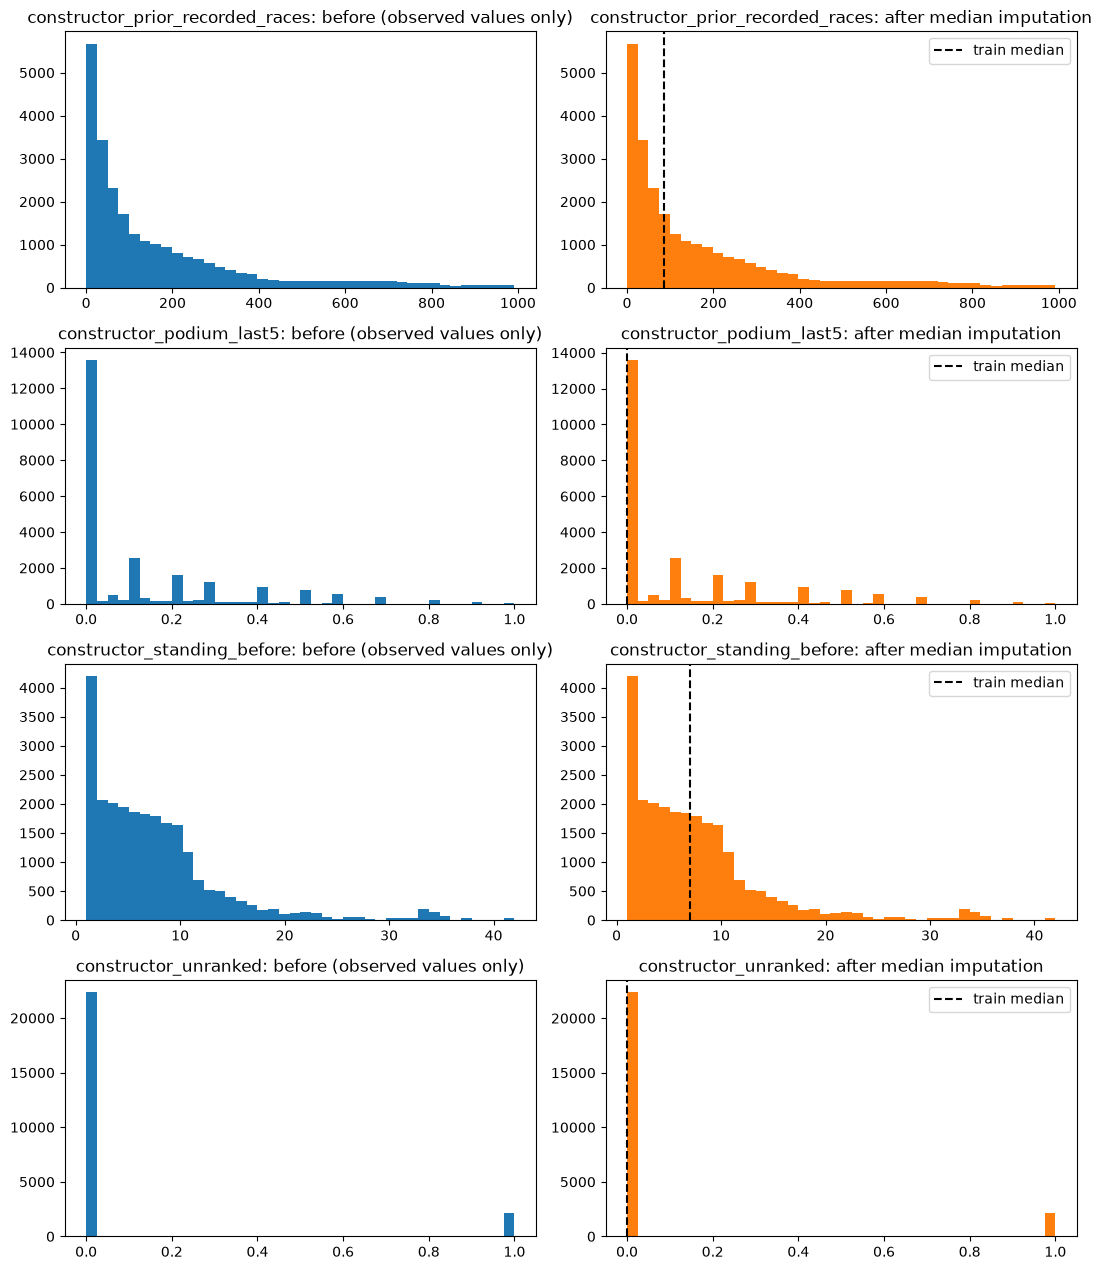

In [295]:
# Before/after statistics for the features that had missing values (training rows).
if has_missing:
    rows = []
    for f in has_missing:
        before = base["raw"]["Train"][f]
        after = pd.Series(base["X"]["Train"][:, idx[f]])
        rows.append({"Feature": f,
                     "Mean before": before.mean(), "Mean after": after.mean(),
                     "Std before": before.std(), "Std after": after.std(),
                     "Min before": before.min(), "Min after": after.min(),
                     "Max before": before.max(), "Max after": after.max()})
    display(pd.DataFrame(rows).set_index("Feature").round(3))

    fig, axes = plt.subplots(len(has_missing), 2, figsize=(11, 3.2 * len(has_missing)), squeeze=False)
    for r, f in enumerate(has_missing):
        before = base["raw"]["Train"][f].dropna()
        after = base["X"]["Train"][:, idx[f]]
        axes[r, 0].hist(before, bins=40, color="tab:blue")
        axes[r, 0].set_title(f"{f}: before (observed values only)")
        axes[r, 1].hist(after, bins=40, color="tab:orange")
        axes[r, 1].axvline(base["imputer"].statistics_[idx[f]], color="black", linestyle="--", label="train median")
        axes[r, 1].set_title(f"{f}: after median imputation")
        axes[r, 1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in the 14 selected features: imputation leaves every value unchanged.")


In [296]:
# Proof that imputation changed only the missing cells.
for s in SPLITS:
    raw_values = base["raw"][s].to_numpy(dtype=float)
    observed = ~np.isnan(raw_values)
    assert np.array_equal(raw_values[observed], base["X"][s][observed]), f"{s}: observed values were altered"
    assert not np.isnan(base["X"][s]).any(), f"{s}: NaNs remain"
print("Verified: observed values unchanged, no NaNs left in any split.")


Verified: observed values unchanged, no NaNs left in any split.


### 6.8.2 Scaling (`StandardScaler`, fitted on training rows only)

**Before:** imputed values in original units. **After:** (x - train mean) / train std.
On the training set every non-constant feature should end with mean 0 and std 1.
Validation and test will **not** be exactly 0 and 1, because the scaler never saw them. The size of that
gap measures how far later seasons drift from the training period (era shift), not an error.


In [297]:
def summary_stats(array):
    return pd.DataFrame(array, columns=feats).agg(["min", "max", "mean", "std"]).T

before_stats = summary_stats(base["X"]["Train"])
after_stats = summary_stats(base["X_scaled"]["Train"])
display(pd.concat({"Train before scaling": before_stats, "Train after scaling": after_stats}, axis=1).round(3))

# Training mean/std check (the scaler uses population std, ddof=0).
train_scaled = base["X_scaled"]["Train"]
nonconstant = train_scaled.std(axis=0) > 0
assert np.allclose(train_scaled.mean(axis=0)[nonconstant], 0, atol=1e-6)
assert np.allclose(train_scaled.std(axis=0, ddof=0)[nonconstant], 1, atol=1e-6)
print("Verified: every non-constant training feature has mean 0 and std 1.")
print("Constant training features (std = 0):", [f for f, c in zip(feats, nonconstant) if not c] or "none")


Train before scaling                              Train after scaling                  
                                                  min       max      mean      std                 min     max mean  std
grid                                            1.000    34.000    12.847    7.439              -1.593   2.844  0.0  1.0
no_grid_slot                                    0.000     1.000     0.064    0.245              -0.262   3.814  0.0  1.0
driver_age                                     17.454    58.788    30.113    5.206              -2.432   5.508 -0.0  1.0
driver_prior_appearances                        0.000   325.000    59.823   61.231              -0.977   4.331  0.0  1.0
driver_podium_last5                             0.000     1.000     0.124    0.226              -0.547   3.878 -0.0  1.0
constructor_prior_recorded_races                0.000   992.000   165.267  199.122              -0.830   4.152  0.0  1.0
constructor_podium_last5                        0.000     1.000     0.127    0.195              -0.650   4.471 -0.0  1.0
driver_gp_points_before                         0.000   387.000    13.559   33.540              -0.404  11.134 -0.0  1.0
is_home                                         0.000     1.000     0.099    0.298              -0.331   3.023  0.0  1.0
year                                         1950.000  2019.000  1988.849   18.448              -2.106   1.634 -0.0  1.0
driver_standing_before                          1.000   103.000    15.624   11.834              -1.236   7.384  0.0  1.0
constructor_standing_before                     1.000    42.000     7.852    6.364              -1.077   5.366  0.0  1.0
driver_unranked                                 0.000     1.000     0.091    0.287              -0.316   3.162 -0.0  1.0
constructor_unranked                            0.000     1.000     0.088    0.283              -0.310   3.222  0.0  1.0

Verified: every non-constant training feature has mean 0 and std 1.
Constant training features (std = 0): none


,Val mean,Test mean,Val std,Test std
grid,-0.307,-0.313,0.784,0.776
no_grid_slot,-0.173,-0.142,0.595,0.689
driver_age,-0.431,-0.250,1.094,1.060
driver_prior_appearances,1.001,1.413,1.583,1.586
driver_podium_last5,0.114,0.119,1.148,1.143
constructor_prior_recorded_races,0.986,1.175,1.771,1.825
constructor_podium_last5,0.093,0.119,1.174,1.171
driver_gp_points_before,0.985,1.240,1.925,2.391
is_home,-0.219,-0.227,0.602,0.580
year,1.719,1.853,0.027,0.045


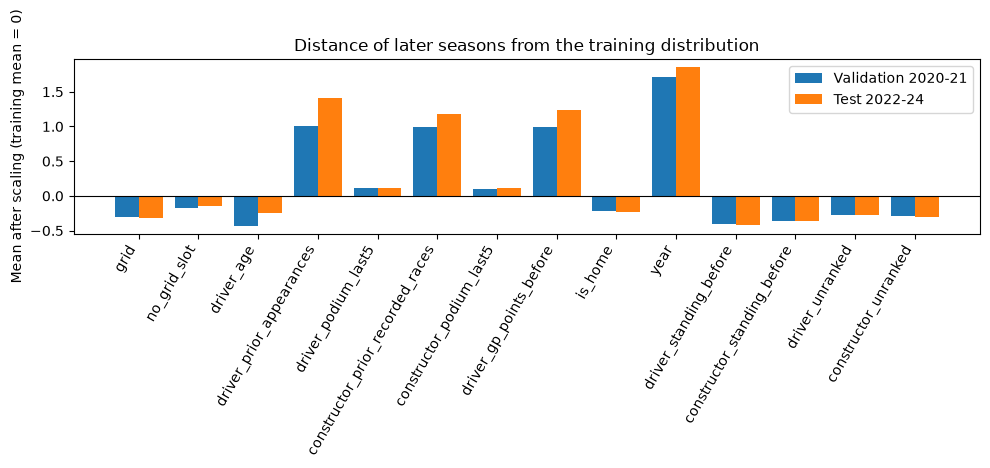

In [298]:
# Drift: how far validation and test are from the training distribution after scaling.
drift = pd.DataFrame({
    "Val mean": base["X_scaled"]["Val"].mean(axis=0),
    "Test mean": base["X_scaled"]["Test"].mean(axis=0),
    "Val std": base["X_scaled"]["Val"].std(axis=0, ddof=0),
    "Test std": base["X_scaled"]["Test"].std(axis=0, ddof=0)}, index=feats)
display(drift.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
positions = np.arange(len(feats))
ax.bar(positions - 0.2, drift["Val mean"], width=0.4, label="Validation 2020-21")
ax.bar(positions + 0.2, drift["Test mean"], width=0.4, label="Test 2022-24")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions)
ax.set_xticklabels(feats, rotation=60, ha="right")
ax.set_ylabel("Mean after scaling (training mean = 0)")
ax.set_title("Distance of later seasons from the training distribution")
ax.legend()
plt.tight_layout()
plt.show()


### 6.8.3 Skewness

Strongly skewed features (|skew| > 1) can dominate scale-sensitive models. We measure skew on the imputed
training values, and test `log1p` (stateless, so it cannot leak) on the non-negative skewed features.
This table is **informative only**: it does not change the modelling inputs.
Tree models are unaffected by monotonic transforms; logistic regression and the neural network could be.


In [299]:
imputed_train = pd.DataFrame(base["X"]["Train"], columns=feats)
skew_table = pd.DataFrame({
    "Skewness": imputed_train.apply(lambda c: skew(c, nan_policy="omit")),
    "Min": imputed_train.min(),
    "Max": imputed_train.max()})
skew_table["Skewed (|skew| > 1)"] = skew_table["Skewness"].abs() > 1
skew_table["log1p possible (min >= 0)"] = skew_table["Min"] >= 0
display(skew_table.round(3))

skewed = skew_table.index[skew_table["Skewed (|skew| > 1)"] & skew_table["log1p possible (min >= 0)"]].tolist()
print("Skewed features that log1p could be applied to:", skewed if skewed else "none")


,Skewness,Min,Max,Skewed (|skew| > 1),log1p possible (min >= 0)
grid,0.200,1.000,34.000,False,True
no_grid_slot,3.551,0.000,1.000,True,True
driver_age,0.658,17.454,58.788,False,True
driver_prior_appearances,1.451,0.000,325.000,True,True
driver_podium_last5,1.944,0.000,1.000,True,True
constructor_prior_recorded_races,1.834,0.000,992.000,True,True
constructor_podium_last5,1.732,0.000,1.000,True,True
driver_gp_points_before,4.972,0.000,387.000,True,True
is_home,2.692,0.000,1.000,True,True
year,-0.211,1950.000,2019.000,False,True


Skewed features that log1p could be applied to: ['no_grid_slot', 'driver_prior_appearances', 'driver_podium_last5', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'driver_gp_points_before', 'is_home', 'driver_standing_before', 'constructor_standing_before', 'driver_unranked', 'constructor_unranked']


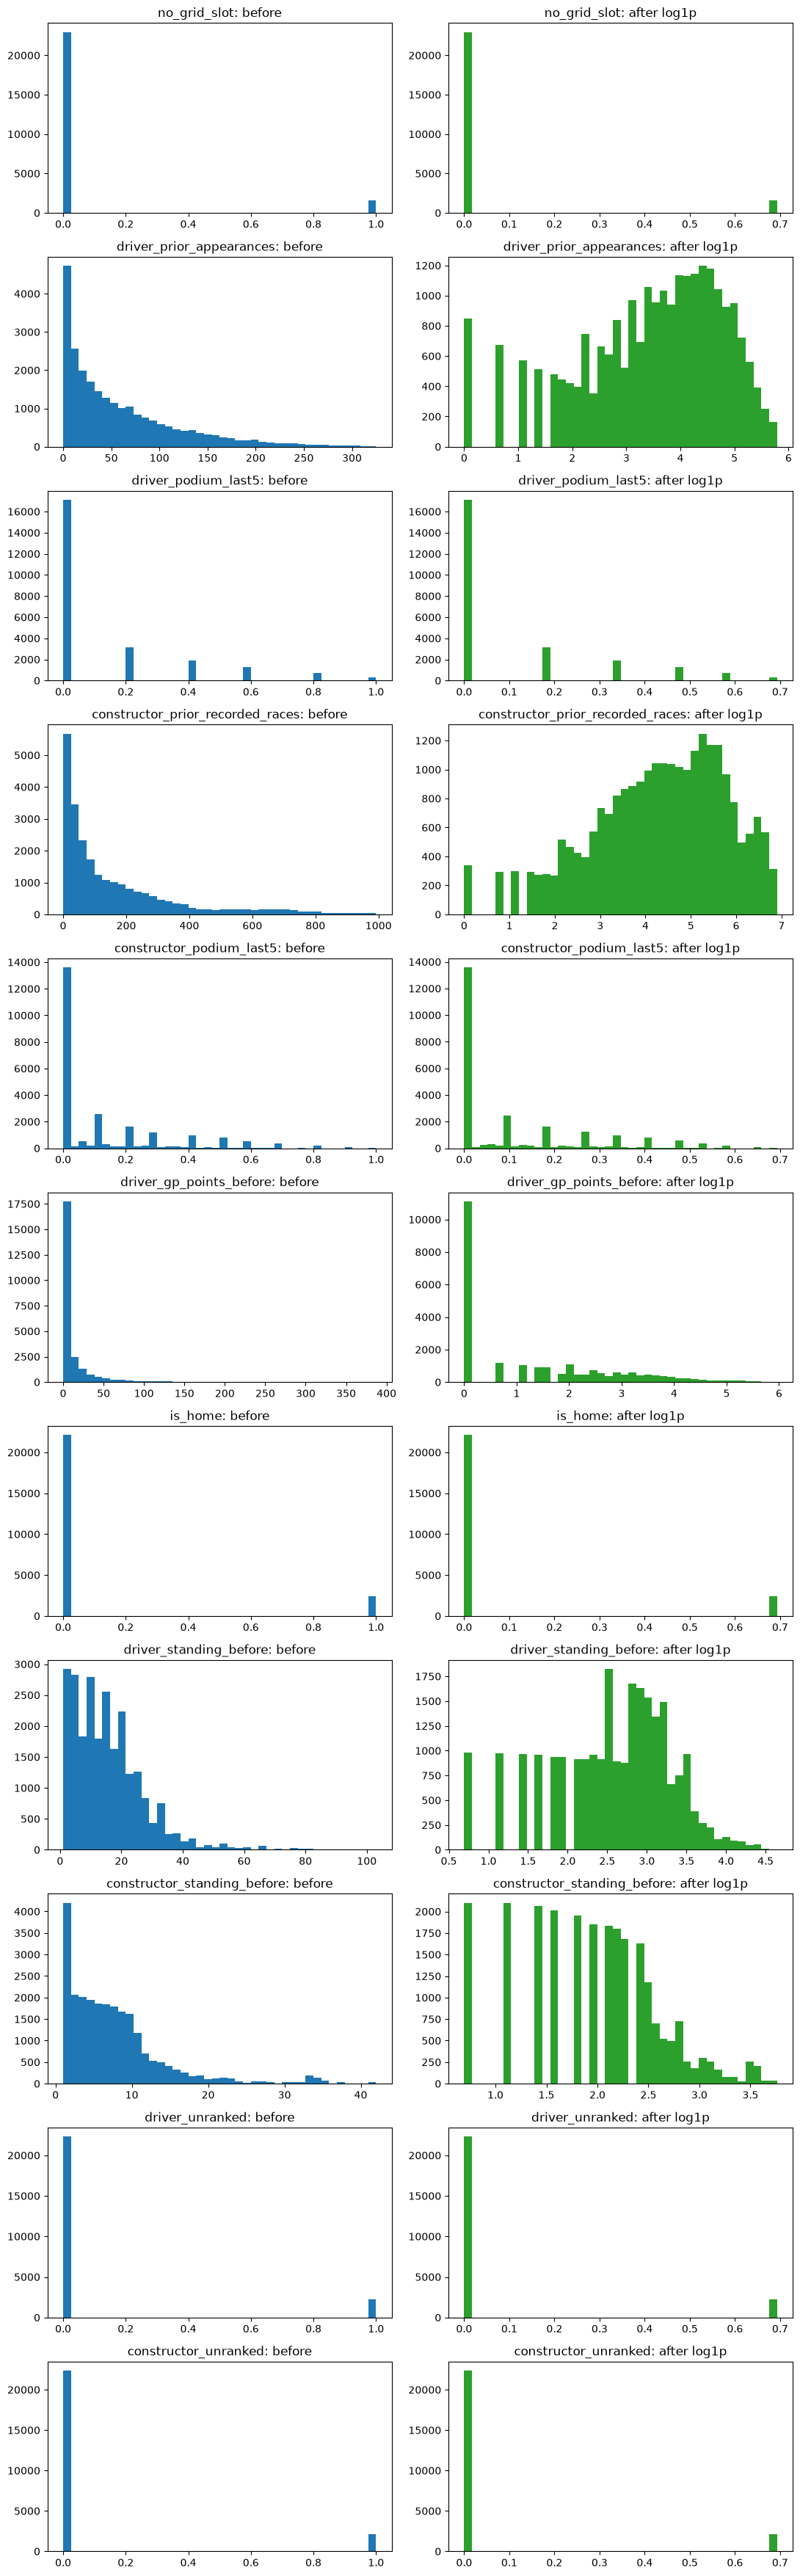

,Skew before,Skew after log1p
Feature,,
no_grid_slot,3.551,3.551
driver_prior_appearances,1.451,-0.710
driver_podium_last5,1.944,1.663
constructor_prior_recorded_races,1.834,-0.579
constructor_podium_last5,1.732,1.445
driver_gp_points_before,4.972,0.756
is_home,2.692,2.692
driver_standing_before,1.693,-0.530
constructor_standing_before,2.004,-0.071


In [300]:
if skewed:
    log_rows = []
    fig, axes = plt.subplots(len(skewed), 2, figsize=(11, 3.2 * len(skewed)), squeeze=False)
    for r, f in enumerate(skewed):
        values = imputed_train[f]
        logged = np.log1p(values)
        log_rows.append({"Feature": f, "Skew before": skew(values), "Skew after log1p": skew(logged)})
        axes[r, 0].hist(values, bins=40, color="tab:blue")
        axes[r, 0].set_title(f"{f}: before")
        axes[r, 1].hist(logged, bins=40, color="tab:green")
        axes[r, 1].set_title(f"{f}: after log1p")
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(log_rows).set_index("Feature").round(3))


**Decision:** The log transform above is only an illustration of its effect on skew. The selected 14-feature pipeline does not apply it. We keep that pipeline fixed here; a log transform would need its own controlled validation comparison before adoption.


### 6.8.4 Engineered features: range, distribution and the past-only check

These features are built from earlier races (form, standings before the race, experience, age).
The table gives their range after imputation. The checks confirm the history features use only the past.


,count,mean,std,min,25%,50%,75%,max
driver_age,24529.0,30.113,5.206,17.454,26.363,29.583,33.326,58.788
driver_prior_appearances,24529.0,59.823,61.231,0.000,13.000,39.000,88.000,325.000
driver_podium_last5,24529.0,0.124,0.226,0.000,0.000,0.000,0.200,1.000
constructor_prior_recorded_races,24529.0,165.267,199.122,0.000,27.000,85.000,228.000,992.000
constructor_podium_last5,24529.0,0.127,0.195,0.000,0.000,0.000,0.200,1.000
driver_gp_points_before,24529.0,13.559,33.540,0.000,0.000,1.000,11.000,387.000
grid,24529.0,12.847,7.439,1.000,7.000,13.000,19.000,34.000
no_grid_slot,24529.0,0.064,0.245,0.000,0.000,0.000,0.000,1.000
driver_standing_before,24529.0,15.624,11.834,1.000,7.000,14.000,21.000,103.000
constructor_standing_before,24529.0,7.852,6.364,1.000,3.000,7.000,10.000,42.000


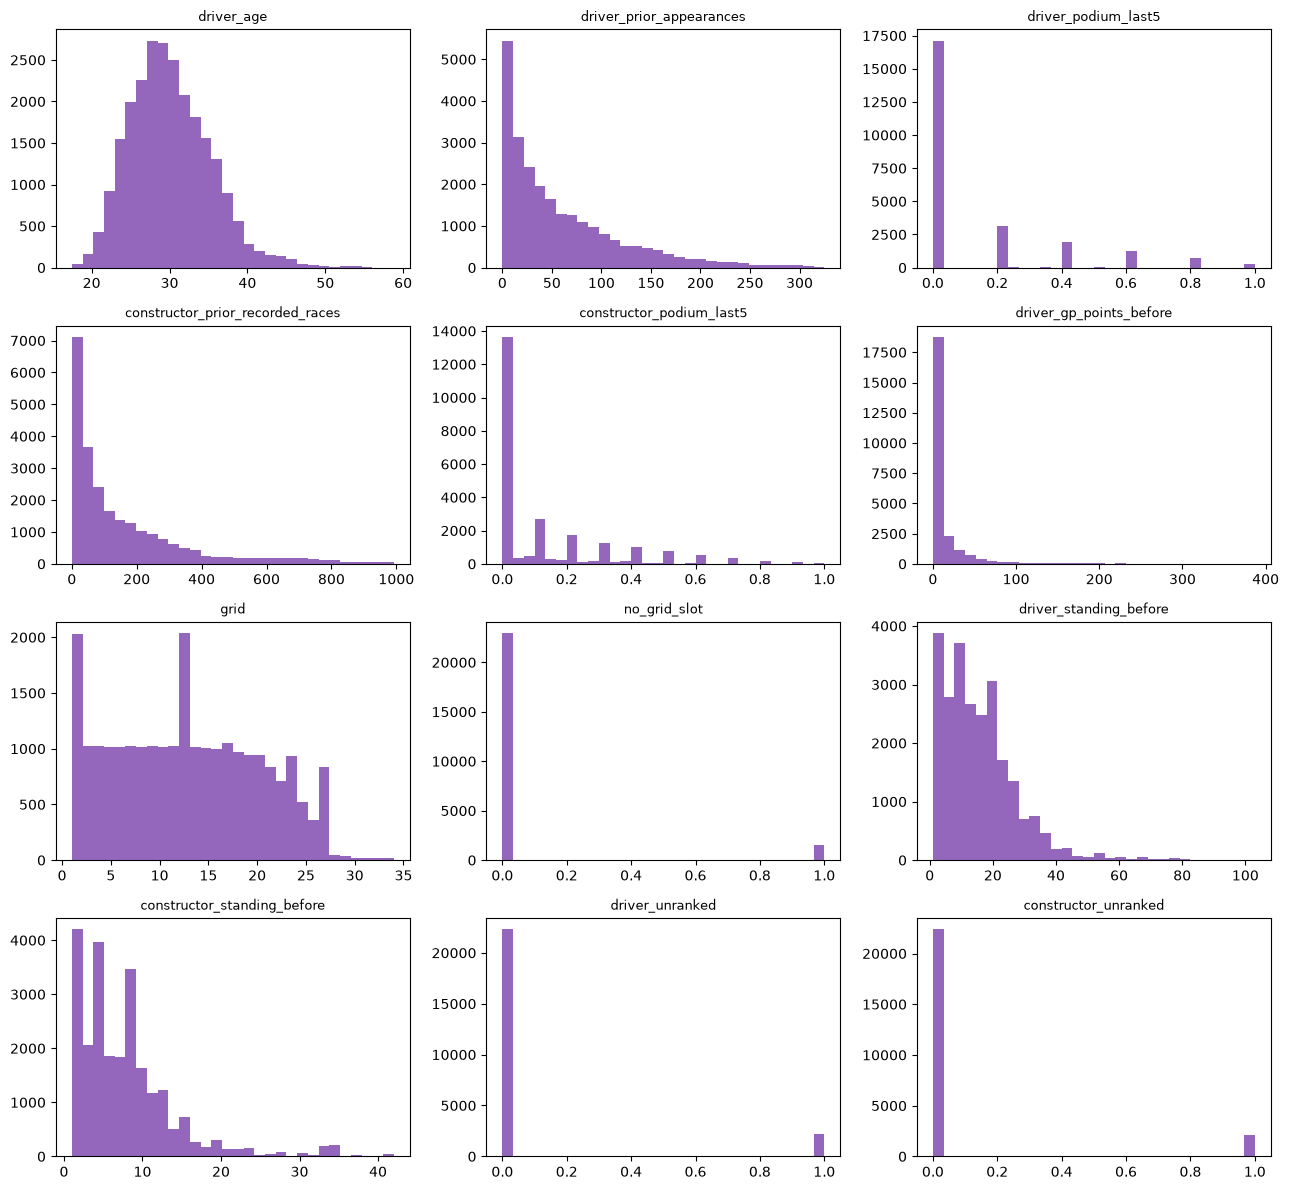

In [301]:
engineered = [f for f in ["driver_age", "driver_prior_appearances", "driver_podium_last5",
                          "constructor_prior_recorded_races", "constructor_podium_last5",
                          "driver_gp_points_before", "grid", "no_grid_slot",
                          "driver_standing_before", "constructor_standing_before",
                          "driver_unranked", "constructor_unranked"] if f in feats]
display(imputed_train[engineered].describe().T.round(3))

n_cols = 3
n_rows = int(np.ceil(len(engineered) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 3 * n_rows), squeeze=False)
for ax, f in zip(axes.ravel(), engineered):
    ax.hist(imputed_train[f], bins=30, color="tab:purple")
    ax.set_title(f, fontsize=9)
for ax in axes.ravel()[len(engineered):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [302]:
# Past-only sanity checks on the full candidate table (sorted by date within each driver).
fc = feature_candidates.sort_values(["driverId", "date"])
if "driver_prior_appearances" in fc:
    first_race = fc.groupby("driverId").head(1)
    assert first_race["driver_prior_appearances"].eq(0).all(), "a driver's first race must have 0 prior appearances"
    assert (fc.groupby("driverId")["driver_prior_appearances"].diff().dropna() >= 0).all(), "prior appearances must not decrease"
    print("Verified: prior appearances start at 0 and never decrease for any driver.")
if "driver_podium_last5" in fc:
    first_race = fc.groupby("driverId").head(1)
    print("First-race driver_podium_last5 values (should be 0 or missing, never a real podium count):",
          first_race["driver_podium_last5"].fillna(0).unique()[:5])
print("Hand checks of standings and form against real results are in section 5 (Hamilton 2008).")


Verified: prior appearances start at 0 and never decrease for any driver.
First-race driver_podium_last5 values (should be 0 or missing, never a real podium count): [0.]
Hand checks of standings and form against real results are in section 5 (Hamilton 2008).


### 6.8.5 Encoding

All selected inputs are numeric (counts, rates, ranks, flags), so no categorical encoding is applied.
Identifier columns such as `constructorId` or `driverId` have many categories; one-hot encoding would add
one column per value and mostly capture history that the form and standing features already summarise.


In [303]:
assert all(pd.api.types.is_numeric_dtype(base["raw"]["Train"][f]) for f in feats)
print("All", len(feats), "selected features are numeric; no encoding step is needed.")

id_columns = [c for c in ["driverId", "constructorId", "circuitId"] if c in feature_candidates.columns]
display(pd.DataFrame({
    "Categories": [feature_candidates[c].nunique() for c in id_columns],
    "One-hot columns that would be added": [feature_candidates[c].nunique() - 1 for c in id_columns]},
    index=id_columns))


All 14 selected features are numeric; no encoding step is needed.


,Categories,One-hot columns that would be added
driverId,861,860
constructorId,210,209
circuitId,77,76


## 6.9 Preprocessing-order experiments

The order and the place where preprocessing is fitted can change what a model sees. We test three orderings on
the **same rows, the same 14 features, the same model, and the same threshold rule**, so the only thing that
changes between two pipelines is the preprocessing.

| Experiment | Pipeline A | Pipeline B | Question |
|---|---|---|---|
| 6.9.1 | Fit imputer and scaler on **training rows only** (our final pipeline) | Fit on **train + validation** rows (deliberately leaky for validation) | Does fitting on later seasons leak information? |
| 6.9.2 | **Impute, then scale** (our final pipeline) | **Scale, then impute** | Does the order of the two steps matter? |
| 6.9.3 | **Clip outliers before scaling** | **Clip outliers after scaling** (and no clipping as a reference) | Does clipping help, and does its position matter? |

**Model:** logistic regression with fixed settings (`C = 1`, 5000 iterations). It is scale-sensitive, so it can
react to preprocessing; a random forest would give identical results for any scaling. The tuned regression
settings of section 9 do not exist yet at this point, so fixed settings are used, the same in every pipeline.
**Selection rule:** the probability threshold is chosen on validation F1 separately for each pipeline.
**Reported metrics:** ROC-AUC, PR-AUC and F1 on train and validation. Test-season rows are never used to fit, choose, or evaluate an experimental pipeline.


In [304]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

base = version_inputs["Baseline (1950+)"]
feats = base["features"]
prep_raw = base["raw"]
prep_y = base["y"]
EVAL_SPLITS = ["Train", "Val"]          # test seasons stay untouched in this section
CLIP_QUANTILES = (0.01, 0.99)           # winsorising limits used in experiment 6.9.3

def preprocess(order="impute_scale", fit_on="train", clip=None):
    """Return preprocessed arrays for every split and the fitted imputer and scaler.

    order  : "impute_scale" or "scale_impute"
    fit_on : "train" (training only) or "train_val" (leaky for validation; test excluded)
    clip   : None, "before_scaling" or "after_scaling" (clip to the 1st-99th percentile of the fitting rows)
    """
    arrays = {s: prep_raw[s].to_numpy(dtype=float) for s in SPLITS}
    assert fit_on in {"train", "train_val"}
    fit_array = arrays["Train"] if fit_on == "train" else np.vstack([arrays["Train"], arrays["Val"]])

    def clip_all(lo, hi):
        return {s: np.clip(v, lo, hi) for s, v in arrays.items()}, np.clip(fit_array, lo, hi)

    if clip == "before_scaling":
        lo = np.nanquantile(fit_array, CLIP_QUANTILES[0], axis=0)
        hi = np.nanquantile(fit_array, CLIP_QUANTILES[1], axis=0)
        arrays, fit_array = clip_all(lo, hi)

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    if order == "impute_scale":
        imputer.fit(fit_array)
        arrays = {s: imputer.transform(v) for s, v in arrays.items()}
        fit_array = imputer.transform(fit_array)
        scaler.fit(fit_array)
        arrays = {s: scaler.transform(v) for s, v in arrays.items()}
        fit_array = scaler.transform(fit_array)
    elif order == "scale_impute":
        scaler.fit(fit_array)                      # StandardScaler ignores NaN when fitting
        arrays = {s: scaler.transform(v) for s, v in arrays.items()}
        fit_array = scaler.transform(fit_array)
        imputer.fit(fit_array)
        arrays = {s: imputer.transform(v) for s, v in arrays.items()}
        fit_array = imputer.transform(fit_array)
    else:
        raise ValueError(order)

    if clip == "after_scaling":
        lo = np.nanquantile(fit_array, CLIP_QUANTILES[0], axis=0)
        hi = np.nanquantile(fit_array, CLIP_QUANTILES[1], axis=0)
        arrays = {s: np.clip(v, lo, hi) for s, v in arrays.items()}

    assert all(not np.isnan(v).any() for v in arrays.values()), "NaNs left after preprocessing"
    return arrays, {"imputer": imputer, "scaler": scaler}

def run_order_experiment(label, **kwargs):
    arrays, fitted = preprocess(**kwargs)
    model = LogisticRegression(C=1.0, max_iter=5000).fit(arrays["Train"], prep_y["Train"])
    prob = {s: model.predict_proba(arrays[s])[:, 1] for s in EVAL_SPLITS}
    threshold, _ = choose_threshold(prep_y["Val"], prob["Val"])
    row = {"Pipeline": label, "Threshold": threshold}
    for s in EVAL_SPLITS:
        metrics = podium_metrics(prep_y[s], prob[s], threshold)
        for name in ["ROC-AUC", "PR-AUC", "F1"]:
            row[f"{s} {name}"] = metrics[name]
    return row, arrays, fitted

def show_comparison(rows, reference):
    table = pd.DataFrame(rows).set_index("Pipeline")
    for name in ["ROC-AUC", "PR-AUC", "F1"]:
        table[f"Val {name} change vs {reference}"] = table[f"Val {name}"] - table.loc[reference, f"Val {name}"]
    with pd.option_context("display.width", 250, "display.max_columns", None):
        display(table.round(5))
    return table

# Consistency check: our "train only, impute then scale" pipeline must reproduce the final pipeline from section 6.7.
check_arrays, _ = preprocess("impute_scale", "train")
for s in SPLITS:
    assert np.allclose(check_arrays[s], base["X_scaled"][s]), f"{s}: differs from build_version_inputs"
print("Verified: Pipeline A of every experiment reproduces build_version_inputs exactly (all splits).")

all_results = []


Verified: Pipeline A of every experiment reproduces build_version_inputs exactly (all splits).


### 6.9.1 Where to fit: training rows only vs train + validation rows

**Hypothesis.** Fitting the imputer and scaler on training plus validation rows lets validation seasons influence the
medians, means and standard deviations applied to validation. This leaks validation inputs.
The effect may be positive, negative, or negligible; we do not assume its direction. If the numbers
are almost identical, the leak is small for this data, but the train-only rule is still the correct design
because it matches what is possible at prediction time.


In [305]:
row_a, _, fitted_a = run_order_experiment("A: fit on train only", order="impute_scale", fit_on="train")
row_b, _, fitted_b = run_order_experiment("B: fit on train + val (leaky)", order="impute_scale", fit_on="train_val")
exp1 = show_comparison([row_a, row_b], reference="A: fit on train only")
all_results += [("6.9.1", row_a), ("6.9.1", row_b)]

# Mechanism: how far the fitted statistics move when later seasons are included.
stat_shift = pd.DataFrame({
    "Scaler mean (train only)": fitted_a["scaler"].mean_,
    "Scaler mean (train + validation)": fitted_b["scaler"].mean_,
    "Shift in mean (in train std units)": (fitted_b["scaler"].mean_ - fitted_a["scaler"].mean_) / fitted_a["scaler"].scale_,
    "Scaler std (train only)": fitted_a["scaler"].scale_,
    "Scaler std (train + validation)": fitted_b["scaler"].scale_}, index=feats)
display(stat_shift.round(4).sort_values("Shift in mean (in train std units)", key=np.abs, ascending=False))


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Threshold,Train ROC-AUC,Train PR-AUC,Train F1,Val ROC-AUC,Val PR-AUC,Val F1,Val ROC-AUC change vs A: fit on train only,Val PR-AUC change vs A: fit on train only,Val F1 change vs A: fit on train only
Pipeline,,,,,,,,,,
A: fit on train only,0.32,0.90507,0.55895,0.57711,0.92214,0.71407,0.68619,0.00000,0.00000,0.00000
B: fit on train + val (leaky),0.29,0.90507,0.55901,0.58257,0.92219,0.71418,0.68826,0.00005,0.00011,0.00207


,Scaler mean (train only),Scaler mean (train + validation),Shift in mean (in train std units),Scaler std (train only),Scaler std (train + validation)
year,1988.8492,1989.8266,0.0530,18.4475,18.9703
driver_prior_appearances,59.8229,61.7115,0.0308,61.2296,63.5229
constructor_prior_recorded_races,165.2667,171.3183,0.0304,199.1183,208.3483
driver_gp_points_before,13.5587,14.5773,0.0304,33.5391,35.3741
driver_age,30.1132,30.0440,-0.0133,5.2062,5.2362
driver_standing_before,15.6241,15.4741,-0.0127,11.8337,11.7280
constructor_standing_before,7.8515,7.7805,-0.0112,6.3634,6.2980
grid,12.8471,12.7768,-0.0094,7.4386,7.4048
constructor_unranked,0.0879,0.0854,-0.0087,0.2831,0.2795
driver_unranked,0.0909,0.0885,-0.0084,0.2875,0.2840


In [306]:
shift_1 = exp1.loc["B: fit on train + val (leaky)", "Val PR-AUC change vs A: fit on train only"]
print(f"6.9.1: validation PR-AUC changed by {shift_1:+.4f} when validation rows influenced preprocessing. "
      "This is leakage for validation, regardless of whether the observed change helped or hurt. "
      "Use train-only fitting; the test rows were not used in this experiment.")


6.9.1: validation PR-AUC changed by +0.0001 when validation rows influenced preprocessing. This is leakage for validation, regardless of whether the observed change helped or hurt. Use train-only fitting; the test rows were not used in this experiment.


### 6.9.2 Order of the two steps: impute then scale vs scale then impute

**Hypothesis.** The median of scaled values equals the scaled median (scaling is a monotonic affine map), so the
filled value is the same point in both orders. The pipelines differ only in the scaler statistics: when scaling
first, the mean and std come from observed values only; when imputing first they include the filled medians.
Only features that contain missing values can differ, so we expect a very small or zero difference.


In [307]:
row_a, arrays_a, fitted_a = run_order_experiment("A: impute then scale", order="impute_scale", fit_on="train")
row_b, arrays_b, fitted_b = run_order_experiment("B: scale then impute", order="scale_impute", fit_on="train")
exp2 = show_comparison([row_a, row_b], reference="A: impute then scale")
all_results += [("6.9.2", row_a), ("6.9.2", row_b)]

train_missing = prep_raw["Train"].isna().sum()
order_stats = pd.DataFrame({
    "Missing in train": train_missing,
    "Scaler mean (impute first)": fitted_a["scaler"].mean_,
    "Scaler mean (scale first)": fitted_b["scaler"].mean_,
    "Scaler std (impute first)": fitted_a["scaler"].scale_,
    "Scaler std (scale first)": fitted_b["scaler"].scale_}, index=feats)
display(order_stats.round(4).loc[lambda t: t["Missing in train"] > 0] if (train_missing > 0).any() else order_stats.round(4))
print("Largest absolute difference between the two scaled Train matrices:",
      float(np.abs(arrays_a["Train"] - arrays_b["Train"]).max()))
print("Features with no missing values give identical scaled columns:",
      bool(np.allclose(arrays_a["Train"][:, (train_missing == 0).to_numpy()], arrays_b["Train"][:, (train_missing == 0).to_numpy()])))


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Threshold,Train ROC-AUC,Train PR-AUC,Train F1,Val ROC-AUC,Val PR-AUC,Val F1,Val ROC-AUC change vs A: impute then scale,Val PR-AUC change vs A: impute then scale,Val F1 change vs A: impute then scale
Pipeline,,,,,,,,,,
A: impute then scale,0.32,0.90507,0.55895,0.57711,0.92214,0.71407,0.68619,0.0,0.0,0.0
B: scale then impute,0.32,0.90507,0.55895,0.57703,0.92214,0.71407,0.68619,0.0,0.0,0.0


,Missing in train,Scaler mean (impute first),Scaler mean (scale first),Scaler std (impute first),Scaler std (scale first)
constructor_prior_recorded_races,16,165.2667,165.3191,199.1183,199.1727
constructor_podium_last5,16,0.1269,0.1270,0.1953,0.1953
constructor_standing_before,16,7.8515,7.8521,6.3634,6.3655
constructor_unranked,16,0.0879,0.0879,0.2831,0.2832


Largest absolute difference between the two scaled Train matrices: 0.0018064580161185617
Features with no missing values give identical scaled columns: True


In [308]:
shift_2 = exp2.loc["B: scale then impute", "Val PR-AUC change vs A: impute then scale"]
print(f"6.9.2: reversing imputation and scaling changed validation PR-AUC by {shift_2:+.4f}. "
      f"Training has {int(train_missing.sum())} missing input cells; only their columns can change. "
      "The selected pipeline keeps impute-then-scale, whose fitted values are checked against section 6.7. "
      "A single validation comparison is not a significance test.")


6.9.2: reversing imputation and scaling changed validation PR-AUC by +0.0000. Training has 64 missing input cells; only their columns can change. The selected pipeline keeps impute-then-scale, whose fitted values are checked against section 6.7. A single validation comparison is not a significance test.


### 6.9.3 Outlier clipping: before vs after scaling

**Hypothesis.** Features such as `driver_gp_points_before` and `driver_prior_appearances` have long tails.
Clipping to the 1st-99th percentile of the training rows limits their influence on a linear model. Clipping
**before** scaling also keeps the extreme values out of the scaler's mean and std; clipping **after** scaling
leaves the scaler computed on the raw tails. We expect a small difference between the two, and we compare both
with the no-clipping pipeline we actually use. Limits always come from the training rows.


In [309]:
rows = []
reference_label = "A: no clipping (final pipeline)"
for label, clip in [(reference_label, None), ("B: clip before scaling", "before_scaling"), ("C: clip after scaling", "after_scaling")]:
    row, arrays, fitted = run_order_experiment(label, order="impute_scale", fit_on="train", clip=clip)
    row["Max |scaled value| in Train"] = float(np.abs(arrays["Train"]).max())
    rows.append(row)
    all_results.append(("6.9.3", row))
exp3 = show_comparison(rows, reference=reference_label)


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Threshold,Train ROC-AUC,Train PR-AUC,Train F1,Val ROC-AUC,Val PR-AUC,Val F1,Max |scaled value| in Train,Val ROC-AUC change vs A: no clipping (final pipeline),Val PR-AUC change vs A: no clipping (final pipeline),Val F1 change vs A: no clipping (final pipeline)
Pipeline,,,,,,,,,,,
A: no clipping (final pipeline),0.32,0.90507,0.55895,0.57711,0.92214,0.71407,0.68619,11.13449,0.00000,0.00000,0.0000
B: clip before scaling,0.37,0.90513,0.55761,0.56567,0.92157,0.69531,0.68670,5.89678,-0.00057,-0.01876,0.0005
C: clip after scaling,0.37,0.90513,0.55758,0.56558,0.92158,0.69476,0.68670,5.14150,-0.00055,-0.01931,0.0005


In [310]:
# Effect of clipping on the scaled range of the most affected features (training rows).
unclipped, _ = preprocess("impute_scale", "train", clip=None)
clipped_before, _ = preprocess("impute_scale", "train", clip="before_scaling")
range_change = pd.DataFrame({
    "Max |value| no clipping": np.abs(unclipped["Train"]).max(axis=0),
    "Max |value| clip before scaling": np.abs(clipped_before["Train"]).max(axis=0)}, index=feats)
range_change["Reduction"] = range_change["Max |value| no clipping"] - range_change["Max |value| clip before scaling"]
display(range_change.sort_values("Reduction", ascending=False).head(6).round(3))


,Max |value| no clipping,Max |value| clip before scaling,Reduction
driver_gp_points_before,11.134,5.897,5.238
driver_standing_before,7.384,3.936,3.448
driver_age,5.508,2.960,2.548
constructor_standing_before,5.366,4.170,1.197
constructor_podium_last5,4.471,3.496,0.975
grid,2.844,1.916,0.928


In [311]:
clip_changes = exp3.loc[["B: clip before scaling", "C: clip after scaling"],
                        "Val PR-AUC change vs A: no clipping (final pipeline)"]
print("6.9.3: validation PR-AUC changes vs no clipping:")
display(clip_changes.round(4).rename("PR-AUC change").to_frame())
print("Difference between clipping positions:",
      f"{exp3.loc['B: clip before scaling', 'Val PR-AUC'] - exp3.loc['C: clip after scaling', 'Val PR-AUC']:+.4f}.")
print("We keep the existing no-clipping pipeline for the final models; this one-split comparison "
      "does not establish a reliable improvement. Test outcomes did not select this choice.")


6.9.3: validation PR-AUC changes vs no clipping:


,PR-AUC change
Pipeline,
B: clip before scaling,-0.0188
C: clip after scaling,-0.0193


Difference between clipping positions: +0.0006.
We keep the existing no-clipping pipeline for the final models; this one-split comparison does not establish a reliable improvement. Test outcomes did not select this choice.


### 6.9.4 Summary and chosen order


Threshold  Train ROC-AUC  Train PR-AUC  Train F1  Val ROC-AUC  Val PR-AUC   Val F1
Experiment Pipeline                                                                                                           
6.9.1      A: fit on train only                  0.32        0.90507       0.55895   0.57711      0.92214     0.71407  0.68619
           B: fit on train + val (leaky)         0.29        0.90507       0.55901   0.58257      0.92219     0.71418  0.68826
6.9.2      A: impute then scale                  0.32        0.90507       0.55895   0.57711      0.92214     0.71407  0.68619
           B: scale then impute                  0.32        0.90507       0.55895   0.57703      0.92214     0.71407  0.68619
6.9.3      A: no clipping (final pipeline)       0.32        0.90507       0.55895   0.57711      0.92214     0.71407  0.68619
           B: clip before scaling                0.37        0.90513       0.55761   0.56567      0.92157     0.69531  0.68670
           C: clip after scaling                 0.37        0.90513       0.55758   0.56558      0.92158     0.69476  0.68670

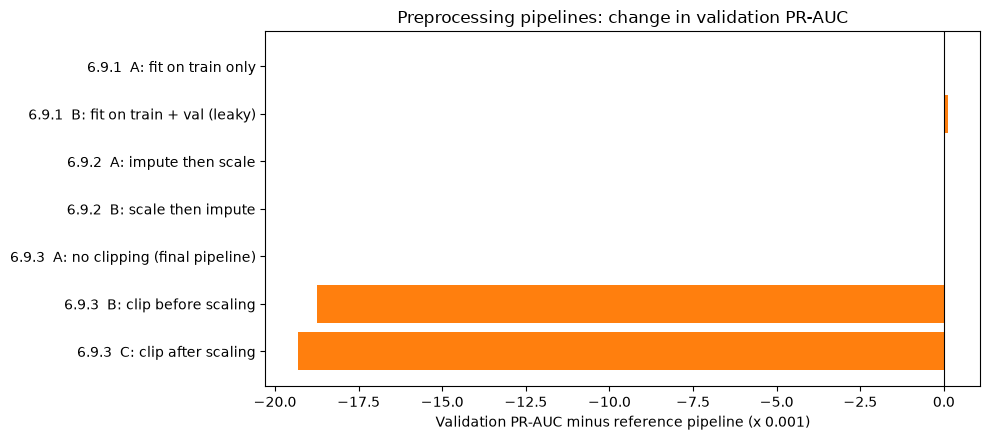

In [312]:
summary = pd.DataFrame([{"Experiment": exp, **row} for exp, row in all_results]).drop_duplicates(["Experiment", "Pipeline"])
summary = summary.set_index(["Experiment", "Pipeline"])
with pd.option_context("display.width", 250, "display.max_columns", None):
    display(summary[["Threshold", "Train ROC-AUC", "Train PR-AUC", "Train F1", "Val ROC-AUC", "Val PR-AUC", "Val F1"]].round(5))

reference = summary.loc[("6.9.1", "A: fit on train only"), "Val PR-AUC"]
delta = (summary["Val PR-AUC"] - reference) * 1000
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [f"{e}  {p}" for e, p in summary.index]
ax.barh(labels, delta.to_numpy(), color=["tab:blue" if "A:" in p else "tab:orange" for _, p in summary.index])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Validation PR-AUC minus reference pipeline (x 0.001)")
ax.set_title("Preprocessing pipelines: change in validation PR-AUC")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Chosen pipeline for sections 7-11 (final):** fit the median imputer and scaler on **training rows only**, in the order **impute, then scale**, with **no clipping**. The consistency assertion above verifies that this is the pipeline used in the model sections. The measured changes are stated below; test performance is reserved for final evaluation.


In [313]:
print(f"Measured validation PR-AUC changes: fitting on train + validation {shift_1:+.4f}; "
      f"scaling before imputation {shift_2:+.4f}; "
      f"clipping before scaling {clip_changes.loc['B: clip before scaling']:+.4f}; "
      f"clipping after scaling {clip_changes.loc['C: clip after scaling']:+.4f}. "
      "We retain the train-only, impute-then-scale, no-clipping pipeline used by the final models.")


Measured validation PR-AUC changes: fitting on train + validation +0.0001; scaling before imputation +0.0000; clipping before scaling -0.0188; clipping after scaling -0.0193. We retain the train-only, impute-then-scale, no-clipping pipeline used by the final models.


# 7. Neural Network Model

## 7.1 How the network works and why we use it

A feed-forward neural network passes the scaled inputs through **two hidden layers** (128 and 64 units). Each unit computes a weighted sum of its inputs followed by a ReLU activation, so the network can learn curved relationships and interactions, for example that a front-row start matters more for a driver whose team is in form. A final sigmoid unit outputs the podium probability. Training minimises binary cross-entropy with the Adam optimiser.

- **Shallow, as the brief requires:** two hidden layers.
- **Regularisation:** batch normalisation and dropout (40% and 30%) reduce overfitting; **early stopping** stops training when validation loss has not improved for 8 epochs and restores the best weights.
- **Scaling:** inputs use the `StandardScaler` of each version, because weighted sums are sensitive to input size.
- **Limitations:** the network is harder to interpret than the other models, needs scaled inputs, and its training is not fully deterministic, so scores can move slightly between runs and machines.

The same architecture is trained in each of the four versions; only the training rows and features change.

In [314]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_shallow_nn(n_inputs, seed=42):
    tf.keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        layers.Input(shape=(n_inputs,)),
        layers.Dense(128, kernel_initializer="he_normal"), layers.BatchNormalization(),
        layers.Activation("relu"), layers.Dropout(0.4),
        layers.Dense(64, kernel_initializer="he_normal"), layers.BatchNormalization(),
        layers.Activation("relu"), layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

def train_nn(inputs):
    model = build_shallow_nn(inputs["X_scaled"]["Train"].shape[1])
    history = model.fit(inputs["X_scaled"]["Train"], inputs["y"]["Train"],
                        validation_data=(inputs["X_scaled"]["Val"], inputs["y"]["Val"]),
                        epochs=100, batch_size=256, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
    probs = {split: model.predict(inputs["X_scaled"][split], verbose=0).ravel() for split in SPLITS}
    return model, history, probs

build_shallow_nn(len(selected_features)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,009 (43.00 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 384 (1.50 KB)

## 7.2 Train the four versions

Each version is trained with early stopping on validation; the threshold is the one with the best validation F1.

Baseline (1950+): 88 epochs, threshold 0.30


2003+: 53 epochs, threshold 0.48


2003+ + q1: 29 epochs, threshold 0.45


2003+ + q1 gap: 29 epochs, threshold 0.51


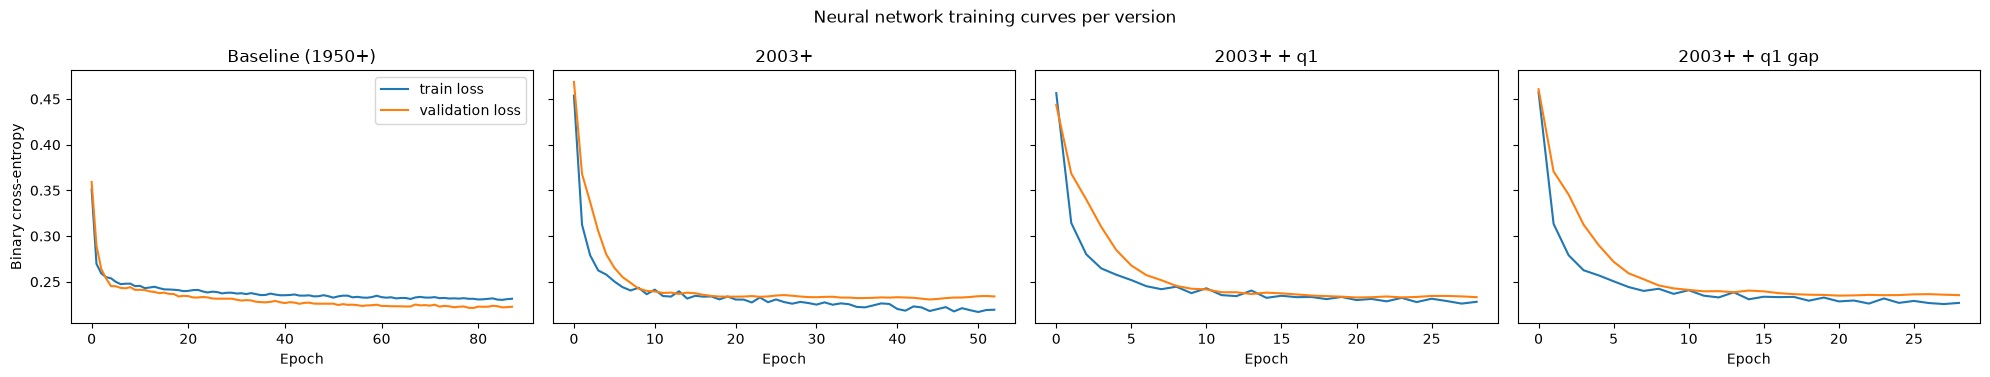

In [315]:
nn_models, nn_histories, nn_probs, nn_thresholds = {}, {}, {}, {}
for version, inputs in version_inputs.items():
    nn_models[version], nn_histories[version], nn_probs[version] = train_nn(inputs)
    nn_thresholds[version], _ = choose_threshold(inputs["y"]["Val"], nn_probs[version]["Val"])
    print(f"{version}: {len(nn_histories[version].history['loss'])} epochs, threshold {nn_thresholds[version]:.2f}")

fig, axes = plt.subplots(1, len(nn_histories), figsize=(20, 3.8), sharey=True)
for ax, (version, history) in zip(axes, nn_histories.items()):
    ax.plot(history.history["loss"], label="train loss")
    ax.plot(history.history["val_loss"], label="validation loss")
    ax.set_title(version); ax.set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy"); axes[0].legend()
fig.suptitle("Neural network training curves per version")
plt.tight_layout(); plt.show()

## 7.3 Compare the four versions

,Model,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Neural network,Baseline (1950+),Train,0.30,0.9167,0.5972,0.5946,0.4994,0.7345,0.8745
1,Neural network,Baseline (1950+),Val,0.30,0.9321,0.7410,0.7036,0.6544,0.7607,0.9038
2,Neural network,Baseline (1950+),Test,0.30,0.9362,0.6956,0.6639,0.5782,0.7794,0.8815
3,Neural network,2003+,Train,0.48,0.9405,0.7154,0.6761,0.6604,0.6926,0.9065
4,Neural network,2003+,Val,0.48,0.9289,0.7405,0.6979,0.6949,0.7009,0.9090
5,Neural network,2003+,Test,0.48,0.9313,0.6768,0.6256,0.6559,0.5980,0.8926
6,Neural network,2003+ + q1,Train,0.45,0.9364,0.6984,0.6771,0.6078,0.7643,0.8972
7,Neural network,2003+ + q1,Val,0.45,0.9272,0.7322,0.6917,0.6748,0.7094,0.9051
8,Neural network,2003+ + q1,Test,0.45,0.9299,0.6651,0.6295,0.6220,0.6373,0.8874
9,Neural network,2003+ + q1 gap,Train,0.51,0.9367,0.6962,0.6580,0.6372,0.6802,0.9003


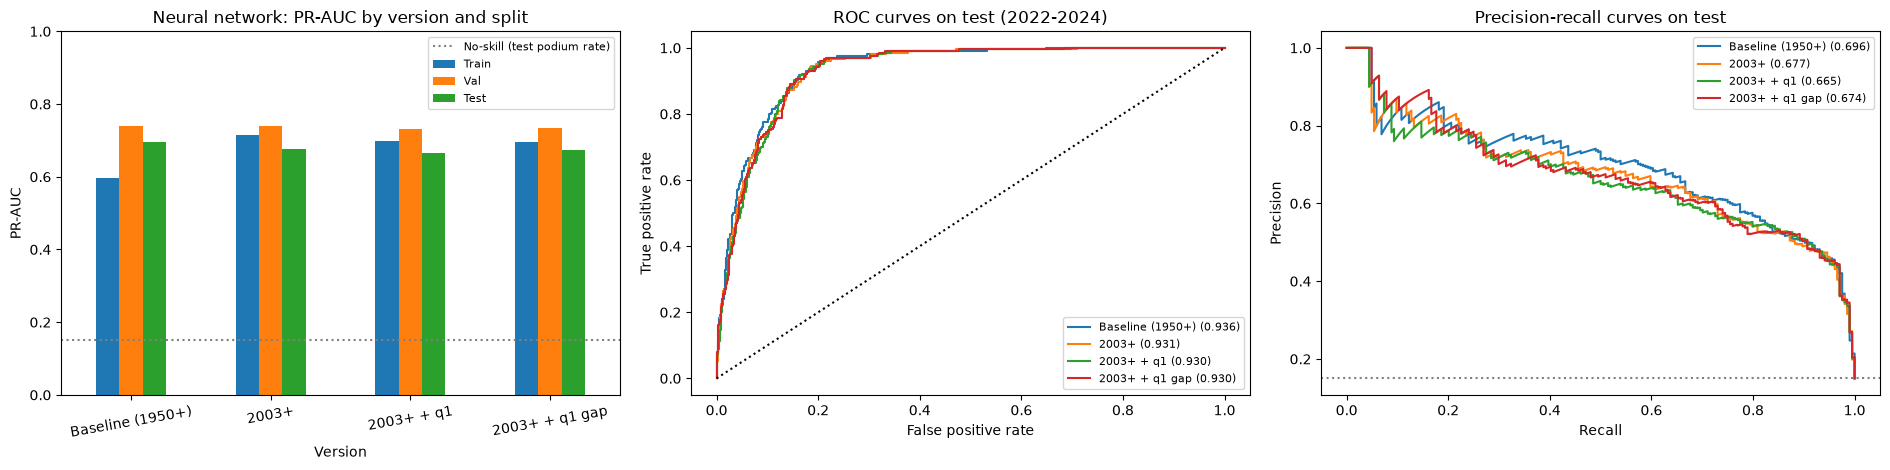

Best version on validation PR-AUC: Baseline (1950+). Its test confusion matrix:


,Predicted no podium,Predicted podium
Actual no podium,1039,116
Actual podium,45,159


In [316]:
nn_results, nn_best_version = compare_versions("Neural network", nn_probs, nn_thresholds)

def nn_predict_from_imputed(version):
    model, scaler = nn_models[version], version_inputs[version]["scaler"]
    return lambda X: model.predict(scaler.transform(np.asarray(X, dtype=float)), verbose=0).ravel()

def nn_refit_val_test(version, features):
    inputs = build_version_inputs(version, features)
    _, _, probs = train_nn(inputs)
    return inputs, probs

model_registry["Neural network"] = {"results": nn_results, "best_version": nn_best_version,
                                    "thresholds": nn_thresholds, "probs": nn_probs,
                                    "predict_from_imputed": nn_predict_from_imputed, "refit": nn_refit_val_test}

## 7.4 What the neural network results show

The tables and explanation below are generated from the current run.


In [317]:
report_model_results("Neural network", nn_results, nn_best_version, histories=nn_histories)


**Neural network: current-run results**

,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline (1950+),Train,0.30,0.9167,0.5972,0.5946,0.4994,0.7345
1,Baseline (1950+),Val,0.30,0.9321,0.7410,0.7036,0.6544,0.7607
2,Baseline (1950+),Test,0.30,0.9362,0.6956,0.6639,0.5782,0.7794
3,2003+,Train,0.48,0.9405,0.7154,0.6761,0.6604,0.6926
4,2003+,Val,0.48,0.9289,0.7405,0.6979,0.6949,0.7009
5,2003+,Test,0.48,0.9313,0.6768,0.6256,0.6559,0.5980
6,2003+ + q1,Train,0.45,0.9364,0.6984,0.6771,0.6078,0.7643
7,2003+ + q1,Val,0.45,0.9272,0.7322,0.6917,0.6748,0.7094
8,2003+ + q1,Test,0.45,0.9299,0.6651,0.6295,0.6220,0.6373
9,2003+ + q1 gap,Train,0.51,0.9367,0.6962,0.6580,0.6372,0.6802


Selected using validation: **Baseline (1950+)**, with validation PR-AUC **0.7410** and threshold **0.30**. Its test PR-AUC is **0.6956**, ROC-AUC **0.9362**, and F1 **0.6639**. The validation PR-AUC range across versions is **0.0088**. This observed range is not a statistical significance test.

Split,Test,Train,Val,Train minus validation,Validation minus test
Version,,,,,
2003+,0.6768,0.7154,0.7405,-0.0252,0.0637
2003+ + q1,0.6651,0.6984,0.7322,-0.0338,0.0670
2003+ + q1 gap,0.6743,0.6962,0.7330,-0.0368,0.0587
Baseline (1950+),0.6956,0.5972,0.7410,-0.1438,0.0453


Positive train-minus-validation gaps indicate better training scores; era differences also affect these gaps. Use the curves and split scores together rather than declaring overfitting from one number.

At that threshold, the selected version identifies **159 of 204** test podiums and produces **116** false positives. No-skill test PR-AUC is the podium proportion: **0.1501**.

,Epochs run
Version,
Baseline (1950+),88
2003+,53
2003+ + q1,29
2003+ + q1 gap,29


Neural-network results can vary across runs, hardware and library versions. This text updates from the current run.

# 8. Random Forest Model

## 8.1 How the forest works and why we use it

A random forest trains many decision trees. Each tree asks a series of yes/no questions about the inputs (for example "is grid position 3 or better?") and ends in a group of drivers whose podium share is the tree's probability. Every tree sees a bootstrap sample of the training rows and, at each question, a random subset of the features; averaging hundreds of different trees cancels much of their individual noise.

**Why try it:** section 5 showed relationships that are not straight lines (podium rate falls steeply over the first grid slots, then flattens), and grid, form and standings interact. Trees represent such shapes without hand-made transformations and need no scaling.

**Limitations:** trees cannot extrapolate beyond the values seen in training (every test `year` is later than any training year, so the forest treats them like 2019); forest probabilities are averages of leaf shares and are not guaranteed to be calibrated; built-in importance favours features with many distinct values.

## 8.2 Attempt 1: default settings as a reference

Before tuning, a forest with scikit-learn's defaults (fully grown trees) is trained on the baseline version. Its measured training/validation gap is reported dynamically below.

In [318]:
from sklearn.ensemble import RandomForestClassifier
from itertools import product

baseline_inputs = version_inputs["Baseline (1950+)"]
rf_default = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(baseline_inputs["X"]["Train"], baseline_inputs["y"]["Train"])
rf_default_probs = {split: rf_default.predict_proba(baseline_inputs["X"][split])[:, 1] for split in ["Train", "Val"]}
rf_default_threshold, _ = choose_threshold(baseline_inputs["y"]["Val"], rf_default_probs["Val"])
display(pd.DataFrame([{"Split": split, **podium_metrics(baseline_inputs["y"][split], rf_default_probs[split], rf_default_threshold)}
                      for split in ["Train", "Val"]]).set_index("Split").round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Split,,,,,,
Train,1.0000,1.0000,0.9993,0.9987,1.0000,0.9998
Val,0.9166,0.6472,0.6848,0.6286,0.7521,0.8962


## 8.3 Attempt 2: tune each version on validation

For each version we evaluate the combinations in `rf_grid` and keep the one with the highest **validation PR-AUC**:

| Setting | Values | Effect |
|---|---|---|
| `max_depth` | 6, 10, 16, unlimited | How many questions in a row a tree may ask |
| `min_samples_leaf` | 1, 10, 30, 60 | Minimum drivers in each final group; larger values smooth the probabilities |
| `max_features` | `sqrt`, 0.6 | Share of features considered at each question |
| `class_weight` | none, `balanced_subsample` | Whether rare podium rows count more |

The search uses 200 trees per candidate; the final forest of each version uses 500 trees. The validation sample is limited; small score differences alone do not establish equivalence or statistical significance.

In [319]:
rf_grid = list(product([6, 10, 16, None], [1, 10, 30, 60], ["sqrt", 0.6], [None, "balanced_subsample"]))
rf_search_tables, rf_best_params = {}, {}
for version, inputs in version_inputs.items():
    trials = []
    for depth, leaf, features, weight in rf_grid:
        forest = RandomForestClassifier(n_estimators=200, max_depth=depth, min_samples_leaf=leaf, max_features=features,
                                        class_weight=weight, random_state=42, n_jobs=-1).fit(inputs["X"]["Train"], inputs["y"]["Train"])
        prob_val = forest.predict_proba(inputs["X"]["Val"])[:, 1]
        trials.append({"max_depth": depth, "min_samples_leaf": leaf, "max_features": features, "class_weight": weight,
                       "Train PR-AUC": average_precision_score(inputs["y"]["Train"], forest.predict_proba(inputs["X"]["Train"])[:, 1]),
                       "Val PR-AUC": average_precision_score(inputs["y"]["Val"], prob_val),
                       "Val ROC-AUC": roc_auc_score(inputs["y"]["Val"], prob_val)})
    trials = pd.DataFrame(trials).sort_values(["Val PR-AUC", "Val ROC-AUC"], ascending=False).reset_index(drop=True)
    rf_search_tables[version] = trials
    best = trials.iloc[0]
    rf_best_params[version] = {"max_depth": None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
                               "min_samples_leaf": int(best["min_samples_leaf"]), "max_features": best["max_features"],
                               "class_weight": None if pd.isna(best["class_weight"]) else best["class_weight"]}
    print(f"\n{version}: best settings {rf_best_params[version]}")
    display(trials.head(5).round(4))


Baseline (1950+): best settings {'max_depth': 10, 'min_samples_leaf': 30, 'max_features': 0.6, 'class_weight': None}


,max_depth,min_samples_leaf,max_features,class_weight,Train PR-AUC,Val PR-AUC,Val ROC-AUC
0,10.0,30,0.6,None,0.6610,0.7233,0.9298
1,10.0,10,0.6,None,0.7401,0.7231,0.9287
2,NaN,30,0.6,balanced_subsample,0.6678,0.7217,0.9265
3,16.0,30,0.6,balanced_subsample,0.6679,0.7213,0.9268
4,NaN,30,0.6,None,0.6681,0.7213,0.9284



2003+: best settings {'max_depth': 10, 'min_samples_leaf': 30, 'max_features': 0.6, 'class_weight': 'balanced_subsample'}


,max_depth,min_samples_leaf,max_features,class_weight,Train PR-AUC,Val PR-AUC,Val ROC-AUC
0,10.0,30,0.6,balanced_subsample,0.7598,0.7389,0.9297
1,16.0,30,0.6,balanced_subsample,0.7600,0.7388,0.9296
2,NaN,30,0.6,balanced_subsample,0.7600,0.7388,0.9296
3,10.0,30,0.6,None,0.7641,0.7352,0.9299
4,NaN,30,0.6,None,0.7634,0.7350,0.9293



2003+ + q1: best settings {'max_depth': 6, 'min_samples_leaf': 60, 'max_features': 0.6, 'class_weight': None}


,max_depth,min_samples_leaf,max_features,class_weight,Train PR-AUC,Val PR-AUC,Val ROC-AUC
0,6.0,60,0.6,None,0.7321,0.7236,0.9276
1,NaN,30,sqrt,None,0.7474,0.7222,0.9282
2,10.0,60,0.6,None,0.7338,0.7220,0.9283
3,10.0,30,0.6,None,0.7699,0.7218,0.9272
4,16.0,30,sqrt,None,0.7474,0.7216,0.9281



2003+ + q1 gap: best settings {'max_depth': 10, 'min_samples_leaf': 30, 'max_features': 0.6, 'class_weight': 'balanced_subsample'}


,max_depth,min_samples_leaf,max_features,class_weight,Train PR-AUC,Val PR-AUC,Val ROC-AUC
0,10.0,30,0.6,balanced_subsample,0.7649,0.7263,0.9295
1,16.0,30,0.6,balanced_subsample,0.7652,0.7239,0.9289
2,NaN,30,0.6,balanced_subsample,0.7652,0.7239,0.9289
3,6.0,30,0.6,None,0.7552,0.7236,0.9304
4,10.0,30,0.6,None,0.7672,0.7209,0.9289


## 8.4 Final forest for each version and comparison

,Model,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Random forest,Baseline (1950+),Train,0.32,0.9325,0.6614,0.6212,0.5523,0.7098,0.8915
1,Random forest,Baseline (1950+),Val,0.32,0.9295,0.7247,0.6980,0.6449,0.7607,0.9013
2,Random forest,Baseline (1950+),Test,0.32,0.9403,0.7291,0.6863,0.6015,0.7990,0.8904
3,Random forest,2003+,Train,0.63,0.9526,0.7618,0.6939,0.5886,0.8453,0.8949
4,Random forest,2003+,Val,0.63,0.9297,0.7344,0.7004,0.6429,0.7692,0.9013
5,Random forest,2003+,Test,0.63,0.9370,0.7214,0.6733,0.5695,0.8235,0.8801
6,Random forest,2003+ + q1,Train,0.26,0.9426,0.7326,0.6708,0.5616,0.8328,0.8848
7,Random forest,2003+ + q1,Val,0.26,0.9281,0.7192,0.6966,0.6200,0.7949,0.8962
8,Random forest,2003+ + q1,Test,0.26,0.9379,0.7246,0.6706,0.5566,0.8431,0.8756
9,Random forest,2003+ + q1 gap,Train,0.58,0.9536,0.7650,0.6890,0.5681,0.8754,0.8886


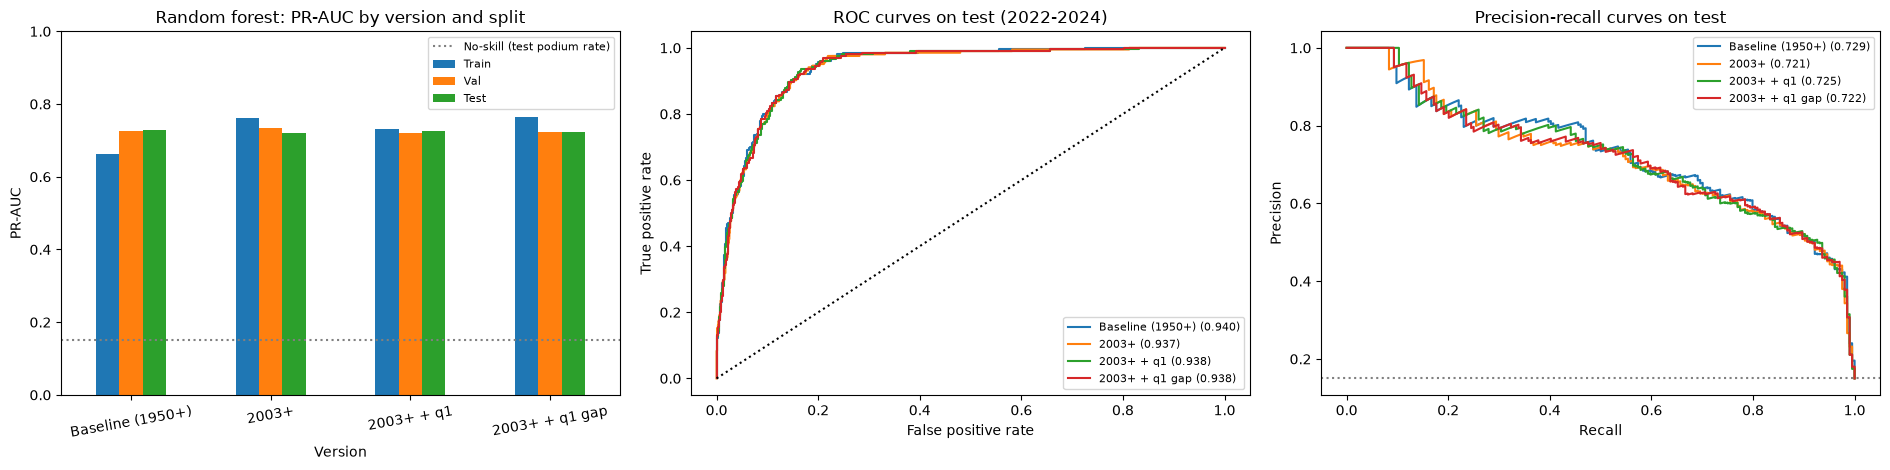

Best version on validation PR-AUC: 2003+. Its test confusion matrix:


,Predicted no podium,Predicted podium
Actual no podium,1028,127
Actual podium,36,168


In [320]:
rf_models, rf_probs, rf_thresholds = {}, {}, {}
for version, inputs in version_inputs.items():
    rf_models[version] = RandomForestClassifier(n_estimators=500, **rf_best_params[version], random_state=42,
                                                n_jobs=-1).fit(inputs["X"]["Train"], inputs["y"]["Train"])
    rf_probs[version] = {split: rf_models[version].predict_proba(inputs["X"][split])[:, 1] for split in SPLITS}
    rf_thresholds[version], _ = choose_threshold(inputs["y"]["Val"], rf_probs[version]["Val"])

rf_results, rf_best_version = compare_versions("Random forest", rf_probs, rf_thresholds)

def rf_predict_from_imputed(version):
    return lambda X: rf_models[version].predict_proba(np.asarray(X, dtype=float))[:, 1]

def rf_refit_val_test(version, features):
    inputs = build_version_inputs(version, features)
    forest = RandomForestClassifier(n_estimators=500, **rf_best_params[version], random_state=42, n_jobs=-1).fit(inputs["X"]["Train"], inputs["y"]["Train"])
    return inputs, {split: forest.predict_proba(inputs["X"][split])[:, 1] for split in SPLITS}

model_registry["Random forest"] = {"results": rf_results, "best_version": rf_best_version,
                                   "thresholds": rf_thresholds, "probs": rf_probs,
                                   "predict_from_imputed": rf_predict_from_imputed, "refit": rf_refit_val_test}

## 8.5 What the random forest results show

The tables and explanation below are generated from the current run.


In [321]:
report_model_results("Random forest", rf_results, rf_best_version, params=rf_best_params)
default_train_ap = average_precision_score(baseline_inputs["y"]["Train"], rf_default_probs["Train"])
default_val_ap = average_precision_score(baseline_inputs["y"]["Val"], rf_default_probs["Val"])
display(Markdown(f"The default baseline forest has training PR-AUC **{default_train_ap:.4f}** and validation "
                 f"PR-AUC **{default_val_ap:.4f}**, a gap of **{default_train_ap - default_val_ap:.4f}**. "
                 f"The tuning search evaluates **{len(rf_grid)} configurations per version**. "
                 "Selected settings and their scores are shown above; tuning does not guarantee the gap disappears."))


**Random forest: current-run results**

,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline (1950+),Train,0.32,0.9325,0.6614,0.6212,0.5523,0.7098
1,Baseline (1950+),Val,0.32,0.9295,0.7247,0.6980,0.6449,0.7607
2,Baseline (1950+),Test,0.32,0.9403,0.7291,0.6863,0.6015,0.7990
3,2003+,Train,0.63,0.9526,0.7618,0.6939,0.5886,0.8453
4,2003+,Val,0.63,0.9297,0.7344,0.7004,0.6429,0.7692
5,2003+,Test,0.63,0.9370,0.7214,0.6733,0.5695,0.8235
6,2003+ + q1,Train,0.26,0.9426,0.7326,0.6708,0.5616,0.8328
7,2003+ + q1,Val,0.26,0.9281,0.7192,0.6966,0.6200,0.7949
8,2003+ + q1,Test,0.26,0.9379,0.7246,0.6706,0.5566,0.8431
9,2003+ + q1 gap,Train,0.58,0.9536,0.7650,0.6890,0.5681,0.8754


Selected using validation: **2003+**, with validation PR-AUC **0.7344** and threshold **0.63**. Its test PR-AUC is **0.7214**, ROC-AUC **0.9370**, and F1 **0.6733**. The validation PR-AUC range across versions is **0.0151**. This observed range is not a statistical significance test.

Split,Test,Train,Val,Train minus validation,Validation minus test
Version,,,,,
2003+,0.7214,0.7618,0.7344,0.0274,0.0130
2003+ + q1,0.7246,0.7326,0.7192,0.0133,-0.0054
2003+ + q1 gap,0.7220,0.7650,0.7233,0.0417,0.0013
Baseline (1950+),0.7291,0.6614,0.7247,-0.0633,-0.0044


Positive train-minus-validation gaps indicate better training scores; era differences also affect these gaps. Use the curves and split scores together rather than declaring overfitting from one number.

At that threshold, the selected version identifies **168 of 204** test podiums and produces **127** false positives. No-skill test PR-AUC is the podium proportion: **0.1501**.

,max_depth,min_samples_leaf,max_features,class_weight
Version,,,,
Baseline (1950+),10,30,0.6,None
2003+,10,30,0.6,balanced_subsample
2003+ + q1,6,60,0.6,None
2003+ + q1 gap,10,30,0.6,balanced_subsample


The default baseline forest has training PR-AUC **1.0000** and validation PR-AUC **0.6472**, a gap of **0.3528**. The tuning search evaluates **64 configurations per version**. Selected settings and their scores are shown above; tuning does not guarantee the gap disappears.

# 9. Logistic Regression Model

## 9.1 How logistic regression works and why we use it

Logistic regression multiplies each scaled input by a learned weight, adds them up, and passes the sum through a sigmoid to get a probability between 0 and 1. It is the simplest reasonable model for a yes/no target, so it serves as our **baseline**: a more complex model is only worth it if it clearly beats this one.

- **Interpretable:** each weight shows the direction in which a feature moves the prediction, with the other features held fixed.
- **Regularisation:** `C` controls how strongly large weights are penalised (smaller `C` = stronger penalty).
- **Scaling:** inputs use each version's `StandardScaler`, so weights are comparable and the penalty treats features equally.
- **Limitations:** it can only draw a straight-line boundary in the inputs. A relationship such as "podium chances fall steeply over the first grid slots and then flatten" can only be approximated, and interactions are not learned unless built into the features.

## 9.2 Tune `C` and class weighting on validation

In [322]:
from sklearn.linear_model import LogisticRegression

lr_grid = list(product([0.001, 0.01, 0.1, 1, 10, 100], [None, "balanced"]))
lr_search_tables, lr_best_params = {}, {}
for version, inputs in version_inputs.items():
    trials = []
    for C, weight in lr_grid:
        model = LogisticRegression(C=C, class_weight=weight, max_iter=5000).fit(inputs["X_scaled"]["Train"], inputs["y"]["Train"])
        prob_val = model.predict_proba(inputs["X_scaled"]["Val"])[:, 1]
        trials.append({"C": C, "class_weight": weight,
                       "Val PR-AUC": average_precision_score(inputs["y"]["Val"], prob_val),
                       "Val ROC-AUC": roc_auc_score(inputs["y"]["Val"], prob_val)})
    trials = pd.DataFrame(trials).sort_values(["Val PR-AUC", "Val ROC-AUC"], ascending=False).reset_index(drop=True)
    lr_search_tables[version] = trials
    lr_best_params[version] = {"C": float(trials.iloc[0]["C"]),
                               "class_weight": None if pd.isna(trials.iloc[0]["class_weight"]) else trials.iloc[0]["class_weight"]}
    print(f"\n{version}: best settings {lr_best_params[version]}")
    display(trials.head(5).round(4))

/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.p


Baseline (1950+): best settings {'C': 10.0, 'class_weight': None}


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,C,class_weight,Val PR-AUC,Val ROC-AUC
0,10.0,None,0.7143,0.9222
1,1.0,None,0.7141,0.9221
2,0.1,None,0.7140,0.9222
3,100.0,None,0.7131,0.9222
4,100.0,balanced,0.7087,0.9213


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.p

...

,C,class_weight,Val PR-AUC,Val ROC-AUC
0,1.0,None,0.7122,0.9257
1,100.0,None,0.7118,0.9257
2,10.0,None,0.7117,0.9257
3,0.1,None,0.7097,0.9251
4,100.0,balanced,0.7061,0.9246


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



2003+ + q1 gap: best settings {'C': 1.0, 'class_weight': None}


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.p

,C,class_weight,Val PR-AUC,Val ROC-AUC
0,1.0,None,0.7088,0.9260
1,100.0,None,0.7079,0.9260
2,10.0,None,0.7078,0.9260
3,0.1,None,0.7072,0.9254
4,0.1,balanced,0.7022,0.9239


## 9.3 Final model for each version and comparison

/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Model,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Logistic regression,Baseline (1950+),Train,0.32,0.9051,0.5590,0.5770,0.5248,0.6409,0.8823
1,Logistic regression,Baseline (1950+),Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009,0.9038
2,Logistic regression,Baseline (1950+),Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402,0.8815
3,Logistic regression,2003+,Train,0.37,0.9280,0.6801,0.6670,0.6223,0.7186,0.8988
4,Logistic regression,2003+,Val,0.37,0.9259,0.7083,0.6987,0.7143,0.6838,0.9115
5,Logistic regression,2003+,Test,0.37,0.9351,0.7071,0.6437,0.6453,0.6422,0.8933
6,Logistic regression,2003+ + q1,Train,0.35,0.9281,0.6795,0.6689,0.6106,0.7394,0.8968
7,Logistic regression,2003+ + q1,Val,0.35,0.9257,0.7122,0.6983,0.7043,0.6923,0.9103
8,Logistic regression,2003+ + q1,Test,0.35,0.9349,0.7074,0.6464,0.6188,0.6765,0.8889
9,Logistic regression,2003+ + q1 gap,Train,0.37,0.9280,0.6800,0.6705,0.6253,0.7227,0.8999


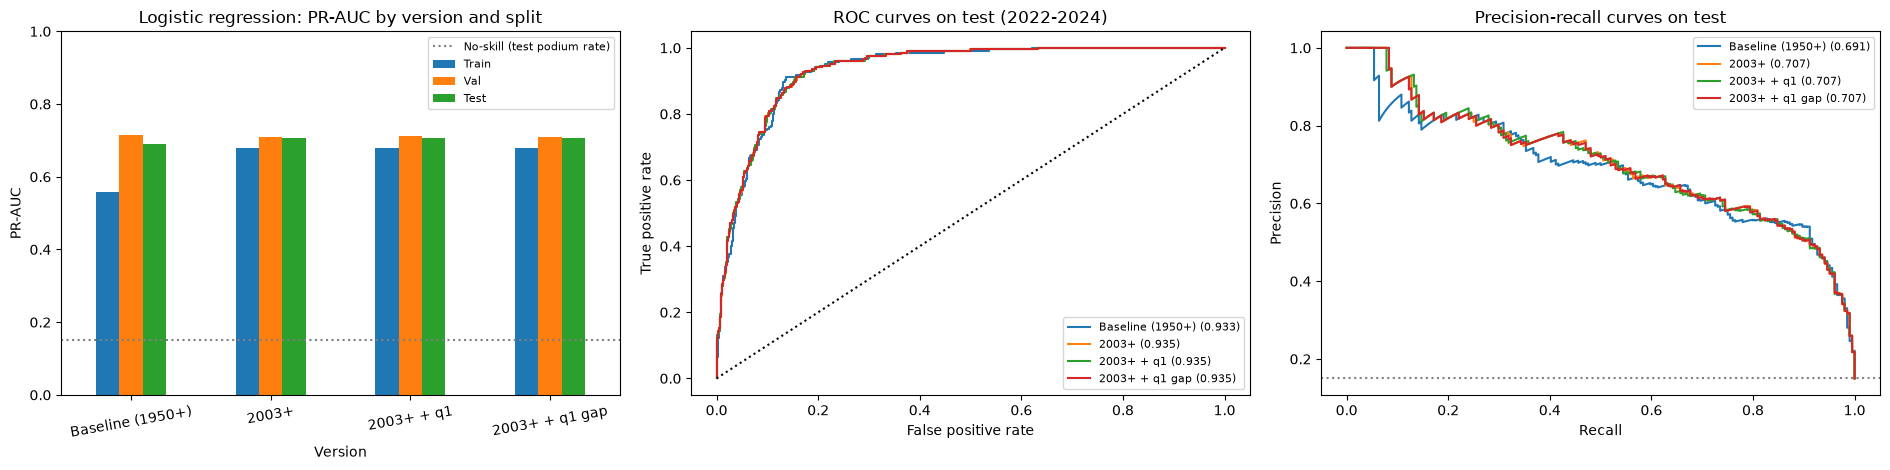

Best version on validation PR-AUC: Baseline (1950+). Its test confusion matrix:


,Predicted no podium,Predicted podium
Actual no podium,1047,108
Actual podium,53,151


In [323]:
lr_models, lr_probs, lr_thresholds = {}, {}, {}
for version, inputs in version_inputs.items():
    lr_models[version] = LogisticRegression(**lr_best_params[version], max_iter=5000).fit(inputs["X_scaled"]["Train"], inputs["y"]["Train"])
    lr_probs[version] = {split: lr_models[version].predict_proba(inputs["X_scaled"][split])[:, 1] for split in SPLITS}
    lr_thresholds[version], _ = choose_threshold(inputs["y"]["Val"], lr_probs[version]["Val"])

lr_results, lr_best_version = compare_versions("Logistic regression", lr_probs, lr_thresholds)

def lr_predict_from_imputed(version):
    model, scaler = lr_models[version], version_inputs[version]["scaler"]
    return lambda X: model.predict_proba(scaler.transform(np.asarray(X, dtype=float)))[:, 1]

def lr_refit_val_test(version, features):
    inputs = build_version_inputs(version, features)
    model = LogisticRegression(**lr_best_params[version], max_iter=5000).fit(inputs["X_scaled"]["Train"], inputs["y"]["Train"])
    return inputs, {split: model.predict_proba(inputs["X_scaled"][split])[:, 1] for split in SPLITS}

model_registry["Logistic regression"] = {"results": lr_results, "best_version": lr_best_version,
                                         "thresholds": lr_thresholds, "probs": lr_probs,
                                         "predict_from_imputed": lr_predict_from_imputed, "refit": lr_refit_val_test}

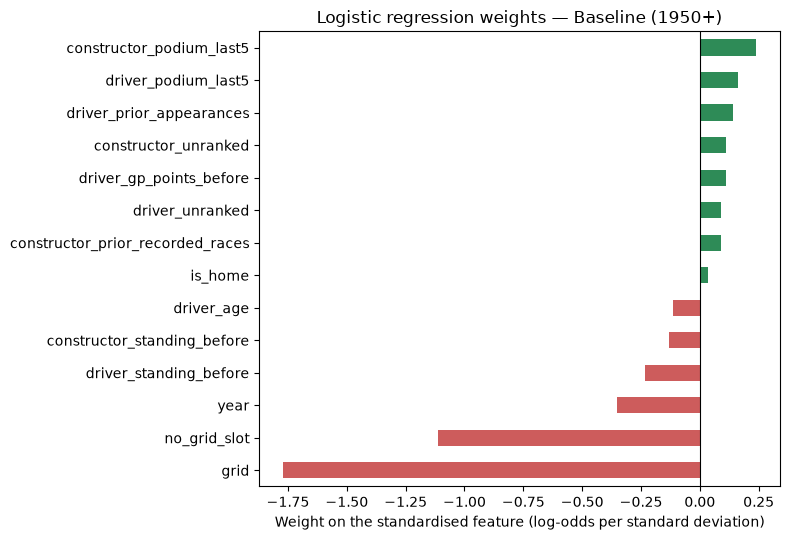

In [324]:
# Weights of the best version: direction of each feature's effect in the model (scaled inputs).
lr_weights = pd.Series(lr_models[lr_best_version].coef_[0], index=version_inputs[lr_best_version]["features"]).sort_values()
ax = lr_weights.plot.barh(figsize=(8, 5.5), color=np.where(lr_weights > 0, "seagreen", "indianred"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Weight on the standardised feature (log-odds per standard deviation)")
ax.set_title(f"Logistic regression weights — {lr_best_version}")
plt.tight_layout(); plt.show()

## 9.4 What the logistic regression results show

The tables and explanation below are generated from the current run.


In [325]:
report_model_results("Logistic regression", lr_results, lr_best_version, params=lr_best_params)
print("Largest absolute weights for the selected LR version (standardized-input log-odds coefficients):")
display(lr_weights.reindex(lr_weights.abs().sort_values(ascending=False).index).head(5).to_frame("Weight"))
print("Positive weights raise the model's log-odds; negative weights lower them. They are not causal effects.")


**Logistic regression: current-run results**

,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline (1950+),Train,0.32,0.9051,0.5590,0.5770,0.5248,0.6409
1,Baseline (1950+),Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009
2,Baseline (1950+),Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402
3,2003+,Train,0.37,0.9280,0.6801,0.6670,0.6223,0.7186
4,2003+,Val,0.37,0.9259,0.7083,0.6987,0.7143,0.6838
5,2003+,Test,0.37,0.9351,0.7071,0.6437,0.6453,0.6422
6,2003+ + q1,Train,0.35,0.9281,0.6795,0.6689,0.6106,0.7394
7,2003+ + q1,Val,0.35,0.9257,0.7122,0.6983,0.7043,0.6923
8,2003+ + q1,Test,0.35,0.9349,0.7074,0.6464,0.6188,0.6765
9,2003+ + q1 gap,Train,0.37,0.9280,0.6800,0.6705,0.6253,0.7227


Selected using validation: **Baseline (1950+)**, with validation PR-AUC **0.7143** and threshold **0.32**. Its test PR-AUC is **0.6912**, ROC-AUC **0.9334**, and F1 **0.6523**. The validation PR-AUC range across versions is **0.0060**. This observed range is not a statistical significance test.

Split,Test,Train,Val,Train minus validation,Validation minus test
Version,,,,,
2003+,0.7071,0.6801,0.7083,-0.0281,0.0012
2003+ + q1,0.7074,0.6795,0.7122,-0.0327,0.0048
2003+ + q1 gap,0.7067,0.6800,0.7088,-0.0288,0.0021
Baseline (1950+),0.6912,0.5590,0.7143,-0.1553,0.0231


Positive train-minus-validation gaps indicate better training scores; era differences also affect these gaps. Use the curves and split scores together rather than declaring overfitting from one number.

At that threshold, the selected version identifies **151 of 204** test podiums and produces **108** false positives. No-skill test PR-AUC is the podium proportion: **0.1501**.

,C,class_weight
Version,,
Baseline (1950+),10.0,None
2003+,10.0,None
2003+ + q1,1.0,None
2003+ + q1 gap,1.0,None


Largest absolute weights for the selected LR version (standardized-input log-odds coefficients):


,Weight
grid,-1.771757
no_grid_slot,-1.110670
year,-0.351496
constructor_podium_last5,0.239980
driver_standing_before,-0.233090


Positive weights raise the model's log-odds; negative weights lower them. They are not causal effects.


# 10. Earlier experiments: model comparison and ablation

## 10.1 Best version of each model

For each model we take the version with the highest **validation** PR-AUC and show its validation and test scores side by side. The overall model used for this earlier ablation is the one with the highest validation PR-AUC; test scores are reported but not used to choose.

,Model,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Neural network,Baseline (1950+),Val,0.30,0.9321,0.7410,0.7036,0.6544,0.7607,0.9038
1,Neural network,Baseline (1950+),Test,0.30,0.9362,0.6956,0.6639,0.5782,0.7794,0.8815
2,Random forest,2003+,Val,0.63,0.9297,0.7344,0.7004,0.6429,0.7692,0.9013
3,Random forest,2003+,Test,0.63,0.9370,0.7214,0.6733,0.5695,0.8235,0.8801
4,Logistic regression,Baseline (1950+),Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009,0.9038
5,Logistic regression,Baseline (1950+),Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402,0.8815


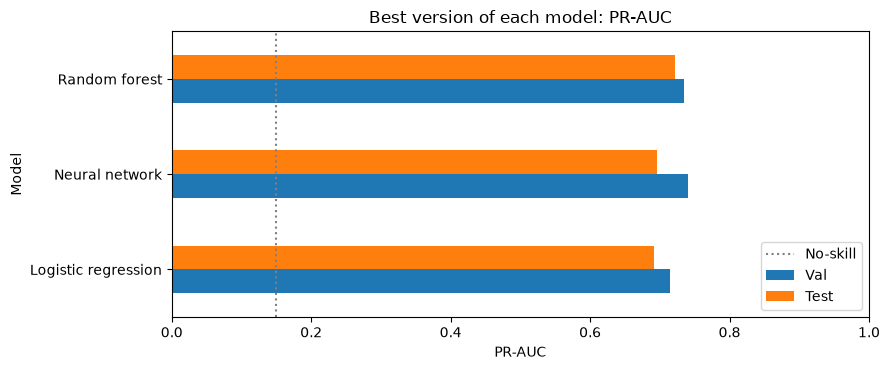

Chosen on validation PR-AUC for the earlier ablation: Neural network — Baseline (1950+)


In [326]:
summary_rows = []
for model_name, entry in model_registry.items():
    table = entry["results"]
    for split in ["Val", "Test"]:
        row = table[(table["Version"] == entry["best_version"]) & (table["Split"] == split)].iloc[0]
        summary_rows.append(row)
model_summary = pd.DataFrame(summary_rows).reset_index(drop=True)
with pd.option_context("display.width", 220):
    display(model_summary.round(4))

summary_plot = model_summary.pivot(index="Model", columns="Split", values="PR-AUC")[["Val", "Test"]]
ax = summary_plot.plot.barh(figsize=(9, 3.8))
ax.axvline(version_inputs["Baseline (1950+)"]["y"]["Test"].mean(), color="grey", linestyle=":", label="No-skill")
ax.set_xlabel("PR-AUC"); ax.set_xlim(0, 1); ax.legend(loc="lower right")
ax.set_title("Best version of each model: PR-AUC")
plt.tight_layout(); plt.show()

val_summary = model_summary[model_summary["Split"] == "Val"].sort_values(["PR-AUC", "ROC-AUC"], ascending=False)
chosen_model = val_summary.iloc[0]["Model"]
chosen_version = val_summary.iloc[0]["Version"]
chosen_entry = model_registry[chosen_model]
chosen_inputs = version_inputs[chosen_version]
chosen_predict = chosen_entry["predict_from_imputed"](chosen_version)
print(f"Chosen on validation PR-AUC for the earlier ablation: {chosen_model} — {chosen_version}")

## 10.2 Feature-group ablation

We remove **one group of related features at a time**, retrain the chosen model with the same settings on the same version, and measure the change in PR-AUC. The drop is measured on validation; the test drop is shown for information only. A large drop means the model relies on that group; a drop near zero means the remaining features cover the same information.

All features — Val PR-AUC 0.7410, Test PR-AUC 0.6956


,Features removed,Val PR-AUC,Val drop,Test PR-AUC (info),Test drop (info)
Group removed,,,,,
Grid,"grid, no_grid_slot",0.6361,0.1049,0.5399,0.1557
Championship standings,"driver_standing_before, constructor_standing_before, driver_unranked, constructor_unranked, driver_gp_points_before",0.7121,0.0289,0.7019,-0.0063
Recent form,"driver_podium_last5, constructor_podium_last5",0.7314,0.0096,0.7045,-0.0088
Context,"is_home, year",0.7386,0.0024,0.6868,0.0088
Experience and age,"driver_age, driver_prior_appearances, constructor_prior_recorded_races",0.7426,-0.0017,0.6889,0.0067


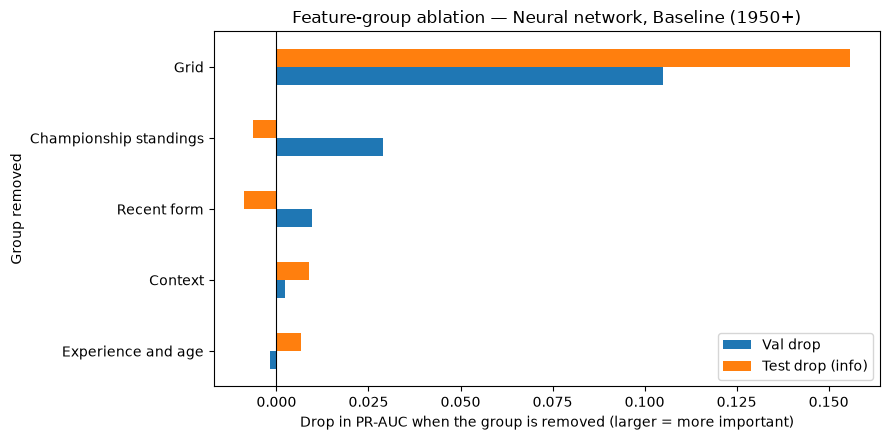

In [327]:
feature_groups = {
    "Grid": ["grid", "no_grid_slot"],
    "Championship standings": ["driver_standing_before", "constructor_standing_before", "driver_unranked",
                               "constructor_unranked", "driver_gp_points_before"],
    "Recent form": ["driver_podium_last5", "constructor_podium_last5"],
    "Experience and age": ["driver_age", "driver_prior_appearances", "constructor_prior_recorded_races"],
    "Context": ["is_home", "year"],
    "Qualifying": ["q1", "q1_relative_gap"],
}
chosen_features = chosen_inputs["features"]
full_inputs, full_probs = chosen_entry["refit"](chosen_version, chosen_features)
full_scores = {split: average_precision_score(full_inputs["y"][split], full_probs[split]) for split in ["Val", "Test"]}
ablation_rows = []
for group, columns in feature_groups.items():
    removed = [c for c in columns if c in chosen_features]
    if not removed:
        continue
    kept = [c for c in chosen_features if c not in removed]
    inputs, probs = chosen_entry["refit"](chosen_version, kept)
    scores = {split: average_precision_score(inputs["y"][split], probs[split]) for split in ["Val", "Test"]}
    ablation_rows.append({"Group removed": group, "Features removed": ", ".join(removed),
                          "Val PR-AUC": scores["Val"], "Val drop": full_scores["Val"] - scores["Val"],
                          "Test PR-AUC (info)": scores["Test"], "Test drop (info)": full_scores["Test"] - scores["Test"]})
ablation_table = pd.DataFrame(ablation_rows).sort_values("Val drop", ascending=False).set_index("Group removed")
print(f"All features — Val PR-AUC {full_scores['Val']:.4f}, Test PR-AUC {full_scores['Test']:.4f}")
with pd.option_context("display.max_colwidth", None, "display.width", 220):
    display(ablation_table.round(4))
ax = ablation_table[["Val drop", "Test drop (info)"]].sort_values("Val drop").plot.barh(figsize=(9, 4.5))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop in PR-AUC when the group is removed (larger = more important)")
ax.set_title(f"Feature-group ablation — {chosen_model}, {chosen_version}")
plt.tight_layout(); plt.show()

## 10.3 Interpretation of the earlier experiments

In [328]:
display(Markdown("**Current-run model comparison**"))
display(model_summary.round(4))
validation_leader = model_summary.loc[model_summary["Split"].eq("Val")].sort_values(
    ["PR-AUC", "ROC-AUC"], ascending=False).iloc[0]
test_leader = model_summary.loc[model_summary["Split"].eq("Test")].sort_values(
    ["PR-AUC", "ROC-AUC"], ascending=False).iloc[0]
display(Markdown(
    f"Validation selects **{chosen_model} — {chosen_version}** (PR-AUC **{validation_leader['PR-AUC']:.4f}**). "
    f"The highest reported test PR-AUC belongs to **{test_leader['Model']} — {test_leader['Version']}** "
    f"at **{test_leader['PR-AUC']:.4f}**. Test results describe performance and do not change the selection. "
    "These are each model's selected versions; versions can differ in training years and feature lists."))

display(Markdown(f"**Feature-group ablation: {chosen_model} — {chosen_version}**"))
display(ablation_table.round(4))
for group, row in ablation_table.iterrows():
    change = row["Val drop"]
    meaning = "lowered" if change > 0 else ("raised" if change < 0 else "did not change")
    print(f"Removing {group} {meaning} validation PR-AUC by {abs(change):.4f} "
          f"(full {full_scores['Val']:.4f}; without group {row['Val PR-AUC']:.4f}).")
print("Ablation describes retrained models; small changes are not evidence of statistical significance.")



**Current-run model comparison**

,Model,Version,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Neural network,Baseline (1950+),Val,0.30,0.9321,0.7410,0.7036,0.6544,0.7607,0.9038
1,Neural network,Baseline (1950+),Test,0.30,0.9362,0.6956,0.6639,0.5782,0.7794,0.8815
2,Random forest,2003+,Val,0.63,0.9297,0.7344,0.7004,0.6429,0.7692,0.9013
3,Random forest,2003+,Test,0.63,0.9370,0.7214,0.6733,0.5695,0.8235,0.8801
4,Logistic regression,Baseline (1950+),Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009,0.9038
5,Logistic regression,Baseline (1950+),Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402,0.8815


Validation selects **Neural network — Baseline (1950+)** (PR-AUC **0.7410**). The highest reported test PR-AUC belongs to **Random forest — 2003+** at **0.7214**. Test results describe performance and do not change the selection. These are each model's selected versions; versions can differ in training years and feature lists.

**Feature-group ablation: Neural network — Baseline (1950+)**

,Features removed,Val PR-AUC,Val drop,Test PR-AUC (info),Test drop (info)
Group removed,,,,,
Grid,"grid, no_grid_slot",0.6361,0.1049,0.5399,0.1557
Championship standings,"driver_standing_before, constructor_standing_b...",0.7121,0.0289,0.7019,-0.0063
Recent form,"driver_podium_last5, constructor_podium_last5",0.7314,0.0096,0.7045,-0.0088
Context,"is_home, year",0.7386,0.0024,0.6868,0.0088
Experience and age,"driver_age, driver_prior_appearances, construc...",0.7426,-0.0017,0.6889,0.0067


Removing Grid lowered validation PR-AUC by 0.1049 (full 0.7410; without group 0.6361).
Removing Championship standings lowered validation PR-AUC by 0.0289 (full 0.7410; without group 0.7121).
Removing Recent form lowered validation PR-AUC by 0.0096 (full 0.7410; without group 0.7314).
Removing Context lowered validation PR-AUC by 0.0024 (full 0.7410; without group 0.7386).
Removing Experience and age raised validation PR-AUC by 0.0017 (full 0.7410; without group 0.7426).
Ablation describes retrained models; small changes are not evidence of statistical significance.


# 11. Final

All three final models use **E3's 14 features** and the **1950+ version**: train on 1950–2019, validate on 2020–2021, and test on 2022–2024. The earlier year-range experiments remain above for comparison.

For each model, first retrain using all 14 features. Then start again from the full feature set and remove **one group at a time**. Removals are independent, not cumulative. We refit preprocessing on the training rows for every experiment. The forest and logistic regression use the settings selected earlier for **Baseline (1950+)**; the network uses the same architecture and early-stopping rule as before. Settings are held fixed across group removals.

**Accuracy** is the fraction of drivers classified correctly. We show train, validation and test accuracy immediately after each experiment, then compare all experiments for that model. The comparison also shows validation and test PR-AUC drops beside accuracy drops, with a separate PR-AUC-drop chart. Validation PR-AUC is the primary measure of group contribution; test differences are descriptive. We also report PR-AUC, ROC-AUC, F1, precision and recall because most drivers do not finish on the podium, and high accuracy alone can be misleading.

Each model's probability threshold is chosen by validation F1 on its full 14-feature model and then held fixed for that model's ablations. This makes accuracy differences reflect retraining after feature removal rather than a changed cutoff. Test results are descriptive; they do not select settings or feature groups. For both accuracy and PR-AUC, drop = full-feature score minus score after removal. Positive drops mean removing the group hurt performance; negative drops mean it improved performance in this run. Accuracy drops are in percentage points; PR-AUC drops remain on the original 0–1 score scale.

The earlier exploratory feature experiments justify the inputs before this final training stage. These ablations measure what each group contributes after retraining. Small differences from a single run do not establish statistical significance.

## 11.1 Feature groups and experiment setup

Qualifying lap times (`q1` and `q1_relative_gap`) are absent from E3, so there is no qualifying-time removal here. Grid is its own group. Every E3 feature belongs to exactly one group.

In [329]:
FINAL_VERSION = "Baseline (1950+)"
final_features = list(features_e3)
final_groups = {
    "Grid": ["grid", "no_grid_slot"],
    "Championship standings": ["driver_standing_before", "constructor_standing_before",
                               "driver_unranked", "constructor_unranked", "driver_gp_points_before"],
    "Recent form": ["driver_podium_last5", "constructor_podium_last5"],
    "Experience and age": ["driver_age", "driver_prior_appearances", "constructor_prior_recorded_races"],
    "Context": ["is_home", "year"],
}
listed_features = [feature for group in final_groups.values() for feature in group]
assert len(final_features) == 14
assert len(listed_features) == len(set(listed_features)) == 14
assert set(listed_features) == set(final_features)
final_experiments = {"All 14 features": final_features}
final_experiments.update({f"Without {group}": [f for f in final_features if f not in columns]
                          for group, columns in final_groups.items()})
display(pd.DataFrame([{"Group": group, "Count": len(columns), "Features": ", ".join(columns)}
                      for group, columns in final_groups.items()]))
display(version_summary.loc[[FINAL_VERSION]])
final_runs, final_tables = {}, {}

def run_final_model(model_name):
    runs, rows = {}, []
    threshold = None
    for experiment, features in final_experiments.items():
        inputs = build_version_inputs(FINAL_VERSION, features)
        for split in SPLITS:
            assert inputs["rows"][split].equals(version_inputs[FINAL_VERSION]["rows"][split])
        if model_name == "Neural network":
            model, history, probs = train_nn(inputs)
        elif model_name == "Random forest":
            model = RandomForestClassifier(n_estimators=500, **rf_best_params[FINAL_VERSION],
                                           random_state=42, n_jobs=-1)
            model.fit(inputs["X"]["Train"], inputs["y"]["Train"])
            probs = {s: model.predict_proba(inputs["X"][s])[:, 1] for s in SPLITS}
        elif model_name == "Logistic regression":
            model = LogisticRegression(**lr_best_params[FINAL_VERSION], max_iter=5000)
            model.fit(inputs["X_scaled"]["Train"], inputs["y"]["Train"])
            probs = {s: model.predict_proba(inputs["X_scaled"][s])[:, 1] for s in SPLITS}
        else:
            raise ValueError(model_name)
        if threshold is None:
            threshold, _ = choose_threshold(inputs["y"]["Val"], probs["Val"])
        scores = [{"Model": model_name, "Experiment": experiment, "Features": len(features),
                   "Split": s, "Threshold": threshold,
                   **podium_metrics(inputs["y"][s], probs[s], threshold)} for s in SPLITS]
        rows.extend(scores)
        runs[experiment] = {"model": model, "inputs": inputs, "probs": probs, "threshold": threshold}
        display(Markdown(f"**{model_name}: {experiment} ({len(features)} features)**"))
        display(pd.DataFrame(scores)[["Split", "Features", "Threshold", "Accuracy", "PR-AUC",
                                       "ROC-AUC", "F1", "Precision", "Recall"]].round(4))
    final_runs[model_name] = runs
    final_tables[model_name] = pd.DataFrame(rows)

def compare_final_ablation(model_name):
    table = final_tables[model_name]
    accuracy = table.pivot(index="Experiment", columns="Split", values="Accuracy").reindex(final_experiments)[SPLITS]
    comparison = (accuracy * 100).rename(columns={s: f"{s} accuracy (%)" for s in SPLITS})
    comparison["Features"] = [len(final_experiments[e]) for e in comparison.index]
    for split in ["Val", "Test"]:
        comparison[f"{split} accuracy drop (percentage points)"] = (
            accuracy.loc["All 14 features", split] - accuracy[split]) * 100
    pr_auc = table.pivot(index="Experiment", columns="Split", values="PR-AUC").reindex(final_experiments)[SPLITS]
    for split in ["Val", "Test"]:
        comparison[f"{split} PR-AUC"] = pr_auc[split]
        comparison[f"{split} PR-AUC drop"] = pr_auc.loc["All 14 features", split] - pr_auc[split]
    display(Markdown(f"**{model_name}: accuracy and PR-AUC comparison across all feature groups**"))
    display(comparison.round(4))
    print("Drop = full-feature score minus score without the group. Positive means worse after removal; negative means better.")
    print("Accuracy drops use percentage points. PR-AUC drops use the original 0–1 score scale; validation PR-AUC is primary.")
    ax = (accuracy * 100).plot.barh(figsize=(11, 5), xlim=(0, 100))
    y_test = final_runs[model_name]["All 14 features"]["inputs"]["y"]["Test"]
    ax.axvline((y_test == 0).mean() * 100, color="grey", linestyle=":", label="Always no podium (test)")
    ax.set_xlabel("Accuracy (%)"); ax.set_ylabel("Feature experiment")
    ax.set_title(f"{model_name}: 1950+ training, independent E3 group removals")
    ax.legend(loc="lower left"); plt.tight_layout(); plt.show()
    drop_columns = ["Val PR-AUC drop", "Test PR-AUC drop"]
    ax = comparison.loc[accuracy.index[1:], drop_columns].plot.barh(figsize=(11, 5))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("PR-AUC drop after removing the group (full minus ablated)")
    ax.set_ylabel("Feature experiment")
    ax.set_title(f"{model_name}: PR-AUC contribution of each E3 group")
    plt.tight_layout(); plt.show()
    for experiment in accuracy.index[1:]:
        pr_drop = comparison.loc[experiment, "Val PR-AUC drop"]
        if pr_drop == 0:
            print(f"{experiment}: validation PR-AUC is unchanged from all 14 features.")
        else:
            pr_direction = "lower" if pr_drop > 0 else "higher"
            print(f"{experiment}: validation PR-AUC is {abs(pr_drop):.4f} {pr_direction} than all 14 features.")
        drop = comparison.loc[experiment, "Val accuracy drop (percentage points)"]
        direction = "lower" if drop > 0 else ("higher" if drop < 0 else "unchanged")
        if drop == 0:
            print("Validation accuracy is unchanged from all 14 features.")
        else:
            print(f"Validation accuracy is {abs(drop):.3f} percentage points {direction} than all 14 features.")
    print("All metrics for every experiment and split:")
    display(table.round(4))


,Group,Count,Features
0,Grid,2,"grid, no_grid_slot"
1,Championship standings,5,"driver_standing_before, constructor_standing_b..."
2,Recent form,2,"driver_podium_last5, constructor_podium_last5"
3,Experience and age,3,"driver_age, driver_prior_appearances, construc..."
4,Context,2,"is_home, year"


,Training seasons,Features,Train rows,Train podium rate,Val rows,Test rows,Q1 missing in train (%)
Version,,,,,,,
Baseline (1950+),1950-2019,14,24529,0.125321,780,1359,NaN


## 11.2 Neural network

Train all 14 features first, then retrain separately after removing each group.

In [330]:
run_final_model('Neural network')

**Neural network: All 14 features (14 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,14,0.3,0.8745,0.5972,0.9167,0.5946,0.4994,0.7345
1,Val,14,0.3,0.9038,0.7410,0.9321,0.7036,0.6544,0.7607
2,Test,14,0.3,0.8815,0.6956,0.9362,0.6639,0.5782,0.7794


**Neural network: Without Grid (12 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.3,0.8417,0.4886,0.8746,0.5283,0.4216,0.7072
1,Val,12,0.3,0.8474,0.6361,0.8924,0.5966,0.4944,0.7521
2,Test,12,0.3,0.8190,0.5399,0.8906,0.5669,0.4423,0.7892


**Neural network: Without Championship standings (9 features)**

...

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.3,0.8713,0.5899,0.9141,0.5924,0.4910,0.7466
1,Val,12,0.3,0.8962,0.7314,0.9337,0.6848,0.6286,0.7521
2,Test,12,0.3,0.8801,0.7045,0.9345,0.6495,0.5785,0.7402


**Neural network: Without Experience and age (11 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,11,0.3,0.8720,0.5817,0.9123,0.5877,0.4927,0.7280
1,Val,11,0.3,0.9000,0.7426,0.9312,0.6953,0.6403,0.7607
2,Test,11,0.3,0.8808,0.6889,0.9370,0.6798,0.5695,0.8431


**Neural network: Without Context (12 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.3,0.8710,0.5854,0.9126,0.5882,0.4902,0.7352
1,Val,12,0.3,0.8885,0.7386,0.9271,0.6766,0.5987,0.7778
2,Test,12,0.3,0.8683,0.6868,0.9336,0.6590,0.5389,0.8480


**Neural network: accuracy and PR-AUC comparison across all feature groups**

Split,Train accuracy (%),Val accuracy (%),Test accuracy (%),Features,Val accuracy drop (percentage points),Test accuracy drop (percentage points),Val PR-AUC,Val PR-AUC drop,Test PR-AUC,Test PR-AUC drop
Experiment,,,,,,,,,,
All 14 features,87.4475,90.3846,88.1531,14,0.0000,0.0000,0.7410,0.0000,0.6956,0.0000
Without Grid,84.1738,84.7436,81.8985,12,5.6410,6.2546,0.6361,0.1049,0.5399,0.1557
Without Championship standings,87.0643,89.6154,87.4908,9,0.7692,0.6623,0.7121,0.0289,0.7019,-0.0063
Without Recent form,87.1254,89.6154,88.0059,12,0.7692,0.1472,0.7314,0.0096,0.7045,-0.0088
Without Experience and age,87.1988,90.0000,88.0795,11,0.3846,0.0736,0.7426,-0.0017,0.6889,0.0067
Without Context,87.1010,88.8462,86.8286,12,1.5385,1.3245,0.7386,0.0024,0.6868,0.0088


Drop = full-feature score minus score without the group. Positive means worse after removal; negative means better.
Accuracy drops use percentage points. PR-AUC drops use the original 0–1 score scale; validation PR-AUC is primary.


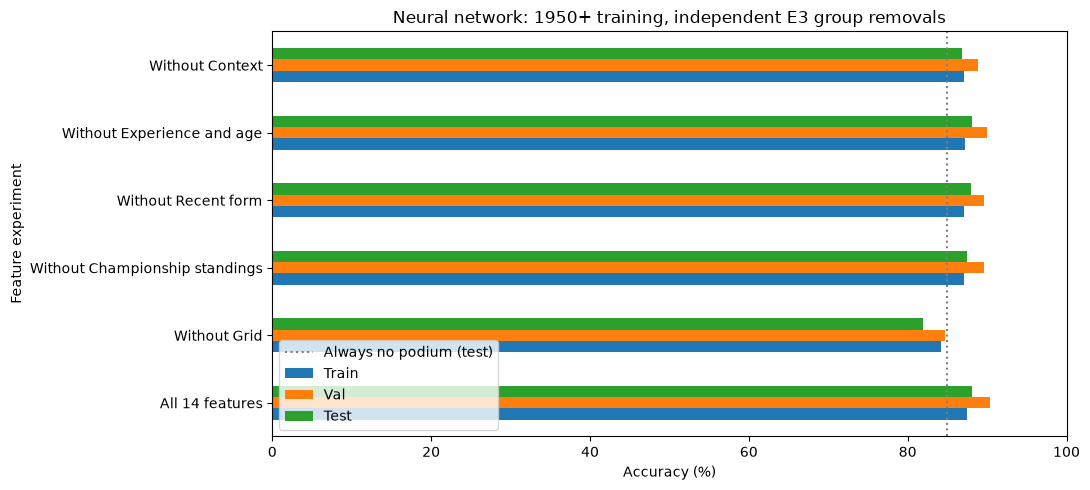

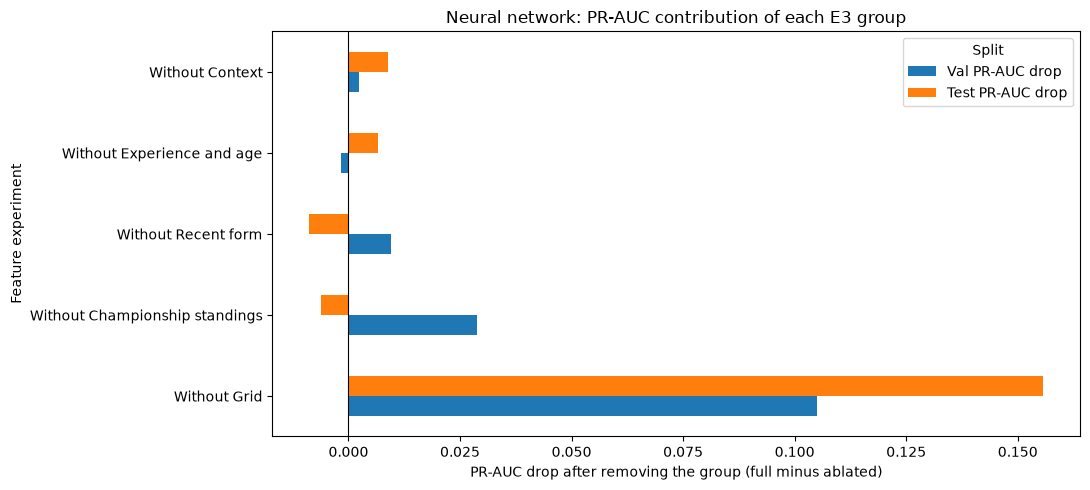

Without Grid: validation PR-AUC is 0.1049 lower than all 14 features.
Validation accuracy is 5.641 percentage points lower than all 14 features.
Without Championship standings: validation PR-AUC is 0.0289 lower than all 14 features.
Validation accuracy is 0.769 percentage points lower than all 14 features.
Without Recent form: validation PR-AUC is 0.0096 lower than all 14 features.
Validation accuracy is 0.769 percentage points lower than all 14 features.
Without Experience and age: validation PR-AUC is 0.0017 higher than all 14 features.
Validation accuracy is 0.385 percentage points lower than all 14 features.
Without Context: validation PR-AUC is 0.0024 lower than all 14 features.
Validation accuracy is 1.538 percentage points lower than all 14 features.
All metrics for every experiment and split:


,Model,Experiment,Features,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Neural network,All 14 features,14,Train,0.3,0.9167,0.5972,0.5946,0.4994,0.7345,0.8745
1,Neural network,All 14 features,14,Val,0.3,0.9321,0.7410,0.7036,0.6544,0.7607,0.9038
2,Neural network,All 14 features,14,Test,0.3,0.9362,0.6956,0.6639,0.5782,0.7794,0.8815
3,Neural network,Without Grid,12,Train,0.3,0.8746,0.4886,0.5283,0.4216,0.7072,0.8417
4,Neural network,Without Grid,12,Val,0.3,0.8924,0.6361,0.5966,0.4944,0.7521,0.8474
5,Neural network,Without Grid,12,Test,0.3,0.8906,0.5399,0.5669,0.4423,0.7892,0.8190
6,Neural network,Without Championship standings,9,Train,0.3,0.9120,0.5843,0.5868,0.4893,0.7329,0.8706
7,Neural network,Without Championship standings,9,Val,0.3,0.9276,0.7121,0.6873,0.6268,0.7607,0.8962
8,Neural network,Without Championship standings,9,Test,0.3,0.9347,0.7019,0.6559,0.5586,0.7941,0.8749
9,Neural network,Without Recent form,12,Train,0.3,0.9141,0.5899,0.5924,0.4910,0.7466,0.8713


In [331]:
compare_final_ablation('Neural network')

## 11.3 Random forest

Train all 14 features first, then retrain separately after removing each group.

In [332]:
run_final_model('Random forest')

**Random forest: All 14 features (14 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,14,0.32,0.8915,0.6614,0.9325,0.6212,0.5523,0.7098
1,Val,14,0.32,0.9013,0.7247,0.9295,0.6980,0.6449,0.7607
2,Test,14,0.32,0.8904,0.7291,0.9403,0.6863,0.6015,0.7990


**Random forest: Without Grid (12 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.32,0.8804,0.5920,0.9082,0.5760,0.5183,0.6480
1,Val,12,0.32,0.8667,0.6398,0.8878,0.6338,0.5389,0.7692
2,Test,12,0.32,0.8411,0.5750,0.9008,0.5894,0.4814,0.7598


**Random forest: Without Championship standings (9 features)**

...

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.32,0.8918,0.6590,0.9317,0.6199,0.5536,0.7043
1,Val,12,0.32,0.8974,0.7212,0.9275,0.6825,0.6370,0.7350
2,Test,12,0.32,0.8889,0.7290,0.9373,0.6753,0.6015,0.7696


**Random forest: Without Experience and age (11 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,11,0.32,0.8887,0.6411,0.9272,0.6098,0.5437,0.6942
1,Val,11,0.32,0.9000,0.7298,0.9289,0.6829,0.6512,0.7179
2,Test,11,0.32,0.8837,0.7175,0.9396,0.6653,0.5858,0.7696


**Random forest: Without Context (12 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.32,0.8911,0.6578,0.9307,0.6186,0.5511,0.7049
1,Val,12,0.32,0.9000,0.6898,0.9282,0.6953,0.6403,0.7607
2,Test,12,0.32,0.8874,0.7228,0.9399,0.6806,0.5927,0.7990


**Random forest: accuracy and PR-AUC comparison across all feature groups**

Split,Train accuracy (%),Val accuracy (%),Test accuracy (%),Features,Val accuracy drop (percentage points),Test accuracy drop (percentage points),Val PR-AUC,Val PR-AUC drop,Test PR-AUC,Test PR-AUC drop
Experiment,,,,,,,,,,
All 14 features,89.1516,90.1282,89.0361,14,0.0000,0.0000,0.7247,0.0000,0.7291,0.0000
Without Grid,88.0427,86.6667,84.1060,12,3.4615,4.9301,0.6398,0.0849,0.5750,0.1541
Without Championship standings,89.0415,90.3846,88.4474,9,-0.2564,0.5887,0.7017,0.0230,0.7186,0.0105
Without Recent form,89.1761,89.7436,88.8889,12,0.3846,0.1472,0.7212,0.0035,0.7290,0.0001
Without Experience and age,88.8662,90.0000,88.3738,11,0.1282,0.6623,0.7298,-0.0051,0.7175,0.0117
Without Context,89.1068,90.0000,88.7417,12,0.1282,0.2943,0.6898,0.0348,0.7228,0.0063


Drop = full-feature score minus score without the group. Positive means worse after removal; negative means better.
Accuracy drops use percentage points. PR-AUC drops use the original 0–1 score scale; validation PR-AUC is primary.


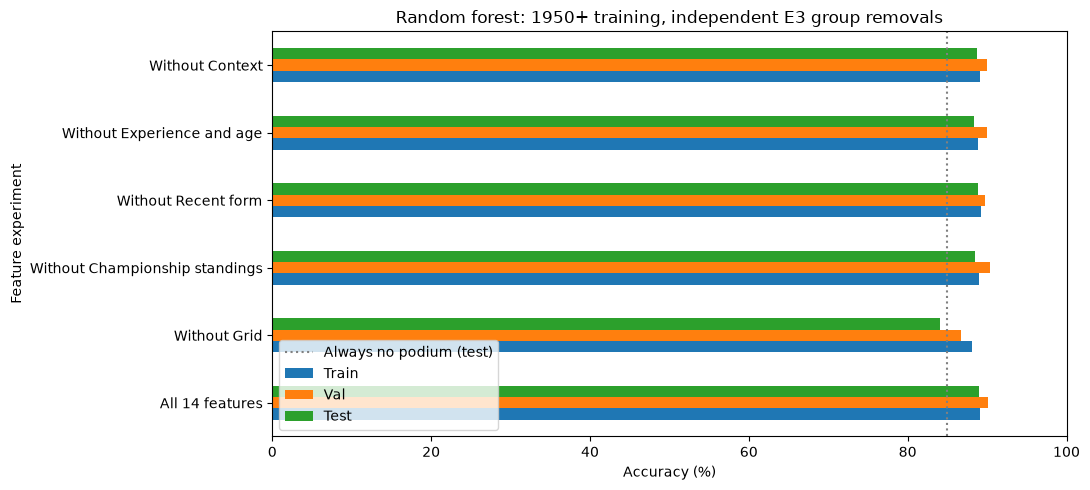

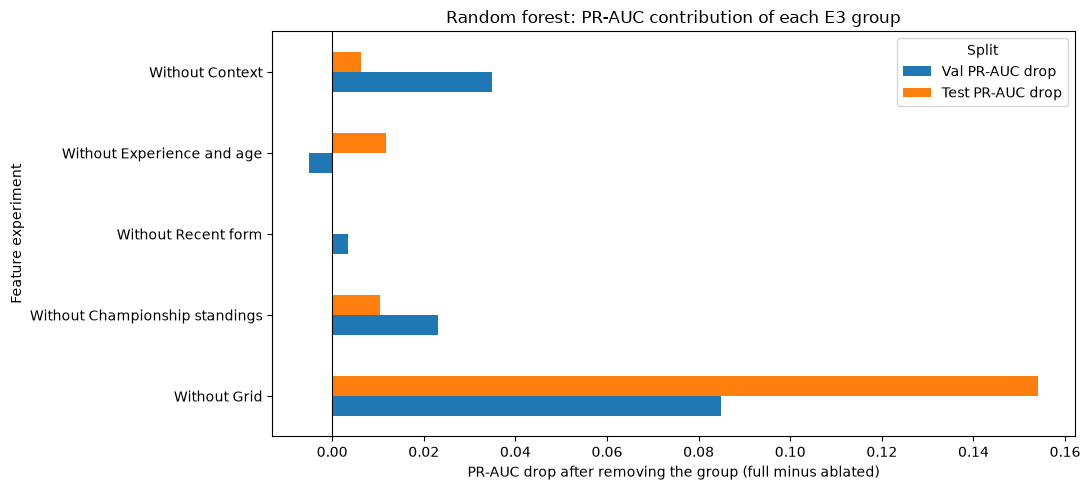

Without Grid: validation PR-AUC is 0.0849 lower than all 14 features.
Validation accuracy is 3.462 percentage points lower than all 14 features.
Without Championship standings: validation PR-AUC is 0.0230 lower than all 14 features.
Validation accuracy is 0.256 percentage points higher than all 14 features.
Without Recent form: validation PR-AUC is 0.0035 lower than all 14 features.
Validation accuracy is 0.385 percentage points lower than all 14 features.
Without Experience and age: validation PR-AUC is 0.0051 higher than all 14 features.
Validation accuracy is 0.128 percentage points lower than all 14 features.
Without Context: validation PR-AUC is 0.0348 lower than all 14 features.
Validation accuracy is 0.128 percentage points lower than all 14 features.
All metrics for every experiment and split:


,Model,Experiment,Features,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Random forest,All 14 features,14,Train,0.32,0.9325,0.6614,0.6212,0.5523,0.7098,0.8915
1,Random forest,All 14 features,14,Val,0.32,0.9295,0.7247,0.6980,0.6449,0.7607,0.9013
2,Random forest,All 14 features,14,Test,0.32,0.9403,0.7291,0.6863,0.6015,0.7990,0.8904
3,Random forest,Without Grid,12,Train,0.32,0.9082,0.5920,0.5760,0.5183,0.6480,0.8804
4,Random forest,Without Grid,12,Val,0.32,0.8878,0.6398,0.6338,0.5389,0.7692,0.8667
5,Random forest,Without Grid,12,Test,0.32,0.9008,0.5750,0.5894,0.4814,0.7598,0.8411
6,Random forest,Without Championship standings,9,Train,0.32,0.9297,0.6518,0.6183,0.5486,0.7082,0.8904
7,Random forest,Without Championship standings,9,Val,0.32,0.9254,0.7017,0.7059,0.6522,0.7692,0.9038
8,Random forest,Without Championship standings,9,Test,0.32,0.9366,0.7186,0.6749,0.5842,0.7990,0.8845
9,Random forest,Without Recent form,12,Train,0.32,0.9317,0.6590,0.6199,0.5536,0.7043,0.8918


In [333]:
compare_final_ablation('Random forest')

## 11.4 Logistic regression

Train all 14 features first, then retrain separately after removing each group.

In [334]:
run_final_model('Logistic regression')

/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


**Logistic regression: All 14 features (14 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,14,0.32,0.8823,0.5590,0.9051,0.5770,0.5248,0.6409
1,Val,14,0.32,0.9038,0.7143,0.9222,0.6862,0.6721,0.7009
2,Test,14,0.32,0.8815,0.6912,0.9334,0.6523,0.5830,0.7402


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


**Logistic regression: Without Grid (12 features)**

...

**Logistic regression: Without Experience and age (11 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,11,0.32,0.8830,0.5581,0.9045,0.5775,0.5273,0.6383
1,Val,11,0.32,0.9026,0.7117,0.9228,0.6807,0.6694,0.6923
2,Test,11,0.32,0.8837,0.6952,0.9332,0.6504,0.5927,0.7206


/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


**Logistic regression: Without Context (12 features)**

,Split,Features,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Train,12,0.32,0.8834,0.5608,0.9032,0.5772,0.5288,0.6353
1,Val,12,0.32,0.9000,0.7053,0.9221,0.6880,0.6466,0.7350
2,Test,12,0.32,0.8815,0.7025,0.9329,0.6653,0.5776,0.7843


**Logistic regression: accuracy and PR-AUC comparison across all feature groups**

Split,Train accuracy (%),Val accuracy (%),Test accuracy (%),Features,Val accuracy drop (percentage points),Test accuracy drop (percentage points),Val PR-AUC,Val PR-AUC drop,Test PR-AUC,Test PR-AUC drop
Experiment,,,,,,,,,,
All 14 features,88.2262,90.3846,88.1531,14,0.0000,0.0000,0.7143,0.0000,0.6912,0.0000
Without Grid,87.3782,89.6154,85.1361,12,0.7692,3.0169,0.6275,0.0868,0.5506,0.1406
Without Championship standings,88.1610,90.3846,89.4776,9,0.0000,-1.3245,0.7031,0.0112,0.6958,-0.0046
Without Recent form,87.8144,88.0769,87.4172,12,2.3077,0.7358,0.6950,0.0193,0.6564,0.0349
Without Experience and age,88.2955,90.2564,88.3738,11,0.1282,-0.2208,0.7117,0.0027,0.6952,-0.0040
Without Context,88.3363,90.0000,88.1531,12,0.3846,0.0000,0.7053,0.0091,0.7025,-0.0113


Drop = full-feature score minus score without the group. Positive means worse after removal; negative means better.
Accuracy drops use percentage points. PR-AUC drops use the original 0–1 score scale; validation PR-AUC is primary.


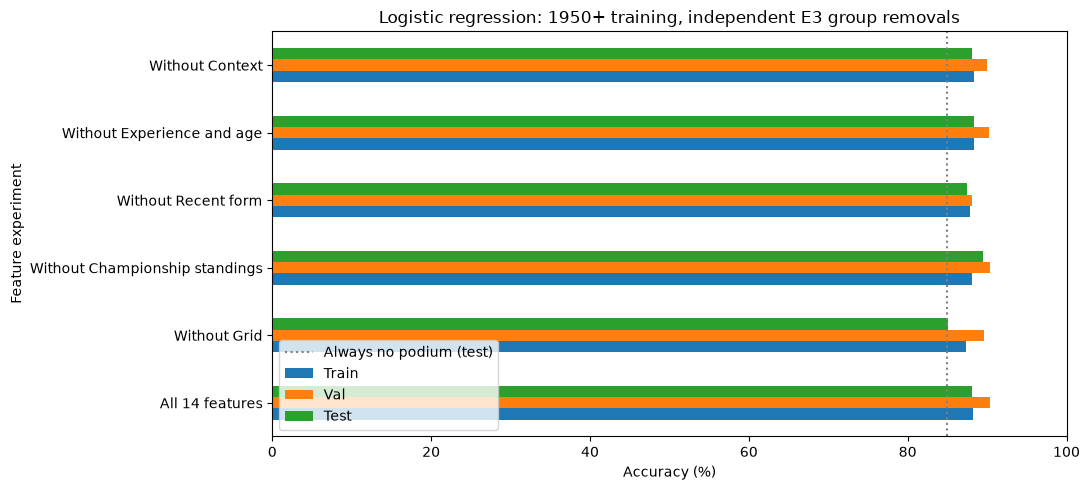

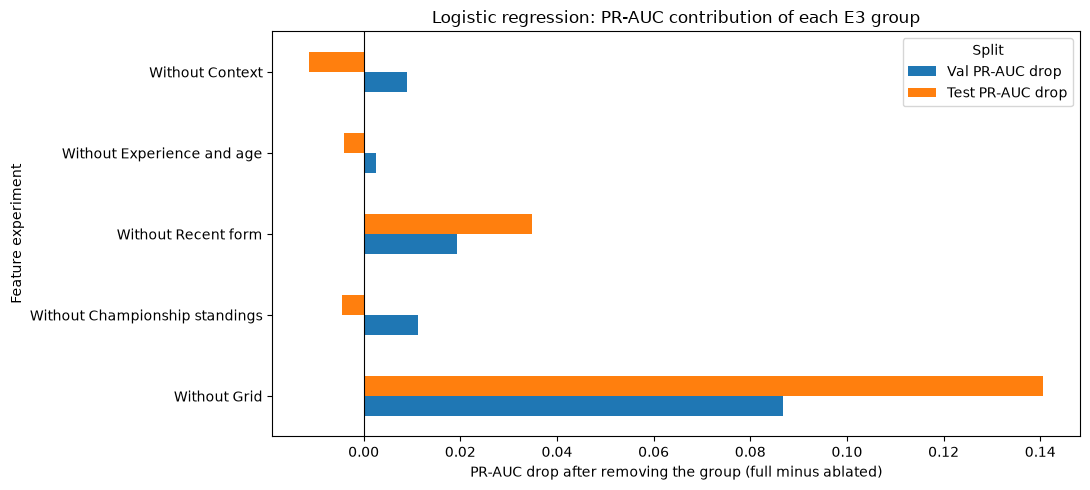

Without Grid: validation PR-AUC is 0.0868 lower than all 14 features.
Validation accuracy is 0.769 percentage points lower than all 14 features.
Without Championship standings: validation PR-AUC is 0.0112 lower than all 14 features.
Validation accuracy is unchanged from all 14 features.
Without Recent form: validation PR-AUC is 0.0193 lower than all 14 features.
Validation accuracy is 2.308 percentage points lower than all 14 features.
Without Experience and age: validation PR-AUC is 0.0027 lower than all 14 features.
Validation accuracy is 0.128 percentage points lower than all 14 features.
Without Context: validation PR-AUC is 0.0091 lower than all 14 features.
Validation accuracy is 0.385 percentage points lower than all 14 features.
All metrics for every experiment and split:


,Model,Experiment,Features,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Logistic regression,All 14 features,14,Train,0.32,0.9051,0.5590,0.5770,0.5248,0.6409,0.8823
1,Logistic regression,All 14 features,14,Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009,0.9038
2,Logistic regression,All 14 features,14,Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402,0.8815
3,Logistic regression,Without Grid,12,Train,0.32,0.8635,0.4760,0.5006,0.4965,0.5049,0.8738
4,Logistic regression,Without Grid,12,Val,0.32,0.8913,0.6275,0.6494,0.6579,0.6410,0.8962
5,Logistic regression,Without Grid,12,Test,0.32,0.8942,0.5506,0.5702,0.5038,0.6569,0.8514
6,Logistic regression,Without Championship standings,9,Train,0.32,0.9037,0.5533,0.5721,0.5229,0.6314,0.8816
7,Logistic regression,Without Championship standings,9,Val,0.32,0.9209,0.7031,0.6862,0.6721,0.7009,0.9038
8,Logistic regression,Without Championship standings,9,Test,0.32,0.9322,0.6958,0.6843,0.6225,0.7598,0.8948
9,Logistic regression,Without Recent form,12,Train,0.32,0.9007,0.5465,0.5738,0.5108,0.6545,0.8781


In [335]:
compare_final_ablation('Logistic regression')

## 11.5 Compare the three full-feature final models

This comparison uses the newly trained **all-14-feature** models on the same 1950+ training data. The XAI model is selected by validation PR-AUC (ROC-AUC breaks ties). Ablation and test scores do not change this selection.

,Model,Experiment,Features,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
0,Neural network,All 14 features,14,Train,0.30,0.9167,0.5972,0.5946,0.4994,0.7345,0.8745
1,Neural network,All 14 features,14,Val,0.30,0.9321,0.7410,0.7036,0.6544,0.7607,0.9038
2,Neural network,All 14 features,14,Test,0.30,0.9362,0.6956,0.6639,0.5782,0.7794,0.8815
3,Random forest,All 14 features,14,Train,0.32,0.9325,0.6614,0.6212,0.5523,0.7098,0.8915
4,Random forest,All 14 features,14,Val,0.32,0.9295,0.7247,0.6980,0.6449,0.7607,0.9013
5,Random forest,All 14 features,14,Test,0.32,0.9403,0.7291,0.6863,0.6015,0.7990,0.8904
6,Logistic regression,All 14 features,14,Train,0.32,0.9051,0.5590,0.5770,0.5248,0.6409,0.8823
7,Logistic regression,All 14 features,14,Val,0.32,0.9222,0.7143,0.6862,0.6721,0.7009,0.9038
8,Logistic regression,All 14 features,14,Test,0.32,0.9334,0.6912,0.6523,0.5830,0.7402,0.8815


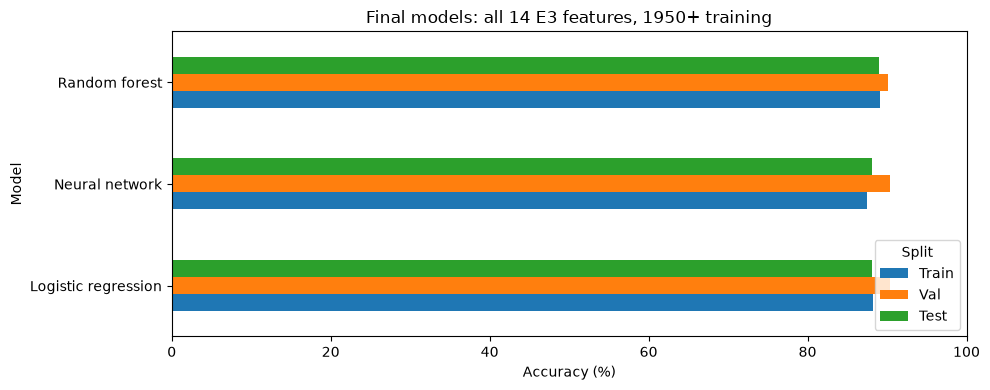

Selected for XAI using validation PR-AUC: Neural network (0.7410).


In [336]:
final_summary = pd.concat([table.loc[table["Experiment"].eq("All 14 features")]
                           for table in final_tables.values()], ignore_index=True)
display(final_summary.round(4))
final_accuracy = final_summary.pivot(index="Model", columns="Split", values="Accuracy")[SPLITS] * 100
ax = final_accuracy.plot.barh(figsize=(10, 4), xlim=(0, 100))
ax.set_xlabel("Accuracy (%)"); ax.set_title("Final models: all 14 E3 features, 1950+ training")
plt.tight_layout(); plt.show()
final_leader = final_summary.loc[final_summary["Split"].eq("Val")].sort_values(
    ["PR-AUC", "ROC-AUC"], ascending=False).iloc[0]
print(f"Selected for XAI using validation PR-AUC: {final_leader['Model']} ({final_leader['PR-AUC']:.4f}).")


## 11.6 Inference — use the selected model for one record

Inference means using an already trained model to make a prediction. We use the **full 14-feature model selected by validation PR-AUC in section 11.5**, with its existing imputer, scaler and validation-chosen threshold.

**What goes in:** a dictionary or Series containing E3 feature values, in their original units before imputation/scaling. These include engineered pre-race values such as recent form and standings. A driver ID alone is not enough: this function does not fetch data or construct race history. It accepts only the 14 feature names; results, target labels and identity fields stay outside the function.

**What happens:** put the features in their training order → fill missing inputs using the fitted training-set imputer → apply the fitted scaler for NN/LR → predict. The forest uses imputed values directly. Nothing is fitted again. An omitted feature, `None` or `NaN` means missing; unknown feature names, invalid text, infinite values and a record with no observed inputs are rejected.

**What comes out:** podium probability, the saved decision threshold, a podium/no-podium prediction, and which inputs were filled. Filled values are estimates from training data, not recovered facts. Probabilities are model estimates, not guarantees.

The demonstrations below use the first complete test record in chronological dataset order, without selecting by actual result or predicted probability. We then hide two inputs in a copy. This is a demonstration of using the model, not a new model-selection experiment.

In [337]:
from collections.abc import Mapping

inference_model_name = str(final_leader["Model"])
inference_bundle = final_runs[inference_model_name]["All 14 features"]
inference_features = tuple(inference_bundle["inputs"]["features"])
assert len(inference_features) == 14

def predict_podium(record):
    """Predict one record of unscaled E3 features using the selected fitted model."""
    if isinstance(record, pd.Series):
        if not record.index.is_unique:
            raise ValueError("Feature names must be unique.")
        record = record.to_dict()
    if not isinstance(record, Mapping):
        raise TypeError("Supply a dictionary or pandas Series of E3 feature values.")
    unknown = set(record) - set(inference_features)
    if unknown:
        raise ValueError(f"Unknown inputs: {sorted(unknown, key=str)}. Supply only E3 features.")
    row = pd.DataFrame([dict(record)]).reindex(columns=inference_features)
    try:
        row = row.apply(pd.to_numeric, errors="raise").astype(float)
    except (TypeError, ValueError) as error:
        raise ValueError("Inputs must be numeric; use None/NaN or omit an unavailable feature.") from error
    if np.isinf(row.to_numpy()).any():
        raise ValueError("Infinite values are not valid inputs.")
    missing = row.columns[row.iloc[0].isna()].tolist()
    if len(missing) == len(inference_features):
        raise ValueError("Supply at least one observed feature value.")
    inputs = inference_bundle["inputs"]
    imputed = inputs["imputer"].transform(row)
    model = inference_bundle["model"]
    if inference_model_name == "Random forest":
        probability = float(model.predict_proba(imputed)[0, 1])
    else:
        scaled = inputs["scaler"].transform(imputed)
        if inference_model_name == "Neural network":
            probability = float(model(scaled, training=False).numpy().ravel()[0])
        elif inference_model_name == "Logistic regression":
            probability = float(model.predict_proba(scaled)[0, 1])
        else:
            raise ValueError(f"Unsupported model: {inference_model_name}")
    threshold = float(inference_bundle["threshold"])
    filled_values = {feature: float(imputed[0, inference_features.index(feature)]) for feature in missing}
    return {"Model": inference_model_name, "Podium probability": probability,
            "Threshold": threshold, "Prediction": "Podium" if probability >= threshold else "No podium",
            "Missing inputs": missing, "Filled values": filled_values}

print("Selected model:", inference_model_name)
print("Expected inputs:", list(inference_features))


Selected model: Neural network
Expected inputs: ['grid', 'no_grid_slot', 'driver_age', 'driver_prior_appearances', 'driver_podium_last5', 'constructor_prior_recorded_races', 'constructor_podium_last5', 'driver_gp_points_before', 'is_home', 'year', 'driver_standing_before', 'constructor_standing_before', 'driver_unranked', 'constructor_unranked']


### Example A — a complete record from the test set

We copy the first test row with all 14 inputs. Only those features are passed to `predict_podium`. Driver/race details are displayed for identification. The actual result is retrieved separately after prediction for comparison.

In [338]:
inference_test = inference_bundle["inputs"]["raw"]["Test"]
inference_test_before = inference_test.copy(deep=True)
complete_rows = inference_test.dropna()
assert not complete_rows.empty, "No complete test record is available for this demonstration."
inference_example_index = complete_rows.index[0]
complete_record = complete_rows.loc[inference_example_index].to_dict()

example_identity = model_df.loc[inference_example_index, ["raceId", "driverId", "date"]]
example_driver = drivers_clean.set_index("driverId").loc[example_identity["driverId"]]
example_race = races_clean.set_index("raceId").loc[example_identity["raceId"]]
print(f"{example_driver['forename']} {example_driver['surname']} — "
      f"{int(example_race['year'])} {example_race['name']}")
display(pd.Series(complete_record, name="Supplied value").to_frame())

complete_prediction = predict_podium(complete_record)
display(pd.DataFrame([{k: complete_prediction[k] for k in
    ["Model", "Podium probability", "Threshold", "Prediction"]}]).round(4))
actual_example_label = int(model_df.loc[inference_example_index, target])
actual_example_outcome = "Podium" if actual_example_label == 1 else "No podium"
print("Actual recorded outcome (not supplied to the function):", actual_example_outcome)


Lewis Hamilton — 2022 Bahrain Grand Prix


,Supplied value
grid,5.000000
no_grid_slot,0.000000
driver_age,37.197205
driver_prior_appearances,288.000000
driver_podium_last5,1.000000
constructor_prior_recorded_races,249.000000
constructor_podium_last5,0.700000
driver_gp_points_before,0.000000
is_home,0.000000
year,2022.000000


,Model,Podium probability,Threshold,Prediction
0,Neural network,0.547,0.3,Podium


Actual recorded outcome (not supplied to the function): Podium


### Example B — the same record with two inputs missing

We copy Example A, omit `driver_age`, and set `driver_podium_last5` to `NaN`. Both are recognized as missing. The table shows the original values, the incomplete inputs and the training-set median values actually substituted. No source data is edited.

,Complete record,Partially missing record,After fitted imputer,Filled?
grid,5.0000,5.0,5.0000,False
no_grid_slot,0.0000,0.0,0.0000,False
driver_age,37.1972,NaN,29.5831,True
driver_prior_appearances,288.0000,288.0,288.0000,False
driver_podium_last5,1.0000,NaN,0.0000,True
constructor_prior_recorded_races,249.0000,249.0,249.0000,False
constructor_podium_last5,0.7000,0.7,0.7000,False
driver_gp_points_before,0.0000,0.0,0.0000,False
is_home,0.0000,0.0,0.0000,False
year,2022.0000,2022.0,2022.0000,False


Inputs filled: {'driver_age': 29.583085210510824, 'driver_podium_last5': 0.0}


,Example,Model,Missing inputs,Podium probability,Threshold,Prediction,Actual outcome
0,Complete record,Neural network,None,0.5470,0.3,Podium,Podium
1,Partially missing record,Neural network,"driver_age, driver_podium_last5",0.2953,0.3,No podium,Podium


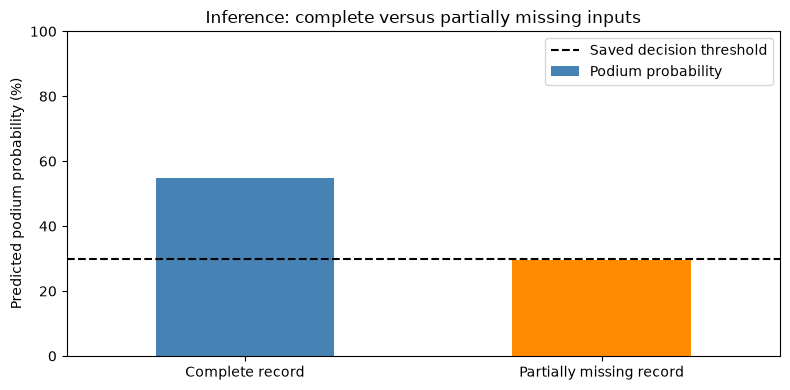

Hiding these two inputs changed the predicted probability by -25.17 percentage points.
The missing-input prediction uses training-set estimates. This one example does not establish general accuracy or robustness.
Verified: complete prediction matches evaluation, both missing inputs handled, original test inputs preserved.


In [339]:
partial_record = complete_record.copy()
partial_record.pop("driver_age")
partial_record["driver_podium_last5"] = np.nan
partial_prediction = predict_podium(partial_record)

supplied_partial = pd.Series(partial_record).reindex(inference_features)
prepared_partial = supplied_partial.copy()
for feature, value in partial_prediction["Filled values"].items():
    prepared_partial.loc[feature] = value
input_comparison = pd.DataFrame({
    "Complete record": pd.Series(complete_record).reindex(inference_features),
    "Partially missing record": supplied_partial,
    "After fitted imputer": prepared_partial,
    "Filled?": [f in partial_prediction["Missing inputs"] for f in inference_features]
})
display(input_comparison.round(4))
print("Inputs filled:", partial_prediction["Filled values"])

inference_comparison = pd.DataFrame([
    {"Example": label, "Model": result["Model"], "Missing inputs": ", ".join(result["Missing inputs"]) or "None",
     "Podium probability": result["Podium probability"], "Threshold": result["Threshold"],
     "Prediction": result["Prediction"], "Actual outcome": actual_example_outcome}
    for label, result in [("Complete record", complete_prediction), ("Partially missing record", partial_prediction)]
])
display(inference_comparison.round(4))
ax = (inference_comparison.set_index("Example")["Podium probability"] * 100).plot.bar(
    figsize=(8, 4), rot=0, color=["steelblue", "darkorange"], ylim=(0, 100))
ax.axhline(complete_prediction["Threshold"] * 100, color="black", linestyle="--", label="Saved decision threshold")
ax.set_ylabel("Predicted podium probability (%)")
ax.set_xlabel(""); ax.set_title("Inference: complete versus partially missing inputs")
ax.legend(); plt.tight_layout(); plt.show()

change = (partial_prediction["Podium probability"] - complete_prediction["Podium probability"]) * 100
print(f"Hiding these two inputs changed the predicted probability by {change:+.2f} percentage points.")
print("The missing-input prediction uses training-set estimates. This one example does not establish general accuracy or robustness.")

# Confirm that the complete-record function agrees with the existing test prediction.
example_test_position = inference_test.index.get_loc(inference_example_index)
np.testing.assert_allclose(complete_prediction["Podium probability"],
    inference_bundle["probs"]["Test"][example_test_position], rtol=1e-5, atol=1e-6)
assert complete_prediction["Missing inputs"] == []
assert set(partial_prediction["Missing inputs"]) == {"driver_age", "driver_podium_last5"}
pd.testing.assert_frame_equal(inference_test, inference_test_before)
assert all(0 <= r["Podium probability"] <= 1 for r in [complete_prediction, partial_prediction])
print("Verified: complete prediction matches evaluation, both missing inputs handled, original test inputs preserved.")


# 12. XAI — Explainable AI

These explanations refer to the final, full E3 model selected in section 11.5, trained on 1950–2019. Permutation importance and global SHAP describe what the fitted model uses. Local SHAP and LIME explain the same single prediction from two methods; the preceding ablations show the effect of retraining with a group removed.

In [340]:
chosen_model = final_leader["Model"]
chosen_version = FINAL_VERSION
chosen_run = final_runs[chosen_model]["All 14 features"]
chosen_inputs = chosen_run["inputs"]
chosen_features = chosen_inputs["features"]
chosen_entry = {"thresholds": {chosen_version: chosen_run["threshold"]}}

def chosen_predict(X):
    values = np.asarray(X, dtype=float)
    model = chosen_run["model"]
    if chosen_model == "Random forest":
        return model.predict_proba(values)[:, 1]
    scaled = chosen_inputs["scaler"].transform(values)
    if chosen_model == "Neural network":
        return model(scaled, training=False).numpy().ravel()
    return model.predict_proba(scaled)[:, 1]

assert chosen_features == final_features
np.testing.assert_allclose(chosen_predict(chosen_inputs["X"]["Val"]),
                           chosen_run["probs"]["Val"], rtol=1e-5, atol=1e-6)
print(f"Explaining {chosen_model}: {chosen_version}, {len(chosen_features)} E3 features.")


Explaining Neural network: Baseline (1950+), 14 E3 features.


## 12.1 Global explanation: permutation importance

For each single feature, its values in the validation rows are shuffled 20 times and the drop in validation PR-AUC is averaged. Unlike ablation, the model is not retrained, so this shows what the **trained** model relies on. Features that carry the same information can share importance, and `year` can score near zero because every validation row is later than every training row.

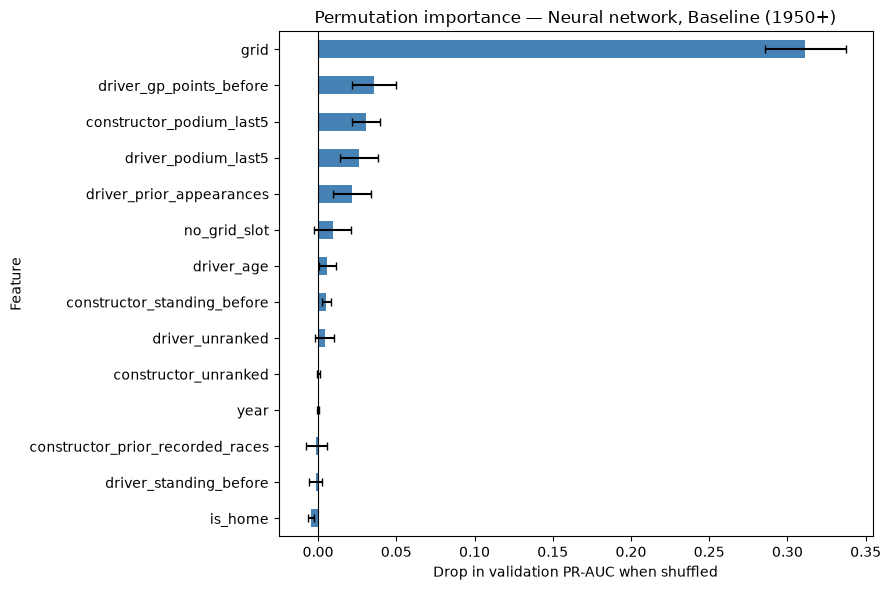

,PR-AUC drop,Spread
Feature,,
grid,0.3114,0.0257
driver_gp_points_before,0.0359,0.0141
constructor_podium_last5,0.0307,0.0087
driver_podium_last5,0.0263,0.0123
driver_prior_appearances,0.0218,0.0122
no_grid_slot,0.0095,0.0118
driver_age,0.0059,0.0055
constructor_standing_before,0.0052,0.0029
driver_unranked,0.0042,0.0061


In [341]:
def permutation_drop(predict, X, y, features, repeats=20, seed=42):
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, predict(X))
    rows = []
    for j, feature in enumerate(features):
        drops = []
        for _ in range(repeats):
            shuffled = X.copy()
            shuffled[:, j] = rng.permutation(shuffled[:, j])
            drops.append(base - average_precision_score(y, predict(shuffled)))
        rows.append({"Feature": feature, "PR-AUC drop": np.mean(drops), "Spread": np.std(drops)})
    return pd.DataFrame(rows).set_index("Feature").sort_values("PR-AUC drop")

permutation_table = permutation_drop(chosen_predict, chosen_inputs["X"]["Val"], chosen_inputs["y"]["Val"], chosen_features)
ax = permutation_table["PR-AUC drop"].plot.barh(xerr=permutation_table["Spread"], figsize=(9, 6), color="steelblue", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop in validation PR-AUC when shuffled")
ax.set_title(f"Permutation importance — {chosen_model}, {chosen_version}")
plt.tight_layout(); plt.show()
display(permutation_table.sort_values("PR-AUC drop", ascending=False).round(4))

## 12.2 Global explanation: SHAP

SHAP splits each prediction into a contribution from every feature, relative to the model's average prediction. The summary plot shows, for 300 validation rows, how high (red) and low (blue) values of each feature push the podium probability up or down. A model-agnostic explainer is used so the same code works for whichever model was chosen; 100 training rows serve as the background.

/private/tmp/acl-notebook-run-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PermutationExplainer explainer:  60%|██████    | 181/300 [00:00<?, ?it/s]

PermutationExplainer explainer:  61%|██████▏   | 184/300 [00:10<00:04, 27.74it/s]

PermutationExplainer explainer:  62%|██████▏   | 187/300 [00:10<00:05, 21.88it/s]

PermutationExplainer explainer:  63%|██████▎   | 190/300 [00:10<00:05, 20.32it/s]

...

PermutationExplainer explainer:  98%|█████████▊| 295/300 [00:16<00:00, 17.67it/s]

PermutationExplainer explainer:  99%|█████████▉| 297/300 [00:16<00:00, 17.08it/s]

PermutationExplainer explainer: 100%|█████████▉| 299/300 [00:16<00:00, 17.26it/s]

PermutationExplainer explainer: 301it [00:16, 17.48it/s]                         

PermutationExplainer explainer: 301it [00:16,  7.20it/s]

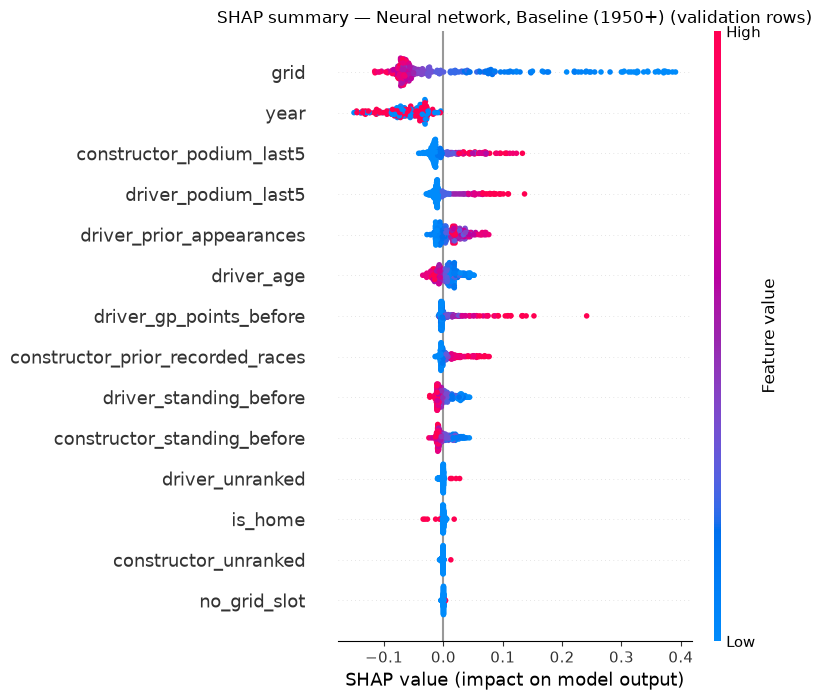

In [342]:
import shap

shap_background = pd.DataFrame(chosen_inputs["X"]["Train"], columns=chosen_features).sample(100, random_state=42)
shap_rows = pd.DataFrame(chosen_inputs["X"]["Val"], columns=chosen_features).sample(300, random_state=42)
shap_explainer = shap.Explainer(lambda X: chosen_predict(np.asarray(X, dtype=float)),
                                shap.maskers.Independent(shap_background), feature_names=chosen_features)
shap_values = shap_explainer(shap_rows)
shap.plots.beeswarm(shap_values, max_display=len(chosen_features), show=False)
plt.title(f"SHAP summary — {chosen_model}, {chosen_version} (validation rows)")
plt.tight_layout(); plt.show()

## 12.3 Local explanation: one prediction

We explain a single validation prediction: the driver with the highest predicted podium probability among those who actually finished on the podium. The SHAP waterfall starts from the model's average output and adds each feature's contribution for this one driver. Section 12.4 uses LIME on the same driver and prediction.

Lewis Hamilton, 2021 Saudi Arabian Grand Prix: predicted podium probability 0.92, actual result: podium


,Input value
grid,1.000000
no_grid_slot,0.000000
driver_age,36.909724
driver_prior_appearances,286.000000
driver_podium_last5,0.800000
constructor_prior_recorded_races,247.000000
constructor_podium_last5,0.600000
driver_gp_points_before,341.500000
is_home,0.000000
year,2021.000000


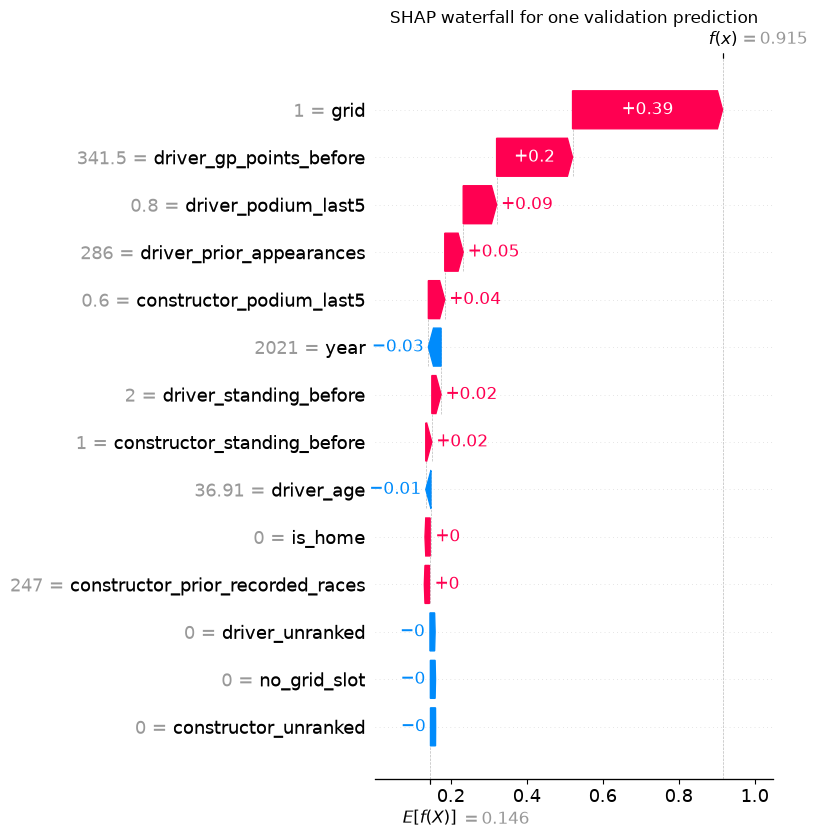

In [343]:
val_frame = model_df.loc[chosen_inputs["rows"]["Val"], ["raceId", "driverId", "year"]].copy()
val_frame["probability"] = chosen_predict(chosen_inputs["X"]["Val"])
val_frame["podium"] = chosen_inputs["y"]["Val"]
example = val_frame[val_frame["podium"].eq(1)].sort_values("probability", ascending=False).iloc[0]
example_position = val_frame.index.get_loc(example.name)
example_info = (races_clean.loc[races_clean["raceId"].eq(example["raceId"]), ["year", "name"]].iloc[0].to_dict()
                | drivers_clean.loc[drivers_clean["driverId"].eq(example["driverId"]), ["forename", "surname"]].iloc[0].to_dict())
print(f"{example_info['forename']} {example_info['surname']}, {example_info['year']} {example_info['name']}: "
      f"predicted podium probability {example['probability']:.2f}, actual result: podium")
display(pd.Series(chosen_inputs["raw"]["Val"].iloc[example_position], name="Input value").to_frame())

example_shap = shap_explainer(pd.DataFrame(chosen_inputs["X"]["Val"][[example_position]], columns=chosen_features))
shap.plots.waterfall(example_shap[0], max_display=len(chosen_features), show=False)
plt.title("SHAP waterfall for one validation prediction")
plt.tight_layout(); plt.show()

## 12.4 Local explanation: LIME for the same prediction

LIME perturbs the selected driver's **imputed, pre-scaling** inputs and fits a small local model that approximates the final model nearby. Its bars show which feature-value conditions push the local approximation toward or away from podium. We use the same driver and prediction as the SHAP waterfall above so the methods can be compared. LIME's weights describe this local approximation; they are not causal effects or a replacement for the model's probability.


Same driver: Lewis Hamilton, 2021 Saudi Arabian Grand Prix
Final model podium probability: 0.9155; LIME local fit R²: 0.669


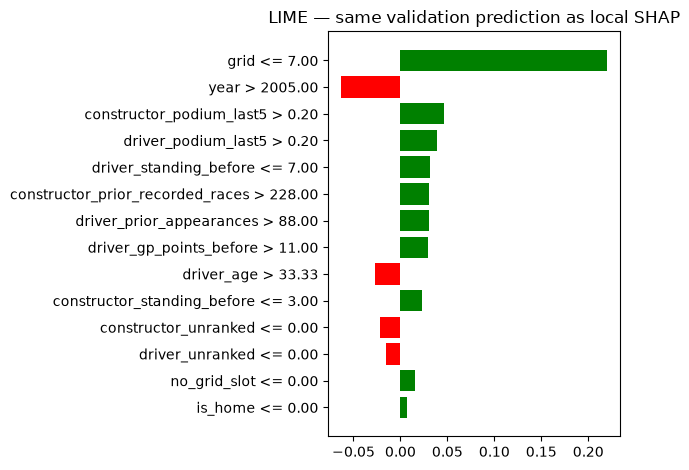

,Feature-value condition,Local surrogate weight
0,grid <= 7.00,0.2196
1,year > 2005.00,-0.0628
2,constructor_podium_last5 > 0.20,0.0465
3,driver_podium_last5 > 0.20,0.0384
4,driver_standing_before <= 7.00,0.0314
5,constructor_prior_recorded_races > 228.00,0.0301
6,driver_prior_appearances > 88.00,0.0301


Positive LIME weights support podium in the local approximation; negative weights oppose it. LIME and SHAP can rank features differently because they use different explanations.


In [344]:
# Install LIME only when the notebook environment does not already provide it.
try:
    from lime.lime_tabular import LimeTabularExplainer
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime==0.2.0.1"])
    from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(chosen_inputs["X"]["Train"], dtype=float),
    feature_names=chosen_features,
    class_names=["No podium", "Podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=42,
)

def lime_predict_proba(rows):
    podium_probability = np.asarray(chosen_predict(rows), dtype=float).reshape(-1)
    return np.column_stack([1 - podium_probability, podium_probability])

lime_row = np.asarray(chosen_inputs["X"]["Val"][example_position], dtype=float)
lime_explanation = lime_explainer.explain_instance(
    lime_row, lime_predict_proba, labels=(1,), num_features=len(chosen_features), num_samples=5000
)
np.testing.assert_allclose(lime_explanation.predict_proba[1], example["probability"], rtol=1e-5, atol=1e-6)
print(f"Same driver: {example_info['forename']} {example_info['surname']}, {int(example_info['year'])} {example_info['name']}")
print(f"Final model podium probability: {example['probability']:.4f}; LIME local fit R²: {lime_explanation.score:.3f}")
lime_explanation.as_pyplot_figure(label=1)
plt.title("LIME — same validation prediction as local SHAP")
plt.tight_layout(); plt.show()
lime_local = pd.DataFrame(lime_explanation.as_list(label=1), columns=["Feature-value condition", "Local surrogate weight"])
display(lime_local.reindex(lime_local["Local surrogate weight"].abs().sort_values(ascending=False).index).head(7).round(4))
print("Positive LIME weights support podium in the local approximation; negative weights oppose it. "
      "LIME and SHAP can rank features differently because they use different explanations.")


## 12.5 Interpretation

The tables and explanation below are generated from the current run.


In [345]:
display(Markdown("**Permutation importance: largest measured validation PR-AUC drops**"))
display(permutation_table.sort_values("PR-AUC drop", ascending=False).head(5).round(4))
print("Shuffling does not retrain the model. Its importance can differ from retrained group ablation, especially for related features.")

shap_matrix = np.asarray(shap_values.values)
assert shap_matrix.ndim == 2 and shap_matrix.shape[1] == len(chosen_features)
shap_summary_current = pd.DataFrame({
    "Feature": chosen_features,
    "Mean absolute SHAP contribution": np.abs(shap_matrix).mean(axis=0)
}).sort_values("Mean absolute SHAP contribution", ascending=False)
display(Markdown("**SHAP summary: largest contributions in the explained validation sample**"))
display(shap_summary_current.head(5).round(4))
print("SHAP values explain the probability returned by chosen_predict relative to the background distribution. "
      "Positive contributions raise that probability; negative contributions lower it.")

local_values = np.asarray(example_shap.values).reshape(-1)
local_base = float(np.asarray(example_shap.base_values).reshape(-1)[0])
local_probability = float(example["probability"])
local_inputs = chosen_inputs["raw"]["Val"].iloc[example_position].reindex(chosen_features)
local_contributions_current = pd.DataFrame({"Feature": chosen_features, "Input value": local_inputs.to_numpy(),
                                           "SHAP contribution": local_values})
local_contributions_current = local_contributions_current.iloc[np.argsort(-np.abs(local_values))]
example_name = example_info["forename"] + " " + example_info["surname"]
actual_outcome = "podium" if int(example["podium"]) == 1 else "no podium"
local_threshold = float(chosen_entry["thresholds"][chosen_version])
predicted_outcome = "podium" if local_probability >= local_threshold else "no podium"
display(Markdown(
    f"**Local example: {example_name}, {int(example_info['year'])} {example_info['name']}**. "
    f"Predicted podium probability: **{local_probability:.4f}**; threshold: **{local_threshold:.2f}**; "
    f"predicted class: **{predicted_outcome}**; recorded outcome: **{actual_outcome}**. "
    f"The SHAP background value is **{local_base:.4f}**. The largest contributions are listed below."))
display(local_contributions_current.head(5).round(4))
print(f"SHAP background + contributions = {local_base + local_values.sum():.4f}; model probability = {local_probability:.4f}.")
display(Markdown(
    "**Explanations are not causal.** They describe what this trained model relies on, not what causes podiums. "
    "Validation/test cover limited periods; model/version differences require uncertainty checks before strong claims. "
    "The local example is selected among actual podium records and is illustrative, not representative of all predictions."))


**Permutation importance: largest measured validation PR-AUC drops**

,PR-AUC drop,Spread
Feature,,
grid,0.3114,0.0257
driver_gp_points_before,0.0359,0.0141
constructor_podium_last5,0.0307,0.0087
driver_podium_last5,0.0263,0.0123
driver_prior_appearances,0.0218,0.0122


Shuffling does not retrain the model. Its importance can differ from retrained group ablation, especially for related features.


**SHAP summary: largest contributions in the explained validation sample**

,Feature,Mean absolute SHAP contribution
0,grid,0.0916
9,year,0.0589
6,constructor_podium_last5,0.0227
4,driver_podium_last5,0.0201
3,driver_prior_appearances,0.0180


SHAP values explain the probability returned by chosen_predict relative to the background distribution. Positive contributions raise that probability; negative contributions lower it.


**Local example: Lewis Hamilton, 2021 Saudi Arabian Grand Prix**. Predicted podium probability: **0.9155**; threshold: **0.30**; predicted class: **podium**; recorded outcome: **podium**. The SHAP background value is **0.1464**. The largest contributions are listed below.

,Feature,Input value,SHAP contribution
0,grid,1.0,0.3950
7,driver_gp_points_before,341.5,0.2000
4,driver_podium_last5,0.8,0.0879
3,driver_prior_appearances,286.0,0.0486
6,constructor_podium_last5,0.6,0.0432


SHAP background + contributions = 0.9155; model probability = 0.9155.


**Explanations are not causal.** They describe what this trained model relies on, not what causes podiums. Validation/test cover limited periods; model/version differences require uncertainty checks before strong claims. The local example is selected among actual podium records and is illustrative, not representative of all predictions.